# Frozen temporal evaluation and experimental engineering findings

In [1]:
from pathlib import Path
import ast, copy, gc, hashlib, itertools, json, os, platform, re, threading, time, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import yaml, joblib, psutil
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeClassifier, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
    precision_score, recall_score, f1_score, matthews_corrcoef, balanced_accuracy_score,
    brier_score_loss, log_loss, confusion_matrix)
from scipy.stats import norm
from catboost import CatBoostClassifier, Pool
from threadpoolctl import threadpool_limits
from aeon.transformations.collection.convolution_based import HydraTransformer, MultiRocket
import tabm
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, Image

REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                 if (path / "dataset").is_dir() and (path / "notebooks").is_dir())
OUTPUT_ROOT = REPO_ROOT / "artifacts"  # generated tables, models, predictions and figures
(OUTPUT_ROOT / "Configs").mkdir(parents=True, exist_ok=True)
SHARED_DATASET_ROOT = REPO_ROOT / "dataset"
for folder in ["Processed", "Interim", "Features", "Splits"]:
    (SHARED_DATASET_ROOT / folder).mkdir(parents=True, exist_ok=True)
NOTEBOOK_NAME = "06_frozen_evaluation_statistics_and_publication_results.ipynb"
NB05_PATH = REPO_ROOT / "notebooks/05_proposed_model_development_and_ablations.ipynb"
EVALUATION_PROFILE = "targeted"  # Frozen targeted comparisons; earlier execution drivers are inactive.
EVALUATION_MODE = "v2_historical_reassessment"
FOCUS_RUN_ID = "racf_focus_20261013_170443"
LEGACY_RUN_ID, REFERENCE_RUN = "racf_20261012", "racf_20261011"
RUN_ID = LEGACY_RUN_ID  # Compatibility for unchanged parent inference definitions only.
RACF_RUN_ID = "racf_20261013_102931"
FEATURES_ROOT, SPLITS_ROOT = SHARED_DATASET_ROOT / "Features", SHARED_DATASET_ROOT / "Splits"
TABLES = OUTPUT_ROOT / "Tables" / LEGACY_RUN_ID
REFERENCE_TABLES = OUTPUT_ROOT / "Tables" / REFERENCE_RUN
MODEL_ROOT = OUTPUT_ROOT / "Models" / LEGACY_RUN_ID / "proposed"
PRED_ROOT = OUTPUT_ROOT / "Predictions" / LEGACY_RUN_ID / "confirmation"
RACF_ROOT = OUTPUT_ROOT / "Artifacts/Runs" / RACF_RUN_ID
RACF_MANIFESTS, RACF_TABLES = OUTPUT_ROOT / "Manifests" / RACF_RUN_ID, OUTPUT_ROOT / "Tables" / RACF_RUN_ID
RACF_EVAL_ROOT, RACF_EVAL_MANIFESTS = RACF_ROOT / "Evaluation", RACF_MANIFESTS / "Evaluation"
RACF_PRED_ROOT, RACF_EVAL_TABLES = RACF_EVAL_ROOT / "Predictions", RACF_TABLES / "Evaluation"
RACF_EVAL_FIGURES_PNG = OUTPUT_ROOT / "Figures/PNG" / RACF_RUN_ID / "Evaluation"
RACF_EVAL_FIGURES_PDF = OUTPUT_ROOT / "Figures/PDF" / RACF_RUN_ID / "Evaluation"
N_JOBS = 4
thread_limiter = threadpool_limits(limits=N_JOBS)
torch.set_num_threads(N_JOBS)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
mpl.rcParams.update({"font.family":"Times New Roman", "font.size":18,
    "axes.titlesize":20, "axes.labelsize":18, "xtick.labelsize":18, "ytick.labelsize":18,
    "legend.fontsize":18, "figure.dpi":350, "savefig.dpi":350, "axes.unicode_minus":True})
learned_baselines = ["Logistic Regression", "Random Forest", "CatBoost", "LightGBM"]
COMPARATOR_SLUGS = {"Logistic Regression":"logistic", "CatBoost":"catboost", "LightGBM":"lightgbm", "TCN + context":"tcn"}


In [ ]:
# Naming compatibility: historical identifiers are used only for frozen artifact verification.
import sys, zipfile
RACF_NAMING_ROOT = OUTPUT_ROOT/"Manifests/racf_naming_cleanup_20261014"
RACF_NAMING_MANIFEST = RACF_NAMING_ROOT/"migration.json"
assert hashlib.sha256(RACF_NAMING_MANIFEST.read_bytes()).hexdigest() == "5b59b1e0ceab3dfb901ab257c5da7a7c155e771a90c3648f0fb0cdad2aa28c56"
RACF_NAMING = json.loads(RACF_NAMING_MANIFEST.read_text())

def racf_serialization_identity(cls):
    """Keep established pickle identities while exposing a version-neutral source name."""
    serialized_name = RACF_NAMING["serialization_names"].get(cls.__name__)
    if serialized_name is not None:
        setattr(sys.modules[cls.__module__], serialized_name, cls)
        cls.__name__ = serialized_name
        cls.__qualname__ = serialized_name
    return cls

def racf_compatibility_notebook(path):
    """Verify renamed source, then supply its bound reference for historical fingerprints only."""
    path = Path(path).resolve()
    record = RACF_NAMING["notebooks"][path.name]
    assert path.parent == (REPO_ROOT / "notebooks").resolve()
    current = json.loads(path.read_text())
    scientific_cells = [cell for cell in current["cells"] if cell["cell_type"]=="code" and cell.get("id")!="racf-naming-compatibility"]
    observed = {cell["id"]:hashlib.sha256(ast.dump(ast.parse("".join(cell["source"])),include_attributes=False).encode()).hexdigest() for cell in scientific_cells}
    assert observed == record["renamed_code_ast_sha256"], "Source changed beyond the verified naming migration."
    archive = OUTPUT_ROOT/RACF_NAMING["archive"]
    assert hashlib.sha256(archive.read_bytes()).hexdigest()==RACF_NAMING["archive_sha256"]
    with zipfile.ZipFile(archive) as bundle:
        reference = bundle.read(path.name)
    assert hashlib.sha256(reference).hexdigest()==record["original_notebook_sha256"]
    return json.loads(reference)

display(Markdown("**Naming compatibility verified.** RACF-Net and its working function names use no version labels. Historical serialization identifiers, schemas and artifact paths are retained solely to load unchanged checkpoints and verify their provenance."))


In [2]:
def racf_eval_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(2**20), b""):
            digest.update(block)
    return digest.hexdigest()


freeze_path = OUTPUT_ROOT / "Manifests" / LEGACY_RUN_ID / "confirmation_freeze.json"
assert freeze_path.is_file(), "The immutable parent freeze is required."
frozen_manifest = json.loads(freeze_path.read_text())
assert frozen_manifest["run_id"] == LEGACY_RUN_ID
assert frozen_manifest["architecture_and_thresholds_frozen"] and frozen_manifest["cutoff"] == "2026-09-30"
for relative, expected in frozen_manifest["artifact_sha256"].items():
    assert racf_eval_hash(OUTPUT_ROOT / relative) == expected, relative
for specification in frozen_manifest["models"]:
    for key in ["checkpoint", "calibration"]:
        relative = specification.get(key)
        if relative and relative != "Deterministic rule":
            assert relative in frozen_manifest["artifact_sha256"], (key, relative)
legacy_source_manifest = SHARED_DATASET_ROOT / "External/NRC2026/source_manifest.json"
assert racf_eval_hash(legacy_source_manifest) == frozen_manifest["source_manifest_sha256"]
statistical_plan = json.loads((OUTPUT_ROOT / "Configs/confirmation_statistical_plan.json").read_text())
protocol = yaml.safe_load((OUTPUT_ROOT / "Configs/experiment.yaml").read_text())
assert not protocol["test_opened_for_model_selection"]

# New registration is inspected only after the inherited frozen dependencies pass.
registration_path = RACF_MANIFESTS / "preregistered_protocol.json"
registration = json.loads(registration_path.read_text())
RACF_CONFIG = registration["configuration"]
assert registration["configuration_sha256"] == hashlib.sha256(json.dumps(RACF_CONFIG, sort_keys=True).encode()).hexdigest()
assert registration["parent_freeze_sha256"] == racf_eval_hash(freeze_path)
assert RACF_CONFIG["run_id"] == RACF_RUN_ID and registration["historical_outcomes_already_disclosed"] is True
RACF_SCHEMA_VERSION, SEEDS = RACF_CONFIG["schema_version"], list(RACF_CONFIG["model_seeds"])
protected_path = RACF_MANIFESTS / "protected_inputs.json"
nb05_registry = {item["artifact"]:item for item in json.loads((RACF_MANIFESTS / "result_registry.json").read_text())}
assert nb05_registry[str(protected_path.relative_to(OUTPUT_ROOT))]["sha256"] == racf_eval_hash(protected_path)
protected_inputs = json.loads(protected_path.read_text())["files"]
for relative, expected in protected_inputs.items():
    assert racf_eval_hash(REPO_ROOT / relative) == expected, relative
schema = json.loads((FEATURES_ROOT / "feature_schema.json").read_text())
assert len(schema["feature_names"]) == 51 and len(schema["sequence_channels"]) == 7


## Preserved parent compatibility definitions

In [4]:
class AgentVerifierBank(nn.Module):
    """Vectorized training of separate small neural tools; no shared feature-agent weights."""
    def __init__(self,p,hidden=4):
        super().__init__()
        self.weight1=nn.Parameter(torch.randn(p,3,hidden)/np.sqrt(3))
        self.bias1=nn.Parameter(torch.zeros(p,hidden))
        self.weight2=nn.Parameter(torch.randn(p,hidden)/np.sqrt(hidden))
        self.bias2=nn.Parameter(torch.zeros(p))
    def forward(self,neighbors):
        hidden=torch.tanh(torch.einsum("bpi,pih->bph",neighbors,self.weight1)+self.bias1)
        return torch.einsum("bph,ph->bp",hidden,self.weight2)+self.bias2


class NeuralVerificationTool:
    """A local nonlinear tool called only for a recruited verification agent."""
    def __init__(self,weight1,bias1,weight2,bias2):
        self.weight1=weight1;self.bias1=bias1;self.weight2=weight2;self.bias2=bias2
        self.parameter_count=int(weight1.size+bias1.size+weight2.size+bias2.size)
    def predict(self,values):
        return np.tanh(values@self.weight1+self.bias1)@self.weight2+self.bias2


In [5]:
class PredictorAgents:
    """Bounded reactive agents; train-only tools and inference-time message state."""
    @staticmethod
    def design(values,neighbors,kind="joint"):
        local=values[:,neighbors]
        if local.shape[1]==0:return np.zeros((len(values),1))
        if kind=="linear":return local
        if kind=="quadratic":return local**2
        return np.concatenate([local,local**2],axis=1)
    def fit(self, frame, threshold=2.5, seed=42, train_verifiers=True):
        self.columns = frame.columns.tolist(); self.p = len(self.columns)
        self.threshold = float(threshold)
        raw = frame.to_numpy(dtype=np.float64,na_value=np.nan); observed = np.isfinite(raw)
        self.center = np.array([np.median(raw[observed[:,j],j]) if observed[:,j].any() else 0.0 for j in range(self.p)])
        self.scale = np.array([max(np.std(raw[observed[:,j],j]),1e-4) if observed[:,j].any() else 1.0 for j in range(self.p)])
        z = np.clip(np.where(observed,(raw-self.center)/self.scale,0),-12,12)
        def cross_correlation(left,right):
            a=left-left.mean(0); b=right-right.mean(0)
            den=np.sqrt(np.sum(a*a,0)[:,None]*np.sum(b*b,0)[None,:])
            return np.divide(a.T@b,den,out=np.zeros((self.p,self.p)),where=den>1e-12),den>1e-12
        linear,linear_defined=cross_correlation(z,z);curved,curved_defined=cross_correlation(z*z,z)
        linear=np.abs(linear);curved=np.abs(curved)
        np.fill_diagonal(linear_defined,False);np.fill_diagonal(curved_defined,False)
        np.fill_diagonal(linear,-np.inf); np.fill_diagonal(curved,-np.inf)
        self.neighbors=[]; self.tools=[]; self.repair_tools=[]; self.check_tools=[]; self.residual_scale=[]; edge_rows=[]; coverage=[]
        for j in range(self.p):
            available=np.flatnonzero(linear_defined[:,j]);strong=available[np.argsort(-linear[available,j],kind="stable")[:2]]
            candidates=np.flatnonzero(curved_defined[:,j] & ~np.isin(np.arange(self.p),strong))
            extra=candidates[np.argsort(-curved[candidates,j],kind="stable")[:1]]
            neighbors=np.r_[strong,extra].astype(int)
            design=self.design(z,neighbors)
            valid=observed[:,j]
            tool=Ridge(alpha=10.0).fit(design[valid],z[valid,j]) if valid.any() else Ridge(alpha=10.0).fit(design,np.zeros(len(z)))
            residual=z[valid,j]-tool.predict(design[valid]) if valid.any() else np.zeros(1)
            self.neighbors.append(neighbors); self.tools.append(tool)
            fit_rows=valid if valid.any() else np.ones(len(z),dtype=bool)
            local_target=z[fit_rows,j] if valid.any() else np.zeros(len(z))
            self.repair_tools.append(Ridge(alpha=10.0).fit(self.design(z[fit_rows],neighbors,"linear"),local_target))
            self.check_tools.append(None if len(neighbors) else Ridge(alpha=10.0).fit(self.design(z[fit_rows],neighbors,"linear"),local_target))
            self.residual_scale.append(max(float(np.sqrt(np.mean(residual**2))),.1))
            coverage.append({"Agent":self.columns[j],"Observed training values":int(valid.sum()),"Peers":len(neighbors),"Tool status":"Learned peer model" if len(neighbors) else "Intercept-only reference; no defined peer association"})
            for k,neighbor in enumerate(neighbors):
                edge_rows.append({"Receiving agent":self.columns[j],"Sending agent":self.columns[neighbor],"Tool term":"linear" if k<len(strong) else "quadratic candidate","Training association":float(linear[neighbor,j] if k<len(strong) else curved[neighbor,j])})
        self.residual_scale=np.asarray(self.residual_scale)
        self.edges=pd.DataFrame(edge_rows);self.coverage=pd.DataFrame(coverage)
        if train_verifiers:self.fit_neural_verifiers(z,observed,seed)
        else:self.check_tools=[None]*self.p
        self.groups=[np.array([self.columns.index(c) for c in columns]) for columns in schema["feature_groups"].values()]
        return self
    def fit_neural_verifiers(self,z,observed,seed):
        torch.manual_seed(seed);rng=np.random.default_rng(seed)
        neighbors=np.zeros((self.p,3),dtype=int);present=np.zeros((self.p,3),dtype=np.float32)
        for j,peers in enumerate(self.neighbors):
            neighbors[j,:len(peers)]=peers;present[j,:len(peers)]=1
        inputs=(z[:,neighbors]*present[None]).astype(np.float32)
        bank=AgentVerifierBank(self.p).to(DEVICE)
        optimizer=torch.optim.AdamW(bank.parameters(),lr=.01,weight_decay=1e-3)
        self.verifier_learning=[]
        for epoch in range(6):
            order=rng.permutation(len(z));total=0.0;count=0
            for start in range(0,len(z),1024):
                rows=order[start:start+1024]
                xb=torch.from_numpy(inputs[rows]).to(DEVICE)
                target=torch.from_numpy(z[rows].astype(np.float32)).to(DEVICE)
                mask=torch.from_numpy(observed[rows].astype(np.float32)).to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                error=(bank(xb)-target).square()*mask
                loss=error.sum()/mask.sum().clamp(min=1)
                assert torch.isfinite(loss)
                loss.backward();nn.utils.clip_grad_norm_(bank.parameters(),5.0);optimizer.step()
                total+=float(error.detach().sum().cpu());count+=int(mask.sum().cpu())
            self.verifier_learning.append({"Epoch":epoch+1,"Observed reconstruction MSE":total/max(count,1)})
        arrays={name:value.detach().cpu().numpy().copy() for name,value in bank.state_dict().items()}
        for j,peers in enumerate(self.neighbors):
            if len(peers):
                self.check_tools[j]=NeuralVerificationTool(arrays["weight1"][j,:len(peers)],arrays["bias1"][j],arrays["weight2"][j],arrays["bias2"][j])
        with torch.inference_mode():
            reference=bank(torch.from_numpy(inputs[:64]).to(DEVICE)).cpu().numpy()
        errors=[np.max(np.abs(tool.predict(z[:64,peers])-reference[:,j])) for j,(peers,tool) in enumerate(zip(self.neighbors,self.check_tools)) if len(peers)]
        self.verifier_export_error=float(max(errors,default=0.0))
        assert self.verifier_export_error<1e-4
        del bank,inputs;gc.collect()
        if DEVICE.type=="mps":torch.mps.empty_cache()
    def reliability(self,frame):
        raw=frame.to_numpy(dtype=np.float64,na_value=np.nan)
        quality=np.isfinite(raw).astype(np.float64)
        names=self.columns
        power_q=np.clip(frame.power_window_fraction.fillna(0).to_numpy(dtype=float),0,1)
        for j in self.groups[0]:
            if names[j]!="power_window_fraction":quality[:,j]*=power_q
        for variable in ["temp_c","dewpoint_c","pressure_hpa","wind_ms","precip_mm"]:
            age=frame[variable+"_age_days"].fillna(365).to_numpy(dtype=float)
            weather_q=np.exp(-np.maximum(age-3,0)/7)
            for column in [variable,variable+"_mean7d"]:
                quality[:,names.index(column)]*=weather_q
        return quality
    def transform(self,frame,mode="full",return_trace=False,external_repairs=None):
        assert frame.columns.tolist()==self.columns
        raw=frame.to_numpy(dtype=np.float64,na_value=np.nan); observed=np.isfinite(raw)
        z=np.clip(np.where(observed,(raw-self.center)/self.scale,0),-12,12)
        quality=self.reliability(frame) if mode!="no_reliability" else np.ones_like(z)
        belief=z.copy(); expected=np.zeros_like(z)
        repair_message=np.zeros_like(z); check_message=np.zeros_like(z)
        repair_used=np.zeros_like(z,dtype=bool); check_used=np.zeros_like(z,dtype=bool)
        for round_index in range(2):
            if mode=="no_communication":
                expected[:]=0;residual=np.clip(z,-12,12)
            else:
                for j,(neighbors,tool) in enumerate(zip(self.neighbors,self.tools)):
                    expected[:,j]=np.clip(tool.predict(self.design(belief,neighbors)),-12,12)
                residual=np.where(observed,np.clip((z-expected)/self.residual_scale,-12,12),0.0)
            request_repair=quality<.5
            if external_repairs is not None:request_repair |= external_repairs
            request_check=(observed & ((quality*np.abs(residual))>self.threshold)) | request_repair
            if mode=="fixed_agents":
                request_repair[:]=True; request_check[:]=True
            if mode=="no_communication":
                request_repair[:]=False; request_check[:]=False
            if mode=="no_verifier":request_check[:]=False
            if mode=="no_repair":request_repair[:]=False
            # Agents keep reliable measurements; only requested, low-quality beliefs are repaired.
            repair_used|=request_repair; check_used|=request_check
            repair_message[:]=0; check_message[:]=0
            for j,neighbors in enumerate(self.neighbors):
                repair_rows=np.flatnonzero(request_repair[:,j]); check_rows=np.flatnonzero(request_check[:,j])
                if len(repair_rows):
                    repaired=self.repair_tools[j].predict(self.design(belief[repair_rows],neighbors,"linear"))
                    repair_message[repair_rows,j]=np.clip(repaired,-12,12)
                if len(check_rows):
                    alternate=self.check_tools[j].predict(self.design(belief[check_rows],neighbors,"linear"))
                    check_message[check_rows,j]=np.clip((alternate-expected[check_rows,j])/self.residual_scale[j],-12,12)
            agreement=1/(1+np.abs(check_message))
            peer_weight=(1-quality)*request_repair*agreement
            if mode=="no_communication":peer_weight[:]=0
            belief=(1-peer_weight)*z+peer_weight*repair_message
        blocks=[]
        for group in self.groups:
            q=quality[:,group]; denominator=np.maximum(q.sum(1),1)
            blocks.extend([(belief[:,group]*q).sum(1)/denominator,
                np.abs(residual[:,group]).mean(1),np.abs(residual[:,group]).max(1),
                q.mean(1),request_repair[:,group].mean(1),request_check[:,group].mean(1),
                np.abs(check_message[:,group]).mean(1),(repair_message[:,group]*request_repair[:,group]).mean(1)])
        summaries=np.stack(blocks,axis=1).astype(np.float32)
        active=self.p+repair_used.sum(1)+check_used.sum(1)
        assert np.isfinite(summaries).all() and ((active>=self.p)&(active<=3*self.p)).all()
        if return_trace:
            return summaries,{"belief":belief,"residual":residual,"quality":quality,"repair":repair_used,"check":check_used,"repair_message":repair_message,"check_message":check_message,"active":active}
        return summaries

    def repair_context(self,raw,frame,mode="full"):
        """Each affected power agent requests a within-window statistic tool; no future values."""
        repaired=frame.copy();actions=np.zeros((len(frame),self.p),dtype=bool)
        if mode in ["no_repair","no_agents","concatenation","temporal_only","tabular_only"]:
            return repaired,actions
        power=np.asarray(raw[:,0,:],dtype=float)
        for window in [7,14,30]:
            if power.shape[1]<window:continue
            values=power[:,-window:];valid=np.isfinite(values);count=valid.sum(1)
            permitted=count>=max(2,int(np.ceil(window/2)))
            safe=np.where(valid,values,0);mean=safe.sum(1)/np.maximum(count,1)
            variance=np.where(valid,(values-mean[:,None])**2,0).sum(1)/np.maximum(count-1,1)
            low=np.min(np.where(valid,values,np.inf),axis=1)
            high=np.max(np.where(valid,values,-np.inf),axis=1)
            estimates={"mean":mean,"std":np.sqrt(variance),"min":low,"max":high,"range":high-low}
            for statistic,estimate in estimates.items():
                column=f"power_{statistic}_{window}d"
                if column not in self.columns:continue
                j=self.columns.index(column)
                request=~np.isfinite(frame[column].to_numpy(float)) & permitted & np.isfinite(estimate)
                repaired.loc[request,column]=estimate[request];actions[request,j]=True
        return repaired,actions


In [6]:
class FoldRepresentation:
    """Train-only preprocessing for raw sequence and common context."""
    def fit(self, indices, window):
        self.window = window
        raw = np.asarray(sequences[indices,:,-window:],dtype=np.float32)
        self.sequence_median = np.array([np.nanmedian(raw[:,j]) if np.isfinite(raw[:,j]).any() else 0 for j in range(raw.shape[1])],dtype=np.float32)
        filled = np.where(np.isfinite(raw),raw,self.sequence_median[None,:,None])
        self.sequence_mean = filled.mean(axis=(0,2))
        self.sequence_scale = np.maximum(filled.std(axis=(0,2)),1e-4)
        self.table = Pipeline([("imputer",SimpleImputer(strategy="median",add_indicator=True,keep_empty_features=True)),("scale",StandardScaler())])
        self.table.fit(features.iloc[indices])
        return self
    def transform(self, indices):
        return self.transform_arrays(sequences[indices,:,-self.window:],features.iloc[indices])
    def transform_arrays(self, raw, context_frame):
        raw = np.asarray(raw,dtype=np.float32)
        assert raw.shape[2] == self.window
        observed = np.isfinite(raw)
        filled = np.where(observed,raw,self.sequence_median[None,:,None])
        normalized = np.clip((filled-self.sequence_mean[None,:,None])/self.sequence_scale[None,:,None],-20,20)
        temporal = np.concatenate([normalized,observed.astype(np.float32)],axis=1)
        context = np.clip(self.table.transform(context_frame),-20,20).astype(np.float32)
        assert np.isfinite(temporal).all() and np.isfinite(context).all()
        return temporal,context


In [7]:
class CausalResidual(nn.Module):
    def __init__(self, incoming, width, dilation):
        super().__init__()
        self.padding = 2*dilation
        self.first = nn.Conv1d(incoming,width,3,dilation=dilation,padding=self.padding)
        self.second = nn.Conv1d(width,width,3,dilation=dilation,padding=self.padding)
        self.shortcut = nn.Conv1d(incoming,width,1) if incoming!=width else nn.Identity()
        self.dropout = nn.Dropout(.1)
    def forward(self,x):
        h = self.dropout(F.relu(self.first(x)[:,:,:-self.padding]))
        h = self.dropout(F.relu(self.second(h)[:,:,:-self.padding]))
        return F.relu(h+self.shortcut(x))


class RACFRepresentation(nn.Module):
    def __init__(self,channels,context_dim,output_dim,agent_dim=24,width=16,mode="full",supervised_event=False):
        super().__init__(); self.mode=mode; self.input_channels=channels; self.context_dim=context_dim
        self.temporal=nn.Sequential(*[CausalResidual(channels if j==0 else width,width,2**j) for j in range(3)]) if mode!="tabular_only" else None
        self.context=nn.Sequential(nn.Linear(context_dim,width),nn.ReLU(),nn.Linear(width,width),nn.ReLU()) if mode!="temporal_only" else None
        self.gate=nn.Sequential(nn.Linear(2*width+agent_dim,width),nn.Tanh(),nn.Linear(width,2)) if mode not in ["temporal_only","tabular_only","concatenation","fixed_fusion"] else None
        self.concat=nn.Sequential(nn.Linear(2*width,19),nn.ReLU(),nn.Linear(19,width)) if mode=="concatenation" else None
        self.reconstruction=nn.Linear(width,output_dim)
        self.change=nn.Linear(width,1) if mode!="no_change" else None
        self.event=nn.Linear(width,1) if supervised_event else None
    def encode(self,x,z,messages):
        if self.mode=="temporal_only":
            return self.temporal(x)[:,:,-1],z.new_tensor([1.0,0.0]).expand(len(z),2)
        if self.mode=="tabular_only":
            return self.context(z),z.new_tensor([0.0,1.0]).expand(len(z),2)
        ht=self.temporal(x)[:,:,-1]; hs=self.context(z)
        if self.mode=="fixed_fusion":
            return .5*(ht+hs),z.new_full((len(z),2),.5)
        if self.mode=="concatenation":
            return self.concat(torch.cat([ht,hs],dim=1)),z.new_full((len(z),2),.5)
        q=torch.stack([messages[:,3],.5*(messages[:,11]+messages[:,19])],dim=1).clamp(.02,1)
        if self.mode=="no_reliability":q=torch.ones_like(q)
        gate_logits=self.gate(torch.cat([ht,hs,messages],dim=1))+torch.log(q)
        weights=torch.softmax(gate_logits,dim=1)
        latent=weights[:,:1]*ht+weights[:,1:]*hs
        return latent,weights
    def forward(self,x,z,messages):
        latent,weights=self.encode(x,z,messages)
        change=self.change(latent).squeeze(-1) if self.change is not None else latent.new_zeros(len(latent))
        return self.reconstruction(latent),change,latent,weights


In [8]:
def representation_outputs(network,x,z,messages,batch_size=1024):
    network.eval(); latent_rows=[]; change_rows=[]; weight_rows=[]
    with torch.inference_mode():
        for start in range(0,len(z),batch_size):
            sl=slice(start,start+batch_size)
            latent,weights=network.encode(torch.from_numpy(x[sl]).to(DEVICE),torch.from_numpy(z[sl]).to(DEVICE),torch.from_numpy(messages[sl]).to(DEVICE))
            change=network.change(latent).squeeze(-1) if network.change is not None else latent.new_zeros(len(latent))
            latent_rows.append(latent.cpu().numpy()); change_rows.append(torch.sigmoid(change).cpu().numpy()); weight_rows.append(weights.cpu().numpy())
    return np.concatenate(latent_rows),np.concatenate(change_rows),np.concatenate(weight_rows)


In [9]:
def expert_inputs(z,messages,latent,change,mode):
    if mode=="temporal_only":return np.column_stack([latent,change]).astype(np.float32)
    if mode=="tabular_only":return np.column_stack([z,latent]).astype(np.float32)
    if mode=="no_change":change=np.zeros_like(change)
    if mode in ["no_agents","concatenation"]:messages=np.zeros_like(messages)
    return np.column_stack([z,messages,latent,change]).astype(np.float32)


class RACFNet:
    """One saved model: observation agents, learned representation, independent event expert."""
    def __init__(self,representation,agents,network,expert,configuration,mode,seed):
        self.representation=representation; self.agents=agents; self.expert=expert
        self.configuration=dict(configuration); self.mode=mode; self.seed=int(seed)
        self.channels=network.input_channels
        self.context_dim=network.context_dim
        self.state_dict={k:v.detach().cpu() for k,v in network.state_dict().items()}
    def restore_network(self):
        network=RACFRepresentation(self.channels,self.context_dim,len(self.agents.columns),width=self.configuration["width"],mode=self.mode,supervised_event=self.configuration.get("event_supervision",False)).to(DEVICE)
        network.load_state_dict(self.state_dict); return network.eval()
    def predict_arrays(self,raw_sequence,frame,return_trace=False):
        external_repairs=None
        if self.configuration.get("temporal_repair",False):
            frame,external_repairs=self.agents.repair_context(raw_sequence,frame,mode=self.mode)
        x,z=self.representation.transform_arrays(raw_sequence,frame)
        if self.mode in ["no_agents","concatenation","temporal_only","tabular_only"]:
            messages=np.zeros((len(frame),24),dtype=np.float32);trace={"active":np.zeros(len(frame),dtype=int)}
        else:messages,trace=self.agents.transform(frame,mode=self.mode,return_trace=True,external_repairs=external_repairs)
        network=self.restore_network()
        latent,change,weights=representation_outputs(network,x,z,messages)
        raw_context=(frame.to_numpy(dtype=np.float32,na_value=np.nan) if self.configuration.get("expert_native_missing",False)
                     else self.representation.table.named_steps["imputer"].transform(frame))
        inputs=expert_inputs(raw_context,messages,latent,change,self.mode)
        scores=self.expert.predict_proba(inputs)[:,1]
        assert np.isfinite(scores).all() and ((scores>=0)&(scores<=1)).all()
        del network
        if DEVICE.type=="mps":torch.mps.empty_cache()
        if return_trace:return scores,{**trace,"fusion_weights":weights,"change_probability":change}
        return scores
    def predict_indices(self,indices,return_trace=False):
        return self.predict_arrays(sequences[indices,:,-self.configuration["window"]:],features.iloc[indices],return_trace)


In [10]:
class InceptionModule(nn.Module):
    def __init__(self,incoming,width):
        super().__init__()
        self.bottleneck = nn.Conv1d(incoming,width,1,bias=False)
        self.convolutions = nn.ModuleList([nn.Conv1d(width,width,k,padding=k//2,bias=False) for k in [3,5,9]])
        self.pool = nn.Sequential(nn.MaxPool1d(3,stride=1,padding=1),nn.Conv1d(incoming,width,1,bias=False))
        self.norm = nn.BatchNorm1d(4*width)
    def forward(self,x):
        b = self.bottleneck(x)
        return F.relu(self.norm(torch.cat([conv(b) for conv in self.convolutions]+[self.pool(x)],dim=1)))


class TemporalComparator(nn.Module):
    def __init__(self,family,channels,context_dim,width):
        super().__init__()
        self.family=family
        if family=="TCN + context":
            self.encoder=nn.Sequential(*[CausalResidual(channels if j==0 else width,width,2**j) for j in range(3)])
            hidden=width
        else:
            self.encoder=nn.ModuleList([InceptionModule(channels if j==0 else 4*width,width) for j in range(6)])
            self.residuals=nn.ModuleList([nn.Sequential(nn.Conv1d(channels,4*width,1,bias=False),nn.BatchNorm1d(4*width)),nn.Sequential(nn.Conv1d(4*width,4*width,1,bias=False),nn.BatchNorm1d(4*width))])
            hidden=4*width
        self.context=nn.Sequential(nn.Linear(context_dim,32),nn.ReLU(),nn.Dropout(.1))
        self.head=nn.Sequential(nn.Linear(hidden+32,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x,z):
        if self.family=="TCN + context":
            h=self.encoder(x)[:,:,-1]
        else:
            h=x; shortcut=x
            for j,block in enumerate(self.encoder):
                h=block(h)
                if (j+1)%3==0:
                    h=F.relu(h+self.residuals[j//3](shortcut)); shortcut=h
            h=h.mean(dim=2)
        return self.head(torch.cat([h,self.context(z)],dim=1)).squeeze(-1)


def neural_scores(model, temporal, context, batch=1024):
    model.eval(); values=[]
    with torch.inference_mode():
        for start in range(0,len(context),batch):
            x=torch.from_numpy(temporal[start:start+batch]).to(DEVICE)
            z=torch.from_numpy(context[start:start+batch]).to(DEVICE)
            values.append(torch.sigmoid(model(x,z)).cpu().numpy())
    return np.concatenate(values)


In [11]:
class SparseHydraScaler:
    """Hydra sparse scaling: sqrt counts and zero-frequency regularization."""
    def fit(self,x):
        z=np.sqrt(np.maximum(x,0))
        self.mean=z.mean(axis=0)
        self.scale=z.std(axis=0,ddof=1)+(z==0).mean(axis=0)**4+1e-8
        return self
    def transform(self,x):
        z=np.sqrt(np.maximum(x,0))
        return (z-self.mean)*(z!=0)/self.scale
    def fit_transform(self,x):
        return self.fit(x).transform(x)


def convolution_features(transform, values, batch=512):
    """Bound Hydra temporary tensors; filters and per-row calculations are unchanged."""
    if isinstance(transform,HydraTransformer):
        return np.concatenate([transform.transform(values[start:start+batch]) for start in range(0,len(values),batch)],axis=0)
    return transform.transform(values)


def tabm_network(config,context_dim):
    return tabm.TabM.make(n_num_features=context_dim,d_out=1,n_blocks=3,d_block=config["width"],dropout=config["dropout"],k=config["k"]).to(DEVICE)


def tabm_scores(model,context,batch=1024):
    model.eval();scores=[]
    with torch.inference_mode():
        for start in range(0,len(context),batch):
            logits=model(torch.from_numpy(context[start:start+batch]).to(DEVICE)).squeeze(-1)
            scores.append(torch.sigmoid(logits).mean(1).cpu().numpy())
    return np.concatenate(scores)


In [12]:
def predict_comparator_arrays(package,family,raw,frame):
    if family=="LightGBM":
        # Isolate incompatible macOS OpenMP runtimes; the learned model is unchanged.
        import subprocess, sys, tempfile
        with tempfile.TemporaryDirectory(prefix="racf_lgb_") as directory:
            folder=Path(directory)
            checkpoint=Path(package)
            frame.to_parquet(folder/"inputs.parquet",index=False)
            worker="""import sys, joblib, numpy as np, pandas as pd
from pathlib import Path
from threadpoolctl import threadpool_limits
p=Path(sys.argv[1])
model=joblib.load(Path(sys.argv[2]))
x=pd.read_parquet(p/'inputs.parquet')
with threadpool_limits(limits=1):
    score=model.predict_proba(x,num_threads=1)[:,1]
assert np.isfinite(score).all()
np.save(p/'scores.npy',score)
"""
            subprocess.run([sys.executable,"-c",worker,str(folder),str(checkpoint)],check=True,capture_output=True,text=True,timeout=300)
            return np.load(folder/"scores.npy")
    if family in learned_baselines:return package.predict_proba(frame)[:,1]
    rep=package["representation"];config=package["configuration"]
    if family=="TabM":
        z=np.clip(rep.table.transform(frame),-20,20).astype(np.float32)
        network=tabm_network(config,package["context_dim"]);network.load_state_dict(package["state_dict"])
        scores=tabm_scores(network,z);del network
    else:
        x,z=rep.transform_arrays(raw[:,:,-config["window"]:],frame)
        if "transform" in package:
            design=np.concatenate([package["scale"].transform(convolution_features(package["transform"],x)),z],axis=1)
            scores=1/(1+np.exp(-np.clip(package["classifier"].decision_function(design),-25,25)))
        else:
            network=TemporalComparator(family,package["channels"],package["context_dim"],config["width"]).to(DEVICE)
            network.load_state_dict(package["state_dict"]);scores=neural_scores(network,x,z);del network
    assert np.isfinite(scores).all()
    if DEVICE.type=="mps":torch.mps.empty_cache()
    return scores


In [13]:
class AdaptivePowerTool:
    """Train-only reference; the current input window supplies inference-time evidence."""
    @staticmethod
    def noise_evidence(raw):
        second=np.diff(np.asarray(raw[:,0,:],dtype=float),n=2,axis=1)
        count=np.isfinite(second).sum(1)
        sigma=pd.DataFrame(np.abs(second)).median(axis=1).fillna(0).to_numpy()/(np.sqrt(6)*norm.ppf(.75))
        return sigma,count
    def fit(self,raw,columns):
        self.columns=list(columns)
        self.power_columns=[name for name in schema["feature_groups"]["Power level and temporal dynamics"] if name!="power_window_fraction"]
        self.power_positions=[self.columns.index(name) for name in self.power_columns]
        observed=np.asarray(raw[:,0,:],dtype=float);observed=observed[np.isfinite(observed)]
        self.grid=next((q for q in [1.0,.1] if np.all(np.abs(observed/q-np.round(observed/q))<1e-5)),0.0)
        sigma,count=self.noise_evidence(raw);eligible=count>=15
        assert eligible.any()
        self.threshold=max(float(np.quantile(sigma[eligible],.90)),self.grid/np.sqrt(12),1e-3)
        self.reference={"Training windows":len(raw),"Eligible windows":int(eligible.sum()),"Grid pp":self.grid,
            "Reference threshold pp":self.threshold,"Training activation fraction":float((eligible&(sigma>self.threshold)).mean())}
        return self


In [14]:
def restore_power_observations(tool,raw,frame):
    """Restore model-side estimates only; source values and their missingness are retained on disk."""
    original_mask=np.isfinite(raw[:,0,:]);raw=np.array(raw,copy=True);frame=frame.copy();sigma,count=tool.noise_evidence(raw)
    triggered=(count>=15)&(sigma>tool.threshold)
    actions=np.zeros((len(frame),len(tool.columns)),dtype=bool);quality=np.ones_like(actions,dtype=float)
    selected=np.flatnonzero(triggered);restored=np.zeros(len(frame),dtype=int)
    for row in selected:
        values=raw[row,0].copy();finite=np.isfinite(values)
        boundary=max(2.0,3*np.sqrt(2)*sigma[row]);start=0
        while start<len(values):
            if not finite[start]:start+=1;continue
            end=start+1
            while end<len(values) and finite[end] and abs(values[end]-values[end-1])<=boundary:end+=1
            level=float(np.median(values[start:end]))
            if tool.grid:level=float(np.round(level/tool.grid)*tool.grid)
            raw[row,0,start:end]=max(0.0,level);start=end
        restored[row]=int(np.sum(finite&(np.abs(raw[row,0]-values)>1e-6)))
        raw[row,1,0]=np.nan;raw[row,1,1:]=np.diff(raw[row,0])
    if len(selected):
        values=raw[selected,0];valid=np.isfinite(values)
        estimates={"power_pct":values[:,-1]}
        for lag in [1,2,3,7,14]:estimates[f"delta_{lag}d"]=values[:,-1]-values[:,-lag-1]
        for window in [7,14,30]:
            block=values[:,-window:];known=np.isfinite(block);n=known.sum(1)
            mean=np.where(known,block,0).sum(1)/np.maximum(n,1)
            variance=np.where(known,(block-mean[:,None])**2,0).sum(1)/np.maximum(n-1,1)
            low=np.min(np.where(known,block,np.inf),axis=1);high=np.max(np.where(known,block,-np.inf),axis=1)
            for label,value in [("mean",mean),("std",np.sqrt(variance)),("min",low),("max",high),("range",high-low)]:
                estimates[f"power_{label}_{window}d"]=np.where(n==window,value,np.nan)
        zero_run=np.full(len(selected),np.nan);since_change=np.full(len(selected),np.nan)
        for j,row in enumerate(values):
            if not np.isfinite(row[-1]):continue
            if row[-1]!=0:zero_run[j]=0
            else:
                for k in range(len(row)-2,-1,-1):
                    if not np.isfinite(row[k]):break
                    if row[k]!=0:zero_run[j]=len(row)-k-1;break
            for k in range(len(row)-1,0,-1):
                if not np.isfinite(row[k-1:k+1]).all():break
                if abs(row[k]-row[k-1])>2:since_change[j]=len(row)-k-1;break
        estimates.update(zero_run_days=zero_run,days_since_change=since_change)
        for name,value in estimates.items():
            if name in frame.columns:frame.iloc[selected,frame.columns.get_loc(name)]=value
        actions[np.ix_(selected,tool.power_positions)]=True
        quality[np.ix_(selected,tool.power_positions)]=np.clip(tool.threshold/sigma[selected],.25,1)[:,None]
    report={"power_sigma":sigma,"power_sigma_observations":count,"power_tool_active":triggered,"restored_power_values":restored}
    assert np.array_equal(np.isfinite(raw[:,0,:]),original_mask)
    return raw,frame,actions,quality,report


In [15]:
def adaptive_agent_messages(agents,frame,mode="full",return_trace=False,external_repairs=None,quality_modifier=None):
    assert frame.columns.tolist()==agents.columns
    raw=frame.to_numpy(dtype=np.float64,na_value=np.nan); observed=np.isfinite(raw)
    z=np.clip(np.where(observed,(raw-agents.center)/agents.scale,0),-12,12)
    quality=agents.reliability(frame) if mode!="no_reliability" else np.ones_like(z)
    if quality_modifier is not None and mode!="no_reliability":
        assert quality_modifier.shape==quality.shape and np.isfinite(quality_modifier).all()
        quality=quality*quality_modifier
    belief=z.copy(); expected=np.zeros_like(z)
    repair_message=np.zeros_like(z); check_message=np.zeros_like(z)
    repair_used=np.zeros_like(z,dtype=bool); check_used=np.zeros_like(z,dtype=bool)
    for round_index in range(2):
        if mode=="no_communication":
            expected[:]=0;residual=np.clip(z,-12,12)
        else:
            for j,(neighbors,tool) in enumerate(zip(agents.neighbors,agents.tools)):
                expected[:,j]=np.clip(tool.predict(agents.design(belief,neighbors)),-12,12)
            residual=np.where(observed,np.clip((z-expected)/agents.residual_scale,-12,12),0.0)
        request_repair=quality<.5
        if external_repairs is not None:request_repair |= external_repairs
        request_check=(observed & ((quality*np.abs(residual))>agents.threshold)) | request_repair
        if mode=="fixed_agents":
            request_repair[:]=True; request_check[:]=True
        if mode=="no_communication":
            request_repair[:]=False; request_check[:]=False
        if mode=="no_verifier":request_check[:]=False
        if mode=="no_repair":request_repair[:]=False
        # Agents keep reliable measurements; only requested, low-quality beliefs are repaired.
        repair_used|=request_repair; check_used|=request_check
        repair_message[:]=0; check_message[:]=0
        for j,neighbors in enumerate(agents.neighbors):
            repair_rows=np.flatnonzero(request_repair[:,j]); check_rows=np.flatnonzero(request_check[:,j])
            if len(repair_rows):
                repaired=agents.repair_tools[j].predict(agents.design(belief[repair_rows],neighbors,"linear"))
                repair_message[repair_rows,j]=np.clip(repaired,-12,12)
            if len(check_rows):
                alternate=agents.check_tools[j].predict(agents.design(belief[check_rows],neighbors,"linear"))
                check_message[check_rows,j]=np.clip((alternate-expected[check_rows,j])/agents.residual_scale[j],-12,12)
        agreement=1/(1+np.abs(check_message))
        peer_weight=(1-quality)*request_repair*agreement
        if mode=="no_communication":peer_weight[:]=0
        belief=(1-peer_weight)*z+peer_weight*repair_message
    blocks=[]
    for group in agents.groups:
        q=quality[:,group]; denominator=np.maximum(q.sum(1),1)
        blocks.extend([(belief[:,group]*q).sum(1)/denominator,
            np.abs(residual[:,group]).mean(1),np.abs(residual[:,group]).max(1),
            q.mean(1),request_repair[:,group].mean(1),request_check[:,group].mean(1),
            np.abs(check_message[:,group]).mean(1),(repair_message[:,group]*request_repair[:,group]).mean(1)])
    summaries=np.stack(blocks,axis=1).astype(np.float32)
    active=agents.p+repair_used.sum(1)+check_used.sum(1)
    assert np.isfinite(summaries).all() and ((active>=agents.p)&(active<=3*agents.p)).all()
    if return_trace:
        return summaries,{"belief":belief,"residual":residual,"quality":quality,"repair":repair_used,"check":check_used,"repair_message":repair_message,"check_message":check_message,"active":active}
    return summaries


In [16]:
class AdaptivePowerRACF:
    """One RACF-Net inference package with a train-referenced, bounded observation tool."""
    def __init__(self,core,power_tool,communicate=True):
        self.core=core;self.power_tool=power_tool;self.communicate=communicate
        self.configuration={**core.configuration,"adaptive_power_tool":True,"communicate_power_tool":communicate}
    def predict_arrays(self,raw,frame,return_trace=False):
        assert raw.shape[-1]==30
        return self.predict_prepared(restore_power_observations(self.power_tool,raw,frame),return_trace)
    def predict_prepared(self,prepared,return_trace=False):
        raw,frame,actions,quality,report=prepared
        window=self.core.configuration["window"]
        if not self.communicate or self.core.mode in ["no_agents","concatenation","temporal_only","tabular_only"]:
            score,trace=self.core.predict_arrays(raw[:,:,-window:],frame,return_trace=True)
        else:
            frame,partial=self.core.agents.repair_context(raw[:,:,-window:],frame,mode=self.core.mode)
            x,z=self.core.representation.transform_arrays(raw[:,:,-window:],frame)
            messages,trace=adaptive_agent_messages(self.core.agents,frame,mode=self.core.mode,
                return_trace=True,external_repairs=actions|partial,quality_modifier=(None if self.core.mode=="no_reliability" else quality))
            network=self.core.restore_network()
            latent,change,fusion=representation_outputs(network,x,z,messages)
            context=self.core.representation.table.named_steps["imputer"].transform(frame)
            score=self.core.expert.predict_proba(expert_inputs(context,messages,latent,change,self.core.mode))[:,1]
            trace.update(fusion_weights=fusion,change_probability=change)
            del network
            if DEVICE.type=="mps":torch.mps.empty_cache()
        assert np.isfinite(score).all() and ((score>=0)&(score<=1)).all()
        return (score,{**trace,**report}) if return_trace else score
    def predict_indices(self,indices,return_trace=False):
        return self.predict_arrays(sequences[indices],features.iloc[indices],return_trace)


In [17]:
def make_predictions(indices, raw, family, seed, fold, scope, config_id):
    keep = ["observation_id","reactor_id","plant_id","date","episode_id","event_episode_id",
            "event_id","target","control_kind","label_source","scram_type"]
    out = metadata.iloc[indices][keep].copy()
    out["row_index"], out["raw_score"] = indices, np.asarray(raw,float)
    out["model"],out["seed"],out["fold"],out["scope"],out["configuration"] = family,seed,fold,scope,config_id
    assert out.observation_id.is_unique and np.isfinite(out.raw_score).all()
    return out.reset_index(drop=True)


In [18]:
def raw_logit(values):
    p = np.clip(np.asarray(values,float),1e-8,1-1e-8)
    return np.log(p/(1-p)).reshape(-1,1)


In [19]:
def evaluate_frame(frame, decision="decision_f1"):
    y = frame.target.to_numpy(dtype=int)
    p = frame.probability.to_numpy(float)
    predicted = frame[decision].to_numpy(dtype=bool)
    tn,fp,fn,tp = confusion_matrix(y,predicted,labels=[0,1]).ravel()
    positive = frame.loc[frame.target.eq(1)]
    assert positive.event_episode_id.notna().all()
    event_recall = positive.groupby("event_episode_id")[decision].max().mean()
    return {"AP":average_precision_score(y,frame.raw_score),"ROC-AUC":roc_auc_score(y,frame.raw_score),
        "Precision":precision_score(y,predicted,zero_division=0),"Recall":recall_score(y,predicted),
        "F1":f1_score(y,predicted),"MCC":matthews_corrcoef(y,predicted),
        "Balanced accuracy":balanced_accuracy_score(y,predicted),"Brier":brier_score_loss(y,p),
        "Log loss":log_loss(y,p,labels=[0,1]),"Event Recall":event_recall,
        "False alarms/1000":fp/max(fp+tn,1)*1000,"TP":int(tp),"FP":int(fp),"FN":int(fn),"TN":int(tn),
        "Positive episodes":positive.event_episode_id.nunique(),"n":len(frame)}


In [20]:
class ClusterAPPlan:
    """Exact site-weighted AP using only thresholds containing positive observations."""
    def __init__(self, truth, score, site_codes, site_count):
        truth, score = np.asarray(truth, int), np.asarray(score, float)
        assert np.isfinite(score).all() and set(np.unique(truth)) == {0, 1}
        order = np.argsort(-score, kind="stable")
        sorted_truth, sorted_score = truth[order], score[order]
        ends = np.r_[np.flatnonzero(sorted_score[:-1] != sorted_score[1:]), len(score)-1]
        positive_steps = np.diff(np.r_[0, np.cumsum(sorted_truth)[ends]])
        positive_ends = ends[positive_steps > 0]
        indicators = np.zeros((len(score), site_count), dtype=np.float64)
        indicators[np.arange(len(score)), np.asarray(site_codes)[order]] = 1
        self.total_counts = np.cumsum(indicators, axis=0)[positive_ends]
        self.positive_counts = np.cumsum(indicators*sorted_truth[:, None], axis=0)[positive_ends]
        self.positive_steps = np.diff(np.vstack([np.zeros((1, site_count)), self.positive_counts]), axis=0)
        self.positive_total = self.positive_counts[-1]
    def evaluate(self, counts):
        counts = np.atleast_2d(np.asarray(counts, float))
        denominator = counts @ self.total_counts.T
        numerator = counts @ self.positive_counts.T
        steps = counts @ self.positive_steps.T
        positive_total = counts @ self.positive_total
        assert (positive_total > 0).all()
        precision = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)
        result = (steps*precision).sum(axis=1)/positive_total
        assert np.isfinite(result).all()
        return result


In [21]:
def definition_fingerprints(notebook_path,names):
    notebook=racf_compatibility_notebook(notebook_path);found={}
    for cell in notebook["cells"]:
        if cell["cell_type"]!="code":continue
        source="".join(cell["source"]) if isinstance(cell["source"],list) else cell["source"]
        for node in ast.parse(source).body:
            if isinstance(node,(ast.ClassDef,ast.FunctionDef)) and node.name in names:
                found[node.name]=hashlib.sha256(ast.dump(node,include_attributes=False).encode()).hexdigest()
    assert set(found)==set(names)
    return found


## Synchronized registered inference definitions

In [22]:
def _racf_corruption_hash64(values):
    """Stateless unsigned mixer; output does not depend on row order or batch size."""
    values = np.asarray(values, dtype=np.uint64)
    with np.errstate(over="ignore"):
        values = values + np.uint64(0x9E3779B97F4A7C15)
        values = (values ^ (values >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
        values = (values ^ (values >> np.uint64(27))) * np.uint64(0x94D049BB133111EB)
    return values ^ (values >> np.uint64(31))


def _racf_corruption_unit_keys(reactor_ids, seed, stream):
    unique = {str(value) for value in reactor_ids}
    keys = {value: np.uint64(int.from_bytes(hashlib.sha256(
        f"racf-observation-v2|{int(seed)}|{stream}|{value}".encode()).digest()[:8], "little"))
        for value in unique}
    return np.asarray([keys[str(value)] for value in reactor_ids], dtype=np.uint64)


def _racf_corruption_uniform(unit_keys, calendar_days, salt=0):
    with np.errstate(over="ignore"):
        values = (np.asarray(calendar_days, dtype=np.int64).astype(np.uint64)
                  * np.uint64(0xD6E8FEB86659FD93))
        values = values ^ np.asarray(unit_keys, dtype=np.uint64) ^ np.uint64(salt)
    mixed = _racf_corruption_hash64(values)
    return ((mixed >> np.uint64(11)).astype(np.float64) + 0.5) * (1.0 / 9007199254740992.0)


In [23]:
def racf_rebuild_power_features(raw, frame):
    """Rebuild dependent predictors without recovering hidden values from old features."""
    rebuilt = frame.copy()
    power = np.asarray(raw[:, 0, :], dtype=np.float64)
    n, window_length = power.shape
    observed = np.isfinite(power)
    estimates = {"power_pct": power[:, -1],
                 "power_window_fraction": observed.sum(1) / float(window_length)}
    for lag in [1, 2, 3, 7, 14]:
        estimates[f"delta_{lag}d"] = power[:, -1] - power[:, -lag - 1]
    for window in [7, 14, 30]:
        values, known = power[:, -window:], observed[:, -window:]
        count = known.sum(1)
        average = np.where(known, values, 0).sum(1) / np.maximum(count, 1)
        squared = np.square(np.where(known, values - average[:, None], 0))
        deviation = np.sqrt(squared.sum(1) / np.maximum(count - 1, 1))
        minimum = np.min(np.where(known, values, np.inf), axis=1)
        maximum = np.max(np.where(known, values, -np.inf), axis=1)
        for name, values in [("mean", average), ("std", deviation), ("min", minimum),
                             ("max", maximum), ("range", maximum - minimum)]:
            estimates[f"power_{name}_{window}d"] = np.where(count == window, values, np.nan)
    # A preceding missing value censors duration; no row loop or gap bridging.
    observed_to_current = np.logical_and.accumulate(observed[:, ::-1], axis=1)
    preceding_nonzero = observed_to_current & (power[:, ::-1] != 0)
    zero_supported = preceding_nonzero.any(axis=1)
    zero_duration = np.where(zero_supported, preceding_nonzero.argmax(axis=1), np.nan)
    recent_changes = (np.abs(np.diff(power, axis=1)) > 2)[:, ::-1]
    supported_changes = recent_changes & observed_to_current[:, 1:]
    change_supported = supported_changes.any(axis=1)
    change_duration = np.where(change_supported, supported_changes.argmax(axis=1), np.nan)
    estimates.update(zero_run_days=zero_duration, days_since_change=change_duration)
    for name, values in estimates.items():
        if name in rebuilt.columns:
            rebuilt.loc[:, name] = values
    return rebuilt


In [24]:
def racf_corrupt(raw, frame, metadata, scenario, seed, as_of_anchor=None):
    """Apply source-date perturbations; audit-only fields never enter the model contract."""
    permitted = {"clean", "weather_unavailable", "power_mcar_10", "power_mcar_30",
                 "power_noise_1", "power_noise_2", "power_block_2", "power_block_5",
                 "power_block_10", "power_tail_1", "power_tail_3"}
    if scenario not in permitted:
        raise ValueError(f"Unregistered corruption scenario: {scenario}")
    if np.asarray(raw).ndim != 3 or raw.shape[1:] != (7, 30):
        raise ValueError("Corruption requires the original seven-channel 30-day windows.")
    if len(raw) != len(frame) or len(raw) != len(metadata):
        raise ValueError("Raw windows, feature rows and metadata must align.")
    if not {"reactor_id", "date"}.issubset(metadata.columns):
        raise ValueError("Calendar coherence requires reactor_id and date.")
    if metadata["reactor_id"].isna().any():
        raise ValueError("Missing reactor identifier in corruption metadata.")
    report_dates = pd.to_datetime(metadata["date"], errors="raise")
    if report_dates.isna().any():
        raise ValueError("Missing reporting date in corruption metadata.")
    report_days = report_dates.to_numpy(dtype="datetime64[D]").astype(np.int64)
    corrupted = np.array(raw, dtype=np.float32, copy=True)
    corrupted_frame = frame.copy()
    original_observed = np.isfinite(raw)
    directly_hidden = np.zeros(raw.shape, dtype=bool)
    modified_power = np.zeros((len(raw), 30), dtype=bool)
    anchor_day = None
    if scenario.startswith("power_tail_"):
        if as_of_anchor is None:
            raise ValueError("Tail challenges require a preregistered calendar month-end anchor.")
        anchor = pd.Timestamp(as_of_anchor).normalize()
        if not anchor.is_month_end:
            raise ValueError("The registered tail anchor must be a calendar month end.")
        anchor_day = np.datetime64(anchor.date(), "D").astype(np.int64)
        if not np.all(report_days == anchor_day):
            raise ValueError("Tail challenges use only windows ending at the stated anchor.")
    if scenario == "weather_unavailable":
        directly_hidden[:, 2:, :] = original_observed[:, 2:, :]
        corrupted[:, 2:, :] = np.nan
        for variable in ["temp_c", "dewpoint_c", "pressure_hpa", "wind_ms", "precip_mm"]:
            for suffix in ["", "_mean7d"]:
                corrupted_frame.loc[:, variable + suffix] = np.nan
            corrupted_frame.loc[:, variable + "_missing"] = 1.0
            corrupted_frame.loc[:, variable + "_age_days"] = 365.0
        corrupted_frame.loc[:, "weather_missing_fraction"] = 1.0
    elif scenario != "clean":
        family = "mcar" if "mcar" in scenario else "noise" if "noise" in scenario else "outage"
        keys = _racf_corruption_unit_keys(metadata["reactor_id"].to_numpy(), seed, family)
        magnitude = float(scenario.rsplit("_", 1)[-1])
        block_period = int(RACF_CONFIG.get("block_period_days", 60))
        if block_period < 30:
            raise ValueError("Registered block epoch must be at least one full window.")
        for start in range(0, len(raw), 1024):
            rows = slice(start, min(start + 1024, len(raw)))
            calendar = report_days[rows, None] - np.arange(29, -1, -1)[None, :]
            row_keys = keys[rows, None]
            observed = original_observed[rows, 0, :]
            values = corrupted[rows, 0, :]
            if family == "noise":
                first = _racf_corruption_uniform(row_keys, calendar, 0x12345678)
                second = _racf_corruption_uniform(row_keys, calendar, 0xA9F314BC)
                gaussian = np.sqrt(-2.0 * np.log(first)) * np.cos(2.0 * np.pi * second)
                changed = np.maximum(0.0, values.astype(float) + magnitude * gaussian)
                values[:] = np.where(observed, changed, np.nan)
                modified_power[rows] = observed & (np.abs(values - np.asarray(raw[rows, 0, :])) > 0)
            else:
                if family == "mcar":
                    hidden = _racf_corruption_uniform(row_keys, calendar) < magnitude / 100.0
                elif scenario.startswith("power_block_"):
                    length = int(magnitude)
                    epoch = np.floor_divide(calendar, block_period)
                    phase = np.mod(calendar, block_period)
                    offset = np.floor(_racf_corruption_uniform(row_keys, epoch, 0xB10CCAFE)
                                      * (block_period - length + 1)).astype(int)
                    hidden = (phase >= offset) & (phase < offset + length)
                else:
                    hidden = (calendar >= anchor_day - int(magnitude) + 1) & (calendar <= anchor_day)
                directly_hidden[rows, 0, :] = observed & hidden
                values[hidden] = np.nan
        # The first difference has no observable predecessor outside this window.
        corrupted[:, 1, 0] = np.nan
        corrupted[:, 1, 1:] = np.where(original_observed[:, 1, 1:],
                                      np.diff(corrupted[:, 0, :], axis=1), np.nan)
        corrupted_frame = racf_rebuild_power_features(corrupted, corrupted_frame)
    observed_after = np.isfinite(corrupted)
    if np.any(observed_after & ~original_observed):
        raise AssertionError("Corruption created an observation where the source was unavailable.")
    audit = {"original_observed": original_observed,
             "artificially_hidden": directly_hidden,
             "derived_unavailable": original_observed & ~observed_after & ~directly_hidden,
             "observed_after_corruption": observed_after,
             "power_modified": modified_power,
             "scenario": scenario, "seed": int(seed), "audit_only": True,
             "source_date_key": "reactor_id and calendar day",
             "as_of_anchor": None if anchor_day is None else str(pd.Timestamp(as_of_anchor).date()),
             "scope": "month-end anchor subset" if anchor_day is not None else "entire supplied cohort",
             "noise_bounds": "lower zero; no upper bound",
             "block_period_days": int(RACF_CONFIG.get("block_period_days", 60)),
             "window_boundary_policy": "Unknown prior history is not reconstructed as an observation."}
    return corrupted, corrupted_frame, audit


In [25]:
def racf_input_location_scale(values):
    center, scale = [], []
    for column in np.asarray(values).T:
        known = column[np.isfinite(column)]
        median = float(np.median(known)) if len(known) else 0.0
        deviation = float(1.4826*np.median(np.abs(known-median))) if len(known) else 0.0
        spread = deviation if deviation > 1e-4 else (float(np.std(known)) if len(known) else 1.0)
        center.append(median)
        scale.append(max(spread, 1e-4))
    return np.asarray(center), np.asarray(scale)


def racf_input_noise_evidence(raw):
    second = np.diff(np.asarray(raw[:, 0], dtype=float), n=2, axis=1)
    support = np.isfinite(second).sum(1)
    known = support >= 15
    median = pd.DataFrame(np.abs(second)).median(axis=1).to_numpy(dtype=float)
    sigma = np.where(known, median/(np.sqrt(6)*norm.ppf(0.75)), np.nan)
    return sigma, known, support


def racf_input_time_information(observed):
    n, channels, window = observed.shape
    ages, gaps = np.zeros((n, channels, window)), np.zeros((n, channels, window))
    source_lag = np.asarray([1, 1, 3, 3, 3, 3, 3], dtype=float)[None, :]
    seen = np.zeros((n, channels), dtype=bool)
    age = np.full((n, channels), 365.0)
    gap = np.zeros((n, channels))
    for day in range(window):
        present = observed[:, :, day]
        gap = np.where(present, 0, gap+1)
        age = np.where(present, source_lag, np.where(seen, np.minimum(age+1, 365), 365))
        seen |= present
        ages[:, :, day], gaps[:, :, day] = age/365.0, gap/window
    return ages.astype(np.float32), gaps.astype(np.float32)


In [26]:
def racf_restore_power_view(raw, sigma, known, threshold, grid, enabled=True):
    restored = np.array(raw, dtype=np.float32, copy=True)
    observation_mask = np.isfinite(raw)
    triggered = known & (sigma > threshold) & bool(enabled)
    protected = np.zeros(raw.shape[0:1]+raw.shape[2:3], dtype=bool)
    protected[:, -1] = True
    for row in np.flatnonzero(triggered):
        values = np.asarray(raw[row, 0], dtype=float)
        finite = np.isfinite(values)
        support = np.flatnonzero(finite)
        if not len(support):
            continue
        protected[row, support[-1]] = True  # Also retain the endpoint before a trailing gap.
        boundary = max(2.0, 3.0*np.sqrt(2)*float(sigma[row]))
        jumps = np.flatnonzero(finite[1:] & finite[:-1] & (np.abs(np.diff(values)) > boundary))+1
        for edge in jumps:
            protected[row, max(0, edge-1):min(len(values), edge+2)] = True
        # Protect persistent level transitions without using dates later than the current window.
        for edge in range(3, len(values)-2):
            before, after = values[edge-3:edge], values[edge:edge+3]
            if np.isfinite(before).all() and np.isfinite(after).all():
                difference = abs(float(np.median(after)-np.median(before)))
                if difference > max(2.0, 2.5*float(sigma[row])):
                    protected[row, edge-1:edge+2] = True
        start = 0
        while start < len(values):
            if not finite[start]:
                start += 1
                continue
            end = start+1
            while end < len(values) and finite[end] and abs(values[end]-values[end-1]) <= boundary:
                end += 1
            if end-start >= 5:
                level = float(np.median(values[start:end]))
                level = float(np.round(level/grid)*grid) if grid else level
                positions = np.arange(start+1, end-1)
                selected = positions[~protected[row, positions]]
                restored[row, 0, selected] = level
            start = end
        differences = np.diff(restored[row, 0])
        original_difference_known = observation_mask[row, 1, 1:]
        restored[row, 1, 1:] = np.where(original_difference_known & np.isfinite(differences), differences, np.nan)
    power_changed = np.isfinite(raw[:, 0]) & (np.abs(restored[:, 0]-raw[:, 0]) > 1e-6)
    assert np.array_equal(np.isfinite(restored[:, 0]), observation_mask[:, 0])
    assert np.allclose(restored[:, 0, -1], raw[:, 0, -1], equal_nan=True)
    return restored, power_changed, protected, triggered


In [27]:
def racf_rebuild_power_context(raw, original_frame, power_changed, enabled=True):
    frame = original_frame.copy()
    n, p = len(frame), frame.shape[1]
    actions = np.zeros((n, p), dtype=bool)
    support_quality = np.ones((n, p), dtype=float)
    power = np.asarray(raw[:, 0], dtype=float)
    changed_rows = power_changed.any(1)
    estimates = {'power_pct':power[:, -1]}
    for lag in [1, 2, 3, 7, 14]:
        estimates[f'delta_{lag}d'] = power[:, -1]-power[:, -lag-1]
    for window in [7, 14, 30]:
        values = power[:, -window:]
        observed = np.isfinite(values)
        count = observed.sum(1)
        mean = np.where(observed, values, 0).sum(1)/np.maximum(count, 1)
        variance = np.where(observed, (values-mean[:, None])**2, 0).sum(1)/np.maximum(count-1, 1)
        low = np.min(np.where(observed, values, np.inf), axis=1)
        high = np.max(np.where(observed, values, -np.inf), axis=1)
        low, high = np.where(count > 0, low, 0), np.where(count > 0, high, 0)
        permitted = count >= max(2, int(np.ceil(window/2)))
        statistics = {'mean':mean, 'std':np.sqrt(variance), 'min':low, 'range':high-low}
        for statistic, estimate in statistics.items():
            name = f'power_{statistic}_{window}d'
            if name not in frame:
                continue
            original = original_frame[name].to_numpy(dtype=float)
            selected = permitted & bool(enabled) & (changed_rows | ~np.isfinite(original))
            frame.loc[selected, name] = estimate[selected]
            actions[:, frame.columns.get_loc(name)] = selected
            support_quality[:, frame.columns.get_loc(name)] = np.where(selected, count/window, 1)
    for name, estimate in estimates.items():
        if name in frame:
            selected = changed_rows & bool(enabled)
            frame.loc[selected, name] = estimate[selected]
            actions[:, frame.columns.get_loc(name)] = selected
    for name in ['zero_run_days', 'days_since_change']:
        if name not in frame:
            continue
        for row in np.flatnonzero(changed_rows & bool(enabled)):
            values = power[row]
            estimate = np.nan
            if np.isfinite(values[-1]):
                if name == 'zero_run_days' and values[-1] != 0:
                    estimate = 0.0
                else:
                    for day in range(len(values)-2, -1, -1):
                        if not np.isfinite(values[day:day+2]).all():
                            break
                        boundary = values[day] != 0 if name == 'zero_run_days' else abs(values[day+1]-values[day]) > 2
                        if boundary:
                            estimate = float(len(values)-day-1) if name == 'zero_run_days' else float(len(values)-day-2)
                            break
            frame.iloc[row, frame.columns.get_loc(name)] = estimate
            actions[row, frame.columns.get_loc(name)] = True
    return frame, actions, support_quality


In [28]:
@racf_serialization_identity
class RACFInputAdapter:
    schema_version = 'dual-observation-adapter-2'

    def __init__(self, config):
        self.config = dict(config)

    def fit(self, raw, frame, train_metadata):
        raw = np.asarray(raw, dtype=np.float32)
        assert raw.shape == (len(frame), 7, 30) and len(train_metadata) == len(frame)
        assert frame.columns.tolist() == schema['feature_names']
        dates = pd.to_datetime(train_metadata.date)
        assert dates.dt.year.between(2019, 2022).all(), 'Adapter fit is limited to permitted training years'
        self.columns = frame.columns.tolist()
        self.sequence_center, self.sequence_scale = racf_input_location_scale(raw.transpose(0, 2, 1).reshape(-1, 7))
        self.context_center, self.context_scale = racf_input_location_scale(frame.to_numpy(dtype=float, na_value=np.nan))
        observed = raw[:, 0][np.isfinite(raw[:, 0])].astype(float)
        self.grid = next((grid for grid in [1.0, 0.1] if len(observed) and
            np.all(np.abs(observed/grid-np.round(observed/grid)) < 1e-5)), 0.0)
        sigma, known, support = racf_input_noise_evidence(raw)
        reference = float(np.quantile(sigma[known], 0.9)) if known.any() else 0.0
        self.noise_threshold = max(reference, self.grid/np.sqrt(12), 0.001)
        self.noise_reference_available = bool(known.any())
        self.power_positions = [self.columns.index(name) for name in schema['feature_groups']['Power level and temporal dynamics']
                                if name != 'power_window_fraction']
        self.channel_names = [kind+'_'+name for kind in ['value', 'original_observed', 'source_age', 'current_gap']
                              for name in schema['sequence_channels']]
        self.context_names = (['value_'+name for name in self.columns]
            + ['original_observed_'+name for name in self.columns]
            + ['quality_'+name for name in self.columns]
            + ['power_noise_sigma', 'power_noise_known', 'power_noise_support_fraction'])
        assert len(self.context_names) == 156
        self.fit_audit = {'rows':len(frame), 'start':str(dates.min().date()), 'end':str(dates.max().date()),
            'noise_eligible_windows':int(known.sum()), 'noise_threshold_pp':self.noise_threshold,
            'observed_power_grid_pp':self.grid, 'source_age_unknown_days':365,
            'feature_order_sha256':hashlib.sha256('\n'.join(self.columns).encode()).hexdigest(),
            'labels_used':False, 'original_observations_preserved':True}
        return self

    def prepare(self, raw, frame, metadata=None):
        return racf_prepare_inputs(self, raw, frame, metadata)


In [29]:
def racf_input_quality(adapter, frame, repaired_frame, actions, support_quality, sigma, known):
    original = np.isfinite(frame.to_numpy(dtype=float, na_value=np.nan))
    estimated = np.isfinite(repaired_frame.to_numpy(dtype=float, na_value=np.nan))
    quality = original.astype(float)
    fraction = np.clip(frame.power_window_fraction.fillna(0).to_numpy(dtype=float), 0, 1)
    noise_quality = np.where(known,
        np.minimum(1, adapter.noise_threshold/np.maximum(np.nan_to_num(sigma, nan=1.0), 1e-6)), 0.25)
    quality[:, adapter.power_positions] *= (fraction*noise_quality)[:, None]
    for variable in ['temp_c', 'dewpoint_c', 'pressure_hpa', 'wind_ms', 'precip_mm']:
        age = frame[variable+'_age_days'].fillna(365).to_numpy(dtype=float)
        freshness = np.exp(-np.maximum(age-3, 0)/7)
        for name in [variable, variable+'_mean7d']:
            quality[:, adapter.columns.index(name)] *= freshness
    substituted = ~original & actions & estimated
    quality[substituted] = support_quality[substituted]
    quality[actions & ~estimated] = 0
    return np.clip(quality, 0, 1)


def racf_encode_input_view(adapter, raw, original_observed, ages, gaps):
    center, scale = adapter.sequence_center[None, :, None], adapter.sequence_scale[None, :, None]
    values = np.clip((np.where(np.isfinite(raw), raw, center)-center)/scale, -20, 20)
    masks = original_observed.astype(np.float32) if adapter.config.get('original_masks', True) else np.zeros_like(values)
    if not adapter.config.get('original_masks', True):
        ages, gaps = np.zeros_like(ages), np.zeros_like(gaps)
    return np.concatenate([values, masks, ages, gaps], axis=1).astype(np.float32)


In [30]:
def racf_prepare_inputs(adapter, raw, frame, metadata=None):
    raw = np.asarray(raw, dtype=np.float32)
    assert raw.shape == (len(frame), 7, 30) and frame.columns.tolist() == adapter.columns
    if metadata is not None:
        assert len(metadata) == len(frame)
        if 'observation_id' in metadata:
            assert metadata.observation_id.is_unique
    original_frame = frame.copy()
    original_mask = np.isfinite(original_frame.to_numpy(dtype=float, na_value=np.nan))
    original_sequence_mask = np.isfinite(raw)
    sigma, known, support = racf_input_noise_evidence(raw)
    enabled = bool(adapter.config.get('repair', True)) and adapter.noise_reference_available
    repaired, changed, protected, triggered = racf_restore_power_view(
        raw, sigma, known, adapter.noise_threshold, adapter.grid, enabled)
    repaired_frame, actions, support_quality = racf_rebuild_power_context(
        repaired, original_frame, changed, bool(adapter.config.get('repair', True)))
    quality = racf_input_quality(adapter, original_frame, repaired_frame, actions, support_quality, sigma, known)
    ages, gaps = racf_input_time_information(original_sequence_mask)
    x_raw = racf_encode_input_view(adapter, raw, original_sequence_mask, ages, gaps)
    x_repaired = racf_encode_input_view(adapter, repaired, original_sequence_mask, ages, gaps)
    values = original_frame.to_numpy(dtype=float, na_value=np.nan)
    normalized = np.clip((np.where(original_mask, values, adapter.context_center)-adapter.context_center)/adapter.context_scale, -20, 20)
    context_mask = original_mask.astype(np.float32) if adapter.config.get('original_masks', True) else np.zeros_like(normalized)
    # Unknown noise uses a neutral numeric placeholder plus an explicit known bit.
    noise_export = np.column_stack([np.where(known & np.isfinite(sigma), sigma, 0.0),
                                    known.astype(float), np.asarray(support, dtype=float)/30.0])
    quality_export = np.concatenate([quality, noise_export], axis=1)
    if not adapter.config.get('reliability', True):
        quality_export = np.zeros_like(quality_export)
    context = np.concatenate([normalized, context_mask, quality_export], axis=1).astype(np.float32)
    target = x_raw[:, :7].copy()
    assert x_raw.shape == x_repaired.shape == (len(frame), 28, 30)
    assert context.shape == (len(frame), 156)
    assert all(np.isfinite(value).all() for value in [x_raw, x_repaired, context, quality])
    result = {'raw_sequence':raw, 'raw_frame':original_frame,
        'repaired_sequence':repaired, 'repaired_frame':repaired_frame,
        'original_mask':original_mask, 'repair_mask':actions, 'quality':quality,
        'noise_sigma':sigma, 'noise_known':known, 'noise_support':support,
        'x_raw':x_raw, 'x_repaired':x_repaired, 'context':context,
        'target_sequence':target, 'target_observed':original_sequence_mask,
        'sequence_original_mask':original_sequence_mask, 'power_repair_mask':changed,
        'power_protected_mask':protected, 'power_tool_active':triggered,
        'restored_power_values':changed.sum(1), 'adapter_schema':adapter.schema_version}
    if metadata is not None and 'observation_id' in metadata:
        result['observation_id'] = metadata.observation_id.to_numpy(copy=True)
    return result


In [31]:
def racf_agent_origin(name):
    if name.startswith(('power_', 'delta_')) or name in ('zero_run_days', 'days_since_change'):
        return 'power_source'
    for variable in ['temp_c', 'dewpoint_c', 'pressure_hpa', 'wind_ms', 'precip_mm']:
        if name.startswith(variable):
            return variable + '_source'
    if name in ('dayofyear_sin', 'dayofyear_cos'):
        return 'calendar'
    if name in ('plant_lat', 'plant_lon', 'station_distance_km'):
        return 'location'
    if name.startswith('site_'):
        return 'annual_site_registry'
    return name


def racf_agent_standardize(raw, center=None, scale=None):
    known = np.isfinite(raw)
    if center is None:
        center, scale = [], []
        for column, mask in zip(raw.T, known.T):
            observed = column[mask]
            median = float(np.median(observed)) if len(observed) else 0.0
            mad = float(1.4826 * np.median(np.abs(observed - median))) if len(observed) else 0.0
            spread = mad if mad > 1e-4 else (float(np.std(observed)) if len(observed) else 1.0)
            center.append(median)
            scale.append(max(spread, 1e-4))
        center, scale = np.asarray(center), np.asarray(scale)
    z = np.clip(np.where(known, (raw - center) / scale, 0.0), -12.0, 12.0)
    return z, known, center, scale


def racf_agent_design(z, known, peers, quadratic=True):
    if len(peers) == 0:
        return np.zeros((len(z), 1), dtype=np.float64)
    local = np.where(known[:, peers], z[:, peers], 0.0)
    blocks = [local, known[:, peers].astype(float)]
    if quadratic:
        blocks.append(local ** 2)
    return np.concatenate(blocks, axis=1)


In [32]:
@racf_serialization_identity
class RACFAgentVerifierBank(nn.Module):
    def __init__(self, count, hidden=4):
        super().__init__()
        self.weight1 = nn.Parameter(torch.randn(count, 6, hidden) / np.sqrt(6))
        self.bias1 = nn.Parameter(torch.zeros(count, hidden))
        self.weight2 = nn.Parameter(torch.randn(count, hidden) / np.sqrt(hidden))
        self.bias2 = nn.Parameter(torch.zeros(count))

    def forward(self, values):
        hidden = torch.tanh(torch.einsum('bpi,pih->bph', values, self.weight1) + self.bias1)
        return torch.einsum('bph,ph->bp', hidden, self.weight2) + self.bias2


def racf_verifier_inputs(z, known, peers):
    values = np.zeros((len(z), len(peers), 6), dtype=np.float32)
    for j, neighbors in enumerate(peers):
        width = len(neighbors)
        values[:, j, :width] = np.where(known[:, neighbors], z[:, neighbors], 0)
        values[:, j, 3:3+width] = known[:, neighbors]
    return values


def racf_verifier_predict(arrays, j, z, known, peers):
    inputs = np.zeros((len(z), 6), dtype=np.float32)
    width = len(peers)
    inputs[:, :width] = np.where(known[:, peers], z[:, peers], 0)
    inputs[:, 3:3+width] = known[:, peers]
    return np.tanh(inputs@arrays['weight1'][j]+arrays['bias1'][j])@arrays['weight2'][j]+arrays['bias2'][j]


In [33]:
@racf_serialization_identity
class RACFPredictorAgents:
    schema_version = 'numerical-agent-team-2'

    def __init__(self, config):
        self.config = dict(config)
        assert self.config.get('messages', 24) in (24, 36)
        assert self.config.get('rounds', 1) in (1, 2)

    def fit(self, frame, train_metadata, seed=42):
        assert len(frame) == len(train_metadata) and frame.shape[1] == 51
        self.columns = frame.columns.tolist()
        self.p = len(self.columns)
        self.groups = [np.array([self.columns.index(c) for c in names], dtype=int)
                       for names in schema['feature_groups'].values()]
        dates = pd.to_datetime(train_metadata.date).reset_index(drop=True)
        cutoff = dates.max().normalize() - pd.Timedelta(days=RACF_CONFIG['inner_validation_days']-1)
        validation = (dates >= cutoff).to_numpy()
        fitting = (dates < cutoff-pd.Timedelta(days=RACF_CONFIG['embargo_days'])).to_numpy()
        if 'episode_id' in train_metadata:
            episodes = train_metadata.episode_id.reset_index(drop=True)
            fitting &= ~episodes.isin(set(episodes[validation].dropna())).to_numpy()
        supported = fitting.sum() >= 128 and validation.sum() >= 64
        raw = frame.to_numpy(dtype=float, na_value=np.nan)
        reference = raw[fitting] if supported else raw
        _, _, self.center, self.scale = racf_agent_standardize(reference)
        z, known, _, _ = racf_agent_standardize(raw, self.center, self.scale)
        count = self.config.get('peer_count', 3) if self.config.get('peer_exchange', True) else 0
        self.neighbors, self.edges, self.origins = racf_select_agent_peers(
            z[fitting] if supported else z, known[fitting] if supported else known, self.columns, count)
        self.residual_scale = np.ones(self.p)
        self.repair_allowed = np.zeros(self.p, dtype=bool)
        self.verification_allowed = np.zeros(self.p, dtype=bool)
        self.tool_audit = pd.DataFrame()
        alpha = float(self.config.get('ridge_alpha', 10.0))
        enabled = bool(self.config.get('verifier', False))
        if supported:
            inner_tools = racf_fit_peer_tools(z[fitting], known[fitting], self.neighbors, alpha)
            inner_verifier = racf_fit_agent_verifiers(z[fitting], known[fitting], self.neighbors, seed,
                self.config.get('verifier_width', 4))[0] if enabled else None
            result = racf_audit_agent_tools(z[validation], known[validation], self.neighbors,
                self.origins, inner_tools, inner_verifier, seed)
            self.residual_scale, self.repair_allowed, self.verification_allowed, self.tool_audit = result
            self.tool_audit.insert(0, 'feature', self.columns)
        self.tools = racf_fit_peer_tools(z, known, self.neighbors, alpha)
        self.verifier, self.verifier_learning = racf_fit_agent_verifiers(z, known, self.neighbors,
            seed, self.config.get('verifier_width', 4)) if enabled else (None, [])
        self.fit_audit = {'rows':len(frame), 'inner_train_rows':int(fitting.sum()),
            'inner_validation_rows':int(validation.sum()), 'inner_validation_start':str(cutoff.date()),
            'inner_train_end':str(dates[fitting].max().date()) if fitting.any() else None,
            'chronological_support':bool(supported), 'labels_used':False,
            'unsupported_fallback':'No peer repair or verification; training median reference',
            'feature_order_sha256':hashlib.sha256('\n'.join(self.columns).encode()).hexdigest()}
        self.message_names = racf_agent_message_names(self.config.get('messages', 24))
        return self

    def transform(self, prepared, return_trace=True):
        messages, trace = racf_agent_transform(self, prepared)
        return (messages, trace) if return_trace else messages


In [34]:
def racf_agent_transform(team, prepared):
    frame = prepared['raw_frame']
    assert frame.columns.tolist() == team.columns
    raw = frame.to_numpy(dtype=float, na_value=np.nan)
    z, observed, _, _ = racf_agent_standardize(raw, team.center, team.scale)
    original = np.asarray(prepared['original_mask'], dtype=bool)
    actions = np.asarray(prepared['repair_mask'], dtype=bool)
    quality = np.asarray(prepared['quality'], dtype=float).copy()
    assert original.shape == actions.shape == quality.shape == raw.shape
    assert np.array_equal(original, observed) and np.isfinite(quality).all()
    quality = np.clip(quality, 0, 1)*np.where(original, 1.0, np.where(actions, 0.5, 0.0))
    repaired, repaired_known, _, _ = racf_agent_standardize(
        prepared['repaired_frame'].to_numpy(dtype=float, na_value=np.nan), team.center, team.scale)
    belief = np.where(actions & repaired_known, repaired, z)
    belief_known = original | (actions & repaired_known)
    state = {'expected':np.zeros_like(z), 'residual':np.zeros_like(z),
        'repair_message':np.zeros_like(z), 'check_message':np.zeros_like(z),
        'repair':actions.copy(), 'check':np.zeros_like(original),
        'repair_executed':np.zeros_like(original), 'check_executed':np.zeros_like(original),
        'repair_calls':np.zeros(len(raw), dtype=int), 'verification_calls':np.zeros(len(raw), dtype=int),
        'peer_calls':np.zeros(len(raw), dtype=int)}
    if team.config.get('peer_exchange', True):
        for round_index in range(team.config.get('rounds', 1)):
            for j, neighbors in enumerate(team.neighbors):
                state['expected'][:, j] = np.clip(team.tools[j].predict(
                    racf_agent_design(belief, belief_known, neighbors)), -12, 12)
                state['peer_calls'] += 1
            state['residual'] = np.where(original,
                np.clip((z-state['expected'])/team.residual_scale, -12, 12), 0.0)
            request_repair = ((~original) | (quality < 0.5)) & team.repair_allowed[None, :]
            if not team.config.get('repair', True):
                request_repair[:] = False
            request_check = (original & (np.abs(state['residual']) > 3.0) | request_repair | actions)
            request_check &= team.verification_allowed[None, :]
            if team.verifier is None:
                request_check[:] = False
            for j, neighbors in enumerate(team.neighbors):
                compute_repair = request_repair[:, j] if team.config.get('dynamic', True) else np.full(len(raw), team.config.get('repair', True))
                compute_check = request_check[:, j] if team.config.get('dynamic', True) else np.full(len(raw), team.verifier is not None)
                for selected, key in [(compute_repair, 'repair'), (compute_check, 'check')]:
                    state[key+'_executed'][:, j] |= selected
                state['repair_calls'] += compute_repair
                state['verification_calls'] += compute_check
                if compute_repair.any():
                    estimate = team.tools[j].predict(racf_agent_design(belief[compute_repair], belief_known[compute_repair], neighbors))
                    state['repair_message'][compute_repair, j] = np.clip(estimate, -12, 12)
                if compute_check.any():
                    alternate = racf_verifier_predict(team.verifier, j, belief[compute_check], belief_known[compute_check], neighbors)
                    state['check_message'][compute_check, j] = np.clip(
                        (alternate-state['expected'][compute_check, j])/team.residual_scale[j], -12, 12)
            state['repair'] |= request_repair
            state['check'] |= request_check
            state['repair_message'] *= request_repair
            state['check_message'] *= request_check
            agreement = 1/(1+np.abs(state['check_message']))
            weight = (1-quality)*request_repair*agreement
            belief = (1-weight)*belief + weight*state['repair_message']
            belief_known |= request_repair
    state.update(belief=belief, quality=quality, original_mask=original,
        active=team.p+(state['repair_executed'] | actions).sum(1)+state['check_executed'].sum(1))
    assert ((state['active'] >= team.p) & (state['active'] <= 3*team.p)).all()
    messages = racf_pack_agent_messages(team, prepared, state)
    return messages, state


In [35]:
def racf_agent_message_names(count):
    groups = ['power', 'weather', 'context']
    statistics = ['quality_weighted_belief', 'absolute_residual_mean', 'absolute_residual_max',
        'quality_mean', 'repair_fraction', 'verification_fraction', 'verification_disagreement', 'repair_value_mean']
    names = [group+'_'+statistic for group in groups for statistic in statistics]
    extra = ['power_signed_residual_mean', 'power_last_observation_residual',
        'power_last_change_residual', 'power_signed_verifier_disagreement',
        'power_signed_repair_change', 'power_original_missing_fraction',
        'power_repaired_fraction', 'power_noise_sigma', 'power_noise_unknown',
        'power_noise_support_fraction', 'power_last_observation_missing', 'power_current_gap_fraction']
    return names if count == 24 else names+extra


def racf_pack_agent_messages(team, prepared, state):
    blocks = []
    action = bool(team.config.get('action_state', True))
    reliability = bool(team.config.get('reliability', True))
    masks = bool(team.config.get('original_masks', True))
    for group in team.groups:
        q = state['quality'][:, group] if reliability else np.ones((len(state['belief']), len(group)))
        denominator = np.maximum(q.sum(1), 1)
        repair = state['repair'][:, group]
        check = state['check'][:, group]
        blocks.extend([(state['belief'][:, group]*q).sum(1)/denominator,
            np.abs(state['residual'][:, group]).mean(1), np.abs(state['residual'][:, group]).max(1),
            q.mean(1) if reliability else np.zeros(len(q)),
            repair.mean(1)*action, check.mean(1)*action,
            np.abs(state['check_message'][:, group]).mean(1),
            (state['repair_message'][:, group]*repair).mean(1)*action])
    if team.config.get('messages', 24) == 36:
        group = team.groups[0]
        power = np.asarray(prepared['raw_sequence'][:, 0], dtype=float)
        power_known = np.isfinite(power)
        gap = np.zeros(len(power))
        for offset in range(power.shape[1]):
            gap += (~power_known[:, -(offset+1):]).all(1)
        pindex, dindex = team.columns.index('power_pct'), team.columns.index('delta_1d')
        repaired = prepared['repaired_frame'].to_numpy(dtype=float, na_value=np.nan)
        original = prepared['raw_frame'].to_numpy(dtype=float, na_value=np.nan)
        paired = np.isfinite(repaired[:, group]) & np.isfinite(original[:, group])
        change = np.where(paired, (repaired[:, group]-original[:, group])/team.scale[group], 0)
        sigma = np.asarray(prepared['noise_sigma'], dtype=float)
        noise_known = np.asarray(prepared['noise_known'], dtype=bool)
        blocks.extend([state['residual'][:, group].mean(1), state['residual'][:, pindex],
            state['residual'][:, dindex], state['check_message'][:, group].mean(1),
            np.clip(change, -12, 12).sum(1)/np.maximum(paired.sum(1), 1)*action,
            (~state['original_mask'][:, group]).mean(1)*masks,
            np.asarray(prepared['repair_mask'])[:, group].mean(1)*action,
            np.where(noise_known & np.isfinite(sigma), np.clip(sigma, 0, 100), 0)*reliability,
            (~noise_known).astype(float)*reliability,
            np.clip(np.asarray(prepared['noise_support'], dtype=float)/28, 0, 1)*reliability,
            (~power_known[:, -1]).astype(float)*masks, gap/power.shape[1]*masks])
    messages = np.stack(blocks, axis=1).astype(np.float32)
    assert messages.shape == (len(state['belief']), len(team.message_names))
    assert np.isfinite(messages).all()
    return messages


In [36]:
@racf_serialization_identity
class RACFNoAgents:
    """Matched representation ablation with no agent construction or tool calls."""
    def __init__(self, count):
        self.count = int(count)
        self.message_names = racf_agent_message_names(self.count)

    def transform(self, prepared, return_trace=True):
        n = len(prepared["raw_frame"])
        messages = np.zeros((n,self.count),dtype=np.float32)
        trace = {"active":np.zeros(n),"repair_calls":np.zeros(n),
                 "verification_calls":np.zeros(n),"peer_calls":np.zeros(n),"agents_enabled":False}
        return (messages,trace) if return_trace else messages


In [37]:
@racf_serialization_identity
class RACFCausalResidual(nn.Module):
    """Two causal convolutions with normalization within each row and time point."""
    def __init__(self, incoming, width, kernel=3, dilation=1, dropout=0.1):
        super().__init__()
        self.left_padding = (kernel - 1) * dilation
        self.conv1 = nn.Conv1d(incoming, width, kernel, dilation=dilation)
        self.conv2 = nn.Conv1d(width, width, kernel, dilation=dilation)
        self.norm1, self.norm2 = nn.LayerNorm(width), nn.LayerNorm(width)
        self.dropout = nn.Dropout(dropout)
        self.skip = nn.Identity() if incoming == width else nn.Conv1d(incoming, width, 1)

    def forward(self, values):
        first = self.conv1(F.pad(values, (self.left_padding, 0)))
        first = self.norm1(first.transpose(1, 2)).transpose(1, 2)
        second = self.conv2(F.pad(self.dropout(F.gelu(first)), (self.left_padding, 0)))
        second = self.norm2(second.transpose(1, 2)).transpose(1, 2)
        return F.gelu(self.skip(values) + self.dropout(second))


@racf_serialization_identity
class RACFTemporalRepresentation(nn.Module):
    """Compact shared encoder; the original branch is never overwritten by repair."""
    def __init__(self, incoming, context_dim, message_dim, config):
        super().__init__()
        if incoming != 28:
            raise ValueError("Expected 7 values, 7 original masks, 7 ages and 7 gap lengths.")
        self.window = int(config.get("window", 30))
        self.incoming = int(incoming)
        self.context_dim, self.message_dim = int(context_dim), int(message_dim)
        self.dual_view = bool(config.get("dual_view", True))
        self.original_masks = bool(config.get("original_masks", True))
        self.pooling = config.get("pooling", "last_and_masked_mean")
        if self.pooling not in {"last", "last_only", "last_and_masked_mean"}:
            raise ValueError("Unknown temporal pooling configuration.")
        width, kernel = int(config.get("width", 16)), int(config.get("kernel", 3))
        dilations = tuple(int(value) for value in config.get("dilations", [1, 2, 4, 8]))
        self.receptive_field = 1 + 2 * (kernel - 1) * sum(dilations)
        if self.receptive_field < self.window:
            raise ValueError("The registered temporal encoder must cover the full window.")
        dropout = float(config.get("dropout", 0.1))
        blocks, previous = [], incoming
        for dilation in dilations:
            blocks.append(RACFCausalResidual(previous, width, kernel, dilation, dropout))
            previous = width
        self.encoder = nn.Sequential(*blocks)
        context_width = int(config.get("context_width", 32))
        self.context_encoder = nn.Sequential(
            nn.Linear(context_dim, context_width), nn.LayerNorm(context_width), nn.GELU(),
            nn.Linear(context_width, context_width), nn.LayerNorm(context_width), nn.GELU())
        self.message_encoder = nn.Sequential(nn.Linear(message_dim, 16), nn.LayerNorm(16), nn.GELU())
        pooled_width = width * (2 if self.pooling == "last_and_masked_mean" else 1)
        combined_width = pooled_width * (2 if self.dual_view else 1) + context_width + 16
        self.fusion = nn.Sequential(nn.Linear(combined_width, 32), nn.LayerNorm(32), nn.GELU())
        self.decoder = nn.Linear(32, 7 * self.window)
        self.event_head = nn.Linear(32, 1)
        self.architecture_schema = "racf-dual-observation-2"

    def _pool(self, encoded, source):
        last = encoded[:, :, -1]
        if self.pooling in {"last", "last_only"}:
            return last
        if not self.original_masks:
            # The mask ablation also removes availability-aware pooling.
            mean = encoded.mean(-1)
        else:
            # Channel 7 is original power availability, even in the repaired view.
            observed = source[:, 7:8, :].clamp(0, 1)
            mean = (encoded * observed).sum(-1) / observed.sum(-1).clamp_min(1)
        return torch.cat((last, mean), dim=1)

    def forward(self, x_raw, x_repaired, context, messages):
        temporal = [self._pool(self.encoder(x_raw), x_raw)]
        if self.dual_view:
            temporal.append(self._pool(self.encoder(x_repaired), x_repaired))
        latent = self.fusion(torch.cat([
            *temporal, self.context_encoder(context), self.message_encoder(messages)], dim=1))
        return {"latent": latent,
                "reconstruction": self.decoder(latent).reshape(-1, 7, self.window),
                "event_logit": self.event_head(latent).squeeze(-1)}


In [38]:
def _racf_neural_shape_audit(arrays, require_targets=False):
    """Inspect shapes without materializing memory-mapped training arrays."""
    required = ["x_raw", "x_repaired", "context", "messages"]
    if require_targets:
        required += ["target_sequence", "target_observed", "target_event", "row_weight"]
    missing = [name for name in required if name not in arrays]
    if missing:
        raise ValueError(f"Missing representation arrays: {missing}")
    n = len(arrays["x_raw"])
    if n == 0:
        raise ValueError("Empty representation cohort.")
    if any(len(arrays[name]) != n for name in required):
        raise ValueError("Representation row counts disagree.")
    if arrays["x_raw"].shape[1:] != (28, 30) or arrays["x_repaired"].shape != arrays["x_raw"].shape:
        raise ValueError("Expected aligned (n, 28, 30) original and repaired inputs.")
    if arrays["context"].shape != (n, 156) or arrays["messages"].shape[1] not in (24, 36):
        raise ValueError("The context/message dimensions do not match the registered adapter.")
    if require_targets:
        if arrays["target_sequence"].shape != (n, 7, 30) or arrays["target_observed"].shape != (n, 7, 30):
            raise ValueError("Denoising targets and observed-truth masks disagree.")
        if arrays["target_event"].shape != (n,) or arrays["row_weight"].shape != (n,):
            raise ValueError("Event labels and row weights must be one-dimensional.")
    return n


def _racf_neural_tensor_batch(arrays, rows, device, require_targets=False):
    """Transfer at most one minibatch; retain the original arrays on the host."""
    batch = {}
    for name in ["x_raw", "x_repaired", "context", "messages"]:
        values = np.asarray(arrays[name][rows], dtype=np.float32)
        if not np.isfinite(values).all():
            raise ValueError(f"Nonfinite prepared model inputs in {name}.")
        batch[name] = torch.as_tensor(values, dtype=torch.float32, device=device)
    if require_targets:
        observed = np.asarray(arrays["target_observed"][rows], dtype=bool)
        target = np.asarray(arrays["target_sequence"][rows], dtype=np.float32)
        if not np.isfinite(target[observed]).all():
            raise ValueError("Observed denoising truth must be finite.")
        # Unobserved targets have zero loss; this does not create measured observations.
        batch["target_sequence"] = torch.as_tensor(np.where(observed, target, 0), dtype=torch.float32, device=device)
        batch["target_observed"] = torch.as_tensor(observed, dtype=torch.bool, device=device)
        for name in ["target_event", "row_weight"]:
            values = np.asarray(arrays[name][rows], dtype=np.float32)
            if not np.isfinite(values).all():
                raise ValueError(f"Nonfinite training values in {name}.")
            batch[name] = torch.as_tensor(values, dtype=torch.float32, device=device)
        if not torch.all((batch["target_event"] == 0) | (batch["target_event"] == 1)).item():
            raise ValueError("Training event labels must use the existing binary target.")
        if torch.any(batch["row_weight"] < 0).item() or batch["row_weight"].sum().item() <= 0:
            raise ValueError("Each training batch requires positive, nonnegative total weight.")
    return batch


def _racf_neural_synchronize(device):
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize(device)


In [39]:
def racf_representation_outputs(network, prepared_arrays, batch_size=1024):
    """Resident-network latent inference; no model recreation or allocator reset."""
    n = _racf_neural_shape_audit(prepared_arrays)
    batch_size = min(int(batch_size), 1024)
    if batch_size < 1:
        raise ValueError("Invalid inference batch size.")
    device = next(network.parameters()).device
    network.eval()
    latent = np.empty((n, 32), dtype=np.float32)
    with torch.inference_mode():
        for start in range(0, n, batch_size):
            rows = slice(start, min(start + batch_size, n))
            batch = _racf_neural_tensor_batch(prepared_arrays, rows, device)
            output = network(batch["x_raw"], batch["x_repaired"], batch["context"], batch["messages"])
            values = output["latent"].detach().cpu().numpy()
            if not np.isfinite(values).all():
                raise FloatingPointError("Nonfinite representation output.")
            latent[rows] = values
    return latent


In [40]:
def racf_neural_inputs(prepared, config, messages=None):
    """The same explicit-information ablation is used at fit and inference."""
    n = len(prepared["raw_frame"])
    family = config.get("family", "RACF-Net")
    message_count = int(config.get("messages", 24)) if family == "RACF-Net" else 24
    if family != "RACF-Net":
        messages = np.zeros((n, 24), dtype=np.float32)
    if messages is None or np.shape(messages) != (n, message_count):
        raise ValueError("Missing or misaligned named agent messages.")
    arrays = {key: np.asarray(prepared[key], dtype=np.float32)
              for key in ("x_raw", "x_repaired", "context")}
    provenance_enabled = bool(config.get("original_masks", True))
    reliability_enabled = bool(config.get("reliability", True))
    if not provenance_enabled or not reliability_enabled:
        arrays = {key: value.copy() for key, value in arrays.items()}
    if not provenance_enabled:
        arrays["x_raw"][:, 7:28, :] = 0
        arrays["x_repaired"][:, 7:28, :] = 0
        arrays["context"][:, 51:102] = 0
    if not reliability_enabled:
        arrays["context"][:, 102:156] = 0
    arrays["messages"] = np.asarray(messages, dtype=np.float32)
    _racf_neural_shape_audit(arrays)
    if any(not np.isfinite(value).all() for value in arrays.values()):
        raise ValueError("Nonfinite neural preparation; raw tree missingness is handled separately.")
    return arrays


def racf_network_outputs(network, arrays, batch_size=1024):
    """Read a resident network without changing its weights or allocator state."""
    n = _racf_neural_shape_audit(arrays)
    batch_size = int(batch_size)
    if not 1 <= batch_size <= 1024:
        raise ValueError("Inference batch size must be between 1 and 1024.")
    device = next(network.parameters()).device
    network.eval()
    latent = np.empty((n, 32), dtype=np.float32)
    logits = np.empty(n, dtype=np.float32)
    with torch.inference_mode():
        for start in range(0, n, batch_size):
            rows = slice(start, min(start + batch_size, n))
            batch = _racf_neural_tensor_batch(arrays, rows, device)
            output = network(batch["x_raw"], batch["x_repaired"], batch["context"], batch["messages"])
            latent[rows] = output["latent"].detach().cpu().numpy()
            logits[rows] = output["event_logit"].detach().cpu().numpy()
    if not np.isfinite(latent).all() or not np.isfinite(logits).all():
        raise FloatingPointError("Nonfinite neural inference output.")
    return {"latent": latent, "event_logit": logits}


In [41]:
def racf_expert_inputs(prepared, config, latent=None, messages=None, message_names=None):
    """Return an ordered native-missing tree matrix with explicit feature names."""
    raw_frame, repaired_frame = prepared["raw_frame"], prepared["repaired_frame"]
    names = raw_frame.columns.tolist()
    if names != schema["feature_names"] or repaired_frame.columns.tolist() != names:
        raise ValueError("The expert requires the registered original 51-feature order.")
    raw = raw_frame.to_numpy(dtype=np.float32, na_value=np.nan)
    repaired = repaired_frame.to_numpy(dtype=np.float32, na_value=np.nan)
    n, p = raw.shape
    if p != 51 or repaired.shape != raw.shape or np.isinf(raw).any() or np.isinf(repaired).any():
        raise ValueError("Invalid original or repaired tree observations.")
    original = np.asarray(prepared["original_mask"], dtype=bool)
    action = np.asarray(prepared["repair_mask"], dtype=bool)
    quality = np.asarray(prepared["quality"], dtype=np.float32)
    if original.shape != raw.shape or action.shape != raw.shape or quality.shape != raw.shape:
        raise ValueError("Observation, action and quality arrays must retain all 51 features.")
    if not np.array_equal(original, np.isfinite(raw)) or not np.isfinite(quality).all():
        raise ValueError("Original observation provenance is inconsistent.")
    blocks, columns = [raw], ["raw__" + name for name in names]
    if config.get("dual_view", True):
        blocks.append(repaired)
        columns += ["repaired__" + name for name in names]
        if config.get("action_state", True):
            paired = np.isfinite(raw) & np.isfinite(repaired)
            blocks.append(np.where(paired, repaired - raw, np.nan))
            columns += ["repair_change__" + name for name in names]
    for enabled, prefix, values in [
        (config.get("original_masks", True), "observed__", original),
        (config.get("action_state", True), "repair_action__", action),
        (config.get("reliability", True), "quality__", quality),
    ]:
        if enabled:
            blocks.append(np.asarray(values, dtype=np.float32))
            columns += [prefix + name for name in names]
    if config.get("reliability", True):
        sigma = np.asarray(prepared["noise_sigma"], dtype=np.float32)
        known = np.asarray(prepared["noise_known"], dtype=bool)
        support = np.asarray(prepared["noise_support"], dtype=np.float32)
        if any(value.shape != (n,) for value in (sigma, known, support)):
            raise ValueError("Noise evidence must be row-local and aligned.")
        if not np.isfinite(sigma[known]).all() or not np.isfinite(support).all():
            raise ValueError("Known noise evidence must be finite.")
        blocks.append(np.column_stack([np.where(known, sigma, np.nan), known, support]))
        columns += ["quality__power_noise_sigma", "quality__power_noise_known", "quality__power_noise_support"]
    if config.get("family", "RACF-Net") == "RACF-Net":
        message_count = int(config.get("messages", 24))
        expected_names = racf_agent_message_names(message_count)
        if message_names is None:
            message_names = expected_names
        if list(message_names) != expected_names or np.shape(messages) != (n, message_count):
            raise ValueError("The tree head requires the registered named message contract.")
        if np.shape(latent) != (n, 32):
            raise ValueError("A RACF tree head requires its own 32-dimensional representation.")
        for values, prefix, labels in [
            (messages, "agent__", message_names),
            (latent, "latent__", [f"coordinate_{index:02d}" for index in range(32)]),
        ]:
            if not np.isfinite(values).all():
                raise ValueError("Messages and latent coordinates must be finite.")
            blocks.append(np.asarray(values, dtype=np.float32))
            columns += [prefix + name for name in labels]
    elif latent is not None or messages is not None:
        raise ValueError("Matched tree controls cannot receive latent coordinates or agent messages.")
    values = np.concatenate(blocks, axis=1).astype(np.float32)
    if len(columns) != len(set(columns)) or values.shape != (n, len(columns)):
        raise ValueError("Duplicate or inconsistent expert feature names.")
    return pd.DataFrame(values, columns=columns, index=raw_frame.index)


In [42]:
RACF_LIGHTGBM_WORKER_SOURCE = r"""
import os, sys, struct, pickle, time, traceback, hashlib, resource
import psutil
from collections import OrderedDict
protocol = os.fdopen(os.dup(sys.stdout.fileno()), 'wb', buffering=0)
os.dup2(sys.stderr.fileno(), sys.stdout.fileno())
import numpy as np
import pandas as pd
import lightgbm as lgb
CACHE = OrderedDict()
def read_exact(stream, count):
    blocks, remaining = [], count
    while remaining:
        block = stream.read(remaining)
        if not block:
            raise EOFError('Framed request ended unexpectedly')
        blocks.append(block); remaining -= len(block)
    return b''.join(blocks)
def send(value):
    value['worker_peak_rss_bytes'] = int(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss*(1 if sys.platform == 'darwin' else 1024))
    value['worker_current_rss_bytes'] = int(psutil.Process().memory_info().rss)
    payload = pickle.dumps(value, protocol=5)
    packet = memoryview(struct.pack('!Q', len(payload))+payload)
    while packet:
        written = protocol.write(packet)
        if not written:
            raise BrokenPipeError('Response stream stopped accepting data')
        packet = packet[written:]
    protocol.flush()
def remember(key, booster):
    CACHE[key] = booster; CACHE.move_to_end(key)
    while len(CACHE) > 2:
        CACHE.popitem(last=False)
def get_model(request):
    key = request['model_key']; started = time.perf_counter()
    if key not in CACHE:
        source = request.get('model_string')
        if source is None or hashlib.sha256(source.encode()).hexdigest() != key:
            raise ValueError('Missing or invalid portable model for worker cache')
        remember(key, lgb.Booster(model_str=source))
        elapsed = time.perf_counter()-started
    else:
        CACHE.move_to_end(key); elapsed = 0.0
    return CACHE[key], elapsed

def execute(request):
    operation = request['type']
    if operation == 'fit':
        model = lgb.LGBMClassifier(**request['params'])
        frame = pd.DataFrame(request['inputs'], columns=request['feature_names'])
        started = time.perf_counter()
        model.fit(frame, request['labels'], sample_weight=request['sample_weight'])
        compute = time.perf_counter()-started
        started = time.perf_counter(); source = model.booster_.model_to_string()
        serialization = time.perf_counter()-started
        key = hashlib.sha256(source.encode()).hexdigest()
        booster = model.booster_; booster.free_dataset(); remember(key, booster)
        return {'model_string':source, 'model_key':key, 'params':model.get_params(),
            'feature_names':model.feature_name_, 'classes':model.classes_,
            'feature_importances':model.feature_importances_, 'tree_count':booster.num_trees(),
            'worker_compute_seconds':compute, 'model_load_seconds':0.0,
            'worker_model_serialization_seconds':serialization}
    if operation in ('load', 'predict'):
        model, loading = get_model(request)
        if operation == 'load':
            return {'worker_compute_seconds':0.0, 'model_load_seconds':loading}
        started = time.perf_counter()
        score = np.asarray(model.predict(request['inputs'], num_threads=int(request['num_threads'])), dtype=float)
        compute = time.perf_counter()-started
        if score.shape != (len(request['inputs']),) or not np.isfinite(score).all():
            raise ValueError('Invalid binary LightGBM scores')
        return {'score':score, 'worker_compute_seconds':compute, 'model_load_seconds':loading}
    raise ValueError('Unsupported worker operation: '+str(operation))
send({'id':0, 'ok':True, 'ready':True, 'version':lgb.__version__, 'pid':os.getpid(), 'cache_keys':[]})
while True:
    try:
        header = sys.stdin.buffer.read(8)
        if not header:
            break
        if len(header) != 8:
            header += read_exact(sys.stdin.buffer, 8-len(header))
        request = pickle.loads(read_exact(sys.stdin.buffer, struct.unpack('!Q', header)[0]))
        try:
            result = execute(request)
            send({'id':request['id'], 'ok':True, 'result':result, 'cache_keys':list(CACHE)})
        except Exception:
            send({'id':request['id'], 'ok':False, 'error':traceback.format_exc(), 'cache_keys':list(CACHE)})
    except EOFError:
        break
"""


In [43]:
import atexit, os, pickle, queue, struct, subprocess, sys
from collections import deque


def racf_lightgbm_read_exact(stream, count):
    blocks, remaining = [], count
    while remaining:
        block = stream.read(remaining)
        if not block:
            raise EOFError('LightGBM worker closed its response stream')
        blocks.append(block)
        remaining -= len(block)
    return b''.join(blocks)


@racf_serialization_identity
class RACFLightGBMRuntime:
    def __init__(self):
        self.source_sha256 = hashlib.sha256(RACF_LIGHTGBM_WORKER_SOURCE.encode()).hexdigest()
        self.lock, self.responses, self.stderr_tail = threading.RLock(), queue.Queue(), deque(maxlen=100)
        self.cache_keys, self.request_id, self.last_timing = [], 0, {}
        environment = dict(os.environ)
        environment.update(OMP_NUM_THREADS=str(N_JOBS), OPENBLAS_NUM_THREADS=str(N_JOBS), MKL_NUM_THREADS=str(N_JOBS))
        started = time.perf_counter()
        self.process = subprocess.Popen([sys.executable, '-u', '-c', RACF_LIGHTGBM_WORKER_SOURCE],
            stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.PIPE, env=environment, bufsize=0)
        threading.Thread(target=self._read_responses, daemon=True).start()
        threading.Thread(target=self._read_stderr, daemon=True).start()
        try:
            ready = self._response(timeout=90)
            if ready.get('id') != 0 or not ready.get('ready'):
                raise RuntimeError('Invalid LightGBM startup handshake')
        except Exception:
            self.close()
            raise
        self.startup_seconds = time.perf_counter()-started
        self.worker_version, self.worker_pid = ready['version'], ready['pid']
        atexit.register(self.close)

    def _read_responses(self):
        try:
            while True:
                length = struct.unpack('!Q', racf_lightgbm_read_exact(self.process.stdout, 8))[0]
                if length > 4*2**30:
                    raise ValueError('Oversized LightGBM response')
                value = pickle.loads(racf_lightgbm_read_exact(self.process.stdout, length))
                self.responses.put(value)
        except Exception as error:
            self.responses.put(error)

    def _read_stderr(self):
        try:
            for line in iter(self.process.stderr.readline, b''):
                self.stderr_tail.append(line.decode('utf-8', errors='replace').rstrip())
        except (OSError, ValueError):
            pass

    def _response(self, timeout):
        try:
            value = self.responses.get(timeout=timeout)
        except queue.Empty as error:
            raise TimeoutError('LightGBM response timed out; exit='+str(self.process.poll())+'; stderr='+
                               '\n'.join(self.stderr_tail)) from error
        if isinstance(value, Exception):
            raise RuntimeError('LightGBM worker failed; exit='+str(self.process.poll())+'; stderr='+
                               '\n'.join(self.stderr_tail)) from value
        return value

    def close(self):
        process = getattr(self, 'process', None)
        if process is None:
            return
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                process.kill(); process.wait(timeout=5)
        for stream in [process.stdin, process.stdout, process.stderr]:
            if stream is not None:
                try:
                    stream.close()
                except OSError:
                    pass


In [44]:
def racf_lightgbm_request(runtime, operation, payload, model_key=None, model_string=None, timeout=3600):
    with runtime.lock:
        if runtime.process.poll() is not None:
            raise RuntimeError('LightGBM process is no longer live: '+'\n'.join(runtime.stderr_tail))
        started = time.perf_counter()
        runtime.request_id += 1
        request = {'id':runtime.request_id, 'type':operation, **payload}
        if model_key is not None:
            request['model_key'] = model_key
            if model_key not in runtime.cache_keys:
                request['model_string'] = model_string
        serial_start = time.perf_counter()
        body = pickle.dumps(request, protocol=5)
        serialization = time.perf_counter()-serial_start
        try:
            # Unbuffered pipes can perform partial writes; finish every byte explicitly.
            packet = memoryview(struct.pack('!Q', len(body))+body)
            while packet:
                sent = runtime.process.stdin.write(packet)
                if not sent:
                    raise BrokenPipeError('LightGBM request stream stopped accepting data')
                packet = packet[sent:]
            response = runtime._response(timeout)
        except Exception:
            runtime.close()
            raise
        if response.get('id') != request['id']:
            runtime.close()
            raise RuntimeError('LightGBM request/response identifiers disagree')
        runtime.cache_keys = response.get('cache_keys', [])
        if not response.get('ok'):
            raise RuntimeError('LightGBM worker operation failed:\n'+response.get('error', '')+
                               '\nRecent stderr:\n'+'\n'.join(runtime.stderr_tail))
        result = response['result']
        elapsed = time.perf_counter()-started
        compute, loading = result.get('worker_compute_seconds', 0.0), result.get('model_load_seconds', 0.0)
        runtime.last_timing = {'operation':operation, 'request_seconds':elapsed,
            'serialization_seconds':serialization, 'worker_compute_seconds':compute,
            'model_load_seconds':loading, 'ipc_and_other_seconds':max(elapsed-compute-loading-serialization, 0.0),
            'worker_model_serialization_seconds':result.get('worker_model_serialization_seconds', 0.0),
            'payload_bytes':len(body), 'worker_pid':runtime.worker_pid,
            'process_startup_seconds':runtime.startup_seconds,
            'worker_peak_rss_bytes':response['worker_peak_rss_bytes'],
            'worker_current_rss_bytes':response['worker_current_rss_bytes']}
        return result


if '_RACF_LIGHTGBM_RUNTIME' not in globals():
    _RACF_LIGHTGBM_RUNTIME = None


def racf_lightgbm_runtime():
    global _RACF_LIGHTGBM_RUNTIME
    source_hash = hashlib.sha256(RACF_LIGHTGBM_WORKER_SOURCE.encode()).hexdigest()
    if _RACF_LIGHTGBM_RUNTIME is not None and _RACF_LIGHTGBM_RUNTIME.source_sha256 != source_hash:
        _RACF_LIGHTGBM_RUNTIME.close()
        _RACF_LIGHTGBM_RUNTIME = None
    if _RACF_LIGHTGBM_RUNTIME is None:
        _RACF_LIGHTGBM_RUNTIME = RACFLightGBMRuntime()
    if _RACF_LIGHTGBM_RUNTIME.process.poll() is not None:
        raise RuntimeError('Persistent LightGBM worker exited; inspect its stderr before explicitly restarting')
    return _RACF_LIGHTGBM_RUNTIME


In [45]:
@racf_serialization_identity
class RACFIsolatedLightGBM:
    checkpoint_version = 'portable-isolated-lightgbm-2'

    def __init__(self, **params):
        self.params, self.classes_ = dict(params), np.array([0, 1])
        self.model_string_, self.model_key_, self.last_timing = None, None, {}

    def fit(self, inputs, y, sample_weight=None):
        if not isinstance(inputs, pd.DataFrame) or not inputs.columns.is_unique:
            raise TypeError('LightGBM requires a named input DataFrame')
        values, labels = inputs.to_numpy(dtype=np.float32), np.asarray(y, dtype=int)
        assert labels.shape == (len(inputs),) and set(np.unique(labels)) == {0, 1}
        assert not np.isinf(values).any()
        weights = np.ones(len(labels)) if sample_weight is None else np.asarray(sample_weight, dtype=float)
        assert weights.shape == labels.shape and np.isfinite(weights).all() and (weights >= 0).all()
        assert weights.sum() > 0
        runtime = racf_lightgbm_runtime()
        result = racf_lightgbm_request(runtime, 'fit', {'params':self.params, 'inputs':values,
            'feature_names':inputs.columns.tolist(), 'labels':labels, 'sample_weight':weights})
        self.model_string_, self.model_key_ = result['model_string'], result['model_key']
        self.classes_ = np.asarray(result['classes'])
        assert self.classes_.tolist() == [0, 1]
        self.v2_feature_names_, self.feature_names_in_ = inputs.columns.tolist(), np.asarray(inputs.columns)
        self.n_features_in_, self.tree_count_ = len(inputs.columns), int(result['tree_count'])
        self.feature_importances_ = np.asarray(result['feature_importances'])
        self.fitted_params_, self.last_timing = result['params'], dict(runtime.last_timing)
        self.runtime_version_ = runtime.worker_version
        return self

    def predict_proba(self, inputs, num_threads=None):
        if self.model_string_ is None:
            raise ValueError('LightGBM is not fitted')
        if not isinstance(inputs, pd.DataFrame) or inputs.columns.tolist() != self.v2_feature_names_:
            raise ValueError('LightGBM inference feature order differs from fitting')
        values = inputs.to_numpy(dtype=np.float32)
        assert not np.isinf(values).any()
        runtime = racf_lightgbm_runtime()
        result = racf_lightgbm_request(runtime, 'predict', {'inputs':values,
            'num_threads':int(num_threads or self.params.get('n_jobs', N_JOBS))},
            self.model_key_, self.model_string_, timeout=600)
        score = np.asarray(result['score'], dtype=float)
        assert ((score >= 0) & (score <= 1)).all()
        self.last_timing = dict(runtime.last_timing)
        return np.column_stack([1-score, score])

    def get_params(self, deep=True):
        return dict(self.params)

    def __getstate__(self):
        return {**self.__dict__, '_checkpoint_version':self.checkpoint_version}

    def __setstate__(self, state):
        assert state.pop('_checkpoint_version', None) == self.checkpoint_version
        assert hashlib.sha256(state['model_string_'].encode()).hexdigest() == state['model_key_']
        self.__dict__.update(state)


In [46]:
@racf_serialization_identity
class RACFModelPipeline:
    """Versioned raw-input predictor with a portable core and resident network."""
    checkpoint_version = "racf-pipeline-2"

    def __init__(self, adapter, agents, config, network=None, head=None):
        self.adapter, self.config, self.head = adapter, dict(config), head
        self.family = self.config.get("family", "RACF-Net")
        if self.family not in {"RACF-Net", "TCN", "CatBoost", "LightGBM"}:
            raise ValueError("Unsupported registered model family.")
        if self.family == "RACF-Net" and agents is None:
            raise ValueError("RACF-Net requires its fitted numerical-agent team.")
        if self.family != "RACF-Net" and agents is not None:
            raise ValueError("Matched controls must not construct or execute agents.")
        self.agents = agents
        self.message_names = racf_agent_message_names(self.config.get("messages", 24)) if agents is not None else []
        self.expert_feature_names = list(getattr(head, "v2_feature_names_", [])) if head is not None else []
        self.core = {"checkpoint_version": self.checkpoint_version, "schema_version": RACF_SCHEMA_VERSION,
                     "network_config": dict(self.config), "state_dict": None, "network_dimensions": None}
        self._network_cache, self._runtime_device = None, str(self.config.get("device", DEVICE))
        if network is not None:
            self.set_network(network)
        elif self.family in {"TCN", "RACF-Net"}:
            raise ValueError("A neural family requires a fitted representation/event network.")

    def set_network(self, network):
        if self.family not in {"TCN", "RACF-Net"}:
            raise ValueError("Matched tree controls do not execute a neural representation.")
        expected_messages = int(self.config.get("messages", 24)) if self.family == "RACF-Net" else 24
        if network.message_dim != expected_messages:
            raise ValueError("TCN messages are neutral with fixed width 24; RACF messages follow registration.")
        self.core["network_dimensions"] = (network.incoming, network.context_dim, network.message_dim)
        self.core["state_dict"] = {key: value.detach().cpu().clone() for key, value in network.state_dict().items()}
        self._network_cache = network.eval()
        self._runtime_device = str(next(network.parameters()).device)
        return self

    def restore_network(self, device=None):
        if self.core["state_dict"] is None:
            raise ValueError("This family has no neural network.")
        requested = str(torch.device(device or self._runtime_device))
        if requested.startswith("mps") and not torch.backends.mps.is_available():
            requested = "cpu"
        if requested.startswith("cuda") and not torch.cuda.is_available():
            requested = "cpu"
        if self._network_cache is None or str(next(self._network_cache.parameters()).device) != requested:
            with torch.random.fork_rng(devices=[]):
                network = RACFTemporalRepresentation(*self.core["network_dimensions"], self.core["network_config"])
            network.load_state_dict(self.core["state_dict"], strict=True)
            self._network_cache = network.to(requested).eval()
            self._runtime_device = requested
        return self._network_cache

    def prepare(self, raw, frame, metadata=None):
        prepared = dict(self.adapter.prepare(raw, frame, metadata=metadata))
        if self.agents is not None:
            messages, trace = self.agents.transform(prepared, return_trace=True)
        else:
            messages, trace = np.zeros((len(frame), 24), dtype=np.float32), None
        if self.family in {"RACF-Net", "TCN"}:
            prepared.update(racf_neural_inputs(prepared, self.config, messages))
        prepared["agent_trace"] = trace
        prepared["message_names"] = list(self.message_names)
        return prepared

    def neural_outputs(self, prepared, batch_size=1024):
        return racf_network_outputs(self.restore_network(), prepared, batch_size=batch_size)

    def expert_inputs(self, prepared, latent=None):
        if self.family == "TCN":
            raise ValueError("TCN uses its direct event head.")
        if self.family == "RACF-Net":
            if latent is None:
                latent = self.neural_outputs(prepared)["latent"]
            return racf_expert_inputs(prepared, self.config, latent, prepared["messages"], self.message_names)
        return racf_expert_inputs(prepared, self.config)

    def bind_head(self, head, feature_names=None):
        if self.family == "TCN":
            raise ValueError("TCN cannot attach an additional tree head.")
        names = list(feature_names if feature_names is not None else getattr(head, "v2_feature_names_", []))
        if not names or len(names) != len(set(names)):
            raise ValueError("A fitted tree head requires an explicit ordered feature contract.")
        self.head, self.expert_feature_names = head, names
        return self

    def predict_prepared(self, prepared):
        if self.family == "TCN":
            logits = self.neural_outputs(prepared)["event_logit"]
            scores = torch.sigmoid(torch.as_tensor(logits, dtype=torch.float64)).numpy()
        else:
            if self.head is None:
                raise ValueError("The tree head has not been fitted and bound.")
            inputs = self.expert_inputs(prepared)
            expected = self.expert_feature_names or list(getattr(self.head, "v2_feature_names_", []))
            if inputs.columns.tolist() != expected:
                raise ValueError("Inference feature order does not match the fitted expert.")
            classes = np.asarray(self.head.classes_)
            if classes.tolist() != [0, 1]:
                raise ValueError("The fitted expert must preserve the binary class order [0, 1].")
            kind = self.config.get("head", self.family)
            options = {"thread_count": N_JOBS} if kind == "CatBoost" else {"num_threads": N_JOBS}
            scores = np.asarray(self.head.predict_proba(inputs, **options))[:, 1]
        scores = np.asarray(scores, dtype=float)
        if scores.shape != (len(prepared["raw_frame"]),) or not np.isfinite(scores).all():
            raise FloatingPointError("Invalid uncalibrated event scores.")
        if ((scores < 0) | (scores > 1)).any():
            raise FloatingPointError("Raw event probabilities must lie in [0, 1].")
        return scores

    def predict(self, raw, frame, metadata=None):
        return self.predict_prepared(self.prepare(raw, frame, metadata))

    def __getstate__(self):
        state = self.__dict__.copy()
        state["_network_cache"] = None
        state["_checkpoint_version"] = self.checkpoint_version
        return state

    def __setstate__(self, state):
        if state.pop("_checkpoint_version", None) != self.checkpoint_version:
            raise ValueError("Unsupported pipeline checkpoint version.")
        if state["core"]["schema_version"] != RACF_SCHEMA_VERSION:
            raise ValueError("Checkpoint and notebook observation schemas disagree.")
        self.__dict__.update(state)
        self._network_cache = None


In [47]:
RACF_GATE_FEATURE_NAMES = [
    'power_observed_fraction', 'weather_observed_fraction', 'power_quality_mean',
    'power_repair_fraction', 'power_noise_sigma', 'power_noise_unknown',
    'power_last_observed', 'score_logit_difference',
]


def racf_gate_features(prepared, raw_score, robust_score):
    raw_score, robust_score = np.asarray(raw_score, dtype=float), np.asarray(robust_score, dtype=float)
    n = len(prepared['raw_frame'])
    assert raw_score.shape == robust_score.shape == (n,)
    assert np.isfinite(raw_score).all() and np.isfinite(robust_score).all()
    assert ((raw_score >= 0) & (raw_score <= 1) & (robust_score >= 0) & (robust_score <= 1)).all()
    observed = np.isfinite(np.asarray(prepared['raw_sequence']))
    columns = prepared['raw_frame'].columns.tolist()
    power = [columns.index(name) for name in schema['feature_groups']['Power level and temporal dynamics']]
    sigma, known = np.asarray(prepared['noise_sigma'], dtype=float), np.asarray(prepared['noise_known'], dtype=bool)
    def logit(score):
        clipped = np.clip(score, 1e-6, 1-1e-6)
        return np.log(clipped/(1-clipped))
    values = np.column_stack([
        observed[:, 0].mean(1), observed[:, 2:].mean((1, 2)),
        np.asarray(prepared['quality'])[:, power].mean(1),
        np.asarray(prepared['repair_mask'])[:, power].mean(1),
        np.where(known & np.isfinite(sigma), np.clip(sigma, 0, 100), 0),
        (~known).astype(float), observed[:, 0, -1].astype(float),
        np.clip(logit(robust_score)-logit(raw_score), -20, 20)])
    assert values.shape == (n, 8) and np.isfinite(values).all()
    return pd.DataFrame(values, columns=RACF_GATE_FEATURE_NAMES, index=prepared['raw_frame'].index)


In [48]:
@racf_serialization_identity
class RACFQualityGateNetwork(nn.Module):
    def __init__(self, input_dim=8, width=8):
        super().__init__()
        self.hidden = nn.Linear(input_dim, width)
        self.output = nn.Linear(width, 1)
        with torch.no_grad():
            self.output.weight.zero_()
            self.output.bias.fill_(float(np.log(0.1/0.9)))

    def forward(self, values):
        return torch.sigmoid(self.output(torch.tanh(self.hidden(values)))).squeeze(-1)


In [49]:
@racf_serialization_identity
class RACFScoreGate:
    checkpoint_version = 'semantic-score-gate-2'

    def __init__(self, config, mode='quality'):
        assert mode in ('fixed', 'quality')
        self.config, self.requested_mode, self.mode = dict(config), mode, mode
        self.fixed_weight = float(self.config.get('gate_fallback_weight', RACF_CONFIG['gate_fallback_weight']))
        assert 0 <= self.fixed_weight <= 1
        self.state_dict, self._network_cache = None, None
        self.history = pd.DataFrame()
        self.fit_audit = {'status':'Registered fixed mixture' if mode == 'fixed' else 'Not fitted'}
        self.center, self.scale = np.zeros(8), np.ones(8)

    def fit(self, frame, provenance_manifest):
        self.fit_audit = racf_validate_gate_oof(frame, provenance_manifest)
        self.state_dict, self._network_cache, self.history = None, None, pd.DataFrame()
        supported = self.fit_audit['event_clusters'] >= RACF_CONFIG['gate_minimum_event_clusters']
        supported &= self.fit_audit['event_sites'] >= RACF_CONFIG['gate_minimum_event_sites']
        if self.requested_mode == 'fixed' or not supported:
            self.mode = 'fixed'
            self.fit_audit.update(status='Fixed mixture' if supported else 'Fixed fallback: insufficient independent event support',
                                  learned=False, fixed_weight=self.fixed_weight)
            return self
        self.center, self.scale = racf_input_location_scale(frame[RACF_GATE_FEATURE_NAMES].to_numpy(float))
        network, self.history = racf_fit_score_gate_network(frame, self.config, self.center, self.scale)
        self.state_dict = {name:value.detach().cpu().clone() for name,value in network.state_dict().items()}
        self._network_cache = network
        self.mode = 'quality'
        self.fit_audit.update(status='Fitted on chronological OOF only', learned=True,
            schedule='Fixed epochs; no development or historical-result adaptation', epochs=len(self.history))
        return self

    def restore_network(self):
        if self.state_dict is None:
            raise ValueError('The quality gate has no fitted state.')
        device = str(self.config.get('device', DEVICE))
        if device.startswith('mps') and not torch.backends.mps.is_available():
            device = 'cpu'
        if device.startswith('cuda') and not torch.cuda.is_available():
            device = 'cpu'
        if self._network_cache is None or str(next(self._network_cache.parameters()).device) != device:
            with torch.random.fork_rng(devices=[]):
                network = RACFQualityGateNetwork(8, int(self.config.get('gate_width', 8)))
            network.load_state_dict(self.state_dict, strict=True)
            self._network_cache = network.to(device).eval()
        return self._network_cache

    def predict(self, raw_score, robust_score, qualities, return_weight=False):
        raw, robust = np.asarray(raw_score, dtype=float), np.asarray(robust_score, dtype=float)
        assert qualities.columns.tolist() == RACF_GATE_FEATURE_NAMES and raw.shape == robust.shape == (len(qualities),)
        assert np.isfinite(raw).all() and np.isfinite(robust).all()
        assert ((raw >= 0) & (raw <= 1) & (robust >= 0) & (robust <= 1)).all()
        values = qualities.to_numpy(float)
        assert np.isfinite(values).all()
        if self.mode == 'fixed':
            alpha = np.full(len(raw), self.fixed_weight)
        else:
            network = self.restore_network()
            inputs = np.clip((values-self.center)/self.scale, -8, 8)
            with torch.inference_mode():
                alpha = network(torch.as_tensor(inputs, dtype=torch.float32, device=next(network.parameters()).device)).cpu().numpy()
        score = (1-alpha)*raw+alpha*robust
        assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
        return (score, alpha) if return_weight else score

    def __getstate__(self):
        return {**self.__dict__, '_network_cache':None, '_checkpoint_version':self.checkpoint_version}

    def __setstate__(self, state):
        assert state.pop('_checkpoint_version', None) == self.checkpoint_version
        self.__dict__.update(state)
        self._network_cache = None


In [50]:
@racf_serialization_identity
class RACFMixturePipeline:
    checkpoint_version = 'score-mixture-pipeline-2'

    def __init__(self, raw_pipeline, robust_pipeline, gate, role='simple_control'):
        assert role in ('simple_control', 'conditional_racf')
        if role == 'simple_control':
            assert raw_pipeline.family == 'CatBoost' and robust_pipeline.family == 'LightGBM'
            assert raw_pipeline.agents is None and robust_pipeline.agents is None
        else:
            assert robust_pipeline.family == 'RACF-Net'
        assert not raw_pipeline.config.get('repair', True), 'The raw expert must retain an unmodified input path'
        assert not raw_pipeline.config.get('dual_view', True), 'The raw expert must not consume repaired features'
        self.raw_pipeline, self.robust_pipeline, self.gate = raw_pipeline, robust_pipeline, gate
        self.role, self.family = role, 'Score mixture'
        self.config = {'role':role, 'gate':gate.requested_mode, 'schema_version':RACF_SCHEMA_VERSION,
                       'raw_configuration':dict(raw_pipeline.config), 'robust_configuration':dict(robust_pipeline.config)}

    def prepare(self, raw, frame, metadata=None):
        return {'raw':self.raw_pipeline.prepare(raw, frame, metadata),
                'robust':self.robust_pipeline.prepare(raw, frame, metadata)}

    def predict_prepared(self, prepared, return_trace=False):
        raw_score = self.raw_pipeline.predict_prepared(prepared['raw'])
        robust_score = self.robust_pipeline.predict_prepared(prepared['robust'])
        qualities = racf_gate_features(prepared['robust'], raw_score, robust_score)
        score, alpha = self.gate.predict(raw_score, robust_score, qualities, return_weight=True)
        trace = {'raw_score':raw_score, 'robust_score':robust_score, 'robust_weight':alpha,
                 'quality_features':qualities, 'both_experts_executed':True,
                 'agent_trace':prepared['robust'].get('agent_trace')}
        return (score, trace) if return_trace else score

    def predict(self, raw, frame, metadata=None):
        return self.predict_prepared(self.prepare(raw, frame, metadata))

    def predict_arrays(self, raw, frame, return_trace=False):
        return self.predict_prepared(self.prepare(raw, frame), return_trace=return_trace)

    def __getstate__(self):
        return {**self.__dict__, '_checkpoint_version':self.checkpoint_version}

    def __setstate__(self, state):
        assert state.pop('_checkpoint_version', None) == self.checkpoint_version
        self.__dict__.update(state)


In [51]:
@racf_serialization_identity
class RACFCalibration:
    """One fixed-strength monotonic sigmoid and two calibration-only decision rules."""
    schema_version = "monotonic-sigmoid-calibration-2"

    def __init__(self, alarm_budget_per_1000=1.0):
        self.alarm_budget_per_1000 = float(alarm_budget_per_1000)
        if self.alarm_budget_per_1000 < 0:
            raise ValueError("The alarm budget cannot be negative.")
        self.score_clip = 1e-8
        self.slope_penalty = 1.0
        self.fitted = False

    def _logit(self, scores):
        scores = np.asarray(scores, dtype=float)
        if scores.ndim != 1 or not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
            raise ValueError("Calibration requires finite one-dimensional scores in [0, 1].")
        clipped = np.clip(scores, self.score_clip, 1 - self.score_clip)
        return np.log(clipped) - np.log1p(-clipped)

    def fit(self, scores, targets, source=None):
        from scipy.optimize import minimize
        from scipy.special import expit
        x = self._logit(scores)
        y = np.asarray(targets, dtype=float)
        if y.shape != x.shape or not np.isfinite(y).all() or set(np.unique(y)) != {0.0, 1.0}:
            raise ValueError("A sigmoid calibration fit requires both observed classes.")
        def objective(parameters):
            slope, intercept = parameters
            linear = slope * x + intercept
            residual = expit(linear) - y
            loss = float(np.sum(np.logaddexp(0.0, linear) - y * linear) + 0.5 * slope**2)
            gradient = np.asarray([np.dot(residual, x) + slope, residual.sum()], dtype=float)
            return loss, gradient
        prevalence = float(y.mean())
        initial = np.asarray([1.0, np.log(prevalence / (1-prevalence)) - x.mean()])
        result = minimize(objective, initial, method="L-BFGS-B", jac=True,
            bounds=[(1e-8, None), (None, None)],
            options={"maxiter":2000, "ftol":1e-12, "gtol":1e-8, "maxls":50})
        if not result.success or not np.isfinite(result.x).all() or not np.isfinite(result.fun):
            raise RuntimeError(f"Monotonic sigmoid optimization failed: {result.message}")
        self.slope, self.intercept = map(float, result.x)
        assert self.slope >= 1e-8
        self.fitted = True
        probability = self.predict(scores)
        order = np.argsort(-probability, kind="mergesort")
        ranked, outcome = probability[order], y[order].astype(int)
        ends = np.r_[np.flatnonzero(ranked[:-1] != ranked[1:]), len(ranked)-1]
        thresholds = np.r_[np.nextafter(float(ranked[0]), np.inf), ranked[ends]]
        true_positive = np.r_[0, np.cumsum(outcome)[ends]].astype(int)
        false_positive = np.r_[0, ends+1-np.cumsum(outcome)[ends]].astype(int)
        positives, negatives = int(y.sum()), int(len(y)-y.sum())
        false_negative = positives - true_positive
        f1 = 2*true_positive / (2*true_positive + false_positive + false_negative)
        self.threshold_f1 = float(thresholds[f1 == np.max(f1)].max())
        allowed_false_positive = int(np.floor(negatives * self.alarm_budget_per_1000 / 1000.0 + 1e-12))
        allowed = false_positive <= allowed_false_positive
        best_recall_count = int(true_positive[allowed].max())
        self.threshold_budget = float(thresholds[allowed & (true_positive == best_recall_count)].max())
        self.fit_audit = {"rows":int(len(y)), "positive_days":positives, "negative_days":negatives,
            "objective":"sum binary negative log likelihood + 0.5 * slope squared; unpenalized intercept",
            "regularization_C":1.0, "optimizer":"L-BFGS-B", "optimizer_iterations":int(result.nit),
            "optimizer_objective":float(result.fun), "optimizer_message":str(result.message),
            "slope_constraint":"slope >= 1e-8", "score_clip":self.score_clip,
            "F1_tie_rule":"Higher threshold among exact F1 ties",
            "budget_tie_rule":"Highest recall satisfying the calibration FP budget; higher threshold on ties",
            "allowed_calibration_false_positives":allowed_false_positive,
            "source":{} if source is None else dict(source)}
        decisions = self.decisions(scores)
        for policy in ["f1", "budget"]:
            selected = decisions[policy]
            self.fit_audit[policy + "_calibration_TP"] = int(np.sum(selected & (y == 1)))
            self.fit_audit[policy + "_calibration_FP"] = int(np.sum(selected & (y == 0)))
        return self

    def predict(self, scores):
        from scipy.special import expit
        if not self.fitted:
            raise RuntimeError("Calibration parameters have not been fitted or restored.")
        probability = expit(self.slope * self._logit(scores) + self.intercept)
        if not np.isfinite(probability).all():
            raise FloatingPointError("Nonfinite calibrated probability.")
        return probability

    def decisions(self, scores):
        probability = self.predict(scores)
        return {"f1":probability >= self.threshold_f1, "budget":probability >= self.threshold_budget}

    def to_dict(self):
        if not self.fitted:
            raise RuntimeError("Cannot serialize an unfitted calibrator.")
        return {"schema_version":self.schema_version, "slope":self.slope, "intercept":self.intercept,
            "threshold_f1":self.threshold_f1, "threshold_budget":self.threshold_budget,
            "score_clip":self.score_clip, "slope_penalty":self.slope_penalty,
            "alarm_budget_per_1000":self.alarm_budget_per_1000, "fit_audit":self.fit_audit}

    @classmethod
    def from_dict(cls, record):
        if record.get("schema_version") != cls.schema_version:
            raise ValueError("Unsupported calibration schema.")
        restored = cls(record["alarm_budget_per_1000"])
        for name in ["slope", "intercept", "threshold_f1", "threshold_budget", "score_clip", "slope_penalty"]:
            setattr(restored, name, float(record[name]))
        if not np.isfinite([restored.slope, restored.intercept, restored.threshold_f1, restored.threshold_budget]).all():
            raise ValueError("Nonfinite serialized calibration parameters.")
        if restored.slope < 1e-8 or restored.score_clip != 1e-8 or restored.slope_penalty != 1.0:
            raise ValueError("The serialized calibrator changes the registered monotonic contract.")
        restored.fit_audit = dict(record["fit_audit"])
        restored.fitted = True
        return restored


In [52]:
def racf_eval_read_notebook(path):
    """Retry transient partial JSON reads during a Jupyter document save."""
    for attempt in range(5):
        try:
            return racf_compatibility_notebook(Path(path))
        except json.JSONDecodeError:
            if attempt == 4:
                raise
            time.sleep(0.2)


def racf_eval_definition_map(path, names):
    notebook = racf_eval_read_notebook(path)
    found = {}
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue
        for node in ast.parse("".join(cell["source"])).body:
            if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names:
                if node.name in found:
                    raise AssertionError("Duplicate inference definition: " + node.name)
                found[node.name] = hashlib.sha256(ast.dump(node, include_attributes=False).encode()).hexdigest()
    if set(found) != set(names):
        raise AssertionError("Missing inference definitions: " + str(sorted(set(names)-set(found))))
    return found


def racf_eval_constant_map(path, names):
    found = {}
    for cell in racf_eval_read_notebook(path)["cells"]:
        if cell["cell_type"] != "code":
            continue
        for node in ast.parse("".join(cell["source"])).body:
            if isinstance(node, ast.Assign):
                for target in node.targets:
                    if isinstance(target, ast.Name) and target.id in names:
                        if target.id in found:
                            raise AssertionError("Duplicate inference constant: " + target.id)
                        found[target.id] = hashlib.sha256(ast.dump(node, include_attributes=False).encode()).hexdigest()
    assert set(found) == set(names)
    return found


sync_manifest_path = RACF_MANIFESTS / "nb06_inference_definition_sync.json"
inference_sync = json.loads(sync_manifest_path.read_text())
assert inference_sync["run_id"] == RACF_RUN_ID
assert racf_eval_hash(OUTPUT_ROOT / inference_sync["legacy_archive"]) == inference_sync["legacy_archive_sha256"]
for notebook_path in [NB05_PATH, REPO_ROOT / "notebooks" / NOTEBOOK_NAME]:
    assert racf_eval_definition_map(notebook_path, inference_sync["inference_ast_sha256"]) == inference_sync["inference_ast_sha256"]
    assert racf_eval_constant_map(notebook_path, inference_sync["constant_ast_sha256"]) == inference_sync["constant_ast_sha256"]
assert racf_eval_definition_map(REPO_ROOT / "notebooks" / NOTEBOOK_NAME,
    frozen_manifest["implementation_sha256"]) == frozen_manifest["implementation_sha256"]
assert hashlib.sha256(RACF_LIGHTGBM_WORKER_SOURCE.encode()).hexdigest() == inference_sync["worker_source_sha256"]


In [53]:
def racf_eval_verified_freeze():
    """Verify the shared new freeze before any historical or future evaluation mode."""
    path = RACF_MANIFESTS / "model_freeze.json"
    if not path.is_file():
        return None
    frozen = json.loads(path.read_text())
    assert frozen["run_id"] == RACF_RUN_ID and frozen["architecture_and_thresholds_frozen"] is True
    assert frozen["protocol_sha256"] == registration["configuration_sha256"]
    assert frozen["historical_outcomes_already_disclosed"] is True
    selection_path = RACF_MANIFESTS / "architecture_selection.json"
    assert racf_eval_hash(selection_path) == frozen["architecture_selection_sha256"]
    selected = json.loads(selection_path.read_text())
    assert selected["run_id"] == RACF_RUN_ID and selected["selection_completed"] is True
    assert selected["selected_models"], "No final checkpoints were selected."
    assert frozen["inference_ast_sha256"] == inference_sync["inference_ast_sha256"]
    assert frozen["worker_source_sha256"] == inference_sync["worker_source_sha256"]
    artifacts = frozen["artifact_sha256"]
    assert artifacts, "A completed freeze must bind models, calibrators and evaluation inputs."
    for relative, expected in artifacts.items():
        assert racf_eval_hash(OUTPUT_ROOT / relative) == expected, relative
    chosen = {model["checkpoint"]:model for model in selected["selected_models"]}
    new_models = [model for model in frozen["models"] if model.get("kind", "v2") == "v2"]
    bindings = {model["checkpoint"]:model for model in new_models}
    assert len(chosen) == len(selected["selected_models"]), "Selected checkpoints must be unique."
    assert len(bindings) == len(new_models) and set(bindings) == set(chosen)
    for model in frozen["models"]:
        if model.get("kind", "v2") == "v2":
            continue
        matches = [item for item in frozen_manifest["models"] if item["scope"] == model["scope"]
            and int(item["seed"]) == int(model["seed"]) and item["checkpoint"] == model["checkpoint"]
            and item["calibration"] == model["calibration"]]
        assert len(matches) == 1, "An inherited checkpoint/calibration pair is not in the parent freeze."
        for field in ("checkpoint", "calibration"):
            assert artifacts[model[field]] == model[field+"_sha256"] == frozen_manifest["artifact_sha256"][model[field]]
    for checkpoint, selected_model in chosen.items():
        model = bindings[checkpoint]
        assert model["checkpoint_sha256"] == selected_model["checkpoint_sha256"]
        assert artifacts[checkpoint] == model["checkpoint_sha256"]
        for field in ("scope", "seed"):
            assert model[field] == selected_model[field], (checkpoint, field)
        assert model.get("calibration") in artifacts, "Each selected model needs a frozen calibration artifact."
        assert artifacts[model["calibration"]] == model["calibration_sha256"]
    return frozen


def racf_eval_future_waiting_audit(frozen):
    """Read planning evidence only; this waiting mode never acquires a future cohort."""
    period = ["2027-01-01", "2029-12-31"]
    assert RACF_CONFIG["future_period"] == period and RACF_CONFIG["label_maturity_days"] == 90
    earliest_maturity = (pd.Timestamp(period[1])+pd.Timedelta(days=90)).date()
    today = datetime.now(timezone.utc).date()
    plan_path = RACF_MANIFESTS / "future_evaluation_plan.json"
    plan = None
    plan_status = "Awaiting the registered future evaluation plan"
    requirements = []
    if frozen is None:
        requirements.append({"Requirement":"Architecture and calibration freeze",
            "Status":"Awaiting a verified model_freeze.json"})
    if plan_path.is_file():
        plan = json.loads(plan_path.read_text())
        assert plan["run_id"] == RACF_RUN_ID
        assert plan["period"] == period and plan["label_maturity_days"] == 90
        assert plan["task"] == "retrospective previous-day SCRAM recognition"
        assert plan["significance_based_stopping"] is False
        assert plan["minimum_event_clusters"] == 100 and plan["minimum_event_sites"] == 10
        relative, observed = str(plan_path.relative_to(OUTPUT_ROOT)), racf_eval_hash(plan_path)
        registry = {row["artifact"]:row for row in json.loads((RACF_MANIFESTS/"result_registry.json").read_text())}
        assert relative in registry and registry[relative]["sha256"] == observed, "The future plan must be registered and unchanged."
        if frozen is not None and frozen["artifact_sha256"].get(relative) == observed:
            if "future_evaluation_plan_sha256" in frozen:
                assert frozen["future_evaluation_plan_sha256"] == observed
            plan_status = "Registered plan verified against the model freeze"
        else:
            plan_status = "Registered plan verified; awaiting its binding in the model freeze"
            requirements.append({"Requirement":"Frozen prospective evaluation plan", "Status":plan_status})
    else:
        requirements.append({"Requirement":"Frozen prospective evaluation plan", "Status":plan_status})
    if today < pd.Timestamp(period[0]).date():
        calendar_status = "The fixed observation period has not started"
    elif today <= pd.Timestamp(period[1]).date():
        calendar_status = "The fixed observation period is incomplete"
    elif today < earliest_maturity:
        calendar_status = "The observation period has closed; the final labels are not yet mature"
    else:
        calendar_status = "Calendar and minimum maturity dates reached; cohort verification is still required"
    if today < earliest_maturity:
        requirements.append({"Requirement":"Calendar completion and label maturity", "Status":calendar_status})
    requirements.extend([
        {"Requirement":"Prospective source provenance", "Status":"Not acquired or verified by this waiting mode"},
        {"Requirement":"Preregistered cohort and event/site support", "Status":"No materialized cohort has been verified by this waiting mode"},
        {"Requirement":"Mature labels and publication cutoffs", "Status":"Label evidence has not been verified by this waiting mode"},
        {"Requirement":"Dedicated prospective evaluation manifest", "Status":"Future inference remains disabled pending a separate verified cohort"},
    ])
    calendar = {"Observation start":period[0], "Observation end":period[1],
        "Label maturity (days)":90, "Earliest final-label assessment":earliest_maturity.isoformat(),
        "Audit date (UTC)":today.isoformat(), "Calendar status":calendar_status}
    support = {"Minimum event clusters (planning)":100, "Minimum event sites (planning)":10,
        "Interpretation":"Planning support thresholds; they do not guarantee statistical power",
        "Stopping rule":"Calendar-fixed; no significance-based stopping or retrospective extension"}
    return {"mode":"future_independent_evaluation", "ready":False,
        "status":"Waiting for the fixed prospective period, mature labels and a verified cohort",
        "claim_scope":"No future performance or independent confirmation is established",
        "freeze":frozen, "future_plan_status":plan_status, "future_calendar":calendar,
        "future_support_plan":support, "unmet_inputs":requirements,
        "historical_planning_note":"Annual 2019–2023 counts and extrapolations are planning evidence only; they are not future outcomes or a power guarantee."}


def racf_eval_resolve_mode(mode):
    permitted = {"legacy_replay", "v2_historical_reassessment", "future_independent_evaluation"}
    if mode not in permitted:
        raise ValueError("Unknown evaluation mode: " + str(mode))
    if mode == "legacy_replay":
        return {"mode":mode, "ready":False, "status":"Verified parent tables available for read-only replay",
                "claim_scope":"Original parent results; no new scores or cohorts", "freeze":None}
    frozen = racf_eval_verified_freeze()
    if mode == "future_independent_evaluation":
        return racf_eval_future_waiting_audit(frozen)
    if frozen is None:
        return {"mode":mode, "ready":False, "status":"Awaiting final architecture selection, calibration and model_freeze.json",
                "claim_scope":"Historical reassessment only; no new results available", "freeze":None}
    return {"mode":mode, "ready":True, "status":"Frozen historical reassessment is ready",
            "claim_scope":"Already disclosed historical cohorts; no renewed independence claim", "freeze":frozen}


def racf_eval_require_ready():
    if EVALUATION_MODE != "v2_historical_reassessment" or not RACF_EVALUATION_READY:
        raise RuntimeError("Evaluation is unavailable: " + EVALUATION_STATE["status"])
    return RACF_FREEZE


EVALUATION_STATE = (racf_eval_resolve_mode(EVALUATION_MODE) if EVALUATION_PROFILE == "comprehensive" else
    {"ready":False, "freeze":None, "status":"Comprehensive evaluation is inactive; the focused child freeze is checked below",
     "claim_scope":"Focused temporal reassessment, one fitted seed, without transfer or repeated neural fitting"})
RACF_EVALUATION_READY, RACF_FREEZE = bool(EVALUATION_STATE["ready"]), EVALUATION_STATE["freeze"]
if EVALUATION_PROFILE == "comprehensive":
    display(Markdown("**Evaluation status: " + EVALUATION_STATE["status"] + "**"))
    display(pd.DataFrame([{"Mode":EVALUATION_MODE, "New evaluation ready":RACF_EVALUATION_READY,
        "Evidence boundary":EVALUATION_STATE["claim_scope"],
        "Verified parent models":len(frozen_manifest["models"])}]).style.hide(axis="index"))


In [54]:
def racf_eval_style_table(frame, comparison_context=None):
    """Bold the proposed name; rank metrics only within explicit comparable groups."""
    emphasis = pd.DataFrame("", index=frame.index, columns=frame.columns)
    for column in ("Model", "model", "Proposed", "Comparator"):
        if column in frame:
            emphasis.loc[frame[column].eq("RACF-Net"), column] = "font-weight: bold"
    context = dict(comparison_context or {})
    model_column = "Model" if "Model" in frame else "model" if "model" in frame else None
    comparable = all(key in frame or key in context for key in ("Period", "Scope"))
    comparable &= any(key in frame or key in context for key in ("Scenario", "Aggregation"))
    higher = {"AP", "ROC_AUC", "ROC-AUC", "Precision", "Recall", "F1", "MCC", "Balanced_accuracy", "Event_recall"}
    lower = {"Brier", "Log_loss", "False_alarms_per_1000", "FPR"}
    # These six display columns are AP only when the caller declares that table schema.
    if context.get("Metric schema") == "scenario_AP":
        higher |= {"Clean", "Weather unavailable", "Power missing (10%)", "Power missing (30%)",
                   "Power noise (1 pp)", "Power noise (2 pp)"}
    identity_fields = ["Period", "Scope", "Scenario", "Aggregation", "Policy", "Seed", "Model seed", "Noise seed",
                       "Seed ids", "Cohort", "Year", "Date", "Evaluation mode", "Model seeds", "Perturbation repetitions"]
    group_columns = [column for column in identity_fields if column in frame]
    if comparable and model_column is not None and frame.index.is_unique:
        groups = frame.groupby(group_columns, dropna=False, sort=False) if group_columns else [(None, frame)]
        for _, group in groups:
            if group[model_column].isna().any() or group[model_column].nunique() < 2 or group[model_column].duplicated().any():
                continue
            for metric in (higher | lower).intersection(frame.columns):
                values = pd.to_numeric(group[metric], errors="coerce")
                finite = np.isfinite(values.to_numpy(float))
                if finite.sum() < 2:
                    continue
                observed = values.loc[finite]
                best = observed.max() if metric in higher else observed.min()
                emphasis.loc[observed.index[observed.eq(best)], metric] = "font-weight: bold"
    return frame.style.apply(lambda _: emphasis, axis=None).format(
        precision=5, na_rep="Not estimable; see support and metric-status fields").hide(axis="index")


In [55]:
def racf_eval_output_path(path):
    racf_eval_require_ready()
    path = Path(path).resolve()
    roots = [RACF_EVAL_ROOT.resolve(), RACF_EVAL_MANIFESTS.resolve(), RACF_EVAL_TABLES.resolve(),
             RACF_EVAL_FIGURES_PNG.resolve(), RACF_EVAL_FIGURES_PDF.resolve()]
    if not any(path.is_relative_to(root) for root in roots):
        raise ValueError("NB06 writes are limited to separate current-run Evaluation directories.")
    relative = str(path.relative_to(OUTPUT_ROOT))
    if relative in RACF_FREEZE["artifact_sha256"]:
        raise ValueError("An evaluation result cannot overwrite a frozen dependency.")
    path.parent.mkdir(parents=True, exist_ok=True)
    return path


def racf_eval_write_json(value, path):
    path = racf_eval_output_path(path)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    return path


def racf_eval_register(path):
    path = racf_eval_output_path(path)
    registry_path = RACF_EVAL_MANIFESTS / "result_registry.json"
    rows = json.loads(registry_path.read_text()) if registry_path.exists() else []
    source = get_ipython().history_manager.input_hist_raw[-1]
    relative = str(path.relative_to(OUTPUT_ROOT))
    rows = [row for row in rows if row["artifact"] != relative]
    rows.append({"artifact":relative, "sha256":racf_eval_hash(path), "run_id":RACF_RUN_ID,
        "mode":EVALUATION_MODE, "model_freeze_sha256":racf_eval_hash(RACF_MANIFESTS / "model_freeze.json"),
        "cell_source_sha256":hashlib.sha256(source.encode()).hexdigest(),
        "execution_count":get_ipython().execution_count, "created_utc":datetime.now(timezone.utc).isoformat()})
    racf_eval_write_json(rows, registry_path)


def racf_eval_table(frame, name, caption, comparison_context=None):
    """Undefined numerical metrics remain missing; presentation states why they are unavailable."""
    path = racf_eval_output_path(RACF_EVAL_TABLES / (name + ".csv"))
    frame.to_csv(path, index=False)
    racf_eval_register(path)
    display(Markdown("**" + caption + "**"))
    display(racf_eval_style_table(frame, comparison_context))


def racf_eval_verified_input(path):
    racf_eval_require_ready()
    path = Path(path)
    path = path if path.is_absolute() else OUTPUT_ROOT / path
    relative = str(path.resolve().relative_to(OUTPUT_ROOT.resolve()))
    expected = RACF_FREEZE["artifact_sha256"].get(relative)
    if expected is None:
        raise ValueError("The new model freeze does not bind this evaluation dependency: " + relative)
    assert racf_eval_hash(path) == expected, relative
    return path


def racf_eval_load_selected_model(record):
    checkpoint = racf_eval_verified_input(record["checkpoint"])
    calibration_path = racf_eval_verified_input(record["calibration"])
    assert racf_eval_hash(checkpoint) == record["checkpoint_sha256"]
    assert racf_eval_hash(calibration_path) == record["calibration_sha256"]
    model, calibration = joblib.load(checkpoint), joblib.load(calibration_path)
    if not isinstance(calibration, RACFCalibration) or not calibration.fitted:
        raise TypeError("The selected model requires its already fitted monotonic calibrator.")
    return model, calibration


In [56]:
def racf_eval_legacy_reference(path):
    """Read only dependencies committed before registered redevelopment."""
    path = Path(path)
    path = path if path.is_absolute() else OUTPUT_ROOT / path
    relative = str(path.resolve().relative_to(REPO_ROOT.resolve()))
    if relative not in protected_inputs or racf_eval_hash(path) != protected_inputs[relative]:
        raise AssertionError("The legacy reference is absent from the protected-input ledger: " + relative)
    return path


def racf_eval_load_legacy_model(relative):
    path = OUTPUT_ROOT / relative
    if relative not in frozen_manifest["artifact_sha256"]:
        raise ValueError("The requested parent model is not in its frozen manifest.")
    assert racf_eval_hash(path) == frozen_manifest["artifact_sha256"][relative]
    return joblib.load(path)


def racf_eval_load_historical_cohort(year, scope):
    """Read fixed saved inputs; never acquire, rebuild, relabel or rebalance a cohort."""
    racf_eval_require_ready()
    if year not in {2025, 2026} or scope not in {"temporal", "transfer"}:
        raise ValueError("Only the declared historical years and scopes are supported.")
    if year == 2025:
        directory = FEATURES_ROOT
        manifest_path = OUTPUT_ROOT / "Manifests/feature_manifest.json"
        index_path = SPLITS_ROOT / "locked_test_evaluation.npy"
    else:
        directory = FEATURES_ROOT / LEGACY_RUN_ID / "confirmation_2026"
        manifest_path = directory / "feature_manifest.json"
        index_path = directory / ("confirmation_" + scope + "_evaluation.npy")
    source_manifest = json.loads(racf_eval_verified_input(manifest_path).read_text())
    for relative, expected in source_manifest["files"].items():
        assert racf_eval_hash(racf_eval_verified_input(relative)) == expected, relative
    feature_frame = pd.read_parquet(racf_eval_verified_input(directory / "features_raw.parquet"))
    cohort_metadata = pd.read_parquet(racf_eval_verified_input(directory / "observation_metadata.parquet"))
    raw_sequence = np.load(racf_eval_verified_input(directory / "sequences_raw.npy"), mmap_mode="r")
    cohort_schema = json.loads(racf_eval_verified_input(directory / "feature_schema.json").read_text())
    indices = np.load(racf_eval_verified_input(index_path))
    assert feature_frame.columns.tolist() == schema["feature_names"] == cohort_schema["feature_names"]
    assert len(feature_frame) == len(cohort_metadata) == len(raw_sequence)
    assert raw_sequence.shape[1:] == (7, 30) and cohort_metadata.observation_id.is_unique
    assert hashlib.sha256("\n".join(cohort_metadata.observation_id).encode()).hexdigest() == source_manifest["observation_ids_sha256"]
    assignments = pd.read_csv(racf_eval_verified_input(SPLITS_ROOT / "site_holdout_assignment.csv"))
    held = set(assignments.loc[assignments.held_out, "plant_id"])
    if year == 2025 and scope == "transfer":
        indices = indices[cohort_metadata.iloc[indices].plant_id.isin(held).to_numpy()]
    selected = cohort_metadata.iloc[indices]
    assert selected.date.dt.year.eq(year).all() and selected.target.isin([0, 1]).all()
    if scope == "transfer":
        assert set(selected.plant_id).issubset(held)
    return {"features":feature_frame, "metadata":cohort_metadata, "sequences":raw_sequence,
            "indices":indices, "schema":cohort_schema, "year":year, "scope":scope,
            "source_manifest":source_manifest, "model_freeze_sha256":racf_eval_hash(RACF_MANIFESTS / "model_freeze.json")}


## Shared historical inference helpers

In [57]:
def racf_eval_inference_fingerprint():
    notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks"/NOTEBOOK_NAME)
    definitions = {}
    for cell in notebook["cells"]:
        if cell["cell_type"] == "code" and cell.get("id", "").startswith("v2-eval-inference-"):
            for node in ast.parse("".join(cell["source"])).body:
                if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
                    definitions[node.name] = ast.dump(node, include_attributes=False)
    return hashlib.sha256(json.dumps(definitions, sort_keys=True).encode()).hexdigest()


def racf_eval_selected_records(scope, display_models=None):
    racf_eval_require_ready()
    records = [dict(record) for record in RACF_FREEZE["models"] if record["scope"] == scope
               and record.get("kind", "v2") == "v2"]
    assert records, "No frozen new model is available for this scope."
    required = {"model", "seed", "checkpoint", "checkpoint_sha256", "calibration", "calibration_sha256"}
    assert all(required.issubset(record) for record in records), "A frozen display-model identity is required."
    if display_models is not None:
        requested = set(map(str, display_models))
        records = [record for record in records if record["model"] in requested]
        assert {record["model"] for record in records} == requested, "A requested model is absent from the freeze."
    identities = [(str(record["model"]), int(record["seed"])) for record in records]
    assert len(identities) == len(set(identities)), "Duplicate model/seed bindings."
    for model in {key[0] for key in identities}:
        assert {seed for name, seed in identities if name == model} == set(RACF_CONFIG["model_seeds"])
    return sorted(records, key=lambda record:(str(record["model"]), int(record["seed"])))


def racf_eval_cohort_identity(cohort):
    selected = cohort["metadata"].iloc[cohort["indices"]]
    assert selected.observation_id.is_unique and selected.target.isin([0, 1]).all()
    manifest_path = (OUTPUT_ROOT/"Manifests/feature_manifest.json" if cohort["year"] == 2025 else
                     FEATURES_ROOT/LEGACY_RUN_ID/"confirmation_2026/feature_manifest.json")
    identity = {"year":int(cohort["year"]), "scope":cohort["scope"], "rows":len(selected),
        "observation_ids_sha256":hashlib.sha256("\n".join(selected.observation_id.astype(str)).encode()).hexdigest(),
        "target_sha256":hashlib.sha256(selected.target.to_numpy(dtype=np.int8).tobytes()).hexdigest(),
        "indices_sha256":hashlib.sha256(np.asarray(cohort["indices"], dtype="<i8").tobytes()).hexdigest(),
        "source_manifest_sha256":racf_eval_hash(racf_eval_verified_input(manifest_path)),
        "period_start":str(pd.to_datetime(selected.date).min().date()),
        "period_end":str(pd.to_datetime(selected.date).max().date()),
        "model_freeze_sha256":cohort["model_freeze_sha256"],
        "prediction_producer_sha256":racf_eval_inference_fingerprint()}
    identity["cohort_sha256"] = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
    return selected, identity


In [58]:
def racf_eval_calibration_lineage(calibration, record, year):
    assert isinstance(calibration, RACFCalibration) and calibration.fitted
    source = calibration.fit_audit["source"]
    for field in ("checkpoint_sha256", "scope", "seed"):
        assert source[field] == record[field], "Calibration is bound to a different model: " + field
    assert source["run_id"] == RACF_RUN_ID and source["architecture_refitted"] is False
    assert source["architecture_selection_sha256"] == RACF_FREEZE["architecture_selection_sha256"]
    dates = list(map(pd.Timestamp, source["period"]))
    assert len(dates) == 2 and all(date.year == 2024 for date in dates)
    assert dates[-1] < pd.Timestamp(year=int(year), month=1, day=1)
    if record["scope"] == "transfer":
        assert source["transfer_sites_excluded"] is True
    return str(dates[-1].date())


def racf_eval_prediction_lineage(record, identity, calibration_cutoff, scenario, noise_seed):
    return {"run_id":RACF_RUN_ID, "evaluation_mode":EVALUATION_MODE, "model":str(record["model"]),
        "model_seed":int(record["seed"]), "scope":record["scope"], "year":int(identity["year"]),
        "scenario":str(scenario), "noise_seed":int(noise_seed),
        "checkpoint":record["checkpoint"], "checkpoint_sha256":record["checkpoint_sha256"],
        "calibration_file":record["calibration"], "calibration_sha256":record["calibration_sha256"],
        "calibration_cutoff":str(calibration_cutoff), "cohort_sha256":identity["cohort_sha256"],
        "observation_ids_sha256":identity["observation_ids_sha256"],
        "source_manifest_sha256":identity["source_manifest_sha256"],
        "model_freeze_sha256":identity["model_freeze_sha256"],
        "inference_definition_sha256":hashlib.sha256(json.dumps(inference_sync["inference_ast_sha256"], sort_keys=True).encode()).hexdigest(),
        "prediction_producer_sha256":identity["prediction_producer_sha256"],
        "protocol_sha256":registration["configuration_sha256"],
        "evidence_role":"Historical reassessment of previously disclosed cohorts"}


def racf_eval_prediction_destination(lineage):
    slug = re.sub(r"[^a-z0-9]+", "_", lineage["model"].lower()).strip("_")
    stem = (f'{lineage["year"]}_{lineage["scope"]}_{slug}_s{lineage["model_seed"]}_'
            f'{lineage["checkpoint_sha256"][:12]}_{lineage["scenario"]}_n{lineage["noise_seed"]}')
    return racf_eval_output_path(RACF_PRED_ROOT/(stem+".parquet"))


In [59]:
def racf_eval_verify_prediction(predictions, selected, lineage, calibration):
    assert predictions.observation_id.tolist() == selected.observation_id.tolist(), "Saved cohort order changed."
    assert np.array_equal(predictions.target.to_numpy(), selected.target.to_numpy()), "Saved labels differ."
    for field, expected in lineage.items():
        assert field in predictions and predictions[field].eq(expected).all(), "Prediction lineage changed: " + field
    for field in ("plant_id", "reactor_id", "date", "episode_id", "event_episode_id", "event_id"):
        if field in selected:
            assert field in predictions and predictions[field].reset_index(drop=True).equals(selected[field].reset_index(drop=True)), field
    values = predictions[["raw_score", "probability"]].to_numpy(float)
    assert np.isfinite(values).all() and ((values >= 0) & (values <= 1)).all()
    expected_probability = calibration.predict(predictions.raw_score.to_numpy(float))
    np.testing.assert_array_equal(predictions.probability.to_numpy(), expected_probability)
    for policy in ("f1", "budget"):
        decision = predictions["decision_"+policy]
        assert decision.notna().all() and decision.isin([False, True]).all()
        assert np.array_equal(decision.to_numpy(bool), expected_probability >= getattr(calibration, "threshold_"+policy))
    return predictions


def racf_eval_read_prediction_cache(path, selected, lineage, calibration):
    registry_path = RACF_EVAL_MANIFESTS/"result_registry.json"
    assert registry_path.is_file(), "An existing prediction has no evaluation registry."
    registry = {item["artifact"]:item for item in json.loads(registry_path.read_text())}
    relative = str(path.relative_to(OUTPUT_ROOT))
    assert relative in registry and registry[relative]["sha256"] == racf_eval_hash(path), "Unregistered or altered prediction cache."
    return racf_eval_verify_prediction(pd.read_parquet(path), selected, lineage, calibration)


def racf_eval_predict_case(model, calibration, cohort, selected, lineage, batch_size=1024):
    assert int(batch_size) == 1024, "Use the registered bounded inference batch size."
    path = racf_eval_prediction_destination(lineage)
    if path.exists():
        return racf_eval_read_prediction_cache(path, selected, lineage, calibration), path
    indices, score = cohort["indices"], np.empty(len(selected), dtype=float)
    for start in range(0, len(indices), batch_size):
        rows = indices[start:start+batch_size]
        raw = np.asarray(cohort["sequences"][rows], dtype=np.float32)
        frame, observation = cohort["features"].iloc[rows], cohort["metadata"].iloc[rows]
        corrupted, changed, _ = racf_corrupt(raw, frame, observation, lineage["scenario"], lineage["noise_seed"])
        score[start:start+len(rows)] = model.predict(corrupted, changed, observation)
    columns = [column for column in ("observation_id", "reactor_id", "plant_id", "date", "target", "episode_id",
        "event_episode_id", "event_id", "control_kind", "label_source") if column in selected]
    predictions = selected[columns].reset_index(drop=True).copy()
    predictions["raw_score"], predictions["probability"] = score, calibration.predict(score)
    for policy in ("f1", "budget"):
        predictions["decision_"+policy] = predictions.probability.to_numpy() >= getattr(calibration, "threshold_"+policy)
    for field, value in lineage.items():
        predictions[field] = value
    racf_eval_verify_prediction(predictions, selected, lineage, calibration)
    temporary = racf_eval_output_path(path.with_suffix(".parquet.partial"))
    predictions.to_parquet(temporary, index=False)
    temporary.replace(path)
    racf_eval_register(path)
    return predictions, path


In [60]:
def racf_eval_historical_inference(year, scope, display_models=None):
    """Read fixed cohorts and execute one resident selected package at a time."""
    racf_eval_require_ready()
    assert EVALUATION_MODE == "v2_historical_reassessment"
    cohort = racf_eval_load_historical_cohort(int(year), str(scope))
    selected, identity = racf_eval_cohort_identity(cohort)
    records = racf_eval_selected_records(scope, display_models)
    metric_rows, prediction_files, model_bindings = [], [], []
    for record in records:
        model, calibration = racf_eval_load_selected_model(record)
        assert isinstance(model, (RACFModelPipeline, RACFMixturePipeline)), "This section evaluates new matched packages only."
        cutoff = racf_eval_calibration_lineage(calibration, record, year)
        for scenario in RACF_CONFIG["scenarios"]:
            noise_seeds = (RACF_CONFIG["evaluation_noise_seeds"][:1] if scenario in {"clean", "weather_unavailable"}
                           else RACF_CONFIG["evaluation_noise_seeds"])
            for noise_seed in noise_seeds:
                lineage = racf_eval_prediction_lineage(record, identity, cutoff, scenario, noise_seed)
                predictions, path = racf_eval_predict_case(model, calibration, cohort, selected, lineage)
                prediction_files.append(str(path.relative_to(OUTPUT_ROOT)))
                for policy in ("f1", "budget"):
                    row = {"Period":str(year), "Scope":scope, "Model":str(record["model"]),
                        "Model seed":int(record["seed"]), "Scenario":scenario, "Noise seed":int(noise_seed)}
                    row.update(racf_eval_metrics(predictions, policy)); metric_rows.append(row)
                del predictions
        model_bindings.append({key:record[key] for key in ("model", "scope", "seed", "checkpoint", "checkpoint_sha256",
                                                          "calibration", "calibration_sha256")})
        del model, calibration
        gc.collect()
        display(Markdown(f'{year}, {scope}: **{record["model"]}**, seed {record["seed"]}; all registered primary scenarios saved.'))
    metrics = pd.DataFrame(metric_rows)
    support = pd.DataFrame([racf_evaluation_support(selected, EVALUATION_MODE, str(year), scope)])
    stem = f"historical_{year}_{scope}"
    metrics_path = racf_eval_output_path(RACF_EVAL_TABLES/(stem+"_case_metrics.csv"))
    support_path = racf_eval_output_path(RACF_EVAL_TABLES/(stem+"_support.csv"))
    metrics.to_csv(metrics_path, index=False); racf_eval_register(metrics_path)
    support.to_csv(support_path, index=False); racf_eval_register(support_path)
    sources = {relative:racf_eval_hash(OUTPUT_ROOT/relative) for relative in prediction_files}
    for artifact in (metrics_path, support_path):
        sources[str(artifact.relative_to(OUTPUT_ROOT))] = racf_eval_hash(artifact)
    report = {"run_id":RACF_RUN_ID, "mode":EVALUATION_MODE, "cohort":identity, "models":model_bindings,
        "scenarios":list(RACF_CONFIG["scenarios"]), "model_seeds":list(RACF_CONFIG["model_seeds"]),
        "evaluation_noise_seeds":list(RACF_CONFIG["evaluation_noise_seeds"]), "artifact_sha256":sources,
        "prediction_files":prediction_files, "case_metrics":str(metrics_path.relative_to(OUTPUT_ROOT)),
        "support_table":str(support_path.relative_to(OUTPUT_ROOT)), "model_fitting_performed":False}
    report_path = racf_eval_write_json(report, RACF_EVAL_MANIFESTS/(stem+".json"))
    racf_eval_register(report_path)
    del cohort
    gc.collect()
    return report


In [61]:
def racf_eval_primary_metric_tables(metrics):
    """Average noise repetitions, then six scenarios, then fitted seeds; no ensemble claim."""
    scenarios = list(RACF_CONFIG["scenarios"])
    assert set(metrics.Scenario) == set(scenarios)
    for scenario in scenarios:
        racf_metric_summary_tables(metrics, scenario=scenario, require_registered_grid=True)
    values = ["AP", "ROC_AUC", "Brier", "Log_loss", "Precision", "Recall", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]
    average = lambda values: values.mean(skipna=False)
    noise = metrics.groupby(["Model", "Model seed", "Scenario", "Policy"], observed=True)[values].agg(average).reset_index()
    seeds = noise.groupby(["Model", "Model seed", "Policy"], observed=True)[values].agg(average).reset_index()
    means = seeds.groupby(["Model", "Policy"], observed=True)[values].agg(average).reset_index()
    ranking = means.loc[means.Policy.eq("f1"), ["Model", "AP", "ROC_AUC", "Brier", "Log_loss"]]
    decision = means[["Model", "Policy", "Precision", "Recall", "F1", "MCC"]]
    operating = means[["Model", "Policy", "Event_recall", "False_alarms_per_1000"]]
    scenario_ap = noise.loc[noise.Policy.eq("f1")].groupby(["Model", "Scenario"])["AP"].agg(average).unstack("Scenario").reindex(columns=scenarios).reset_index()
    scenario_ap = scenario_ap.rename(columns={"clean":"Clean", "weather_unavailable":"Weather unavailable",
        "power_mcar_10":"Power missing (10%)", "power_mcar_30":"Power missing (30%)",
        "power_noise_1":"Power noise (1 pp)", "power_noise_2":"Power noise (2 pp)"})
    return {"discrimination":ranking, "decision_quality":decision, "operating_points":operating, "scenario_AP":scenario_ap}


def racf_eval_display_historical_results(report):
    racf_eval_require_ready()
    for relative in (report["case_metrics"], report["support_table"]):
        assert racf_eval_hash(OUTPUT_ROOT/relative) == report["artifact_sha256"][relative]
    metrics = pd.read_csv(OUTPUT_ROOT/report["case_metrics"])
    metrics["Undefined_metrics"] = metrics["Undefined_metrics"].fillna("None")
    support = pd.read_csv(OUTPUT_ROOT/report["support_table"])
    year, scope = report["cohort"]["year"], report["cohort"]["scope"]
    stem = f"historical_{year}_{scope}"
    support_fields = ["Period", "Scope", "Rows", "Positive days", "Negative days", "Event clusters", "Physical sites", "Event-bearing sites"]
    racf_eval_table(support[support_fields], stem+"_cohort", f"{year}, {scope}: fixed cohort support")
    tables = racf_eval_primary_metric_tables(metrics)
    captions = {"discrimination":"Equal-scenario discrimination and calibration means",
        "decision_quality":"Fixed-policy quality: equal-scenario and fitted-seed means",
        "operating_points":"Fixed-policy event recall and false alarms per 1,000 control days",
        "scenario_AP":"Raw-score AP by scenario: perturbation and fitted-seed means"}
    for key, table in tables.items():
        racf_eval_table(table, stem+"_"+key, f"{year}, {scope}: "+captions[key],
            comparison_context={"Period":year, "Scope":scope, "Aggregation":"equal-scenario and fitted-seed means", "Metric schema":key})
    undefined = metrics.loc[metrics.Undefined_metrics.ne("None"), ["Model", "Policy", "Undefined_metrics"]].drop_duplicates()
    if len(undefined):
        racf_eval_table(undefined, stem+"_undefined", "Metric availability: undefined quantities are not replaced by zero")
    interpretation = str(support.Interpretation.iloc[0])
    display(Markdown(interpretation+". Model seeds and perturbations repeat this same cohort; they are not additional participants. "
        "Full per-case metrics and frozen-threshold confusion counts are retained in the saved CSV."))
    return tables


## Paired physical-site uncertainty

In [62]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.text import Text


In [63]:
def racf_metrics(pred, policy="f1"):
    """Raw-score discrimination and fixed-threshold metrics with explicit undefined cases.

    Event recall is exact-label-day recall of positive event-episode clusters:
    a cluster is detected when at least one of its positive days is flagged.
    """
    policy = policy.removeprefix("decision_")
    if policy not in {"f1", "budget"}:
        raise ValueError("Decision policy must be f1 or budget.")
    required = {"target", "raw_score", "probability", "decision_"+policy, "plant_id"}
    if not required.issubset(pred.columns):
        raise ValueError("Prediction columns are incomplete: " + str(sorted(required-set(pred.columns))))
    target_values = pred["target"].to_numpy(dtype=float)
    if not np.isfinite(target_values).all() or not set(np.unique(target_values)).issubset({0.0, 1.0}):
        raise ValueError("Metrics require observed binary labels, without coercing unknown outcomes.")
    if pred["decision_"+policy].isna().any() or not pred["decision_"+policy].isin([False, True, 0, 1]).all():
        raise ValueError("Decision columns must contain observed binary decisions.")
    y = target_values.astype(int)
    score = pred["raw_score"].to_numpy(dtype=float)
    probability = pred["probability"].to_numpy(dtype=float)
    decision = pred["decision_"+policy].to_numpy(dtype=bool)
    if not set(np.unique(y)).issubset({0,1}) or not np.isfinite(score).all() or not np.isfinite(probability).all():
        raise ValueError("Metrics require observed binary labels and finite saved predictions.")
    if ((score < 0) | (score > 1) | (probability < 0) | (probability > 1)).any():
        raise ValueError("Saved scores or probabilities lie outside [0,1].")
    n, positives, negatives = len(y), int(y.sum()), int(len(y)-y.sum())
    tp = int(np.sum((y == 1) & decision)); fp = int(np.sum((y == 0) & decision))
    fn = positives - tp; tn = negatives - fp
    explanations = []
    def ratio(numerator, denominator, name, reason):
        if denominator == 0:
            explanations.append(name + ": " + reason)
            return np.nan
        return float(numerator / denominator)
    precision = ratio(tp, tp+fp, "Precision", "no positive decisions")
    recall = ratio(tp, positives, "Recall", "no observed positive days")
    f1 = ratio(2*tp, 2*tp+fp+fn, "F1", "no positive outcomes or positive decisions")
    specificity = ratio(tn, negatives, "Specificity", "no observed negative days")
    false_positive_rate = ratio(fp, negatives, "FPR", "no observed negative days")
    denominator = np.sqrt(float((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn)))
    mcc = ratio(tp*tn-fp*fn, denominator, "MCC", "a contingency-table margin is zero")
    if positives:
        ap = float(average_precision_score(y, score))
    else:
        ap = np.nan; explanations.append("AP: no observed positive days")
    if positives and negatives:
        roc_auc = float(roc_auc_score(y, score))
        balanced_accuracy = (recall + specificity)/2
    else:
        roc_auc = balanced_accuracy = np.nan
        explanations.append("ROC-AUC and balanced accuracy: both observed classes are required")
    if n:
        clipped = np.clip(probability, 1e-15, 1-1e-15)
        brier = float(np.mean((probability-y)**2))
        logarithmic_loss = float(-np.mean(y*np.log(clipped)+(1-y)*np.log1p(-clipped)))
    else:
        brier = logarithmic_loss = np.nan
        explanations.append("Brier and log loss: empty cohort")
    positive_frame = pred.loc[pred.target.eq(1)].copy()
    event_column = "event_episode_id" if "event_episode_id" in pred else "episode_id"
    if event_column not in pred or positive_frame[event_column].isna().any():
        event_recall = np.nan
        positive_clusters = 0 if not positives else np.nan
        explanations.append("Event recall: positive event-cluster identifiers unavailable")
    else:
        positive_clusters = int(positive_frame[event_column].nunique())
        detected = positive_frame.groupby(event_column)["decision_"+policy].any()
        event_recall = ratio(int(detected.sum()), positive_clusters, "Event recall", "no positive event clusters")
    event_ids = set()
    if "event_id" in positive_frame:
        for value in positive_frame["event_id"].dropna().astype(str):
            event_ids.update(part.strip() for part in value.split(";") if part.strip())
        notification_count = len(event_ids)
    else:
        notification_count = np.nan
        explanations.append("Notification count: event identifiers unavailable")
    return {"Policy":policy, "Rows":int(n), "Positive days":positives, "Negative days":negatives,
        "Positive event clusters":positive_clusters, "Unique notification IDs":notification_count,
        "Physical sites":int(pred.plant_id.nunique()), "Event-bearing sites":int(positive_frame.plant_id.nunique()),
        "AP":ap, "ROC_AUC":roc_auc, "Precision":precision, "Recall":recall, "F1":f1,
        "MCC":mcc, "Balanced_accuracy":balanced_accuracy, "Brier":brier, "Log_loss":logarithmic_loss,
        "Event_recall":event_recall, "TP":tp, "FP":fp, "FN":fn, "TN":tn,
        "FPR":false_positive_rate, "False_alarms_per_1000":1000*false_positive_rate,
        "Event_recall_definition":"Any flagged positive day within the observed event-episode cluster",
        "Undefined_metrics":"; ".join(explanations) if explanations else "None"}


In [64]:
def racf_eval_metrics(pred, policy="f1"):
    """Preserve the synchronized metric implementation; qualify incomplete event metadata."""
    result = racf_metrics(pred, policy)
    positive = pred.loc[pred.target.eq(1)]
    if "event_id" in positive and (positive.event_id.isna() | positive.event_id.fillna("").astype(str).str.strip().eq("")).any():
        result["Unique notification IDs"] = np.nan
        reason = "Notification count: some positive event identifiers are unavailable; a partial count is not a complete inventory"
        result["Undefined_metrics"] = reason if result["Undefined_metrics"] == "None" else result["Undefined_metrics"]+"; "+reason
    return result


def racf_statistics_prediction_parts(sources):
    """Stream files containing complete model/seed/scenario/perturbation cohorts."""
    if isinstance(sources, (str, Path, pd.DataFrame)):
        sources = [sources]
    for source in sources:
        part = source if isinstance(source, pd.DataFrame) else pd.read_parquet(source)
        if "model_seed" in part and "seed" in part:
            assert part.model_seed.eq(part.seed).all(), "Conflicting model-seed columns."
        if "seed" not in part and "model_seed" in part:
            part = part.rename(columns={"model_seed":"seed"})
        required = {"model", "seed", "scenario", "noise_seed", "observation_id", "target", "raw_score"}
        if not required.issubset(part):
            raise ValueError("Saved predictions need explicit display-model identities: " + str(required-set(part)))
        assert part.target.notna().all() and part.target.isin([0, 1]).all(), "Unobserved or nonbinary outcome."
        score = part.raw_score.to_numpy(float)
        assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
        grouping = ["model", "seed", "scenario", "noise_seed"]
        if part[grouping].isna().any().any():
            raise ValueError("Model and perturbation identities cannot be missing.")
        for key, case in part.groupby(grouping, sort=False, observed=True):
            assert case.observation_id.is_unique, "One complete prediction per observation and case is required."
            yield (str(key[0]), int(key[1]), str(key[2]), int(key[3])), case


def racf_prediction_metric_table(sources):
    rows, seen = [], set()
    for key, case in racf_statistics_prediction_parts(sources):
        assert key not in seen, "Repeated case: combine partition fragments before evaluation."
        seen.add(key)
        for policy in ("f1", "budget"):
            row = {"Model":key[0], "Model seed":key[1], "Scenario":key[2], "Noise seed":key[3]}
            row.update(racf_eval_metrics(case, policy))
            rows.append(row)
    return pd.DataFrame(rows)


def racf_metric_summary_tables(case_metrics, scenario="clean", require_registered_grid=True):
    """Compact descriptive seed means, not predictions from a seed ensemble."""
    selected = case_metrics.loc[case_metrics.Scenario.eq(scenario)].copy()
    assert not selected.empty, "The requested scenario has no saved metrics."
    assert not selected.duplicated(["Model", "Model seed", "Noise seed", "Policy"]).any()
    if require_registered_grid:
        noises = RACF_CONFIG["evaluation_noise_seeds"][:1] if scenario in {"clean", "weather_unavailable"} else RACF_CONFIG["evaluation_noise_seeds"]
        expected = {(int(seed), int(noise), policy) for seed in RACF_CONFIG["model_seeds"]
                    for noise in noises for policy in ("f1", "budget")}
        for _, model in selected.groupby("Model"):
            actual = set(model[["Model seed", "Noise seed", "Policy"]].itertuples(index=False, name=None))
            assert actual == expected, "Incomplete descriptive model/perturbation seed grid."
    repetition_counts = selected.groupby("Model").agg(**{
        "Model seeds":("Model seed", "nunique"), "Perturbation repetitions":("Noise seed", "nunique")}).reset_index()
    keys = ["Model", "Model seed", "Policy"]
    numerical = ["AP", "ROC_AUC", "Brier", "Log_loss", "Precision", "Recall", "F1", "MCC",
                 "Event_recall", "False_alarms_per_1000"]
    seed_means = selected.groupby(keys, observed=True)[numerical].agg(lambda value: value.mean(skipna=False)).reset_index()
    means = seed_means.groupby(["Model", "Policy"], observed=True)[numerical].agg(lambda value: value.mean(skipna=False)).reset_index()
    discrimination = means.loc[means.Policy.eq("f1"), ["Model", "AP", "ROC_AUC", "Brier", "Log_loss"]]
    decisions = means[["Model", "Policy", "Precision", "Recall", "F1", "MCC", "Event_recall", "False_alarms_per_1000"]]
    undefined = selected.loc[selected.Undefined_metrics.ne("None"),
        ["Model", "Model seed", "Noise seed", "Policy", "Undefined_metrics"]].drop_duplicates()
    return {"discrimination":discrimination, "decisions":decisions,
            "undefined":undefined, "repetitions":repetition_counts}


In [65]:
def racf_evaluation_support(cohort, mode, period, scope, future_plan=None, source_cutoff=None):
    """Support concerns physical sites and events, never repeated model/noise seeds."""
    assert cohort.observation_id.is_unique and cohort.plant_id.notna().all()
    assert cohort.target.notna().all() and cohort.target.isin([0, 1]).all()
    positive = cohort.loc[cohort.target.eq(1)]
    event_col = "event_episode_id" if "event_episode_id" in cohort else "episode_id"
    events = int(positive[event_col].nunique()) if event_col in positive else np.nan
    events_known = event_col in positive and positive[event_col].notna().all()
    if not events_known:
        events = np.nan
    sites, event_sites = int(cohort.plant_id.nunique()), int(positive.plant_id.nunique())
    negative_sites = int(cohort.loc[cohort.target.eq(0), "plant_id"].nunique())
    sufficient_classes = bool(len(positive) and len(positive) < len(cohort))
    basic_support = sufficient_classes and event_sites >= 2 and negative_sites >= 2
    future = str(mode) in {"v2_future_confirmation", "future_confirmation", "future_independent_evaluation"}
    status = "Exploratory historical reassessment; architecture hypotheses followed disclosure"
    if str(mode) == "legacy_replay":
        status = "Read-only reproduction of the original frozen parent evaluation"
    elif not future and str(mode) != "v2_historical_reassessment":
        raise ValueError("Unknown support interpretation mode: " + str(mode))
    confirmation_ready = False
    if future:
        required = {"start_date", "end_date", "label_maturity_days", "min_event_clusters", "min_event_sites"}
        if future_plan is None or not required.issubset(future_plan) or source_cutoff is None:
            status = "Descriptive only: registered future support or source cutoff is unavailable"
        else:
            start, end = pd.Timestamp(future_plan["start_date"]), pd.Timestamp(future_plan["end_date"])
            dates = pd.to_datetime(cohort.date)
            assert dates.between(start, end).all(), "Future observations are outside the registered period."
            mature = pd.Timestamp(source_cutoff) >= end + pd.Timedelta(days=int(future_plan["label_maturity_days"]))
            support = events_known and events >= int(future_plan["min_event_clusters"])
            support = support and event_sites >= int(future_plan["min_event_sites"])
            confirmation_ready = bool(mature and support and basic_support)
            status = ("Registered future confirmation with observed support" if confirmation_ready else
                      "Descriptive only: fixed period, label maturity or registered event support is insufficient")
    if event_sites < 2:
        status += "; fewer than two event-bearing sites cannot support broad transfer claims"
    return {"Period":str(period), "Scope":str(scope), "Rows":len(cohort), "Positive days":len(positive),
        "Negative days":len(cohort)-len(positive), "Event clusters":events, "Physical sites":sites,
        "Event-bearing sites":event_sites, "Negative-bearing sites":negative_sites,
        "Prevalence":len(positive)/len(cohort) if len(cohort) else np.nan,
        "Basic resampling support":basic_support, "Confirmation eligible":confirmation_ready,
        "Interpretation":status, "Resampling unit":"Physical site; all reactor-days kept together"}


In [66]:
@racf_serialization_identity
class RACFClusterAPPlan:
    """Exact tie-aware AP with site multiplicities; storage scales with positive thresholds."""
    def __init__(self, truth, score, site_codes, site_count):
        truth, score, codes = np.asarray(truth, int), np.asarray(score, float), np.asarray(site_codes, int)
        assert len(truth) and truth.shape == score.shape == codes.shape
        assert set(np.unique(truth)).issubset({0, 1}) and np.isfinite(score).all()
        assert codes.min() >= 0 and codes.max() < int(site_count)
        order = np.argsort(-score, kind="stable")
        y, value, site = truth[order], score[order], codes[order]
        ends = np.r_[np.flatnonzero(value[:-1] != value[1:]), len(value)-1]
        positive_cumulative = np.cumsum(y)[ends]
        positive_ends = ends[np.diff(np.r_[0, positive_cumulative]) > 0]
        self.total = np.empty((int(site_count), len(positive_ends)), dtype=float)
        self.positive = np.empty_like(self.total)
        for code in range(int(site_count)):
            self.total[code] = np.searchsorted(np.flatnonzero(site == code), positive_ends, side="right")
            self.positive[code] = np.searchsorted(np.flatnonzero((site == code) & (y == 1)), positive_ends, side="right")
        self.steps = np.diff(self.positive, axis=1, prepend=np.zeros((int(site_count), 1)))
        self.positive_total = np.bincount(codes, weights=truth, minlength=int(site_count)).astype(float)
        self.negative_total = np.bincount(codes, weights=1-truth, minlength=int(site_count)).astype(float)

    def evaluate(self, multiplicities, memory_mb=32):
        counts = np.atleast_2d(np.asarray(multiplicities))
        assert counts.shape[1] == len(self.positive_total) and np.all(counts >= 0)
        result = np.full(len(counts), np.nan, dtype=float)
        thresholds = max(1, self.total.shape[1])
        batch = max(1, min(2048, int(memory_mb*1024**2 / (8*(4*thresholds+counts.shape[1])))))
        for start in range(0, len(counts), batch):
            block = counts[start:start+batch].astype(float, copy=False)
            positives, negatives = block @ self.positive_total, block @ self.negative_total
            valid = (positives > 0) & (negatives > 0)
            if not valid.any():
                continue
            denominator, numerator = block @ self.total, block @ self.positive
            precision = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)
            weighted_steps = block @ self.steps
            values = np.divide((weighted_steps*precision).sum(axis=1), positives,
                out=np.full(len(block), np.nan), where=positives > 0)
            result[start:start+len(block)] = np.where(valid, values, np.nan)
        return result


def racf_test_cluster_ap_plan():
    """Deterministic numerical unit checks; these are not scientific performance results."""
    y = np.asarray([1, 0, 1, 0, 0, 1, 0, 0])
    score = np.asarray([.9, .9, .6, .6, .4, .4, .1, .1])
    codes = np.asarray([0, 1, 1, 0, 2, 2, 0, 1])
    counts = np.asarray([[1, 1, 1], [2, 0, 1], [0, 1, 2], [1, 0, 0]])
    plan = RACFClusterAPPlan(y, score, codes, 3)
    expected = [average_precision_score(y, score, sample_weight=w[codes]) for w in counts]
    actual = plan.evaluate(counts)
    assert np.allclose(actual, expected, atol=1e-13, rtol=1e-13), "Tie-aware weighted AP mismatch."
    degenerate = RACFClusterAPPlan(np.asarray([1, 0]), np.asarray([.9, .1]), np.asarray([0, 1]), 2)
    assert np.isnan(degenerate.evaluate([[2, 0], [0, 2]])).all()
    return pd.DataFrame([{"Check":"Tie-aware weighted AP", "Expected":"scikit-learn parity", "Actual":"Passed"},
        {"Check":"Missing outcome class", "Expected":"Undefined, retained", "Actual":"Passed"}])


In [67]:
def racf_paired_site_bootstrap(sources, cohort, models, primary_model="RACF-Net", *,
        period, scope, family_id, mode="v2_historical_reassessment", seeds=None,
        expected_noise_seeds=None, bootstrap_seed=2026, n_bootstrap=20000,
        memory_mb=32, future_plan=None, source_cutoff=None):
    """One paired cohort, 20,000 fixed draws; no rejection sampling or seed pseudoreplication."""
    assert int(n_bootstrap) == 20000, "The registered bootstrap count is fixed at 20,000."
    scenarios = tuple(RACF_CONFIG["scenarios"])
    assert len(scenarios) == 6 and len(set(scenarios)) == 6
    seeds = tuple(map(int, RACF_CONFIG["model_seeds"] if seeds is None else seeds))
    noises = tuple(map(int, RACF_CONFIG["evaluation_noise_seeds"]))
    expected_noise_seeds = ({s:(noises[:1] if s in {"clean", "weather_unavailable"} else noises)
        for s in scenarios} if expected_noise_seeds is None else expected_noise_seeds)
    models = tuple(map(str, models))
    assert len(models) == len(set(models)) and primary_model in models and len(models) > 1
    template = cohort.sort_values("observation_id").reset_index(drop=True)
    support = racf_evaluation_support(template, mode, period, scope, future_plan, source_cutoff)
    ids, truth = template.observation_id.to_numpy(), template.target.to_numpy(int)
    sites, codes = np.unique(template.plant_id.astype(str), return_inverse=True)
    assert len(sites), "An empty cohort cannot be resampled."
    rng = np.random.default_rng(int(bootstrap_seed))
    counts = rng.multinomial(len(sites), np.full(len(sites), 1/len(sites)), size=20000).astype(np.int32)
    positive_sites = np.bincount(codes, weights=truth, minlength=len(sites))
    negative_sites = np.bincount(codes, weights=1-truth, minlength=len(sites))
    valid = (counts @ positive_sites > 0) & (counts @ negative_sites > 0)
    distribution = {model:np.zeros(20000, dtype=float) for model in models}
    point, weight_sum, seen = dict.fromkeys(models, 0.0), dict.fromkeys(models, 0.0), set()
    event_site_codes = np.flatnonzero(positive_sites > 0)
    leave_weights = np.ones((len(event_site_codes), len(sites)), dtype=float)
    leave_weights[np.arange(len(event_site_codes)), event_site_codes] = 0
    leave_out = {model:np.zeros(len(event_site_codes)) for model in models}
    expected = {(model, seed, scenario, int(noise)) for model in models for seed in seeds
                for scenario in scenarios for noise in expected_noise_seeds[scenario]}
    for key, case in racf_statistics_prediction_parts(sources):
        assert key in expected and key not in seen, "Unexpected or repeated evaluation case: " + str(key)
        seen.add(key)
        assert len(case) == len(ids) and set(case.observation_id) == set(ids), "Unpaired observation cohort."
        aligned = case.set_index("observation_id").loc[ids]
        assert np.array_equal(aligned.target.to_numpy(int), truth), "Paired labels differ."
        if "plant_id" in aligned:
            assert np.array_equal(aligned.plant_id.astype(str).to_numpy(), template.plant_id.astype(str).to_numpy())
        if "scope" in aligned:
            assert aligned.scope.eq(scope).all(), "Mixed evaluation scopes."
        score = aligned.raw_score.to_numpy(float)
        plan = RACFClusterAPPlan(truth, score, codes, len(sites))
        values = plan.evaluate(counts, memory_mb=memory_mb)
        assert np.array_equal(np.isfinite(values), valid), "Model-specific bootstrap degeneracy."
        weight = 1/(len(seeds)*len(scenarios)*len(expected_noise_seeds[key[2]]))
        distribution[key[0]] += weight*values
        point[key[0]] += weight*float(plan.evaluate(np.ones((1, len(sites))))[0])
        weight_sum[key[0]] += weight
        if len(event_site_codes):
            leave_out[key[0]] += weight*plan.evaluate(leave_weights, memory_mb=memory_mb)
    assert seen == expected, "Missing paired cases: " + str(sorted(expected-seen))
    assert all(np.isclose(weight_sum[m], 1.0, atol=1e-12) for m in models)
    support.update({"Generated draws":20000, "Valid draws":int(valid.sum()),
        "Class-degenerate draws":int((~valid).sum()), "Degenerate fraction":float((~valid).mean()),
        "Interval conditioning":"Draws containing both outcome classes; no replacement draws",
        "Model seeds":len(seeds), "Seeds are independent participants":False})
    result = racf_bootstrap_result(distribution, point, valid, support, primary_model, family_id)
    result["leave_one_event_site_out"] = pd.DataFrame([
        {"Period":str(period), "Scope":str(scope), "Excluded event site":str(sites[code]),
         "Comparator":model, "Delta mean AP":leave_out[primary_model][index]-leave_out[model][index],
         "Remaining positive days":int(truth.sum()-positive_sites[code]),
         "Interpretation":"Site influence diagnostic; not an independent replication"}
        for index, code in enumerate(event_site_codes) for model in models if model != primary_model])
    return result


In [68]:
def racf_bootstrap_result(distribution, point, valid, support, primary_model, family_id):
    interval = lambda values: np.quantile(values[valid], [.025, .975]) if valid.sum() >= 2 else (np.nan, np.nan)
    point_rows, contrasts = [], []
    for model, values in distribution.items():
        low, high = interval(values)
        point_rows.append({"Period":support["Period"], "Scope":support["Scope"], "Model":model,
            "Mean six-scenario AP":point[model], "95% lower":float(low), "95% upper":float(high),
            "Valid draws":int(valid.sum()), "Event-bearing sites":support["Event-bearing sites"]})
        if model == primary_model:
            continue
        delta, estimate = distribution[primary_model]-values, point[primary_model]-point[model]
        lower, upper = interval(delta)
        if valid.sum() >= 2 and np.isfinite(estimate):
            centered = delta[valid]-estimate
            p_value = float((1+np.count_nonzero(np.abs(centered) >= abs(estimate)))/(1+valid.sum()))
        else:
            p_value = np.nan
        contrasts.append({"Family":str(family_id), "Period":support["Period"], "Scope":support["Scope"],
            "Proposed":primary_model, "Comparator":model, "Delta mean AP":estimate,
            "95% lower":float(lower), "95% upper":float(upper), "p_raw":p_value,
            "Test":"Two-sided centered paired site bootstrap; conditional on both classes",
            "Inference status":support["Interpretation"],
            "Confirmation eligible":support["Confirmation eligible"],
            "Basic resampling support":support["Basic resampling support"]})
    draws = pd.DataFrame(distribution)
    draws.insert(0, "draw_id", np.arange(len(valid), dtype=int))
    draws.insert(1, "valid", valid)
    return {"point":pd.DataFrame(point_rows), "contrasts":pd.DataFrame(contrasts),
            "support":pd.DataFrame([support]), "draws":draws}


def racf_holm_contrasts(contrast_tables, family_id, expected_contrasts, alpha=0.05):
    """Call once with ALL registered contrasts, including all declared scopes and periods."""
    assert float(alpha) == 0.05, "The registered family-wise alpha is fixed at 0.05."
    table = (contrast_tables.copy() if isinstance(contrast_tables, pd.DataFrame)
             else pd.concat(list(contrast_tables), ignore_index=True))
    assert len(table) and table.Family.eq(str(family_id)).all(), "Mixed or empty comparison families."
    identity = ["Period", "Scope", "Proposed", "Comparator"]
    assert not table.duplicated(identity).any()
    expected = {tuple(map(str, item)) for item in expected_contrasts}
    actual = set(table[identity].astype(str).itertuples(index=False, name=None))
    assert actual == expected, "Holm correction requires the complete preregistered contrast family."
    p = table.p_raw.to_numpy(float)
    assert np.all((~np.isfinite(p)) | ((p >= 0) & (p <= 1)))
    ranked = np.argsort(np.where(np.isfinite(p), p, 1.0), kind="stable")
    adjusted = np.minimum(1.0, np.maximum.accumulate((len(p)-np.arange(len(p)))*np.where(np.isfinite(p[ranked]), p[ranked], 1.0)))
    corrected = np.empty(len(p)); corrected[ranked] = adjusted
    table["p_Holm"] = np.where(np.isfinite(p), corrected, np.nan)
    table["Reject equality at alpha .05"] = np.isfinite(p) & (corrected <= alpha)
    table["Family contrasts"] = len(table)
    table["Supported positive difference"] = (table["Reject equality at alpha .05"] &
        table["Delta mean AP"].gt(0) & table["Basic resampling support"])
    table["Independent positive confirmation"] = (table["Supported positive difference"] & table["Confirmation eligible"])
    table["Interval interpretation"] = "Marginal 95% interval; Holm-adjusted test is reported separately"
    return table


In [69]:
def racf_case_figure_caption(groups, interpretation):
    case = groups[0][1]
    positive = case.loc[case.target.eq(1)]
    dates = pd.to_datetime(case.date)
    scope = str(case.scope.iloc[0]) if "scope" in case else "Scope unavailable"
    seed = int(case.model_seed.iloc[0]) if "model_seed" in case else int(case.seed.iloc[0])
    clusters = (str(positive.event_episode_id.nunique()) if "event_episode_id" in positive
                and positive.event_episode_id.notna().all() else "not estimable")
    display(Markdown(f"{dates.min().date()} to {dates.max().date()}, {scope}. "
        f"{len(case):,} reactor-days; {len(positive)} SCRAM days, {clusters} event clusters, "
        f"{positive.plant_id.nunique()} event-bearing sites. Prespecified model seed {seed}; no seed pooling. "+interpretation))


def racf_save_statistics(result, name):
    racf_eval_require_ready()
    assert Path(name).name == name and name, "Use a simple artifact name."
    for key in ("point", "contrasts", "support", "leave_one_event_site_out"):
        if key not in result:
            continue
        path = racf_eval_output_path(RACF_EVAL_TABLES / (name + "_" + key + ".csv"))
        path.parent.mkdir(parents=True, exist_ok=True)
        result[key].to_csv(path, index=False); racf_eval_register(path)
    path = racf_eval_output_path(RACF_PRED_ROOT / (name + "_bootstrap_draws.parquet"))
    path.parent.mkdir(parents=True, exist_ok=True)
    result["draws"].to_parquet(path, index=False); racf_eval_register(path)
    return result


def racf_publication_style():
    font_manager.findfont(font_manager.FontProperties(family="Times New Roman"), fallback_to_default=False)
    plt.rcParams.update({"font.family":"Times New Roman", "font.size":18, "axes.labelsize":18,
        "axes.titlesize":20, "xtick.labelsize":18, "ytick.labelsize":18, "legend.fontsize":18,
        "figure.titlesize":20, "figure.dpi":350, "savefig.dpi":350, "axes.unicode_minus":True})


def racf_save_publication_figure(fig, name, source=None):
    racf_eval_require_ready()
    assert Path(name).name == name and name
    fig.set_dpi(350)
    fig.canvas.draw()
    for text in fig.findobj(match=Text):
        if text.get_visible() and text.get_text():
            assert 18 <= text.get_fontsize() <= 20, "A visible figure label is outside 18–20 pt."
            text.set_fontfamily("Times New Roman")
    output = {}
    for suffix in ("png", "pdf"):
        folder = RACF_EVAL_FIGURES_PNG if suffix == "png" else RACF_EVAL_FIGURES_PDF
        path = racf_eval_output_path(folder/(name+"."+suffix))
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=350, bbox_inches="tight", facecolor="white")
        racf_eval_register(path); output[suffix] = str(path)
    if source is not None:
        path = racf_eval_output_path(RACF_EVAL_TABLES/(name+"_figure_source.csv"))
        path.parent.mkdir(parents=True, exist_ok=True)
        source.to_csv(path, index=False); racf_eval_register(path)
        output["source"] = str(path)
    return output


def racf_plot_case_groups(predictions):
    """Figures use an explicit single fitted seed/scenario, never pooled duplicate rows."""
    groups = list(racf_statistics_prediction_parts(predictions))
    assert groups and len({key[0] for key, _ in groups}) == len(groups), "Choose one case per display model."
    assert len({(key[1], key[2], key[3]) for key, _ in groups}) == 1, "Figure cases must be paired."
    reference = groups[0][1].sort_values("observation_id")
    for _, case in groups:
        aligned = case.sort_values("observation_id")
        assert np.array_equal(aligned.observation_id.to_numpy(), reference.observation_id.to_numpy())
        assert np.array_equal(aligned.target.to_numpy(), reference.target.to_numpy())
    return groups


In [70]:
def racf_plot_confusion_matrices(predictions, name, policy="f1"):
    """Raw counts and observed-class percentages; every matrix has its own palette."""
    import colorsys
    racf_publication_style()
    groups, artifacts = racf_plot_case_groups(predictions), []
    assert policy in {"f1", "budget"}
    offset = int(hashlib.sha256(name.encode()).hexdigest()[:8], 16)/2**32
    for start in range(0, len(groups), 4):
        page = groups[start:start+4]
        columns, rows = min(2, len(page)), int(np.ceil(len(page)/2))
        fig, axes = plt.subplots(rows, columns, figsize=(6.6*columns, 6.1*rows), squeeze=False,
                                 constrained_layout=True)
        source = []
        for index, ((key, case), ax) in enumerate(zip(page, axes.flat)):
            metrics = racf_metrics(case, policy)
            counts = np.asarray([[metrics["TN"], metrics["FP"]], [metrics["FN"], metrics["TP"]]])
            total = counts.sum(axis=1, keepdims=True)
            fractions = np.divide(counts, total, out=np.zeros_like(counts, dtype=float), where=total > 0)
            colour = colorsys.hsv_to_rgb((offset+(start+index)*0.61803398875)%1, .70, .52)
            cmap = LinearSegmentedColormap.from_list("matrix_"+str(start+index), ["#fffdf7", colour])
            ax.imshow(fractions, cmap=cmap, vmin=0, vmax=1)
            for row in range(2):
                for column in range(2):
                    percentage = f"{100*fractions[row, column]:.1f}%" if total[row, 0] else "Undefined"
                    rgb = np.asarray(cmap(fractions[row, column])[:3])
                    linear = np.where(rgb <= .04045, rgb/12.92, ((rgb+.055)/1.055)**2.4)
                    luminance = float(linear @ np.asarray([.2126, .7152, .0722]))
                    text_colour = "white" if luminance < .179 else "black"
                    ax.text(column, row, f"{counts[row, column]:,}\n({percentage})", ha="center", va="center",
                            fontsize=18, color=text_colour)
                    source.append({"Model":key[0], "Observed":row, "Predicted":column,
                        "Count":counts[row, column], "Class percentage":100*fractions[row, column] if total[row, 0] else np.nan})
            ax.set(title=key[0], xlabel="Predicted label", ylabel="Observed label",
                   xticks=[0, 1], yticks=[0, 1], xticklabels=["Control", "SCRAM"], yticklabels=["Control", "SCRAM"])
        for ax in list(axes.flat)[len(page):]:
            ax.set_visible(False)
        artifacts.append(racf_save_publication_figure(fig, name+f"_page{start//4+1}", pd.DataFrame(source)))
        plt.show()
        racf_case_figure_caption(page, "Counts and percentages within each observed class are shown; colour intensity encodes the within-class percentage. "
            +f"The {policy} thresholds were fixed on 2024 calibration data. No interval is shown.")
        plt.close(fig)
    return artifacts


In [71]:
def racf_plot_precision_recall(predictions, name):
    racf_publication_style()
    groups = racf_plot_case_groups(predictions)
    fig, ax = plt.subplots(figsize=(10.8, 7.8+0.35*len(groups)))
    source = []
    for key, case in groups:
        assert case.target.nunique() == 2, "PR curves require both classes for this report."
        precision, recall, _ = precision_recall_curve(case.target, case.raw_score)
        ap = average_precision_score(case.target, case.raw_score)
        ax.step(recall, precision, where="post", linewidth=2, label=f"{key[0]} (AP {ap:.3f})")
        source.extend({"Model":key[0], "Recall":r, "Precision":p} for r, p in zip(recall, precision))
    prevalence = float(groups[0][1].target.mean())
    ax.axhline(prevalence, color="0.45", linestyle="--", label=f"Prevalence ({prevalence:.4f})")
    ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=.2); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.20), frameon=False, ncol=1)
    fig.subplots_adjust(bottom=min(.50, .23+.035*len(groups)))
    result = racf_save_publication_figure(fig, name, pd.DataFrame(source))
    plt.show()
    racf_case_figure_caption(groups, "Raw-score precision–recall curves; the dashed line is cohort prevalence. AP is computed before calibration. No confidence interval is shown.")
    plt.close(fig)
    return result


def racf_plot_calibration(predictions, name, bins=8):
    racf_publication_style()
    groups = racf_plot_case_groups(predictions)
    fig, ax = plt.subplots(figsize=(10.5, 8.0+.35*len(groups)))
    source = []
    for key, case in groups:
        probability, target = case.probability.to_numpy(float), case.target.to_numpy(int)
        assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
        edges = np.unique(np.quantile(probability, np.linspace(0, 1, int(bins)+1)))
        codes = np.searchsorted(edges[1:-1], probability, side="right")
        values = []
        for code in np.unique(codes):
            selected = codes == code
            row = {"Model":key[0], "Bin":int(code), "Mean probability":float(probability[selected].mean()),
                   "Observed fraction":float(target[selected].mean()), "Rows":int(selected.sum()),
                   "Positive days":int(target[selected].sum())}
            source.append(row); values.append(row)
        table = pd.DataFrame(values)
        ax.plot(table["Mean probability"], table["Observed fraction"], marker="o", linewidth=1.8, label=key[0])
    maximum = min(1.0, max(.01, 1.10*max(max(row["Mean probability"], row["Observed fraction"]) for row in source)))
    ax.plot([0, maximum], [0, maximum], linestyle="--", color="0.45", label="Ideal calibration")
    ax.set(xlabel="Mean predicted probability", ylabel="Observed SCRAM fraction", xlim=(0, maximum), ylim=(0, maximum))
    ax.grid(alpha=.2); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.20), frameon=False)
    fig.subplots_adjust(bottom=min(.50, .23+.035*len(groups)))
    result = racf_save_publication_figure(fig, name, pd.DataFrame(source))
    plt.show()
    racf_case_figure_caption(groups, "Empirical quantile bins compare frozen calibrated probabilities with observed event frequency; the dashed line is ideal calibration. Bin counts are saved in the source table. No confidence interval is shown.")
    plt.close(fig)
    return result


In [72]:
def racf_plot_ap_intervals(contrasts, name):
    """Marginal intervals, with multiplicity decisions explicitly supplied in the source table."""
    racf_publication_style()
    selected = contrasts.sort_values("Delta mean AP").reset_index(drop=True)
    assert len(selected) and selected[["Delta mean AP", "95% lower", "95% upper"]].notna().all().all()
    assert selected.Proposed.nunique() == 1, "Use one primary model in each interval figure."
    primary = str(selected.Proposed.iloc[0])
    labels = selected.Comparator.astype(str)
    if selected[["Period", "Scope"]].drop_duplicates().shape[0] > 1:
        labels = labels + " | " + selected.Period.astype(str) + " | " + selected.Scope.astype(str)
    fig, ax = plt.subplots(figsize=(max(11, 8+.09*labels.str.len().max()), max(4.8, 1.8+.68*len(selected))))
    for index, row in selected.iterrows():
        ax.plot([row["95% lower"], row["95% upper"]], [index, index], color="#355f79", linewidth=2)
        ax.plot(row["Delta mean AP"], index, marker="o", color="#18394c", markersize=7)
        ax.text(1.02, index, f'{row["Delta mean AP"]:.3f} [{row["95% lower"]:.3f}, {row["95% upper"]:.3f}]'.replace('-', '−'),
                transform=ax.get_yaxis_transform(), fontsize=18, va="center")
    ax.axvline(0, linestyle="--", color="0.45")
    ax.set(yticks=np.arange(len(selected)), yticklabels=labels, xlabel=primary+" minus comparator: mean AP (95% interval)")
    ax.grid(axis="x", alpha=.2); ax.margins(y=.10)
    fig.subplots_adjust(left=min(.43, .16+.005*labels.str.len().max()), right=.64, bottom=.22)
    result = racf_save_publication_figure(fig, name, selected)
    plt.show(); plt.close(fig)
    return result


def racf_plot_support(support_table, name):
    racf_publication_style()
    selected = support_table.reset_index(drop=True)
    assert len(selected)
    labels = selected.Period.astype(str)+" | "+selected.Scope.astype(str)
    fields = ["Positive days", "Event clusters", "Event-bearing sites"]
    fig, axes = plt.subplots(1, 3, figsize=(max(16, 3.4+1.7*len(selected)), 6.6), constrained_layout=True)
    colours = ["#1c6d7a", "#a55a31", "#665493"]
    for ax, field, colour in zip(axes, fields, colours):
        values = selected[field].to_numpy(float)
        known = np.isfinite(values)
        bars = ax.bar(np.arange(len(selected))[known], values[known], color=colour, width=.65)
        for position in np.flatnonzero(~known):
            ax.text(position, .06, "Not estimable", transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom", rotation=90, fontsize=18)
        for bar, value in zip(bars, values[known]):
            ax.annotate(f"{int(value):,}",
                (bar.get_x()+bar.get_width()/2, bar.get_height()), xytext=(0, 5),
                textcoords="offset points", ha="center", va="bottom", fontsize=18)
        ax.set(title=field, xticks=np.arange(len(selected)), xticklabels=labels, ylabel="Count")
        ax.tick_params(axis="x", rotation=30); ax.margins(y=.25)
        for tick in ax.get_xticklabels():
            tick.set_ha("right")
        ax.grid(axis="y", alpha=.2)
    result = racf_save_publication_figure(fig, name, selected)
    plt.show()
    display(Markdown("Historical periods and scopes are identified on the axes. Bars show observed SCRAM days, unique positive event clusters and physical sites with events. "
        "The same cohort is counted once regardless of fitted seeds or perturbation repetitions; no confidence intervals are shown. Undefined counts have no bar."))
    plt.close(fig)
    return result


## Inactive comprehensive resource-benchmark helpers

In [73]:
import threading, psutil
from contextlib import contextmanager


@racf_serialization_identity
class RACFCachedLegacyRACF:
    """An inference-only wrapper; frozen classes and checkpoint state are untouched."""
    def __init__(self, legacy, device='cpu'):
        if not isinstance(legacy, (RACFNet, AdaptivePowerRACF)):
            raise TypeError('Only the frozen RACF core or adaptive package is supported.')
        self.legacy = legacy
        self.core = legacy.core if isinstance(legacy, AdaptivePowerRACF) else legacy
        self.device, self._network_cache = torch.device(device), None

    def restore_network(self):
        if self._network_cache is None:
            core = self.core
            with torch.random.fork_rng(devices=[]):
                network = RACFRepresentation(core.channels, core.context_dim, len(core.agents.columns),
                    width=core.configuration['width'], mode=core.mode,
                    supervised_event=core.configuration.get('event_supervision', False))
            network.load_state_dict(core.state_dict, strict=True)
            self._network_cache = network.to(self.device).eval()
        return self._network_cache

    def representation_outputs(self, x, z, messages):
        network = self.restore_network()
        latents, changes, weights = [], [], []
        with torch.inference_mode():
            for offset in range(0, len(z), 1024):
                rows = slice(offset, offset+1024)
                latent, fusion = network.encode(torch.from_numpy(x[rows]).to(self.device),
                    torch.from_numpy(z[rows]).to(self.device), torch.from_numpy(messages[rows]).to(self.device))
                change = network.change(latent).squeeze(-1) if network.change is not None else latent.new_zeros(len(latent))
                latents.append(latent.cpu().numpy())
                changes.append(torch.sigmoid(change).cpu().numpy())
                weights.append(fusion.cpu().numpy())
        return np.concatenate(latents), np.concatenate(changes), np.concatenate(weights)

    def predict_core(self, raw, frame, return_trace=False):
        core, external = self.core, None
        if core.configuration.get('temporal_repair', False):
            frame, external = core.agents.repair_context(raw, frame, mode=core.mode)
        x, z = core.representation.transform_arrays(raw, frame)
        if core.mode in ['no_agents', 'concatenation', 'temporal_only', 'tabular_only']:
            messages, trace = np.zeros((len(frame), 24), dtype=np.float32), {'active':np.zeros(len(frame), dtype=int)}
        else:
            messages, trace = core.agents.transform(frame, mode=core.mode, return_trace=True, external_repairs=external)
        latent, change, fusion = self.representation_outputs(x, z, messages)
        context = (frame.to_numpy(dtype=np.float32, na_value=np.nan) if core.configuration.get('expert_native_missing', False)
                   else core.representation.table.named_steps['imputer'].transform(frame))
        score = core.expert.predict_proba(expert_inputs(context, messages, latent, change, core.mode))[:, 1]
        trace.update(fusion_weights=fusion, change_probability=change)
        return (score, trace) if return_trace else score

    def predict_arrays(self, raw, frame, return_trace=False):
        return racf_cached_legacy_predict(self, raw, frame, return_trace)

    def predict(self, raw, frame, metadata=None):
        return self.predict_arrays(raw, frame)


In [74]:
def racf_cached_legacy_predict(package, raw, frame, return_trace=False):
    legacy, core = package.legacy, package.core
    window = core.configuration['window']
    if not isinstance(legacy, AdaptivePowerRACF):
        return package.predict_core(raw[:, :, -window:], frame, return_trace)
    restored, repaired_frame, actions, quality, report = restore_power_observations(legacy.power_tool, raw, frame)
    if not legacy.communicate or core.mode in ['no_agents', 'concatenation', 'temporal_only', 'tabular_only']:
        score, trace = package.predict_core(restored[:, :, -window:], repaired_frame, True)
    else:
        repaired_frame, partial = core.agents.repair_context(restored[:, :, -window:], repaired_frame, mode=core.mode)
        x, z = core.representation.transform_arrays(restored[:, :, -window:], repaired_frame)
        messages, trace = adaptive_agent_messages(core.agents, repaired_frame, mode=core.mode,
            return_trace=True, external_repairs=actions | partial,
            quality_modifier=None if core.mode == 'no_reliability' else quality)
        latent, change, fusion = package.representation_outputs(x, z, messages)
        context = core.representation.table.named_steps['imputer'].transform(repaired_frame)
        score = core.expert.predict_proba(expert_inputs(context, messages, latent, change, core.mode))[:, 1]
        trace.update(fusion_weights=fusion, change_probability=change)
    assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
    return (score, {**trace, **report}) if return_trace else score


@contextmanager
def racf_benchmark_device_context(device):
    global DEVICE
    previous = DEVICE
    DEVICE = torch.device(device)
    try:
        yield
    finally:
        DEVICE = previous


def racf_benchmark_synchronize(device):
    if str(device).startswith('mps'):
        torch.mps.synchronize()
    elif str(device).startswith('cuda'):
        torch.cuda.synchronize(device)


def racf_legacy_cache_equivalence(legacy, raw, frame, device, calibrator=None, spec=None):
    count = min(len(frame), 32)
    if count == 0:
        raise ValueError('Legacy equivalence requires real windows.')
    with racf_benchmark_device_context(device):
        original_raw = raw[:count] if isinstance(legacy, AdaptivePowerRACF) else raw[:count, :, -legacy.configuration['window']:]
        original = legacy.predict_arrays(original_raw, frame.iloc[:count])
        cached = RACFCachedLegacyRACF(legacy, device)
        observed = racf_cached_legacy_predict(cached, raw[:count], frame.iloc[:count])
        repeat = racf_cached_legacy_predict(cached, raw[:count], frame.iloc[:count])
        calibrated = None
        if calibrator is not None:
            before = racf_benchmark_predict(legacy, calibrator, {**spec, 'kind':'legacy'}, raw[:count], frame.iloc[:count], None)
            after = racf_benchmark_predict(cached, calibrator, {**spec, 'kind':'legacy_cached'}, raw[:count], frame.iloc[:count], None)
            calibrated = float(np.max(np.abs(before['probability']-after['probability'])))
            assert np.array_equal(before['decision_f1'], after['decision_f1'])
            assert np.array_equal(before['decision_budget'], after['decision_budget'])
    tolerance = float(RACF_CONFIG['cpu_score_tolerance'] if str(device) == 'cpu' else RACF_CONFIG['accelerator_score_tolerance'])
    error = float(np.max(np.abs(original-observed)))
    repeated_error = float(np.max(np.abs(observed-repeat)))
    assert error <= tolerance and repeated_error <= tolerance, 'Caching equivalence failed; do not report optimized timings'
    if calibrated is not None:
        assert calibrated <= tolerance, 'Calibrated caching equivalence failed'
    return {'device':str(device), 'rows':count, 'maximum_score_error':error, 'maximum_calibrated_error':calibrated,
            'repeat_error':repeated_error, 'absolute_tolerance':tolerance, 'passed':True}


In [75]:
@racf_serialization_identity
class RACFBenchmarkMemoryMonitor:
    """Sample main and child RSS together; MPS counters retain their actual meanings."""
    def __init__(self, device, interval=0.005):
        self.device, self.interval = str(device), float(interval)
        self.stop = threading.Event()
        self.maximum = {'main_rss':0, 'child_rss':0, 'combined_rss':0,
                        'accelerator_allocated':None, 'accelerator_driver_allocated':None}
        self.child_pids, self.samples = set(), 0

    def sample(self):
        main = psutil.Process().memory_info().rss
        child = 0
        runtime = globals().get('_RACF_LIGHTGBM_RUNTIME')
        if runtime is not None and runtime.process.poll() is None:
            self.child_pids.add(runtime.process.pid)
            try:
                child = psutil.Process(runtime.process.pid).memory_info().rss
            except psutil.NoSuchProcess:
                pass
        for key, value in [('main_rss', main), ('child_rss', child), ('combined_rss', main+child)]:
            self.maximum[key] = max(self.maximum[key], int(value))
        if self.device.startswith('mps'):
            for key, method in [('accelerator_allocated', 'current_allocated_memory'),
                                ('accelerator_driver_allocated', 'driver_allocated_memory')]:
                function = getattr(torch.mps, method, None)
                if callable(function):
                    value = int(function())
                    self.maximum[key] = max(self.maximum[key] or 0, value)
        elif self.device.startswith('cuda'):
            value = int(torch.cuda.memory_allocated(self.device))
            self.maximum['accelerator_allocated'] = max(self.maximum['accelerator_allocated'] or 0, value)
        self.samples += 1
        return main+child

    def _run(self):
        while not self.stop.wait(self.interval):
            self.sample()

    def __enter__(self):
        self.baseline_rss = self.sample()
        self.thread = threading.Thread(target=self._run, daemon=True)
        self.thread.start()
        return self

    def __exit__(self, *arguments):
        self.stop.set()
        self.thread.join(timeout=2)
        self.sample()

    def as_record(self):
        record = {'sampled_peak_main_rss_mib':self.maximum['main_rss']/2**20,
            'sampled_peak_child_rss_mib':self.maximum['child_rss']/2**20,
            'sampled_peak_combined_rss_mib':self.maximum['combined_rss']/2**20,
            'combined_rss_increase_mib':max(self.maximum['combined_rss']-self.baseline_rss, 0)/2**20,
            'memory_samples':self.samples, 'rss_sampling_interval_seconds':self.interval,
            'child_pids':','.join(map(str, sorted(self.child_pids)))}
        for key in ['accelerator_allocated', 'accelerator_driver_allocated']:
            record['sampled_max_'+key+'_mib'] = None if self.maximum[key] is None else self.maximum[key]/2**20
        record['accelerator_memory_status'] = ('Not applicable: CPU' if self.device == 'cpu'
            else 'Sampled live allocations; driver allocation is not a reserved-memory estimate')
        return record


In [76]:
def racf_benchmark_artifact(path, expected):
    path = Path(path)
    path = path if path.is_absolute() else OUTPUT_ROOT/path
    path = path.resolve()
    relative = str(path.relative_to(OUTPUT_ROOT.resolve()))
    frozen_hashes = dict(frozen_manifest['artifact_sha256'])
    frozen_hashes.update(racf_eval_require_ready()['artifact_sha256'])
    if (not path.is_file() or not expected or frozen_hashes.get(relative) != expected
            or racf_eval_hash(path) != expected):
        raise AssertionError('Resource artifact is missing, changed or not frozen: '+str(path))
    return path


def racf_benchmark_binding(spec):
    manifest = racf_eval_require_ready() if spec['kind'] == 'v2' else frozen_manifest
    def relative(value):
        path = Path(value)
        return str((path if path.is_absolute() else OUTPUT_ROOT/path).resolve().relative_to(OUTPUT_ROOT.resolve()))
    checkpoint, calibration = relative(spec['checkpoint']), relative(spec['calibration'])
    matches = [row for row in manifest['models'] if row.get('checkpoint') == checkpoint
               and row.get('calibration') == calibration]
    if len(matches) != 1:
        raise AssertionError('The checkpoint and calibrator are not a unique frozen model pair')
    for key in ('checkpoint', 'calibration'):
        assert manifest['artifact_sha256'][relative(spec[key])] == spec[key+'_sha256']
    for key in ('scope', 'seed'):
        if key in spec:
            assert spec[key] == matches[0][key], 'Incorrect frozen resource identity: '+key
    return matches[0]


def racf_benchmark_model_bytes(spec):
    racf_benchmark_binding(spec)
    paths = {racf_benchmark_artifact(spec['checkpoint'], spec['checkpoint_sha256']).resolve(),
             racf_benchmark_artifact(spec['calibration'], spec['calibration_sha256']).resolve()}
    for component in spec.get('external_components', []):
        paths.add(racf_benchmark_artifact(component['path'], component['sha256']).resolve())
    return sum(path.stat().st_size for path in paths), len(paths)


def racf_benchmark_reset_worker():
    global _RACF_LIGHTGBM_RUNTIME
    runtime = globals().get('_RACF_LIGHTGBM_RUNTIME')
    if runtime is not None:
        runtime.close()
    _RACF_LIGHTGBM_RUNTIME = None


def racf_benchmark_place(model, device):
    neural_count = 0
    if isinstance(model, RACFCachedLegacyRACF):
        model.device, model._network_cache = torch.device(device), None
        model.restore_network()
        return 1
    if isinstance(model, (RACFNet, AdaptivePowerRACF)):
        return 1  # Original legacy construction follows the temporary DEVICE context.
    if hasattr(model, 'raw_pipeline') and hasattr(model, 'robust_pipeline'):
        neural_count += racf_benchmark_place(model.raw_pipeline, device)
        neural_count += racf_benchmark_place(model.robust_pipeline, device)
        if model.gate.mode == 'quality':
            model.gate.config['device'] = str(device)
            model.gate._network_cache = None
            model.gate.restore_network()
            neural_count += 1
    elif hasattr(model, 'core') and isinstance(model.core, dict) and model.core.get('state_dict') is not None:
        model._runtime_device = str(device)
        model.restore_network(device)
        neural_count += 1
    return neural_count


def racf_benchmark_load(spec, device):
    racf_benchmark_binding(spec)
    if spec['kind'] == 'sklearn' and spec.get('family') not in ['Logistic Regression', 'Random Forest', 'CatBoost', 'Majority']:
        raise ValueError('Unverified resident sklearn backend; legacy LightGBM must never import into this kernel')
    path = racf_benchmark_artifact(spec['checkpoint'], spec['checkpoint_sha256'])
    calibration_path = racf_benchmark_artifact(spec['calibration'], spec['calibration_sha256'])
    model, calibrator = joblib.load(path), joblib.load(calibration_path)
    if spec['kind'] == 'v2':
        assert isinstance(calibrator, RACFCalibration) and calibrator.fitted, 'A fitted RACF-Net calibrator is required'
    else:
        assert isinstance(calibrator, dict), 'A frozen parent calibration dictionary is required'
        assert calibrator.get('threshold_scale') == 'calibrated probability', 'Raw-score thresholds cannot be applied to calibrated probabilities'
    if spec['kind'] == 'legacy_cached':
        model = RACFCachedLegacyRACF(model, device)
    neural_count = racf_benchmark_place(model, device)
    return model, calibrator, neural_count


In [77]:
def racf_benchmark_predict(model, calibrator, spec, raw, frame, metadata):
    kind = spec['kind']
    if kind == 'legacy_cached':
        score = racf_cached_legacy_predict(model, raw, frame)
    elif kind == 'legacy':
        selected = raw if isinstance(model, AdaptivePowerRACF) else raw[:, :, -model.configuration['window']:]
        score = model.predict_arrays(selected, frame)
    elif kind == 'sklearn':
        score = model.predict_proba(frame)[:, 1]
    elif kind == 'v2':
        score = model.predict(raw, frame, metadata)
    else:
        raise ValueError('Unknown benchmark inference kind: '+kind)
    score = np.asarray(score, dtype=float)
    if isinstance(calibrator, dict):
        assert calibrator.get('threshold_scale') == 'calibrated probability'
        clipped = np.clip(score, 1e-8, 1-1e-8)
        design = np.log(clipped/(1-clipped)).reshape(-1, 1)
        if spec.get('family') == 'Majority':
            design = np.zeros_like(design)
        probability = calibrator['calibrator'].predict_proba(design)[:, 1]
        f1, budget = calibrator['threshold_f1'], calibrator['threshold_budget']
    else:
        assert isinstance(calibrator, RACFCalibration) and calibrator.fitted
        probability = calibrator.predict(score)
        f1, budget = calibrator.threshold_f1, calibrator.threshold_budget
    probability = np.asarray(probability, dtype=float)
    assert score.shape == probability.shape == (len(frame),)
    assert np.isfinite(score).all() and np.isfinite(probability).all()
    assert ((score >= 0) & (score <= 1)).all() and ((probability >= 0) & (probability <= 1)).all()
    return {'raw_score':score, 'probability':probability,
            'decision_f1':probability >= f1, 'decision_budget':probability >= budget}


def racf_benchmark_worker_timing(model):
    if hasattr(model, 'raw_pipeline'):
        rows = racf_benchmark_worker_timing(model.raw_pipeline)+racf_benchmark_worker_timing(model.robust_pipeline)
        return rows
    head = getattr(model, 'head', None)
    if head is not None and hasattr(head, 'last_timing') and head.last_timing.get('operation') == 'predict':
        return [dict(head.last_timing)]
    return []


def racf_benchmark_input_rows(raw, frame, metadata, size):
    assert len(raw) == len(frame) == len(metadata)
    assert metadata.observation_id.is_unique and np.shape(raw)[1:] == (7, 30)
    if size > len(metadata):
        raise ValueError('Insufficient unique real windows; padding or replication is prohibited')
    positions = np.linspace(0, len(metadata)-1, size, dtype=int)
    assert len(np.unique(positions)) == size
    chosen = metadata.iloc[positions]
    x, z = np.asarray(raw[positions], dtype=np.float32), frame.iloc[positions].copy()
    source = {'batch_size':size, 'unique_observations':int(chosen.observation_id.nunique()),
        'rows_available':len(metadata), 'selection':'Evenly spaced original positions; no labels consulted',
        'observation_ids_sha256':hashlib.sha256('\n'.join(chosen.observation_id.astype(str)).encode()).hexdigest(),
        'raw_windows_sha256':hashlib.sha256(np.ascontiguousarray(x, dtype='<f4').tobytes()).hexdigest(),
        'context_sha256':hashlib.sha256(pd.util.hash_pandas_object(z, index=False).values.tobytes()).hexdigest(),
        'feature_order_sha256':hashlib.sha256('\n'.join(z.columns).encode()).hexdigest(),
        'period_start':str(pd.to_datetime(chosen.date).min()), 'period_end':str(pd.to_datetime(chosen.date).max()),
        'event_days':int(chosen.target.sum()) if 'target' in chosen else None,
        'real_windows_only':True}
    return x, z, chosen.copy(), source


In [78]:
def racf_benchmark_timed_batch(model, calibrator, spec, device, batch):
    raw, frame, metadata, source = batch
    warmups, repeats = int(RACF_CONFIG['benchmark_warmups']), int(RACF_CONFIG['benchmark_repeats'])
    assert warmups >= 10 and repeats >= 30
    for _ in range(warmups):
        racf_benchmark_predict(model, calibrator, spec, raw, frame, metadata)
    racf_benchmark_synchronize(device)
    warmed_timing = racf_benchmark_worker_timing(model)
    worker_pids = {row['worker_pid'] for row in warmed_timing}
    assert all(row.get('model_load_seconds', 0) == 0 for row in warmed_timing), 'The warmed model must remain resident'
    elapsed, worker_compute, worker_request, model_load = [], [], [], []
    tolerance = float(RACF_CONFIG['cpu_score_tolerance'] if str(device) == 'cpu' else RACF_CONFIG['accelerator_score_tolerance'])
    reference = None
    with RACFBenchmarkMemoryMonitor(device) as memory:
        for _ in range(repeats):
            racf_benchmark_synchronize(device)
            start = time.perf_counter()
            output = racf_benchmark_predict(model, calibrator, spec, raw, frame, metadata)
            racf_benchmark_synchronize(device)
            elapsed.append(time.perf_counter()-start)
            if reference is None:
                reference = output
            else:
                assert np.max(np.abs(output['raw_score']-reference['raw_score'])) <= tolerance
                assert np.max(np.abs(output['probability']-reference['probability'])) <= tolerance
                assert np.array_equal(output['decision_f1'], reference['decision_f1'])
                assert np.array_equal(output['decision_budget'], reference['decision_budget'])
            timing = racf_benchmark_worker_timing(model)
            assert {row['worker_pid'] for row in timing} == worker_pids, 'Worker replacement invalidates steady-state latency'
            assert all(row.get('model_load_seconds', 0) == 0 for row in timing), 'Model reload invalidates resident latency'
            worker_compute.append(sum(row.get('worker_compute_seconds', 0) for row in timing))
            worker_request.append(sum(row.get('request_seconds', 0) for row in timing))
            model_load.append(sum(row.get('model_load_seconds', 0) for row in timing))
    durations = np.asarray(elapsed)
    median, p95 = float(np.median(durations)), float(np.quantile(durations, 0.95))
    resource = {'model':spec['name'], 'kind':spec['kind'], 'device':str(device),
        'batch_size':len(frame), 'warmups':warmups, 'repetitions':repeats,
        'median_seconds':median, 'p95_seconds':p95, 'throughput_windows_per_second':len(frame)/median,
        'worker_compute_median_seconds':float(np.median(worker_compute)),
        'worker_request_median_seconds':float(np.median(worker_request)),
        'worker_model_load_median_seconds':float(np.median(model_load)),
        'scope':'Raw-window preparation through calibrated decisions', 'status':'Measured', **memory.as_record()}
    audit = {'model':spec['name'], 'device':str(device), 'batch_size':len(frame),
        'seconds':elapsed, 'worker_compute_seconds':worker_compute, 'worker_request_seconds':worker_request,
        'worker_model_load_seconds':model_load, 'observation_ids_sha256':source['observation_ids_sha256'],
        'probability_sha256':hashlib.sha256(reference['probability'].tobytes()).hexdigest(),
        'worker_pids':sorted(worker_pids), 'resident_worker_validation':'Passed' if warmed_timing else 'Not applicable'}
    return resource, audit, reference


def racf_benchmark_device_equivalence(reference, observed, spec, device, size):
    tolerance = float(RACF_CONFIG['accelerator_score_tolerance'])
    raw_error = float(np.max(np.abs(reference['raw_score']-observed['raw_score'])))
    probability_error = float(np.max(np.abs(reference['probability']-observed['probability'])))
    decisions_equal = all(np.array_equal(reference[key], observed[key]) for key in ('decision_f1', 'decision_budget'))
    record = {'model':spec['name'], 'reference_device':'cpu', 'device':str(device), 'batch_size':size,
        'maximum_raw_score_error':raw_error, 'maximum_probability_error':probability_error,
        'absolute_tolerance':tolerance, 'both_policy_decisions_equal':decisions_equal,
        'passed':raw_error <= tolerance and probability_error <= tolerance and decisions_equal}
    if not record['passed']:
        raise AssertionError('CPU/accelerator interchangeability failed; timings cannot be claimed equivalent: '+str(record))
    return record


In [79]:
def racf_benchmark_resources(specs, raw, frame, metadata, devices=('cpu', 'mps')):
    racf_eval_require_ready()
    devices = tuple(map(str, devices))
    assert len(devices) == len(set(devices)) and 'cpu' in devices, 'CPU reference is mandatory for device comparison'
    devices = ('cpu',) + tuple(device for device in devices if device != 'cpu')
    if len(metadata) == 0:
        raise ValueError('The benchmark requires real nonempty input windows')
    required = {'name', 'kind', 'checkpoint', 'checkpoint_sha256', 'calibration', 'calibration_sha256'}
    assert all(required <= set(spec) for spec in specs)
    assert len({spec['name'] for spec in specs}) == len(specs)
    batches, support = {}, []
    for size in RACF_CONFIG['benchmark_batches']:
        if size <= len(metadata):
            batches[size] = racf_benchmark_input_rows(raw, frame, metadata, size)
            support.append(batches[size][-1])
        else:
            support.append({'batch_size':size, 'rows_available':len(metadata),
                'status':'Not measured: fewer unique real windows than requested', 'real_windows_only':True})
    resources, audit = [], {'batches':[], 'legacy_equivalence':[], 'cold_start':[],
        'timing_includes_calibration':True, 'architecture_cost_excludes_archive_download':True,
        'hardware':platform.platform(), 'torch_threads':torch.get_num_threads(),
        'threadpool_limit':N_JOBS, 'v2_tree_inference_threads':N_JOBS,
        'legacy_tree_thread_policy':'Unmodified backend inference defaults; CatBoost default may use all cores',
        'device_equivalence':[], 'order':[spec['name'] for spec in specs],
        'memory_interpretation':'Sampled summed RSS; shared pages may be counted more than once'}
    for spec in specs:
        cpu_reference = {}
        checkpoint_bytes, component_count = racf_benchmark_model_bytes(spec)
        for device in devices:
            available = str(device) == 'cpu' or (str(device).startswith('mps') and torch.backends.mps.is_available())
            available |= str(device).startswith('cuda') and torch.cuda.is_available()
            if not available:
                resources.append({'model':spec['name'], 'device':str(device), 'status':'Device unavailable; not measured'})
                continue
            with racf_benchmark_device_context(device):
                racf_benchmark_reset_worker()
                first = batches[min(batches)]
                racf_benchmark_synchronize(device)
                start = time.perf_counter()
                with RACFBenchmarkMemoryMonitor(device) as cold_memory:
                    model, calibrator, neural_count = racf_benchmark_load(spec, device)
                    if str(device) == 'cpu' or neural_count > 0:
                        racf_benchmark_predict(model, calibrator, spec, first[0], first[1], first[2])
                    racf_benchmark_synchronize(device)
                cold_seconds = time.perf_counter()-start
                if str(device) != 'cpu' and neural_count == 0:
                    resources.append({'model':spec['name'], 'device':str(device), 'status':'CPU-only model; accelerator comparison not applicable'})
                    del model, calibrator
                    continue
                audit['cold_start'].append({'model':spec['name'], 'device':str(device),
                    'seconds':cold_seconds, 'batch_size':len(first[1]), **cold_memory.as_record()})
                if spec['kind'] == 'legacy_cached':
                    legacy = model.legacy
                    equivalence = racf_legacy_cache_equivalence(legacy, raw, frame, device, calibrator, spec)
                    equivalence['model'] = spec['name']
                    audit['legacy_equivalence'].append(equivalence)
                for size, batch in batches.items():
                    row, timing, observed = racf_benchmark_timed_batch(model, calibrator, spec, device, batch)
                    if str(device) == 'cpu':
                        cpu_reference[size] = observed
                        row['cpu_device_equivalence'] = 'Reference device'
                    else:
                        parity = racf_benchmark_device_equivalence(cpu_reference[size], observed, spec, device, size)
                        audit['device_equivalence'].append(parity)
                        row['cpu_device_equivalence'] = 'Passed; scores within tolerance and decisions identical'
                    row.update(model_cold_start_seconds=cold_seconds,
                        checkpoint_components=component_count, checkpoint_bytes=checkpoint_bytes,
                        placement='CPU' if str(device) == 'cpu' else str(device)+' neural operations; CPU tree experts',
                        tree_inference_thread_policy=(str(N_JOBS)+' explicitly requested' if spec['kind'] == 'v2'
                            else 'Preserved original backend defaults; CatBoost may use all cores'))
                    resources.append(row)
                    audit['batches'].append(timing)
                del model, calibrator
                gc.collect()
    return pd.DataFrame(resources), pd.DataFrame(support), audit


## Frozen compatibility guards

In [80]:
RACF_HISTORICAL_RUNS = {}
if EVALUATION_PROFILE == "comprehensive" and not RACF_EVALUATION_READY:
    display(Markdown("Historical inference is waiting for the completed model freeze; no new performance results are available."))


## Inactive original-model and parent-reassessment branch

In [85]:
RACF_ORIGINAL_CLEAN_MODELS = [
    "Majority", "Power-drop rule", "Recent-level deviation", "Logistic Regression", "Random Forest",
    "CatBoost", "LightGBM", "MultiRocket + context", "Hydra + context", "Inception + context",
    "TCN + context", "TabM",
]


def racf_legacy_comparison_bindings():
    """Reproduce the metadata-only parent mapping from its unchanged freeze."""
    parent_path = OUTPUT_ROOT/"Manifests"/LEGACY_RUN_ID/"confirmation_freeze.json"
    parent = json.loads(parent_path.read_text())
    assert parent["run_id"] == LEGACY_RUN_ID and parent["architecture_and_thresholds_frozen"]
    records = []
    for source in parent["models"]:
        if source["model"] != "RACF-Net":
            continue
        row = {"model":"Legacy RACF-Net", "source_model":"RACF-Net", "kind":"legacy_cached",
            "family":"RACF-Net", "scope":source["scope"], "seed":int(source["seed"])}
        for field in ("checkpoint", "calibration"):
            relative = source[field]
            assert racf_eval_hash(OUTPUT_ROOT/relative) == parent["artifact_sha256"][relative]
            row[field], row[field+"_sha256"] = relative, parent["artifact_sha256"][relative]
        records.append(row)
    records = sorted(records, key=lambda row:(row["scope"], row["seed"]))
    assert {(row["scope"], row["seed"]) for row in records} == {
        (scope, seed) for scope in ("temporal", "transfer") for seed in RACF_CONFIG["model_seeds"]}
    return {"run_id":RACF_RUN_ID, "parent_run":LEGACY_RUN_ID,
        "parent_freeze_sha256":racf_eval_hash(parent_path), "models":records,
        "evidence_role":"Historical reassessment of previously disclosed 2025 and 2026 cohorts",
        "corruption_policy":"The registered current-run date-coherent corruption streams; old stress predictions are not treated as matched.",
        "scientific_execution":False}


def racf_legacy_selected_records(scope):
    racf_eval_require_ready()
    path = racf_eval_verified_input(RACF_MANIFESTS/"legacy_comparison_bindings.json")
    mapping = json.loads(path.read_text())
    assert mapping == racf_legacy_comparison_bindings(), "Parent comparison mapping changed."
    expected = [record for record in mapping["models"] if record["scope"] == scope]
    supplied = [record for record in RACF_FREEZE["models"] if record.get("kind") == "legacy_cached"
                and record.get("source_model") == "RACF-Net" and record["scope"] == scope]
    assert len(supplied) == len(expected)
    for row in expected:
        matches = [item for item in supplied if item["checkpoint"] == row["checkpoint"]]
        assert len(matches) == 1 and all(matches[0].get(key) == value for key,value in row.items())
    return expected


def racf_legacy_comparison_fingerprint():
    notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks"/NOTEBOOK_NAME)
    prefixes = ("v2-eval-legacy-comparison-", "v2-eval-resources-legacy-")
    entries = {cell["id"]:ast.dump(ast.parse("".join(cell["source"])), include_attributes=False)
        for cell in notebook["cells"] if cell["cell_type"] == "code" and cell["id"].startswith(prefixes)}
    entries["registered_inference"] = inference_sync["inference_ast_sha256"]
    entries["parent_inference"] = frozen_manifest["implementation_sha256"]
    return hashlib.sha256(json.dumps(entries, sort_keys=True).encode()).hexdigest()


In [86]:
@racf_serialization_identity
class RACFLegacyCalibrationView:
    """Read-only probability interface over the unchanged frozen 2024 calibrator."""
    def __init__(self, calibration, record):
        assert isinstance(calibration, dict) and calibration["threshold_scale"] == "calibrated probability"
        assert calibration["calibration_year"] == 2024
        assert calibration["scope"] == record["scope"] and int(calibration["seed"]) == int(record["seed"])
        self.calibration = calibration
        self.threshold_f1 = float(calibration["threshold_f1"])
        self.threshold_budget = float(calibration["threshold_budget"])
        assert 0 <= self.threshold_f1 <= 1 and 0 <= self.threshold_budget <= 1

    def predict(self, score):
        clipped = np.clip(np.asarray(score, dtype=float), 1e-8, 1-1e-8)
        design = np.log(clipped/(1-clipped)).reshape(-1, 1)
        return self.calibration["calibrator"].predict_proba(design)[:, 1]


def racf_legacy_load_pair(record):
    checkpoint = racf_eval_verified_input(record["checkpoint"])
    calibration = racf_eval_verified_input(record["calibration"])
    assert racf_eval_hash(checkpoint) == record["checkpoint_sha256"]
    assert racf_eval_hash(calibration) == record["calibration_sha256"]
    legacy, original_calibration = joblib.load(checkpoint), joblib.load(calibration)
    assert isinstance(legacy, AdaptivePowerRACF), "Use the exact frozen adaptive parent package."
    view = RACFLegacyCalibrationView(original_calibration, record)
    return legacy, original_calibration, view


In [87]:
def racf_legacy_historical_inference(year, scope):
    """Re-evaluate the unchanged parent on current registered perturbations."""
    racf_eval_require_ready()
    cohort = racf_eval_load_historical_cohort(int(year), str(scope))
    selected, identity = racf_eval_cohort_identity(cohort)
    records = racf_legacy_selected_records(scope)
    positions = np.linspace(0, len(selected)-1, min(32, len(selected)), dtype=int)
    audit_rows = cohort["indices"][positions]
    raw_audit = np.asarray(cohort["sequences"][audit_rows], dtype=np.float32)
    frame_audit, meta_audit = cohort["features"].iloc[audit_rows], cohort["metadata"].iloc[audit_rows]
    metrics, paths, equivalence = [], [], []
    for record in records:
        legacy, original_calibration, calibration = racf_legacy_load_pair(record)
        model = RACFCachedLegacyRACF(legacy, DEVICE)
        for scenario in RACF_CONFIG["scenarios"]:
            noises = RACF_CONFIG["evaluation_noise_seeds"][:1] if scenario in {"clean", "weather_unavailable"} else RACF_CONFIG["evaluation_noise_seeds"]
            for noise_seed in noises:
                audit_raw, audit_frame, _ = racf_corrupt(raw_audit, frame_audit, meta_audit, scenario, noise_seed)
                check = racf_legacy_cache_equivalence(legacy, audit_raw, audit_frame, str(DEVICE), original_calibration, record)
                check.update(model_seed=int(record["seed"]), scenario=scenario, noise_seed=int(noise_seed),
                    observation_ids_sha256=hashlib.sha256("\n".join(meta_audit.observation_id).encode()).hexdigest())
                equivalence.append(check)
                lineage = racf_eval_prediction_lineage(record, identity, "2024-12-31", scenario, noise_seed)
                lineage.update(legacy_model_run=LEGACY_RUN_ID,
                    parent_freeze_sha256=racf_eval_hash(OUTPUT_ROOT/"Manifests"/LEGACY_RUN_ID/"confirmation_freeze.json"),
                    legacy_prediction_producer_sha256=racf_legacy_comparison_fingerprint(),
                    calibration_cutoff_basis="End of the frozen calibration year",
                    corruption_alignment="Current registered date-coherent streams; old stress outputs are not reused")
                prediction, path = racf_eval_predict_case(model, calibration, cohort, selected, lineage)
                paths.append(str(path.relative_to(OUTPUT_ROOT)))
                for policy in ("f1", "budget"):
                    row = {"Period":str(year), "Scope":scope, "Model":record["model"], "Model seed":int(record["seed"]),
                        "Scenario":scenario, "Noise seed":int(noise_seed)}
                    row.update(racf_eval_metrics(prediction, policy)); metrics.append(row)
                del prediction
        del model, legacy, original_calibration, calibration
        gc.collect()
        display(Markdown(f'{year}, {scope}: parent RACF-Net seed {record["seed"]}; common corruption streams saved.'))
    metric_frame = pd.DataFrame(metrics)
    racf_eval_primary_metric_tables(metric_frame)
    stem = f"parent_reassessment_{year}_{scope}"
    metric_path = racf_eval_output_path(RACF_EVAL_TABLES/(stem+"_case_metrics.csv"))
    metric_frame.to_csv(metric_path, index=False); racf_eval_register(metric_path)
    equivalence_path = racf_eval_write_json(equivalence, RACF_EVAL_MANIFESTS/(stem+"_cache_equivalence.json"))
    racf_eval_register(equivalence_path)
    files = {relative:racf_eval_hash(OUTPUT_ROOT/relative) for relative in paths}
    for path in (metric_path, equivalence_path):
        files[str(path.relative_to(OUTPUT_ROOT))] = racf_eval_hash(path)
    report = {"run_id":RACF_RUN_ID, "mode":EVALUATION_MODE, "cohort":identity, "models":records,
        "prediction_files":paths, "case_metrics":str(metric_path.relative_to(OUTPUT_ROOT)), "artifact_sha256":files,
        "parent_run":LEGACY_RUN_ID, "scenario_alignment":"Common current-run date-coherent corruption streams",
        "model_fitting_performed":False, "calibration_refitted":False,
        "evidence_role":"Historical reassessment, including 2026 under newly generated corruption streams"}
    report_path = racf_eval_write_json(report, RACF_EVAL_MANIFESTS/(stem+".json")); racf_eval_register(report_path)
    del cohort
    gc.collect()
    return report


In [88]:
def racf_comparison_report_frame(report, field):
    racf_eval_require_ready()
    relative = report[field]
    assert racf_eval_hash(OUTPUT_ROOT/relative) == report["artifact_sha256"][relative]
    return pd.read_csv(OUTPUT_ROOT/relative)


def racf_comparison_prediction(path, report):
    relative = str(path)
    assert relative in report["prediction_files"] and relative in report["artifact_sha256"]
    assert racf_eval_hash(OUTPUT_ROOT/relative) == report["artifact_sha256"][relative]
    return pd.read_parquet(OUTPUT_ROOT/relative)


def racf_comparison_align(case, reference):
    assert case.observation_id.is_unique and reference.observation_id.is_unique
    expected, observed = set(reference.observation_id), set(case.observation_id)
    if expected != observed:
        return None, f"Incompatible cohort: {len(expected-observed)} missing and {len(observed-expected)} additional observation IDs"
    case = case.set_index("observation_id").loc[reference.observation_id].reset_index()
    for field in ("target", "plant_id", "date", "episode_id", "event_episode_id"):
        assert field in case and field in reference
        assert case[field].reset_index(drop=True).equals(reference[field].reset_index(drop=True)), "Cohort metadata differ: "+field
    return case, "Exact observation IDs and labels verified"


def racf_original_clean_predictions(year, scope):
    """Return only genuine original seed-42 predictions, without recomputation."""
    if year == 2025:
        relative = "Predictions/racf_20261011/frozen_evaluation/locked_predictions.parquet"
        # These 24 original model/calibrator pairs were inherited unchanged into the protected parent freeze.
        freeze_relative = "Manifests/racf_20261012/confirmation_freeze.json"
        filters = [("scope", "==", scope), ("seed", "==", 42)]
    elif year == 2026:
        relative = f"Predictions/racf_20261012/confirmation/confirmation_{scope}_seed42.parquet"
        freeze_relative = "Manifests/racf_20261012/confirmation_freeze.json"
        filters = [("scope", "==", scope), ("seed", "==", 42), ("scenario", "==", "clean")]
    else:
        raise ValueError("Only the two declared historical years are available.")
    path = racf_eval_legacy_reference(relative)
    source_hash = racf_eval_hash(path)
    manifest = json.loads(racf_eval_legacy_reference(freeze_relative).read_text())
    predictions = pd.read_parquet(path, filters=filters)
    assert predictions.seed.eq(42).all() and pd.to_datetime(predictions.date).dt.year.eq(year).all()
    records = []
    for model in RACF_ORIGINAL_CLEAN_MODELS:
        selected = [record for record in manifest["models"] if record["model"] == model
                    and record["scope"] == scope and int(record["seed"]) == 42]
        assert len(selected) == 1
        record = selected[0]
        for key in ("checkpoint", "calibration"):
            file = record[key]
            if file != "Deterministic rule":
                assert racf_eval_hash(OUTPUT_ROOT/file) == manifest["artifact_sha256"][file]
        records.append({"Model":"Original "+model, "Source model":model, "Seed ids":"42",
            "Prediction source":relative, "Prediction SHA256":source_hash,
            "Checkpoint":record["checkpoint"], "Calibration":record["calibration"]})
    return predictions, pd.DataFrame(records)


In [89]:
def racf_clean_comparison(new_report, parent_report, display_models):
    """Descriptive clean metrics on one identical cohort; no seed duplication."""
    racf_eval_require_ready()
    assert new_report["cohort"] == parent_report["cohort"]
    year, scope = new_report["cohort"]["year"], new_report["cohort"]["scope"]
    requested = list(map(str, display_models))
    assert len(requested) == len(set(requested)) and "Legacy RACF-Net" in requested
    assert set(requested) == {row["model"] for report in (new_report, parent_report) for row in report["models"]}
    metric_rows, coverage, seen, reference = [], [], set(), None
    for report in (new_report, parent_report):
        for relative in report["prediction_files"]:
            # Filenames are only a fast prefilter; saved fields are checked below.
            if "_clean_n" not in Path(relative).stem:
                continue
            case = racf_comparison_prediction(relative, report)
            assert case.scenario.eq("clean").all() and case.model.nunique() == 1 and case.model_seed.nunique() == 1
            model, seed = str(case.model.iloc[0]), int(case.model_seed.iloc[0])
            assert model in requested and (model, seed) not in seen
            seen.add((model, seed))
            if reference is None:
                reference = case[["observation_id", "target", "plant_id", "date", "episode_id", "event_episode_id"]].copy()
            case, status = racf_comparison_align(case, reference)
            assert case is not None, status
            coverage.append({"Model":model, "Seed":seed, "Status":status})
            for policy in ("f1", "budget"):
                row = {"Model":model, "Model seed":seed, "Scenario":"clean", "Noise seed":int(case.noise_seed.iloc[0])}
                row.update(racf_eval_metrics(case, policy)); metric_rows.append(row)
    assert seen == {(model, seed) for model in requested for seed in RACF_CONFIG["model_seeds"]}
    original, inventory = racf_original_clean_predictions(year, scope)
    for model in RACF_ORIGINAL_CLEAN_MODELS:
        case = original.loc[original.model.eq(model)].copy()
        display_model = "Original "+model
        if case.empty:
            coverage.append({"Model":display_model, "Seed":42, "Status":"Required saved clean predictions are absent"})
            continue
        case, status = racf_comparison_align(case, reference)
        coverage.append({"Model":display_model, "Seed":42, "Status":status})
        if case is None:
            continue
        for policy in ("f1", "budget"):
            row = {"Model":display_model, "Model seed":42, "Scenario":"clean", "Noise seed":int(RACF_CONFIG["evaluation_noise_seeds"][0])}
            row.update(racf_eval_metrics(case, policy)); metric_rows.append(row)
    metrics, coverage = pd.DataFrame(metric_rows), pd.DataFrame(coverage)
    complete = coverage.Status.eq("Exact observation IDs and labels verified").all()
    summaries = racf_metric_summary_tables(metrics, "clean", require_registered_grid=False)
    repeats = metrics.groupby("Model")["Model seed"].agg(lambda values:", ".join(map(str, sorted(set(values))))).reset_index(name="Seed ids")
    stem = f"clean_all_families_{year}_{scope}"
    shown_coverage = coverage.groupby(["Model", "Status"], sort=False)["Seed"].agg(
        lambda values:", ".join(map(str, sorted(set(values))))).reset_index(name="Seed ids")
    racf_eval_table(shown_coverage, stem+"_coverage", f"{year}, {scope}: required comparison coverage")
    tables = {"discrimination":summaries["discrimination"],
        "decision_quality":summaries["decisions"][["Model", "Policy", "Precision", "Recall", "F1", "MCC"]],
        "operating_points":summaries["decisions"][["Model", "Policy", "Event_recall", "False_alarms_per_1000"]]}
    for key, table in tables.items():
        table = table.merge(repeats, on="Model", validate="many_to_one")
        racf_eval_table(table, stem+"_"+key, f"{year}, {scope}: clean "+key.replace("_", " ")+"; "+
            ("complete required coverage" if complete else "incomplete coverage: see explicit gaps"),
            comparison_context={"Period":year, "Scope":scope, "Scenario":"clean"})
    if len(summaries["undefined"]):
        racf_eval_table(summaries["undefined"], stem+"_undefined", "Metrics requiring support-based interpretation")
    for name, frame in (("case_metrics", metrics), ("sources", inventory)):
        path = racf_eval_output_path(RACF_EVAL_TABLES/(stem+"_"+name+".csv"))
        frame.to_csv(path, index=False); racf_eval_register(path)
    display(Markdown("Original families use their single saved seed 42. The parent and newly matched families use the three actual fitted seeds. "
        "Means are descriptive model repetitions, not an ensemble prediction or additional independent events. All historical outcomes were previously disclosed."))
    return {"complete_required_coverage":bool(complete), "coverage":coverage, "case_metrics":metrics, "sources":inventory}


In [90]:
def racf_parent_matched_comparison(new_report, parent_report):
    racf_eval_require_ready()
    assert new_report["cohort"] == parent_report["cohort"]
    new = racf_comparison_report_frame(new_report, "case_metrics")
    old = racf_comparison_report_frame(parent_report, "case_metrics")
    assert set(new.Model).isdisjoint(set(old.Model)) and set(old.Model) == {"Legacy RACF-Net"}
    metrics = pd.concat([new, old], ignore_index=True)
    for column in ["Period", "Scope"]:
        assert metrics[column].nunique() == 1
    tables = racf_eval_primary_metric_tables(metrics)
    year, scope = new_report["cohort"]["year"], new_report["cohort"]["scope"]
    stem = f"matched_with_parent_{year}_{scope}"
    for key, table in tables.items():
        racf_eval_table(table, stem+"_"+key, f"{year}, {scope}: parent and matched models on common current-run scenarios — "+key.replace("_", " "),
            comparison_context={"Period":year, "Scope":scope, "Aggregation":"equal-scenario and fitted-seed means", "Metric schema":key})
    path = racf_eval_output_path(RACF_EVAL_TABLES/(stem+"_case_metrics.csv"))
    metrics.to_csv(path, index=False); racf_eval_register(path)
    display(Markdown("The parent weights and calibrator are unchanged. Both historical cohorts use identical observation identities and the same current date-coherent perturbation streams. "
        "Previously published parent stress tables are preserved separately and are not treated as matched inputs."))
    return metrics


## Independent reconstruction of metric tables

In [91]:
def racf_independent_metric_reconstruction(prediction, policy):
    from scipy.stats import rankdata
    y = prediction.target.to_numpy(int)
    score, probability = prediction.raw_score.to_numpy(float), prediction.probability.to_numpy(float)
    decision = prediction["decision_"+policy].to_numpy(bool)
    assert set(np.unique(y)).issubset({0, 1}) and np.isfinite(score).all() and np.isfinite(probability).all()
    tn, fp, fn, tp = map(int, np.bincount(2*y+decision.astype(int), minlength=4))
    positives, negatives = tp+fn, tn+fp
    ratio = lambda numerator, denominator: float(numerator/denominator) if denominator else np.nan
    grouped = pd.DataFrame({"score":score, "outcome":y}).groupby("score").outcome.agg(["sum", "size"]).iloc[::-1]
    precision_at_threshold = grouped["sum"].cumsum()/grouped["size"].cumsum()
    ap = float(np.sum(precision_at_threshold*grouped["sum"])/positives) if positives else np.nan
    roc = float((rankdata(score, method="average")[y == 1].sum()-positives*(positives+1)/2)/(positives*negatives)) if positives and negatives else np.nan
    clipped = np.maximum(1e-15, np.minimum(1-1e-15, probability))
    brier = float(np.sum(np.square(probability-y))/len(y)) if len(y) else np.nan
    logarithmic_loss = float(-np.sum(np.where(y == 1, np.log(clipped), np.log(1-clipped)))/len(y)) if len(y) else np.nan
    positive = prediction.loc[prediction.target.eq(1)]
    event_column = "event_episode_id" if "event_episode_id" in prediction else "episode_id"
    if event_column not in prediction or positive[event_column].isna().any():
        clusters, event_recall = (0 if not positives else np.nan), np.nan
    else:
        clusters = int(positive[event_column].nunique())
        detected = positive.loc[positive["decision_"+policy].astype(bool), event_column].nunique()
        event_recall = ratio(detected, clusters)
    notification_ids = np.nan
    if "event_id" in positive and not (positive.event_id.isna() | positive.event_id.fillna("").astype(str).str.strip().eq("")).any():
        identifiers = {token.strip() for text in positive.event_id.astype(str) for token in text.split(";") if token.strip()}
        notification_ids = len(identifiers)
    denominator = float((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn))**.5
    return {"Rows":len(y), "Positive days":positives, "Negative days":negatives,
        "Positive event clusters":clusters, "Unique notification IDs":notification_ids,
        "Physical sites":int(prediction.plant_id.nunique()), "Event-bearing sites":int(positive.plant_id.nunique()),
        "AP":ap, "ROC_AUC":roc, "Precision":ratio(tp,tp+fp), "Recall":ratio(tp,positives),
        "F1":ratio(2*tp,2*tp+fp+fn), "MCC":ratio(tp*tn-fp*fn,denominator),
        "Balanced_accuracy":(ratio(tp,positives)+ratio(tn,negatives))/2,
        "Brier":brier, "Log_loss":logarithmic_loss, "Event_recall":event_recall,
        "TP":tp, "FP":fp, "FN":fn, "TN":tn, "FPR":ratio(fp,negatives),
        "False_alarms_per_1000":1000*ratio(fp,negatives)}


def racf_independent_compare_values(expected, saved, context):
    for metric, value in expected.items():
        assert metric in saved, "Missing metric: "+metric
        actual = float(saved[metric])
        assert np.isclose(value, actual, rtol=1e-11, atol=1e-12, equal_nan=True), (context, metric, value, actual)
    finite_errors = [abs(float(value)-float(saved[metric])) for metric,value in expected.items()
                     if np.isfinite(value) and np.isfinite(float(saved[metric]))]
    return max(finite_errors, default=0.0)


In [92]:
def racf_independent_saved_cases(report):
    relative = report["case_metrics"]
    assert racf_eval_hash(OUTPUT_ROOT/relative) == report["artifact_sha256"][relative]
    saved = pd.read_csv(OUTPUT_ROOT/relative, float_precision="round_trip")
    keys = ["Model", "Model seed", "Scenario", "Noise seed", "Policy"]
    assert not saved.duplicated(keys).any()
    indexed, reconstructed, maximum_error = saved.set_index(keys), [], 0.0
    for relative in report["prediction_files"]:
        assert racf_eval_hash(OUTPUT_ROOT/relative) == report["artifact_sha256"][relative]
        prediction = pd.read_parquet(OUTPUT_ROOT/relative)
        assert prediction.observation_id.is_unique
        identities = prediction[["model", "model_seed", "scenario", "noise_seed"]].drop_duplicates()
        assert len(identities) == 1
        identity = identities.iloc[0]
        for policy in ("f1", "budget"):
            key = (str(identity.model), int(identity.model_seed), str(identity.scenario), int(identity.noise_seed), policy)
            assert key in indexed.index
            values = racf_independent_metric_reconstruction(prediction, policy)
            maximum_error = max(maximum_error, racf_independent_compare_values(values, indexed.loc[key], key))
            reconstructed.append({**dict(zip(keys,key)), **values})
    frame = pd.DataFrame(reconstructed)
    assert len(frame) == len(saved) and not frame.duplicated(keys).any()
    return frame, maximum_error


def racf_independent_original_clean(year, scope):
    original, _ = racf_original_clean_predictions(year, scope)
    path = RACF_EVAL_TABLES/f"clean_all_families_{year}_{scope}_case_metrics.csv"
    registered_hashes = {row["artifact"]:row["sha256"]
        for row in json.loads((RACF_EVAL_MANIFESTS/"result_registry.json").read_text())}
    assert registered_hashes[str(path.relative_to(OUTPUT_ROOT))] == racf_eval_hash(path)
    saved = pd.read_csv(path, float_precision="round_trip")
    saved = saved.loc[saved.Model.str.startswith("Original ")].set_index(["Model", "Policy"])
    reconstructed, maximum_error = [], 0.0
    for name in RACF_ORIGINAL_CLEAN_MODELS:
        prediction = original.loc[original.model.eq(name)].copy()
        display_name = "Original "+name
        if prediction.empty or (display_name, "f1") not in saved.index:
            continue  # Explicit comparison-coverage gaps are retained separately; no row is fabricated.
        assert prediction.observation_id.is_unique
        for policy in ("f1", "budget"):
            values = racf_independent_metric_reconstruction(prediction, policy)
            maximum_error = max(maximum_error, racf_independent_compare_values(values, saved.loc[(display_name, policy)], (display_name, policy)))
            reconstructed.append({"Model":display_name, "Model seed":42, "Scenario":"clean",
                "Noise seed":int(RACF_CONFIG["evaluation_noise_seeds"][0]), "Policy":policy, **values})
    assert len(reconstructed) == len(saved)
    return pd.DataFrame(reconstructed), maximum_error


In [93]:
def racf_independent_aggregate_rows(cases, scenario=None):
    """Explicit nested means; do not reuse production groupby summary helpers."""
    fields = ["AP", "ROC_AUC", "Precision", "Recall", "F1", "MCC", "Brier", "Log_loss", "Event_recall", "False_alarms_per_1000"]
    rows = []
    for (model, policy), part in cases.groupby(["Model", "Policy"]):
        seed_values = []
        for _, seed in part.groupby("Model seed"):
            by_scenario = []
            selected = seed if scenario is None else seed.loc[seed.Scenario.eq(scenario)]
            for _, conditions in selected.groupby("Scenario"):
                by_scenario.append(np.mean(conditions[fields].to_numpy(float), axis=0))
            assert by_scenario
            seed_values.append(np.mean(np.stack(by_scenario), axis=0))
        rows.append({"Model":model, "Policy":policy, **dict(zip(fields, np.mean(np.stack(seed_values), axis=0)))})
    return pd.DataFrame(rows)


def racf_independent_verify_table(path, expected, table_kind, scenario_rows=None):
    schemas = {"discrimination":["AP", "ROC_AUC", "Brier", "Log_loss"],
        "decision_quality":["Precision", "Recall", "F1", "MCC"],
        "operating_points":["Event_recall", "False_alarms_per_1000"],
        "scenario_AP":["Clean", "Weather unavailable", "Power missing (10%)", "Power missing (30%)", "Power noise (1 pp)", "Power noise (2 pp)"]}
    assert table_kind in schemas, "Unregistered metric-table schema."
    fields = schemas[table_kind]
    policy_table = table_kind in {"decision_quality", "operating_points"}
    identities = ["Model", "Policy"] if policy_table else ["Model"]
    registry = {row["artifact"]:row["sha256"] for row in json.loads((RACF_EVAL_MANIFESTS/"result_registry.json").read_text())}
    assert registry[str(path.relative_to(OUTPUT_ROOT))] == racf_eval_hash(path)
    table = pd.read_csv(path, float_precision="round_trip")
    assert set(identities+fields).issubset(table.columns), (path.name, "Missing required identity or metric column.")
    assert policy_table or "Policy" not in table, (path.name, "This schema requires one policy-independent row per model.")
    assert not expected.empty and not expected[["Model", "Policy"]].isna().any().any()
    assert not expected.duplicated(["Model", "Policy"]).any(), "Duplicate reconstructed identities."
    full_keys = {(model, policy) for model in expected.Model.unique() for policy in ("f1", "budget")}
    assert set(expected[["Model", "Policy"]].itertuples(index=False, name=None)) == full_keys
    reference_rows = expected if policy_table else expected.loc[expected.Policy.eq("f1")]
    expected_keys = set(reference_rows[identities].itertuples(index=False, name=None))
    assert not table[identities].isna().any().any() and not table.duplicated(identities).any(), (path.name, "Missing or duplicate table identities.")
    actual_keys = set(table[identities].itertuples(index=False, name=None))
    assert len(table) == len(reference_rows) and actual_keys == expected_keys, (path.name, "Model/policy rows are incomplete or unexpected.")
    indexed = expected.set_index(["Model", "Policy"])
    scenario_indexed = {}
    if table_kind == "scenario_AP":
        labels = dict(zip(fields, ["clean", "weather_unavailable", "power_mcar_10", "power_mcar_30", "power_noise_1", "power_noise_2"]))
        assert scenario_rows is not None and set(scenario_rows) == set(labels.values())
        for scenario, part in scenario_rows.items():
            assert {"Model", "Policy", "AP"}.issubset(part.columns)
            assert not part.duplicated(["Model", "Policy"]).any()
            assert set(part[["Model", "Policy"]].itertuples(index=False, name=None)) == full_keys
            scenario_indexed[scenario] = part.set_index(["Model", "Policy"])
    else:
        assert scenario_rows is None and set(fields).issubset(expected.columns)
    maximum_error, checked = 0.0, 0
    for _, row in table.iterrows():
        policy = row["Policy"] if policy_table else "f1"
        if table_kind == "scenario_AP":
            values = {label:float(scenario_indexed[scenario].loc[(row.Model, "f1"), "AP"]) for label,scenario in labels.items()}
        else:
            reference = indexed.loc[(row.Model, policy)]
            values = {field:float(reference[field]) for field in fields}
        maximum_error = max(maximum_error, racf_independent_compare_values(values, row, (path.name,row.Model,policy)))
        checked += len(values)
    assert checked == len(reference_rows)*len(fields) and checked > 0
    return checked, maximum_error


In [94]:
def racf_independent_verify_cohort(year, scope):
    new, new_error = racf_independent_saved_cases(RACF_HISTORICAL_RUNS[(year, scope)])
    parent, parent_error = racf_independent_saved_cases(RACF_PARENT_HISTORICAL_RUNS[(year, scope)])
    original, original_error = racf_independent_original_clean(year, scope)
    combined = pd.concat([new, parent], ignore_index=True)
    clean = pd.concat([combined.loc[combined.Scenario.eq("clean")], original], ignore_index=True)
    checked, maximum_error = 0, max(new_error, parent_error, original_error)
    for prefix, cases in ((f"historical_{year}_{scope}",new), (f"matched_with_parent_{year}_{scope}",combined)):
        expected = racf_independent_aggregate_rows(cases)
        scenario_rows = {scenario:racf_independent_aggregate_rows(cases,scenario) for scenario in RACF_CONFIG["scenarios"]}
        for suffix in ("discrimination", "decision_quality", "operating_points", "scenario_AP"):
            count, error = racf_independent_verify_table(RACF_EVAL_TABLES/(prefix+"_"+suffix+".csv"), expected, suffix,
                scenario_rows if suffix == "scenario_AP" else None)
            checked += count; maximum_error = max(maximum_error,error)
    expected = racf_independent_aggregate_rows(clean, "clean")
    for suffix in ("discrimination", "decision_quality", "operating_points"):
        count, error = racf_independent_verify_table(RACF_EVAL_TABLES/f"clean_all_families_{year}_{scope}_{suffix}.csv", expected, suffix)
        checked += count; maximum_error = max(maximum_error,error)
    return {"Period":year, "Scope":scope, "Checked policy-case rows":len(new)+len(parent)+len(original),
        "Checked aggregate values":checked, "Maximum absolute difference":maximum_error,
        "Absolute tolerance":1e-12, "Relative tolerance":1e-11, "Status":"Passed",
        "Metric coverage":"AP, ROC-AUC, precision, recall, F1, MCC, Brier, log loss, event recall, TP/FP/FN/TN, FPR, alarms per 1000 and support counts"}


In [95]:
RACF_INDEPENDENT_METRIC_AUDIT = pd.DataFrame()
if EVALUATION_PROFILE == "comprehensive" and RACF_EVALUATION_READY:
    RACF_INDEPENDENT_METRIC_AUDIT = pd.DataFrame([racf_independent_verify_cohort(year, scope)
        for year, scope in [(2025,"temporal"),(2025,"transfer"),(2026,"temporal"),(2026,"transfer")]])
    racf_eval_table(RACF_INDEPENDENT_METRIC_AUDIT.drop(columns="Metric coverage"), "independent_metric_reconstruction",
        "Independent reconstruction of saved per-case and final aggregate metric tables")
    display(Markdown("All required discrimination, decision, calibration, event and support metrics were recomputed from saved predictions for both frozen policies. "
        "Undefined numerical quantities match as undefined; original missing comparison coverage remains explicitly reported."))


## Inactive comprehensive orchestration

In [96]:
def racf_orchestration_fingerprint():
    notebook = racf_compatibility_notebook(REPO_ROOT / "notebooks"/NOTEBOOK_NAME)
    selected = {cell["id"]:ast.dump(ast.parse("".join(cell["source"])), include_attributes=False)
        for cell in notebook["cells"] if cell["cell_type"] == "code" and cell.get("id", "").startswith(
            ("v2-eval-statistics-", "v2-eval-orchestration-", "v2-eval-resources-"))}
    return hashlib.sha256(json.dumps(selected, sort_keys=True).encode()).hexdigest()


def racf_orchestration_plan():
    racf_eval_require_ready()
    primary, family = "RACF-Net", "registered_historical_primary_AP"
    expected, models = [], {}
    for scope in ("temporal", "transfer"):
        names = sorted({record["model"] for record in racf_eval_selected_records(scope)} | {"Legacy RACF-Net"})
        assert primary in names and len(names) > 1
        models[scope] = names
        for year in (2025, 2026):
            expected.extend((str(year), scope, primary, name) for name in names if name != primary)
    return {"primary_model":primary, "family_id":family, "models":models,
        "expected_contrasts":expected, "bootstrap_replicates":20000, "bootstrap_seed":2026,
        "familywise_alpha":.05, "definition_sha256":racf_orchestration_fingerprint(),
        "model_freeze_sha256":racf_eval_hash(RACF_MANIFESTS/"model_freeze.json"),
        "representative_plot_seed":42, "resource_seed":42, "resource_scope":"temporal",
        "model_identity_source":"Frozen model ledger; no selection using historical metrics",
        "independent_confirmation":False}


def racf_orchestration_sources(year, scope):
    new, parent = RACF_HISTORICAL_RUNS[(year, scope)], RACF_PARENT_HISTORICAL_RUNS[(year, scope)]
    assert new["cohort"] == parent["cohort"]
    files, hashes = [], {}
    for report in (new, parent):
        for relative in report["prediction_files"]:
            assert relative not in hashes
            expected = report["artifact_sha256"][relative]
            assert racf_eval_hash(OUTPUT_ROOT/relative) == expected, relative
            files.append(OUTPUT_ROOT/relative); hashes[relative] = expected
    reference_path = next(path for path in files if "_clean_n" in path.stem)
    reference = pd.read_parquet(reference_path)
    columns = [column for column in ("observation_id", "date", "target", "plant_id", "reactor_id",
        "episode_id", "event_episode_id", "event_id") if column in reference]
    cohort = reference[columns].copy()
    assert cohort.observation_id.is_unique and len(cohort) == new["cohort"]["rows"]
    assert hashlib.sha256("\n".join(cohort.observation_id.astype(str)).encode()).hexdigest() == new["cohort"]["observation_ids_sha256"]
    return files, hashes, cohort


In [97]:
def racf_orchestration_cached_manifest(path):
    registry = {row["artifact"]:row for row in json.loads((RACF_EVAL_MANIFESTS/"result_registry.json").read_text())}
    relative = str(Path(path).relative_to(OUTPUT_ROOT))
    assert relative in registry and registry[relative]["sha256"] == racf_eval_hash(path), "Unregistered or altered result manifest."
    assert registry[relative]["model_freeze_sha256"] == racf_eval_hash(RACF_MANIFESTS/"model_freeze.json")
    return json.loads(Path(path).read_text())


def racf_orchestration_bootstrap(year, scope, plan):
    files, input_hashes, cohort = racf_orchestration_sources(year, scope)
    name = f"paired_primary_{year}_{scope}"
    manifest_path = racf_eval_output_path(RACF_EVAL_MANIFESTS/(name+".json"))
    signature = {"run_id":RACF_RUN_ID, "definition_sha256":plan["definition_sha256"],
        "model_freeze_sha256":plan["model_freeze_sha256"], "input_sha256":input_hashes,
        "bootstrap_replicates":20000, "bootstrap_seed":plan["bootstrap_seed"],
        "models":plan["models"][scope], "primary_model":plan["primary_model"], "family_id":plan["family_id"]}
    if manifest_path.exists():
        manifest = racf_orchestration_cached_manifest(manifest_path)
        assert manifest["signature"] == signature, "Bootstrap cache belongs to different inputs or definitions."
        for relative, expected in manifest["artifact_sha256"].items():
            assert racf_eval_hash(OUTPUT_ROOT/relative) == expected
        result = {key:pd.read_csv(OUTPUT_ROOT/relative, float_precision="round_trip") for key,relative in manifest["tables"].items()}
        result["draws"] = pd.read_parquet(OUTPUT_ROOT/manifest["draws"])
        assert len(result["draws"]) == 20000
        return result
    result = racf_paired_site_bootstrap(files, cohort, plan["models"][scope], plan["primary_model"],
        period=str(year), scope=scope, family_id=plan["family_id"], mode=EVALUATION_MODE,
        bootstrap_seed=plan["bootstrap_seed"], n_bootstrap=20000)
    racf_save_statistics(result, name)
    tables = {key:str((RACF_EVAL_TABLES/(name+"_"+key+".csv")).relative_to(OUTPUT_ROOT))
              for key in ("point", "contrasts", "support", "leave_one_event_site_out")}
    draws = str((RACF_PRED_ROOT/(name+"_bootstrap_draws.parquet")).relative_to(OUTPUT_ROOT))
    artifact_hashes = {relative:racf_eval_hash(OUTPUT_ROOT/relative) for relative in [*tables.values(), draws]}
    racf_eval_write_json({"signature":signature, "tables":tables, "draws":draws,
                       "artifact_sha256":artifact_hashes}, manifest_path)
    racf_eval_register(manifest_path)
    return result


def racf_orchestration_show_bootstrap(result, year, scope):
    prefix = f"paired_primary_{year}_{scope}"
    racf_eval_table(result["point"], prefix+"_estimates", f"{year}, {scope}: mean AP and marginal site-bootstrap intervals")
    columns = ["Period", "Scope", "Physical sites", "Event-bearing sites", "Positive days", "Generated draws", "Valid draws", "Degenerate fraction"]
    racf_eval_table(result["support"][columns], prefix+"_resampling", "Bootstrap support: repetitions do not increase the number of sites")
    display(Markdown("Intervals condition on samples containing both classes. The retained degenerate fraction is reported explicitly. "
        "A small number of event-bearing sites limits generalization even when many reactor-days are available."))


In [98]:
def racf_orchestration_clean_cases(year, scope, seed=42):
    assert int(seed) == 42, "Representative plot seed is fixed before historical inspection."
    files, _, _ = racf_orchestration_sources(year, scope)
    cases = []
    for path in files:
        if "_clean_n" not in path.stem or f"_s{seed}_" not in path.stem:
            continue
        case = pd.read_parquet(path)
        assert case.model_seed.eq(seed).all() and case.scenario.eq("clean").all()
        cases.append(case)
    assert cases and len(cases) == len(RACF_STATISTICAL_PLAN["models"][scope])
    return cases


def racf_orchestration_representative_figures(plan):
    for year in (2025, 2026):
        cases = racf_orchestration_clean_cases(year, "temporal", plan["representative_plot_seed"])
        racf_plot_precision_recall(cases, f"historical_{year}_temporal_clean_PR_seed42")
        racf_plot_calibration(cases, f"historical_{year}_temporal_clean_calibration_seed42")
        if year == 2026:
            racf_plot_confusion_matrices(cases, "historical_2026_temporal_clean_confusion_seed42", policy="f1")
    display(Markdown("Curves and matrices show the prespecified temporal seed 42. Matrices report both counts and percentages within each observed class. "
        "The transfer estimates remain accompanied by their event-site support and paired intervals; these plots do not replace that evidence."))


In [99]:
def racf_orchestration_hardware_signature():
    import importlib.metadata
    import subprocess
    hardware = {"platform":platform.platform(), "machine":platform.machine(), "processor":platform.processor(),
        "logical_cpus":psutil.cpu_count(), "physical_cpus":psutil.cpu_count(logical=False),
        "physical_memory_bytes":int(psutil.virtual_memory().total),
        "mps_available":torch.backends.mps.is_available(), "cuda_available":torch.cuda.is_available()}
    if platform.system() == "Darwin":
        for key, name in (("chip", "machdep.cpu.brand_string"), ("hardware_model", "hw.model")):
            result = subprocess.run(["sysctl", "-n", name], capture_output=True, text=True, check=False)
            hardware[key] = result.stdout.strip() if result.returncode == 0 else "Not reported"
    hardware["libraries"] = {name:importlib.metadata.version(name)
        for name in ("numpy", "pandas", "torch", "catboost", "lightgbm", "scikit-learn")}
    return hardware


def racf_orchestration_resources(plan):
    racf_eval_require_ready()
    specs = []
    for record in racf_eval_selected_records("temporal"):
        if int(record["seed"]) == plan["resource_seed"]:
            specs.append({**record, "name":str(record["model"]), "kind":"v2"})
    parent = next(record for record in racf_legacy_selected_records("temporal") if int(record["seed"]) == plan["resource_seed"])
    specs.extend([{**parent, "name":"Legacy RACF-Net (original runtime)", "kind":"legacy"},
                  {**parent, "name":"Legacy RACF-Net (cached runtime)", "kind":"legacy_cached"}])
    signature = {"run_id":RACF_RUN_ID, "definition_sha256":plan["definition_sha256"],
        "model_freeze_sha256":plan["model_freeze_sha256"], "specifications":specs,
        "hardware":racf_orchestration_hardware_signature(), "python":platform.python_version(),
        "libraries":{"numpy":np.__version__, "pandas":pd.__version__, "torch":str(torch.__version__)},
        "torch_threads":torch.get_num_threads(), "threadpool_limit":N_JOBS, "scope":"temporal", "input_year":2025,
        "seed":42, "batch_sizes":list(RACF_CONFIG["benchmark_batches"]), "warmups":10, "repetitions":30}
    path = racf_eval_output_path(RACF_EVAL_MANIFESTS/"end_to_end_resources.json")
    if path.exists():
        record = racf_orchestration_cached_manifest(path)
        assert record["signature"] == signature, "Resource cache belongs to a different protocol or hardware."
        for relative, expected in record["artifact_sha256"].items():
            assert racf_eval_hash(OUTPUT_ROOT/relative) == expected
        return pd.read_csv(OUTPUT_ROOT/record["resources"], float_precision="round_trip"), record
    cohort = racf_eval_load_historical_cohort(2025, "temporal")
    count = min(max(RACF_CONFIG["benchmark_batches"]), len(cohort["indices"]))
    positions = np.linspace(0, len(cohort["indices"])-1, count, dtype=int)
    indices = cohort["indices"][positions]
    raw, frame, meta = np.asarray(cohort["sequences"][indices], dtype=np.float32), cohort["features"].iloc[indices], cohort["metadata"].iloc[indices]
    resources, support, audit = racf_benchmark_resources(specs, raw, frame, meta, devices=("cpu", "mps"))
    racf_benchmark_reset_worker()  # Release the measured worker after all timed operations are complete.
    resources_path = racf_eval_output_path(RACF_EVAL_TABLES/"end_to_end_resources.csv")
    support_path = racf_eval_output_path(RACF_EVAL_TABLES/"resource_input_support.csv")
    audit_path = racf_eval_write_json(audit, RACF_EVAL_MANIFESTS/"resource_measurement_audit.json")
    resources.to_csv(resources_path, index=False); support.to_csv(support_path, index=False)
    for artifact in (resources_path, support_path, audit_path):
        racf_eval_register(artifact)
    record = {"signature":signature, "resources":str(resources_path.relative_to(OUTPUT_ROOT)),
        "support":str(support_path.relative_to(OUTPUT_ROOT)), "audit":str(audit_path.relative_to(OUTPUT_ROOT)),
        "artifact_sha256":{str(artifact.relative_to(OUTPUT_ROOT)):racf_eval_hash(artifact)
                           for artifact in (resources_path, support_path, audit_path)}}
    racf_eval_write_json(record, path); racf_eval_register(path)
    del raw, frame, meta, cohort
    gc.collect()
    return resources, record


In [100]:
def racf_orchestration_show_resources(resources, report):
    relative = report["support"]
    assert racf_eval_hash(OUTPUT_ROOT/relative) == report["artifact_sha256"][relative]
    input_support = pd.read_csv(OUTPUT_ROOT/relative, float_precision="round_trip")
    measured = resources.loc[resources.status.eq("Measured")].copy()
    assert len(measured), "No real resource measurement is available."
    measured["Median (ms)"] = measured.median_seconds*1000
    measured["P95 (ms)"] = measured.p95_seconds*1000
    measured["Checkpoint (MiB)"] = measured.checkpoint_bytes/2**20
    summary = measured.loc[measured.batch_size.isin([1, max(RACF_CONFIG["benchmark_batches"])])]
    racf_eval_table(summary[["model", "device", "batch_size", "Median (ms)", "P95 (ms)", "throughput_windows_per_second"]],
        "resource_latency_summary", "End-to-end latency and throughput; representative temporal seed 42")
    largest = measured.loc[measured.batch_size.eq(measured.batch_size.max())]
    racf_eval_table(largest[["model", "device", "model_cold_start_seconds", "Checkpoint (MiB)",
        "sampled_peak_combined_rss_mib", "combined_rss_increase_mib"]], "resource_memory_summary",
        "Model load plus first prediction, serialized size and sampled memory")
    unavailable = resources.loc[resources.status.ne("Measured"), ["model", "device", "status"]]
    if len(unavailable):
        racf_eval_table(unavailable, "resource_unavailable", "Resource conditions not measured or not applicable")
    racf_publication_style()
    for device, group in largest.groupby("device"):
        group = group.sort_values("Median (ms)").reset_index(drop=True)
        fig, ax = plt.subplots(figsize=(13.5, max(5, 1.8+.64*len(group))))
        bars = ax.barh(np.arange(len(group)), group["Median (ms)"], color="#276b80" if device == "cpu" else "#925638")
        for bar, value in zip(bars, group["Median (ms)"]):
            ax.annotate(f"{value:.2f}", (value, bar.get_y()+bar.get_height()/2), xytext=(5, 0),
                        textcoords="offset points", ha="left", va="center", fontsize=18)
        ax.set(yticks=np.arange(len(group)), yticklabels=group.model, xlabel="Median end-to-end batch latency (ms)",
               title=f"{device.upper()}: batch {int(group.batch_size.iloc[0])}")
        ax.margins(x=.24); ax.grid(axis="x", alpha=.2); fig.subplots_adjust(left=.36, bottom=.20)
        racf_save_publication_figure(fig, "resource_latency_"+str(device), group)
        plt.show()
        batch_support = input_support.loc[input_support.batch_size.eq(group.batch_size.iloc[0])].iloc[0]
        event_days = "not estimable" if pd.isna(batch_support.event_days) else str(int(batch_support.event_days))
        display(Markdown(f"Temporal cohort, {batch_support.period_start} to {batch_support.period_end}; {event_days} SCRAM days in {int(group.batch_size.iloc[0])} real windows. "
            f"The fixed seed-42 checkpoints use these same input windows on {device.upper()}. "
            "Each bar is the median of 30 end-to-end repetitions after 10 warm-ups; no confidence interval is shown. Observation hashes and input counts are retained in the resource input-support table. "
            "Computational repetitions do not create additional observations or events."))
        plt.close(fig)
    display(Markdown("Model cold start includes verification, loading and the first calibrated prediction. Resident latency includes input preparation, agents, all executed experts and decisions. "
        "Legacy caching changes implementation overhead only. Legacy tree threading retains its original defaults; sampled RSS may include shared pages more than once."))


In [101]:
def racf_orchestration_closure(contrasts, resources, plan):
    racf_eval_require_ready()
    registry_path = RACF_EVAL_MANIFESTS/"result_registry.json"
    registry = json.loads(registry_path.read_text())
    for row in registry:
        assert row["run_id"] == RACF_RUN_ID and row["model_freeze_sha256"] == plan["model_freeze_sha256"]
        assert racf_eval_hash(OUTPUT_ROOT/row["artifact"]) == row["sha256"], row["artifact"]
    assert len(RACF_INDEPENDENT_METRIC_AUDIT) == 4 and RACF_INDEPENDENT_METRIC_AUDIT.Status.eq("Passed").all(), "Independent metric reconstruction must pass for every cohort."
    positive = int(contrasts["Delta mean AP"].gt(0).sum())
    practical = int(contrasts["Delta mean AP"].ge(RACF_CONFIG["practical_mean_ap_gain"]).sum())
    supported = int(contrasts["Supported positive difference"].sum())
    complete = all(result["complete_required_coverage"] for result in RACF_CLEAN_COMPARISONS.values())
    summary = pd.DataFrame([
        {"Evidence item":"Independent metric reconstruction from saved predictions", "Observed":"Passed in all four cohorts for both policies and the displayed aggregate tables"},
        {"Evidence item":"Numerically positive primary contrasts", "Observed":f"{positive} of {len(contrasts)}"},
        {"Evidence item":"Primary differences at least the registered practical margin", "Observed":f"{practical} of {len(contrasts)}; margin {RACF_CONFIG['practical_mean_ap_gain']:.3f} AP"},
        {"Evidence item":"Positive contrasts supported after Holm correction and basic site support", "Observed":f"{supported} of {len(contrasts)}; historical and exploratory"},
        {"Evidence item":"Original clean baseline and modern-family coverage", "Observed":"Complete" if complete else "Incomplete; explicit gaps retained"},
        {"Evidence item":"Future independent confirmation", "Observed":"Not performed; prospective period and label maturity are still required"},
        {"Evidence item":"Overall superiority across all metrics and populations", "Observed":"Not established by these finite historical comparisons"},
        {"Evidence item":"Computational validation", "Observed":f"{int(resources.status.eq('Measured').sum())} measured model/device/batch conditions"},
    ])
    racf_eval_table(summary, "final_evidence_summary", "Measured findings and limits of interpretation")
    current = json.loads(registry_path.read_text())
    artifact_hashes = {row["artifact"]:row["sha256"] for row in current
                      if not row["artifact"].endswith("/evaluation_completion.json")}
    record = {"run_id":RACF_RUN_ID, "mode":EVALUATION_MODE, "completed_utc":datetime.now(timezone.utc).isoformat(),
        "historical_inference_complete":set(RACF_HISTORICAL_RUNS) == {(y,s) for y in (2025,2026) for s in ("temporal","transfer")},
        "parent_reassessment_complete":set(RACF_PARENT_HISTORICAL_RUNS) == set(RACF_HISTORICAL_RUNS),
        "complete_original_clean_coverage":complete, "primary_contrasts":len(contrasts),
        "independent_metric_reconstruction_passed":True,
        "model_freeze_sha256":plan["model_freeze_sha256"], "definition_sha256":plan["definition_sha256"],
        "artifact_sha256":artifact_hashes, "independent_confirmation_performed":False,
        "training_in_this_notebook":False, "visual_render_review":"Saved outputs require inspection at the intended insertion width"}
    path = racf_eval_write_json(record, RACF_EVAL_MANIFESTS/"evaluation_completion.json"); racf_eval_register(path)
    display(Markdown("Numerical advantage, practical size and statistical support are reported separately. An interval containing zero does not establish equivalence. "
        "The reassessed cohorts were previously disclosed, and sparse event-site support limits transfer claims. No training or threshold adjustment was performed in this notebook."))
    return record


## Focused frozen temporal evaluation

In [102]:
from contextlib import contextmanager
import io

FOCUS_MANIFESTS = OUTPUT_ROOT/"Manifests"/FOCUS_RUN_ID
FOCUS_MODELS = ["RACF-Net", "CatBoost", "LightGBM", "TCN"]
FOCUS_SCENARIOS = ["clean", "weather_unavailable", "power_mcar_10", "power_mcar_30", "power_noise_1", "power_noise_2"]

def focused_verified_path(relative, expected):
    path = Path(relative)
    path = path if path.is_absolute() else OUTPUT_ROOT/path
    assert path.is_file() and expected and racf_eval_hash(path) == expected, str(path)
    return path


def focused_verify_freeze():
    path = FOCUS_MANIFESTS/"model_freeze.json"
    if not path.is_file():
        return None
    frozen = json.loads(path.read_text())
    assert frozen["schema_version"] == "racf-focused-freeze-1" and frozen["run_id"] == FOCUS_RUN_ID
    assert frozen["scope"] == "temporal" and int(frozen["seed"]) == 42
    assert frozen["training_years"] == [2019, 2020, 2021]
    assert frozen["historical_outcomes_already_disclosed"] is True
    assert list(frozen["scenarios"]) == FOCUS_SCENARIOS and list(frozen["evaluation_noise_seeds"]) == [2026,137,42]
    for key, fallback, digest in [("protocol_file", "focused_protocol.json", "protocol_sha256"),
                                  ("architecture_selection_file", "architecture_selection.json", "architecture_selection_sha256")]:
        relative = frozen.get(key, str((FOCUS_MANIFESTS/fallback).relative_to(OUTPUT_ROOT)))
        if Path(relative).parent == Path("."):
            relative = str((FOCUS_MANIFESTS/relative).relative_to(OUTPUT_ROOT))
        verified = focused_verified_path(relative, frozen[digest])
        document = json.loads(verified.read_text())
        assert document.get("run_id", document.get("configuration", {}).get("run_id")) == FOCUS_RUN_ID
        if key == "protocol_file":
            config = document["configuration"]
            assert document["configuration_sha256"] == hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()
            assert config["training_years"] == [2019,2020,2021] and config["selection_year"] == 2022
            assert config["confirmation_year"] == 2023 and config["calibration_year"] == 2024
            assert config["historical_years"] == [2025,2026] and config["scope"] == "temporal" and config["model_seed"] == 42
    models = frozen["models"]
    assert len(models) == 4 and {record["model"] for record in models} == set(FOCUS_MODELS)
    assert len({record["checkpoint"] for record in models}) == 4
    for record in models:
        focused_verified_path(record["checkpoint"], record["checkpoint_sha256"])
        focused_verified_path(record["calibration_file"], record["calibration_sha256"])
    assert frozen["input_files"], "Saved cohort inputs must be bound before evaluation."
    for relative, digest in frozen["input_files"].items():
        focused_verified_path(relative, digest)
    definitions = frozen["shared_definition_sha256"]
    assert definitions == inference_sync["inference_ast_sha256"]
    for notebook in [NB05_PATH, REPO_ROOT / "notebooks"/NOTEBOOK_NAME]:
        assert racf_eval_definition_map(notebook, definitions) == definitions
    assert frozen["worker_source_sha256"] == hashlib.sha256(RACF_LIGHTGBM_WORKER_SOURCE.encode()).hexdigest()
    return frozen

In [103]:
@contextmanager
def focused_context(frozen):
    """Reuse immutable helpers with child output roots; restore the inactive parent context."""
    root = OUTPUT_ROOT/"Artifacts/Runs"/FOCUS_RUN_ID
    manifests, tables = FOCUS_MANIFESTS, OUTPUT_ROOT/"Tables"/FOCUS_RUN_ID
    configuration = dict(RACF_CONFIG, run_id=FOCUS_RUN_ID, model_seeds=[42],
        scenarios=list(frozen["scenarios"]), evaluation_noise_seeds=list(frozen["evaluation_noise_seeds"]))
    artifacts = dict(frozen["input_files"])
    records = []
    for item in frozen["models"]:
        record = dict(item, scope="temporal", seed=42, calibration=item["calibration_file"])
        records.append(record)
        for field in ("checkpoint", "calibration"):
            artifacts[record[field]] = record[field+"_sha256"]
    compatibility = dict(frozen, artifact_sha256=artifacts, models=records)
    changes = {'RACF_RUN_ID':FOCUS_RUN_ID, 'RACF_CONFIG':configuration, 'RACF_ROOT':root,
        'RACF_MANIFESTS':manifests, 'RACF_TABLES':tables, 'RACF_EVAL_ROOT':root/"Evaluation",
        'RACF_EVAL_MANIFESTS':manifests/"Evaluation", 'RACF_EVAL_TABLES':tables/"Evaluation",
        'RACF_PRED_ROOT':root/"Evaluation/Predictions",
        'RACF_EVAL_FIGURES_PNG':OUTPUT_ROOT/"Figures/PNG"/FOCUS_RUN_ID/"Evaluation",
        'RACF_EVAL_FIGURES_PDF':OUTPUT_ROOT/"Figures/PDF"/FOCUS_RUN_ID/"Evaluation",
        'RACF_EVALUATION_READY':True, 'RACF_FREEZE':compatibility,
        "EVALUATION_MODE":"v2_historical_reassessment",
        "EVALUATION_STATE":{"status":"Focused historical reassessment is frozen", "ready":True}}
    previous = {key:globals()[key] for key in changes}
    globals().update(changes)
    try:
        yield
    finally:
        globals().update(previous)


def focused_definition_fingerprint():
    prefixes = ("focus-eval-", "v2-eval-statistics-", "v2-eval-metric-verification-", "v2-eval-inference-")
    sources = {cell["id"]:ast.dump(ast.parse("".join(cell["source"])), include_attributes=False)
        for cell in racf_compatibility_notebook(REPO_ROOT / "notebooks"/NOTEBOOK_NAME)["cells"]
        if cell["cell_type"] == "code" and cell.get("id", "").startswith(prefixes)}
    return hashlib.sha256(json.dumps(sources, sort_keys=True).encode()).hexdigest()

In [104]:
def focused_load_cohort(year, frozen):
    assert year in (2025, 2026)
    directory = FEATURES_ROOT if year == 2025 else FEATURES_ROOT/LEGACY_RUN_ID/"confirmation_2026"
    manifest_path = OUTPUT_ROOT/"Manifests/feature_manifest.json" if year == 2025 else directory/"feature_manifest.json"
    index_path = SPLITS_ROOT/"locked_test_evaluation.npy" if year == 2025 else directory/"confirmation_temporal_evaluation.npy"
    def read_bound(path):
        relative = str(Path(path).relative_to(OUTPUT_ROOT)) if Path(path).is_absolute() else str(path)
        assert relative in frozen["input_files"], "A cohort dependency is not frozen: "+relative
        return focused_verified_path(relative, frozen["input_files"][relative])
    source = json.loads(read_bound(manifest_path).read_text())
    for relative, digest in source["files"].items():
        assert racf_eval_hash(read_bound(relative)) == digest
    metadata = pd.read_parquet(read_bound(directory/"observation_metadata.parquet"))
    features = pd.read_parquet(read_bound(directory/"features_raw.parquet"))
    raw = np.load(read_bound(directory/"sequences_raw.npy"), mmap_mode="r")
    cohort_schema = json.loads(read_bound(directory/"feature_schema.json").read_text())
    indices = np.load(read_bound(index_path))
    assert metadata.observation_id.is_unique and len(metadata) == len(features) == len(raw)
    assert raw.shape[1:] == (7,30) and features.columns.tolist() == cohort_schema["feature_names"] == schema["feature_names"]
    assert hashlib.sha256("\n".join(metadata.observation_id.astype(str)).encode()).hexdigest() == source["observation_ids_sha256"]
    assert indices.ndim == 1 and np.issubdtype(indices.dtype, np.integer) and len(np.unique(indices)) == len(indices)
    assert len(indices) and indices.min() >= 0 and indices.max() < len(metadata)
    selected = metadata.iloc[indices].reset_index(drop=True)
    assert pd.to_datetime(selected.date).dt.year.eq(year).all() and selected.target.isin([0,1]).all()
    identity = {"year":year, "scope":"temporal", "rows":len(selected),
        "period_start":str(pd.to_datetime(selected.date).min().date()), "period_end":str(pd.to_datetime(selected.date).max().date()),
        "observation_ids_sha256":hashlib.sha256("\n".join(selected.observation_id.astype(str)).encode()).hexdigest(),
        "target_sha256":hashlib.sha256(selected.target.to_numpy(np.int8).tobytes()).hexdigest(),
        "indices_sha256":hashlib.sha256(np.asarray(indices, dtype="<i8").tobytes()).hexdigest(),
        "source_manifest_sha256":racf_eval_hash(manifest_path), "model_freeze_sha256":racf_eval_hash(FOCUS_MANIFESTS/"model_freeze.json"),
        "prediction_producer_sha256":focused_definition_fingerprint()}
    identity["cohort_sha256"] = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
    return {"features":features, "metadata":metadata, "sequences":raw, "indices":indices,
        "schema":cohort_schema, "selected":selected, "identity":identity}

In [105]:
def focused_load_pair(record, frozen):
    model = joblib.load(focused_verified_path(record["checkpoint"], record["checkpoint_sha256"]))
    calibration = joblib.load(focused_verified_path(record["calibration_file"], record["calibration_sha256"]))
    assert isinstance(model, RACFModelPipeline) and isinstance(calibration, RACFCalibration) and calibration.fitted
    assert model.family == record["model"]
    source = calibration.fit_audit["source"]
    assert source["checkpoint_sha256"] == record["checkpoint_sha256"]
    assert source["architecture_selection_sha256"] == frozen["architecture_selection_sha256"]
    assert source["run_id"] == FOCUS_RUN_ID and source["scope"] == "temporal" and int(source["seed"]) == 42
    assert int(source["year"]) == 2024 and all(pd.Timestamp(date).year == 2024 for date in source["period"])
    if model.family in {"RACF-Net", "TCN"}:
        model._runtime_device = str(DEVICE)
        model.restore_network()
    return model, calibration


def focused_portable_checks(model, calibration, cohort, record):
    rows = cohort["indices"][np.linspace(0, len(cohort["indices"])-1, min(32,len(cohort["indices"])), dtype=int)]
    raw, frame, metadata = np.asarray(cohort["sequences"][rows], dtype=np.float32), cohort["features"].iloc[rows], cohort["metadata"].iloc[rows]
    baseline = model.predict(raw, frame, metadata)
    reverse = np.arange(len(rows)-1, -1, -1)
    reordered = model.predict(raw[reverse], frame.iloc[reverse], metadata.iloc[reverse])[reverse]
    stream = io.BytesIO(); joblib.dump(model, stream); stream.seek(0)
    restored = joblib.load(stream)
    replay = restored.predict(raw, frame, metadata)
    tolerance = 2e-5 if str(getattr(model,"_runtime_device","cpu")).startswith("mps") else 1e-6
    for scores in (baseline, reordered, replay):
        assert scores.shape == (len(rows),) and np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
        np.testing.assert_allclose(scores, baseline, rtol=0, atol=tolerance)
        for policy in ("f1", "budget"):
            np.testing.assert_array_equal(calibration.decisions(scores)[policy], calibration.decisions(baseline)[policy])
    restored_calibration = RACFCalibration.from_dict(calibration.to_dict())
    np.testing.assert_array_equal(restored_calibration.predict(baseline), calibration.predict(baseline))
    del restored, stream
    return {"Model":record["model"], "Seed":42, "Rows checked":len(rows),
        "Row-order maximum difference":float(np.max(np.abs(reordered-baseline))),
        "Serialization maximum difference":float(np.max(np.abs(replay-baseline))),
        "Absolute tolerance":tolerance, "Finite scores":"Passed", "Both decision policies":"Unchanged"}

In [106]:
def focused_lineage(record, cohort, calibration, scenario, noise_seed, frozen):
    identity = cohort["identity"]
    return {"run_id":FOCUS_RUN_ID, "evaluation_mode":"focused_historical_reassessment", "model":record["model"],
        "model_seed":42, "scope":"temporal", "year":identity["year"], "scenario":scenario, "noise_seed":int(noise_seed),
        "checkpoint":record["checkpoint"], "checkpoint_sha256":record["checkpoint_sha256"],
        "calibration_file":record["calibration_file"], "calibration_sha256":record["calibration_sha256"],
        "calibration_cutoff":str(pd.Timestamp(calibration.fit_audit["source"]["period"][-1]).date()),
        "cohort_sha256":identity["cohort_sha256"], "observation_ids_sha256":identity["observation_ids_sha256"],
        "source_manifest_sha256":identity["source_manifest_sha256"], "model_freeze_sha256":identity["model_freeze_sha256"],
        "prediction_producer_sha256":identity["prediction_producer_sha256"], "protocol_sha256":frozen["protocol_sha256"],
        "evidence_role":"Focused reassessment of previously disclosed historical outcomes"}


def focused_historical_inference(year, frozen):
    cohort = focused_load_cohort(year, frozen)
    metrics, paths, checks = [], [], []
    for name in FOCUS_MODELS:
        record = next(item for item in frozen["models"] if item["model"] == name)
        model, calibration = focused_load_pair(record, frozen)
        if year == 2025:
            checks.append(focused_portable_checks(model, calibration, cohort, record))
        for scenario in FOCUS_SCENARIOS:
            seeds = frozen["evaluation_noise_seeds"][:1] if scenario in {"clean", "weather_unavailable"} else frozen["evaluation_noise_seeds"]
            for noise_seed in seeds:
                lineage = focused_lineage(record, cohort, calibration, scenario, noise_seed, frozen)
                prediction, path = racf_eval_predict_case(model, calibration, cohort, cohort["selected"], lineage)
                paths.append(str(path.relative_to(OUTPUT_ROOT)))
                for policy in ("f1", "budget"):
                    metrics.append({"Period":str(year), "Scope":"temporal", "Model":name, "Model seed":42,
                        "Scenario":scenario, "Noise seed":int(noise_seed), **racf_eval_metrics(prediction, policy)})
                del prediction
        del model, calibration
        gc.collect()
        display(Markdown(f"{year}: **{name}**, seed 42; all 14 frozen primary cases saved or verified from cache."))
    metrics = pd.DataFrame(metrics)
    support = pd.DataFrame([racf_evaluation_support(cohort["selected"], "v2_historical_reassessment", str(year), "temporal")])
    stem = f"focused_{year}_temporal"
    metrics_path, support_path = RACF_EVAL_TABLES/(stem+"_case_metrics.csv"), RACF_EVAL_TABLES/(stem+"_support.csv")
    for path, frame in ((metrics_path,metrics),(support_path,support)):
        frame.to_csv(racf_eval_output_path(path), index=False); racf_eval_register(path)
    hashes = {relative:racf_eval_hash(OUTPUT_ROOT/relative) for relative in paths}
    hashes.update({str(path.relative_to(OUTPUT_ROOT)):racf_eval_hash(path) for path in (metrics_path,support_path)})
    if checks:
        racf_eval_table(pd.DataFrame(checks), "focused_portability_checks", "Deterministic row-order, serialization and finite-score checks")
    report = {"run_id":FOCUS_RUN_ID, "cohort":cohort["identity"], "models":frozen["models"],
        "prediction_files":paths, "case_metrics":str(metrics_path.relative_to(OUTPUT_ROOT)),
        "support_table":str(support_path.relative_to(OUTPUT_ROOT)), "artifact_sha256":hashes,
        "model_seeds":[42], "model_fitting_performed":False, "calibration_refitted":False,
        "scope":"temporal", "historical_outcomes_already_disclosed":True}
    path = racf_eval_write_json(report, RACF_EVAL_MANIFESTS/(stem+".json")); racf_eval_register(path)
    del cohort
    gc.collect()
    return report

In [107]:
def focused_metric_tables(report):
    year = report["cohort"]["year"]
    reconstructed, error = racf_independent_saved_cases(report)
    metrics = pd.read_csv(OUTPUT_ROOT/report["case_metrics"], float_precision="round_trip")
    metrics["Undefined_metrics"] = metrics["Undefined_metrics"].fillna("None")
    tables = racf_eval_primary_metric_tables(metrics)
    expected = racf_independent_aggregate_rows(reconstructed)
    scenarios = {scenario:racf_independent_aggregate_rows(reconstructed,scenario) for scenario in FOCUS_SCENARIOS}
    checked = 0
    support = pd.read_csv(OUTPUT_ROOT/report["support_table"], float_precision="round_trip")
    fields = ["Period", "Scope", "Rows", "Positive days", "Negative days", "Event clusters", "Physical sites", "Event-bearing sites"]
    racf_eval_table(support[fields], f"focused_{year}_support", f"{year}: original temporal cohort and event support")
    for kind, table in tables.items():
        name = f"focused_{year}_{kind}"
        racf_eval_table(table, name, f"{year}: "+kind.replace("_", " ")+"; six-scenario means, one fitted seed",
            comparison_context={"Period":year, "Scope":"temporal", "Aggregation":"equal-scenario mean", "Metric schema":kind})
        count, difference = racf_independent_verify_table(RACF_EVAL_TABLES/(name+".csv"), expected, kind,
            scenarios if kind == "scenario_AP" else None)
        checked += count; error = max(error,difference)
    clean = metrics.loc[metrics.Scenario.eq("clean"), ["Model", "Policy", "TP", "FP", "FN", "TN", "Unique notification IDs"]]
    racf_eval_table(clean, f"focused_{year}_clean_counts", f"{year}: clean fixed-threshold counts and unique notifications")
    undefined = metrics.loc[metrics.Undefined_metrics.ne("None"), ["Model", "Scenario", "Policy", "Undefined_metrics"]].drop_duplicates()
    if len(undefined):
        racf_eval_table(undefined, f"focused_{year}_undefined", "Metrics not estimable from the available event or decision support")
    audit = {"Period":str(year), "Scope":"temporal", "Policy-case rows":len(reconstructed),
        "Aggregate metric values":checked, "Maximum absolute difference":error, "Status":"Passed"}
    racf_eval_table(pd.DataFrame([audit]), f"focused_{year}_independent_audit", "Independent metric reconstruction from saved prediction rows")
    display(Markdown("Raw-score AP and ROC-AUC assess ranking. Calibrated probabilities and both frozen 2024 decision rules assess calibration and alarms. "
        "Noise repetitions share the same participants and fitted model; they are averaged within each scenario before averaging the six scenarios. "
        "An undefined quantity is retained as undefined and explained above."))
    return audit

In [108]:
def focused_bootstrap(report):
    year = report["cohort"]["year"]
    paths = [OUTPUT_ROOT/relative for relative in report["prediction_files"]]
    input_hashes = {str(path.relative_to(OUTPUT_ROOT)):racf_eval_hash(path) for path in paths}
    assert all(report["artifact_sha256"][relative] == digest for relative,digest in input_hashes.items())
    clean_path = next(path for path in paths if "_clean_n" in path.stem)
    cohort = pd.read_parquet(clean_path)
    assert cohort.observation_id.is_unique and cohort.model_seed.eq(42).all()
    family = f"focused_temporal_{year}_three_controls"
    name = f"focused_{year}_paired_AP"
    manifest_path = racf_eval_output_path(RACF_EVAL_MANIFESTS/(name+".json"))
    signature = {"run_id":FOCUS_RUN_ID, "definition_sha256":focused_definition_fingerprint(),
        "model_freeze_sha256":report["cohort"]["model_freeze_sha256"], "input_sha256":input_hashes,
        "bootstrap_replicates":20000, "bootstrap_seed":2026, "models":FOCUS_MODELS, "model_seeds":[42], "family":family}
    if manifest_path.exists():
        manifest = racf_orchestration_cached_manifest(manifest_path)
        assert manifest["signature"] == signature
        for relative,digest in manifest["artifact_sha256"].items():
            assert racf_eval_hash(OUTPUT_ROOT/relative) == digest
        result = {key:pd.read_csv(OUTPUT_ROOT/relative, float_precision="round_trip") for key,relative in manifest["tables"].items()}
        result["draws"] = pd.read_parquet(OUTPUT_ROOT/manifest["draws"])
        assert len(result["draws"]) == 20000
    else:
        result = racf_paired_site_bootstrap(paths, cohort, FOCUS_MODELS, "RACF-Net", period=str(year),
            scope="temporal", family_id=family, seeds=[42], bootstrap_seed=2026, n_bootstrap=20000, memory_mb=32)
        racf_save_statistics(result, name)
        tables = {key:str((RACF_EVAL_TABLES/(name+"_"+key+".csv")).relative_to(OUTPUT_ROOT))
            for key in ("point", "contrasts", "support", "leave_one_event_site_out")}
        draws = str((RACF_PRED_ROOT/(name+"_bootstrap_draws.parquet")).relative_to(OUTPUT_ROOT))
        hashes = {relative:racf_eval_hash(OUTPUT_ROOT/relative) for relative in [*tables.values(),draws]}
        racf_eval_write_json({"signature":signature, "tables":tables, "draws":draws, "artifact_sha256":hashes}, manifest_path)
        racf_eval_register(manifest_path)
    expected = [(str(year),"temporal","RACF-Net",model) for model in FOCUS_MODELS if model != "RACF-Net"]
    adjusted = racf_holm_contrasts(result["contrasts"], family, expected, alpha=.05)
    racf_eval_table(result["point"], name+"_estimates", f"{year}: six-scenario mean AP and marginal site-bootstrap intervals")
    columns = ["Proposed", "Comparator", "Delta mean AP", "95% lower", "95% upper", "p_Holm", "Supported positive difference"]
    racf_eval_table(adjusted[columns], name+"_Holm", f"{year}: complete three-control Holm family")
    support_columns = ["Period", "Scope", "Positive days", "Event-bearing sites", "Physical sites", "Generated draws", "Valid draws", "Degenerate fraction"]
    racf_eval_table(result["support"][support_columns], name+"_support_audit", "Paired physical-site resampling and retained class-degenerate draws")
    display(Markdown("All models use the same resampled sites. Perturbations are averaged within each scenario and the six scenarios receive equal weight. "
        "Intervals are conditional on draws containing both classes; degenerate draws are reported and not replaced. "
        "Holm correction covers three controls within this year. The two years are separate exploratory families, not a combined confirmatory test."))
    return result, adjusted

In [109]:
def focused_figures(report, result, contrasts):
    year = report["cohort"]["year"]
    clean = []
    for relative in report["prediction_files"]:
        if "_clean_n" not in Path(relative).stem:
            continue
        assert racf_eval_hash(OUTPUT_ROOT/relative) == report["artifact_sha256"][relative]
        prediction = pd.read_parquet(OUTPUT_ROOT/relative)
        assert prediction.scenario.eq("clean").all() and prediction.model_seed.eq(42).all()
        clean.append(prediction)
    assert len(clean) == 4 and {str(frame.model.iloc[0]) for frame in clean} == set(FOCUS_MODELS)
    groups = racf_plot_case_groups(clean)
    if all(frame.target.nunique() == 2 for frame in clean):
        racf_plot_precision_recall(clean, f"focused_{year}_clean_PR")
    else:
        display(Markdown("A precision–recall curve is not displayed because both observed classes are required for this comparison."))
    racf_plot_calibration(clean, f"focused_{year}_clean_calibration")
    for policy in ("f1", "budget"):
        racf_plot_confusion_matrices(clean, f"focused_{year}_clean_confusion_{policy}", policy)
    if contrasts[["Delta mean AP", "95% lower", "95% upper"]].notna().all().all():
        racf_plot_ap_intervals(contrasts, f"focused_{year}_paired_AP_intervals")
        row = result["support"].iloc[0]
        racf_case_figure_caption(groups, f"Mean AP differences average all six primary scenarios; 20,000 paired site draws, {int(row['Valid draws'])} with both classes. "
            "Intervals are marginal 95% conditional intervals; multiplicity decisions use the separately reported three-control Holm family. These are historical, exploratory comparisons.")
    else:
        display(Markdown("An AP interval plot is not displayed because the paired cohort does not support every required finite interval; the metric-status table is retained."))
    del clean
    gc.collect()

In [110]:
def focused_complete(reports, audits, statistics):
    assert set(reports) == set(audits) == set(statistics) == {2025,2026}
    assert all(audit["Status"] == "Passed" for audit in audits.values())
    rows = []
    for year, (_, contrasts) in statistics.items():
        assert len(contrasts) == 3
        rows.append({"Period":str(year), "Scope":"temporal", "Fitted seeds":1,
            "Numerically positive AP contrasts":int(contrasts["Delta mean AP"].gt(0).sum()),
            "Holm-supported positive contrasts":int(contrasts["Supported positive difference"].sum()),
            "Registered control contrasts":3, "Independent metric reconstruction":audits[year]["Status"]})
    racf_eval_table(pd.DataFrame(rows), "focused_evidence_summary", "Focused historical findings and verified reconstruction")
    support = pd.concat([result[0]["support"] for result in statistics.values()], ignore_index=True)
    racf_plot_support(support, "focused_event_support")
    registry_path = RACF_EVAL_MANIFESTS/"result_registry.json"
    registry = json.loads(registry_path.read_text())
    freeze_hash = racf_eval_hash(FOCUS_MANIFESTS/"model_freeze.json")
    for item in registry:
        assert item["run_id"] == FOCUS_RUN_ID and item["model_freeze_sha256"] == freeze_hash
        assert racf_eval_hash(OUTPUT_ROOT/item["artifact"]) == item["sha256"]
    record = {"run_id":FOCUS_RUN_ID, "model_freeze_sha256":freeze_hash,
        "definition_sha256":focused_definition_fingerprint(), "completed_utc":datetime.now(timezone.utc).isoformat(),
        "historical_years":[2025,2026], "scope":"temporal", "model_seeds":[42], "models":FOCUS_MODELS,
        "scenario_cases_per_model_per_year":14, "bootstrap_replicates":20000, "Holm_contrasts_per_year":3,
        "independent_metric_reconstruction_passed":True, "training_performed":False,
        "calibration_refitted":False, "transfer_recomputed":False, "independent_confirmation_performed":False,
        "extensive_resource_benchmark_performed":False, "historical_outcomes_already_disclosed":True,
        "artifact_sha256":{item["artifact"]:item["sha256"] for item in registry if not item["artifact"].endswith("/focused_completion.json")},
        "visual_review":"Figures must be inspected at the intended insertion size"}
    path = racf_eval_write_json(record, RACF_EVAL_MANIFESTS/"focused_completion.json"); racf_eval_register(path)
    display(Markdown("This focused evaluation reports measured ranking, fixed-policy alarms, calibration and event support for one fitted seed. "
        "Historical numerical gains and conditional statistical support are reported separately. The results do not establish universal superiority, independent prospective confirmation, "
        "new transfer performance or stability across model-training seeds. Original prevalence, labels and prior results are preserved."))
    racf_benchmark_reset_worker()
    return record

In [111]:
FOCUS_FREEZE = focused_verify_freeze() if EVALUATION_PROFILE == "focused" else None
FOCUS_READY = FOCUS_FREEZE is not None
FOCUS_REPORTS, FOCUS_AUDITS, FOCUS_STATISTICS = {}, {}, {}
if EVALUATION_PROFILE == "focused":
    display(Markdown("**Focused evaluation:** "+("verified child freeze; four models and one seed are ready" if FOCUS_READY else
        "waiting for the completed focused architecture, 2024 calibration and child model freeze; no evaluation has run")))
if FOCUS_READY:
    with focused_context(FOCUS_FREEZE):
        assert racf_test_cluster_ap_plan() is not False
        display(Markdown("The tie-aware weighted-AP numerical check passed against the independent reference calculation."))

In [116]:
FOCUS_COMPLETION = None
if EVALUATION_PROFILE == "focused" and FOCUS_READY:
    with focused_context(FOCUS_FREEZE):
        FOCUS_COMPLETION = focused_complete(FOCUS_REPORTS, FOCUS_AUDITS, FOCUS_STATISTICS)

## Supplement: post hoc component evidence from NB05

In [119]:
COMPONENT_SUPPLEMENT_ID = "racf_components_20261014_002554"
component_supplement_folder = OUTPUT_ROOT/"Manifests"/COMPONENT_SUPPLEMENT_ID
component_supplement = json.loads((component_supplement_folder/"component_assessment_completion.json").read_text())
component_supplement_plan = json.loads((component_supplement_folder/"diagnostic_protocol.json").read_text())
assert component_supplement["status"] == "Completed registered post hoc mechanism assessment"
assert component_supplement["plan_sha256"] == hashlib.sha256((component_supplement_folder/"diagnostic_protocol.json").read_bytes()).hexdigest()
assert component_supplement_plan["plan"]["parent_freeze_sha256"] == hashlib.sha256((OUTPUT_ROOT/"Manifests/racf_focus_20261013_170443/model_freeze.json").read_bytes()).hexdigest()
assert not component_supplement["architecture_selection_reopened"]
for relative, expected in component_supplement["artifact_sha256"].items():
    assert hashlib.sha256((OUTPUT_ROOT/relative).read_bytes()).hexdigest() == expected, relative
component_supplement_summary = pd.read_csv(OUTPUT_ROOT/"Tables"/COMPONENT_SUPPLEMENT_ID/"component_evidence_summary.csv", keep_default_na=False)
assert len(component_supplement_summary) == 6
display(Markdown("Component predictions, checkpoints, calibrations and diagnostic outputs passed their recorded integrity checks."))

In [120]:
display(Markdown("**Component-specific evidence: full model versus each registered removal**"))
display(component_supplement_summary.drop(columns=["Assessment"]).rename(columns={
    "Removal":"Removed component", "Numerically_favours_full":"Numerical gain with full model",
    "Holm_supported_benefit":"Holm-supported benefit", "Numerically_favours_removal":"Numerical gain after removal"
}).style.hide(axis="index"))
display(Markdown("The diagnostic concerns 2023 and equal weighting of six input conditions. "
    "Full-model minus removal contrasts use AP, F1 and MCC with one joint Holm correction. "
    "A numerical advantage without statistical support remains descriptive; negative effects are retained. "
    "Dynamic routing is assessed for equivalent predictions and computational cost, not an expected accuracy gain. "
    "Detailed contrasts, interventions and figures are reported in NB05."))

**Component-specific evidence: full model versus each registered removal**

Removed component,Numerical gain with full model,Holm-supported benefit,Numerical gain after removal
No numerical agents,"F1, MCC",None,AP
No peer exchange,"F1, MCC",None,AP
No restoration,"AP, F1, MCC",None,None
No temporal latent,"AP, F1, MCC",None,None
No direct quality inputs,AP,None,"F1, MCC"
No direct action inputs,AP,None,"F1, MCC"


## Frozen targeted comparison

In [121]:
TARGETED_RUN_ID = "racf_targeted_20261014"
TARGETED_MANIFESTS = OUTPUT_ROOT/"Manifests"/TARGETED_RUN_ID
TARGETED_EVAL_ROOT = OUTPUT_ROOT/"Artifacts/Runs"/TARGETED_RUN_ID/"Evaluation"
TARGETED_EVAL_TABLES = OUTPUT_ROOT/"Tables"/TARGETED_RUN_ID/"Evaluation"
TARGETED_EVAL_MANIFESTS = TARGETED_MANIFESTS/"Evaluation"
for folder in (TARGETED_EVAL_ROOT, TARGETED_EVAL_TABLES, TARGETED_EVAL_MANIFESTS):
    folder.mkdir(parents=True, exist_ok=True)

def targeted_eval_json(value, path):
    payload = json.dumps(value, indent=2, sort_keys=True, allow_nan=False)+chr(10)
    path = Path(path)
    if path.exists():
        assert json.loads(path.read_text()) == value, "Existing immutable record differs: "+str(path)
    else:
        temporary = path.with_suffix(path.suffix+".partial")
        temporary.write_text(payload)
        temporary.replace(path)
    return path


def targeted_eval_source(names):
    document = racf_compatibility_notebook(REPO_ROOT / "notebooks"/NOTEBOOK_NAME)
    definitions = {}
    for cell in document["cells"]:
        if cell["cell_type"] == "code":
            for node in ast.parse("".join(cell["source"])).body:
                if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names:
                    assert node.name not in definitions
                    definitions[node.name] = ast.dump(node, include_attributes=False)
    assert set(definitions) == set(names)
    return hashlib.sha256(json.dumps(definitions, sort_keys=True).encode()).hexdigest()


def targeted_eval_policy(record):
    path = focused_verified_path(record["calibration_file"], record["calibration_sha256"])
    if record["calibration_format"] == "joblib":
        policy = joblib.load(path)
    else:
        document = json.loads(path.read_text())
        assert document["source"]["year"] == 2024
        assert document["source"]["selection_sha256"] == TARGETED_FREEZE["selection_sha256"]
        policy = RACFCalibration.from_dict(document["calibration"])
    assert policy.fitted
    return policy

TARGETED_FREEZE_PATH = TARGETED_MANIFESTS/"model_freeze.json"
TARGETED_FREEZE = json.loads(TARGETED_FREEZE_PATH.read_text())
assert EVALUATION_PROFILE == "targeted"
assert TARGETED_FREEZE["architecture_and_thresholds_frozen"]
assert TARGETED_FREEZE["adopted_candidate"] == "None"
assert TARGETED_FREEZE["final_model"] == "RACF-Net"
assert TARGETED_FREEZE["training_seed"] == 42
assert TARGETED_FREEZE["historical_outcomes_already_disclosed"]
for document in ("parent_freeze", "selection", "protocol"):
    focused_verified_path(TARGETED_FREEZE[document+"_file"], TARGETED_FREEZE[document+"_sha256"])
TARGETED_PARENT_FREEZE = focused_verify_freeze()
assert TARGETED_PARENT_FREEZE is not None
assert TARGETED_FREEZE["shared_definition_sha256"] == TARGETED_PARENT_FREEZE["shared_definition_sha256"]
TARGETED_RECORDS = {row["model"]:row for row in TARGETED_FREEZE["models"]+TARGETED_FREEZE["fixed_mixtures"]}
for record in TARGETED_RECORDS.values():
    if "checkpoint" in record:
        focused_verified_path(record["checkpoint"], record["checkpoint_sha256"])
TARGETED_POLICIES = {name:targeted_eval_policy(record) for name,record in TARGETED_RECORDS.items()}
TARGETED_CASES = {}
display(Markdown("**Targeted freeze verified.** One proposed model, five individual controls and two fixed mixtures; calibration is fixed on 2024. Historical outcomes cannot change the selected architecture."))


In [122]:
def targeted_cached_parent_cases(year, cohort):
    """Verify original predictions without loading fitted prediction models."""
    folder = FOCUS_MANIFESTS/"Evaluation"
    entries = json.loads((folder/"result_registry.json").read_text())
    registry = {item["artifact"]:item for item in entries}
    assert len(registry) == len(entries)
    report_path = folder/f"focused_{year}_temporal.json"
    relative = str(report_path.relative_to(OUTPUT_ROOT))
    report = json.loads(focused_verified_path(relative, registry[relative]["sha256"]).read_text())
    assert report["run_id"] == FOCUS_RUN_ID and len(set(report["prediction_files"])) == 56
    for field in ("year", "scope", "rows", "period_start", "period_end", "observation_ids_sha256",
                  "target_sha256", "indices_sha256", "source_manifest_sha256"):
        assert report["cohort"][field] == cohort["identity"][field], field
    assert report["cohort"]["model_freeze_sha256"] == TARGETED_FREEZE["parent_freeze_sha256"]
    source_cohort = dict(cohort, identity=report["cohort"])
    records = {row["model"]:row for row in TARGETED_PARENT_FREEZE["models"]}
    for name, record in records.items():
        for field in ("checkpoint", "checkpoint_sha256", "calibration_file", "calibration_sha256", "scope", "seed"):
            assert record[field] == TARGETED_RECORDS[name][field]
    expected = {(name, scenario, int(noise)) for name in records for scenario in FOCUS_SCENARIOS
        for noise in ([2026] if scenario in {"clean", "weather_unavailable"} else [2026,137,42])}
    seen = set()
    for relative in report["prediction_files"]:
        digest = report["artifact_sha256"][relative]
        assert registry[relative]["sha256"] == digest
        assert registry[relative]["model_freeze_sha256"] == TARGETED_FREEZE["parent_freeze_sha256"]
        prediction = pd.read_parquet(focused_verified_path(relative, digest))
        key = (str(prediction.model.iloc[0]), str(prediction.scenario.iloc[0]), int(prediction.noise_seed.iloc[0]))
        assert key in expected and key not in seen
        seen.add(key)
        name, scenario, noise = key
        lineage = focused_lineage(records[name], source_cohort, TARGETED_POLICIES[name], scenario, noise, TARGETED_PARENT_FREEZE)
        racf_eval_verify_prediction(prediction, cohort["selected"], lineage, TARGETED_POLICIES[name])
        yield key, prediction, {"path":relative, "sha256":digest, "origin":"Verified saved prediction"}
    assert seen == expected


def targeted_component_lineage(year, name, scenario, noise, cohort, source):
    record = TARGETED_RECORDS[name]
    return {"run_id":TARGETED_RUN_ID, "evaluation_mode":"targeted_historical_reassessment", "model":name,
        "model_seed":42, "scope":"temporal", "year":int(year), "scenario":scenario, "noise_seed":int(noise),
        "checkpoint_sha256":record.get("checkpoint_sha256", "Fixed arithmetic mixture"),
        "calibration_sha256":record["calibration_sha256"], "calibration_cutoff":"2024-12-31",
        "cohort_sha256":cohort["identity"]["cohort_sha256"],
        "observation_ids_sha256":cohort["identity"]["observation_ids_sha256"],
        "model_freeze_sha256":racf_eval_hash(TARGETED_FREEZE_PATH), "prediction_producer_sha256":source,
        "protocol_sha256":TARGETED_FREEZE["protocol_sha256"],
        "evidence_role":"Historical reassessment; no independent confirmation"}


def targeted_component_case(year, name, scenario, noise, cohort, model=None, base_cases=None):
    """Compute only missing frozen scores; both thresholds and all fitted weights stay unchanged."""
    source = targeted_eval_source(["targeted_component_case", "targeted_component_lineage"])
    lineage = targeted_component_lineage(year, name, scenario, noise, cohort, source)
    folder = TARGETED_EVAL_ROOT/"Predictions"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder/f"{year}_{name}_{scenario}_{noise}.parquet"
    record_path = path.with_suffix(".json")
    dependencies = {} if base_cases is None else {key:value["sha256"] for key,value in base_cases.items()}
    signature = {"lineage":lineage, "dependencies":dependencies}
    policy, selected = TARGETED_POLICIES[name], cohort["selected"]
    if record_path.exists():
        record = json.loads(record_path.read_text())
        assert record["signature"] == signature
        prediction = pd.read_parquet(focused_verified_path(record["path"], record["sha256"]))
    else:
        assert not path.exists(), "Unregistered prediction file requires inspection."
        if base_cases is None:
            assert model is not None
            indices = cohort["indices"]
            raw, changed, _ = racf_corrupt(np.asarray(cohort["sequences"][indices], dtype=np.float32),
                cohort["features"].iloc[indices], cohort["metadata"].iloc[indices], scenario, int(noise))
            scores = np.empty(len(indices), dtype=float)
            for start in range(0, len(indices), 1024):
                end = min(start+1024, len(indices))
                scores[start:end] = model.predict(raw[start:end], changed.iloc[start:end],
                    cohort["metadata"].iloc[indices[start:end]])
        else:
            bases = TARGETED_RECORDS[name]["bases"]
            parts = [pd.read_parquet(focused_verified_path(base_cases[base]["path"], base_cases[base]["sha256"])) for base in bases]
            for part in parts:
                np.testing.assert_array_equal(part.observation_id.to_numpy(), selected.observation_id.to_numpy())
                np.testing.assert_array_equal(part.target.to_numpy(), selected.target.to_numpy())
            scores = .5*(parts[0].raw_score.to_numpy()+parts[1].raw_score.to_numpy())
        columns = [column for column in ("observation_id", "reactor_id", "plant_id", "date", "target",
            "episode_id", "event_episode_id", "event_id", "control_kind", "label_source") if column in selected]
        prediction = selected[columns].copy()
        prediction["raw_score"], prediction["probability"] = scores, policy.predict(scores)
        for decision in ("f1", "budget"):
            prediction["decision_"+decision] = prediction.probability.to_numpy() >= getattr(policy,"threshold_"+decision)
        for field, value in lineage.items():
            prediction[field] = value
        racf_eval_verify_prediction(prediction, selected, lineage, policy)
        temporary = path.with_suffix(".partial")
        prediction.to_parquet(temporary, index=False)
        temporary.replace(path)
        record = {"signature":signature, "path":str(path.relative_to(OUTPUT_ROOT)), "sha256":racf_eval_hash(path),
            "origin":"Frozen component inference" if base_cases is None else "Fixed aligned raw-score mixture"}
        targeted_eval_json(record, record_path)
    racf_eval_verify_prediction(prediction, selected, lineage, policy)
    return prediction, record


In [123]:
def targeted_historical_year(year):
    cohort = focused_load_cohort(year, TARGETED_PARENT_FREEZE)
    metrics, references = [], {}
    def accept(name, scenario, noise, prediction, record):
        key = (int(year),name,scenario,int(noise))
        assert key not in references
        references[key] = {key:record[key] for key in ("path","sha256","origin")}
        for policy in ("f1","budget"):
            metrics.append({"Year":int(year), "Model":name, "Scenario":scenario, "Noise seed":int(noise),
                **racf_eval_metrics(prediction,policy)})
    for (name,scenario,noise), prediction, record in targeted_cached_parent_cases(year,cohort):
        accept(name,scenario,noise,prediction,record)
    display(Markdown(f"**{year}: 56 original model cases verified** without model inference."))
    for name in ("no_agents","no_peer"):
        binding = TARGETED_RECORDS[name]
        model = None
        for scenario in FOCUS_SCENARIOS:
            for noise in ([2026] if scenario in {"clean","weather_unavailable"} else [2026,137,42]):
                record_path = TARGETED_EVAL_ROOT/"Predictions"/f"{year}_{name}_{scenario}_{noise}.json"
                if not record_path.exists() and model is None:
                    model = joblib.load(focused_verified_path(binding["checkpoint"],binding["checkpoint_sha256"]))
                    assert isinstance(model,RACFModelPipeline)
                    model._runtime_device = "cpu"
                prediction, record = targeted_component_case(year,name,scenario,noise,cohort,model=model)
                accept(name,scenario,noise,prediction,record)
        del model
        gc.collect()
        display(Markdown(f"{year}: **{name.replace('_',' ')}**, 14 frozen component cases saved or verified."))
    for mixture in TARGETED_FREEZE["fixed_mixtures"]:
        name = mixture["model"]
        for scenario in FOCUS_SCENARIOS:
            for noise in ([2026] if scenario in {"clean","weather_unavailable"} else [2026,137,42]):
                sources = {base:references[(year,base,scenario,noise)] for base in mixture["bases"]}
                prediction, record = targeted_component_case(year,name,scenario,noise,cohort,base_cases=sources)
                accept(name,scenario,noise,prediction,record)
    assert len(references) == 112
    frame = pd.DataFrame(metrics)
    metric_path = TARGETED_EVAL_TABLES/f"{year}_case_metrics.csv"
    if metric_path.exists():
        saved = pd.read_csv(metric_path,float_precision="round_trip",keep_default_na=False)
        numerical = frame.select_dtypes(include=np.number).columns
        for column in numerical:
            np.testing.assert_allclose(pd.to_numeric(saved[column],errors="coerce"),frame[column],rtol=0,atol=1e-12,equal_nan=True)
    else:
        frame.to_csv(metric_path,index=False,na_rep="Not estimable")
    support = racf_evaluation_support(cohort["selected"],"v2_historical_reassessment",str(year),"temporal")
    report = {"run_id":TARGETED_RUN_ID,"cohort":cohort["identity"],"model_freeze_sha256":racf_eval_hash(TARGETED_FREEZE_PATH),
        "predictions":[dict(year=key[0],model=key[1],scenario=key[2],noise_seed=key[3],**value) for key,value in references.items()],
        "case_metrics":str(metric_path.relative_to(OUTPUT_ROOT)),"case_metrics_sha256":racf_eval_hash(metric_path),
        "model_fitting_performed":False,"calibration_refitted":False,"independent_confirmation":False}
    targeted_eval_json(report,TARGETED_EVAL_MANIFESTS/f"{year}_historical.json")
    TARGETED_CASES.update(references)
    display(pd.DataFrame([support]).style.hide(axis="index"))
    display(Markdown(f"**{year} completed:** eight evaluated pipelines, 112 cases, two unchanged decision policies."))
    return frame, report


In [124]:
targeted_metrics_2025, targeted_report_2025 = targeted_historical_year(2025)


2025: **no peer**, 14 frozen component cases saved or verified.

Period,Scope,Rows,Positive days,Negative days,Event clusters,Physical sites,Event-bearing sites,Negative-bearing sites,Prevalence,Basic resampling support,Confirmation eligible,Interpretation,Resampling unit
2025,temporal,19237,37,19200,37,52,23,52,0.001923,True,False,Exploratory historical reassessment; architecture hypotheses followed disclosure,Physical site; all reactor-days kept together


In [125]:
def targeted_joint_draws(cases):
    """Paired physical-site bootstrap; identical site draws across years and conditions."""
    years, models, metrics = (2025,2026), tuple(TARGETED_RECORDS), ("AP","F1","MCC")
    streams = {s:([2026] if s in {"clean","weather_unavailable"} else [2026,137,42]) for s in FOCUS_SCENARIOS}
    expected = {(year,model,scenario,noise) for year in years for model in models
        for scenario in FOCUS_SCENARIOS for noise in streams[scenario]}
    assert set(cases) == expected
    def read_case(key):
        record = cases[key]
        frame = pd.read_parquet(focused_verified_path(record["path"],record["sha256"]))
        required = ["observation_id","plant_id","target","raw_score","decision_f1"]
        assert frame[required].notna().all().all() and frame.observation_id.is_unique
        assert frame.target.isin([0,1]).all() and frame.decision_f1.isin([False,True]).all()
        for column,value in zip(("year","model","scenario","noise_seed"),key):
            assert frame[column].eq(value).all()
        assert frame.model_seed.eq(42).all()
        return frame
    templates = {year:read_case((year,"RACF-Net","clean",2026)).sort_values("observation_id").reset_index(drop=True) for year in years}
    assert set(templates[2025].observation_id).isdisjoint(templates[2026].observation_id)
    sites = np.unique(np.concatenate([frame.plant_id.astype(str).to_numpy() for frame in templates.values()]))
    k, draws = len(sites), 2000
    counts = np.random.default_rng(137).multinomial(k,np.full(k,1/k),size=draws).astype(np.int32)
    weights = np.vstack([np.ones((1,k),dtype=np.int32),counts]).astype(float)
    reference, class_valid, support = {}, {}, []
    for year,template in templates.items():
        ids, y = template.observation_id.to_numpy(), template.target.to_numpy(int)
        site = template.plant_id.astype(str).to_numpy()
        codes = np.searchsorted(sites,site)
        positive = np.bincount(codes,weights=y,minlength=k)
        negative = np.bincount(codes,weights=1-y,minlength=k)
        class_valid[year] = (weights@positive>0)&(weights@negative>0)
        reference[year] = (ids,y,site,codes)
        support.append({"Year":year,"Rows":len(y),"Positive days":int(y.sum()),"Physical sites":int(np.unique(codes).size),
            "Event-bearing sites":int((positive>0).sum()),"Generated draws":draws,
            "Class-degenerate draws":int((~class_valid[year][1:]).sum()),
            "Class-degenerate fraction":float((~class_valid[year][1:]).mean())})
    annual = np.zeros((len(models),2,3,draws+1))
    for mi,model in enumerate(models):
        for yi,year in enumerate(years):
            ids,y,site,codes = reference[year]
            for scenario in FOCUS_SCENARIOS:
                for noise in streams[scenario]:
                    frame = read_case((year,model,scenario,noise))
                    assert len(frame)==len(ids) and set(frame.observation_id)==set(ids)
                    frame = frame.set_index("observation_id").loc[ids]
                    np.testing.assert_array_equal(frame.target.to_numpy(int),y)
                    np.testing.assert_array_equal(frame.plant_id.astype(str).to_numpy(),site)
                    score = frame.raw_score.to_numpy(float)
                    assert np.isfinite(score).all() and ((score>=0)&(score<=1)).all()
                    ap = RACFClusterAPPlan(y,score,codes,k).evaluate(weights,memory_mb=32)
                    assert np.array_equal(np.isfinite(ap),class_valid[year])
                    decision = frame.decision_f1.to_numpy(bool).astype(int)
                    site_counts = np.bincount(4*codes+2*y+decision,minlength=4*k).reshape(k,4)
                    tn,fp,fn,tp = (weights@site_counts).T
                    f1_den = 2*tp+fp+fn
                    f1 = np.divide(2*tp,f1_den,out=np.full(draws+1,np.nan),where=f1_den>0)
                    mcc_den = np.sqrt((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn))
                    mcc = np.divide(tp*tn-fp*fn,mcc_den,out=np.full(draws+1,np.nan),where=mcc_den>0)
                    annual[mi,yi] += np.stack([ap,f1,mcc])/(6*len(streams[scenario]))
        display(Markdown(f"Paired site uncertainty: **{model.replace('_',' ')}** completed."))
    joint = annual.mean(axis=1)
    return {"models":models,"metrics":metrics,"years":years,"site_order":sites,"site_multiplicities":counts,
        "joint_point":joint[:,:,0],"joint_draws":joint[:,:,1:],"annual_point":annual[:,:,:,0],
        "annual_draws":annual[:,:,:,1:],"support":pd.DataFrame(support),
        "joint_class_degenerate_draws":int((~(class_valid[2025]&class_valid[2026])[1:]).sum())}


In [126]:
def targeted_joint_contrasts(result):
    values = {model:np.concatenate([result["joint_point"][i,:,None],result["joint_draws"][i]],axis=1)
        for i,model in enumerate(result["models"])}
    values["parent"] = values["RACF-Net"]
    def contrast(metric,comparator,family):
        row = {"Family":family,"Metric":metric,"Comparator":comparator,"Effect":np.nan,
            "Lower 95%":np.nan,"Upper 95%":np.nan,"p raw":np.nan,"Valid draws":0,
            "Undefined draw fraction":np.nan,"Status":"Not applicable: no new mechanism retained"}
        if comparator not in values:
            assert comparator=="new_mechanism_off"
            return row
        index = list(result["metrics"]).index(metric)
        delta = values["RACF-Net"][index]-values[comparator][index]
        effect, draws = float(delta[0]), delta[1:]
        valid = np.isfinite(draws)
        n = int(valid.sum())
        row.update({"Effect":effect,"Valid draws":n,"Undefined draw fraction":float((~valid).mean()),
            "Status":"Historical exploratory comparison"})
        if comparator=="parent":
            row["Status"]="Identity reference: retained model equals parent"
        if np.isfinite(effect) and n>=2:
            row["Lower 95%"],row["Upper 95%"] = map(float,np.quantile(draws[valid],[.025,.975]))
            row["p raw"] = float((1+np.count_nonzero(np.abs(draws[valid]-effect)>=abs(effect)))/(n+1))
        else:
            row["Status"]="Not estimable: insufficient defined paired draws"
        return row
    def holm(rows,size):
        table = pd.DataFrame(rows)
        assert len(table)==size and not table.duplicated(["Metric","Comparator"]).any()
        p = table["p raw"].to_numpy(float)
        known = np.isfinite(p)
        effective = np.where(known,p,1.0)
        order = np.argsort(effective,kind="stable")
        adjusted = np.empty(size)
        adjusted[order] = np.minimum(1,np.maximum.accumulate((size-np.arange(size))*effective[order]))
        table["p Holm"] = np.where(known,adjusted,np.nan)
        table["Positive difference supported"] = known&(adjusted<=.05)&table.Effect.gt(0)&table["Lower 95%"].gt(0)
        table["Family size"] = size
        return table
    comparators = TARGETED_FREEZE["statistics"]["primary_AP_comparators"]
    return {"primary_AP":holm([contrast("AP",name,"Primary AP") for name in comparators],7),
        "secondary_quality":holm([contrast(metric,name,"Secondary decision quality")
            for metric in ("F1","MCC") for name in comparators],14),
        "secondary_components":holm([contrast(metric,name,"Secondary components")
            for metric in ("AP","F1","MCC") for name in ("no_agents","no_peer","new_mechanism_off")],9)}


def targeted_statistical_evaluation():
    source = targeted_eval_source(["targeted_joint_draws","targeted_joint_contrasts","V2ClusterAPPlan"])
    signature = {"model_freeze_sha256":racf_eval_hash(TARGETED_FREEZE_PATH),"source_sha256":source,
        "cases":[dict(year=key[0],model=key[1],scenario=key[2],noise_seed=key[3],**value) for key,value in sorted(TARGETED_CASES.items())],
        "replicates":2000,"seed":137,"weighting":"equal year; equal scenario; equal streams within scenario"}
    path = TARGETED_EVAL_MANIFESTS/"joint_statistics.json"
    archive = TARGETED_EVAL_ROOT/"joint_site_draws.npz"
    if path.exists():
        report = json.loads(path.read_text())
        assert report["signature"]==signature
        for relative,digest in report["artifacts"].items():
            focused_verified_path(relative,digest)
        arrays = np.load(archive,allow_pickle=False)
        result = {key:arrays[key] for key in arrays.files}
        result["support"] = pd.read_csv(TARGETED_EVAL_TABLES/"bootstrap_support.csv")
        tables = {key:pd.read_csv(TARGETED_EVAL_TABLES/(key+".csv"),float_precision="round_trip",na_values=["Not estimable"])
            for key in ("primary_AP","secondary_quality","secondary_components")}
    else:
        assert not archive.exists()
        assert racf_test_cluster_ap_plan() is not False
        result = targeted_joint_draws(TARGETED_CASES)
        tables = targeted_joint_contrasts(result)
        arrays = {key:np.asarray(value) for key,value in result.items() if key!="support"}
        arrays["site_order"] = np.asarray(result["site_order"],dtype=str)
        assert all(not value.dtype.hasobject for value in arrays.values())
        np.savez_compressed(archive,**arrays)
        result["support"].to_csv(TARGETED_EVAL_TABLES/"bootstrap_support.csv",index=False)
        for name,table in tables.items():
            table.to_csv(TARGETED_EVAL_TABLES/(name+".csv"),index=False,na_rep="Not estimable")
        artifacts = [archive,TARGETED_EVAL_TABLES/"bootstrap_support.csv",*[TARGETED_EVAL_TABLES/(name+".csv") for name in tables]]
        report = {"signature":signature,"artifacts":{str(file.relative_to(OUTPUT_ROOT)):racf_eval_hash(file) for file in artifacts},
            "family_sizes":[7,14,9],"new_mechanism_off":"Not applicable; retained in family-size accounting",
            "independent_confirmation":False,"joint_class_degenerate_draws":result["joint_class_degenerate_draws"],
            "undefined_rule":"Every constituent must be defined; no replacement draws or changed aggregation weights"}
        targeted_eval_json(report,path)
    return result,tables,report


In [127]:
TARGETED_DISPLAY_NAMES = {"RACF-Net":"RACF-Net","parent":"Retained reference (identity)",
    "CatBoost":"CatBoost","LightGBM":"LightGBM","TCN":"TCN",
    "no_agents":"Without numerical agents","no_peer":"Without peer exchange",
    "fixed_parent_no_agents":"Fixed full–no-agent mixture","fixed_LightGBM_TCN":"Fixed LightGBM–TCN mixture",
    "new_mechanism_off":"New mechanism off (not applicable)"}

def targeted_public_table(frame,title,name=None):
    table = frame.copy()
    for column in ("Model","Comparator"):
        if column in table:
            table[column] = table[column].map(lambda value:TARGETED_DISPLAY_NAMES.get(value,value))
    numerical = table.select_dtypes(include=np.number).columns
    assert not np.isinf(table[numerical].to_numpy(dtype=float)).any()
    display(Markdown("**"+title+"**"))
    style = pd.DataFrame("",index=table.index,columns=table.columns)
    if "Model" in table:
        style.loc[table.Model.eq("RACF-Net"),"Model"] = "font-weight: bold"
        directions = {"AP":True,"ROC_AUC":True,"Precision":True,"Recall":True,"F1":True,"MCC":True,
            "Event_recall":True,"False_alarms_per_1000":False,"Brier":False,"Log_loss":False}
        grouping = [column for column in ("Year","Policy") if column in table]
        groups = table.groupby(grouping,sort=False).groups.values() if grouping else [table.index]
        for rows in groups:
            for column,maximize in directions.items():
                if column in table:
                    values = table.loc[rows,column]
                    best = values.max() if maximize else values.min()
                    style.loc[values.index[values.eq(best)],column] = "font-weight: bold"
    display(table.style.apply(lambda _:style,axis=None).hide(axis="index").format(precision=5,na_rep="Not estimable"))
    if name:
        destination = TARGETED_EVAL_TABLES/(name+".csv")
        if destination.exists():
            saved = pd.read_csv(destination,keep_default_na=False,float_precision="round_trip")
            assert saved.shape == table.shape
            for column in numerical:
                np.testing.assert_allclose(pd.to_numeric(saved[column],errors="coerce"),table[column],atol=1e-12,rtol=0,equal_nan=True)
        else:
            table.to_csv(destination,index=False,na_rep="Not estimable")


def targeted_metric_summaries(*frames):
    metrics = pd.concat(frames,ignore_index=True)
    columns = ["AP","ROC_AUC","Brier","Log_loss","Precision","Recall","F1","MCC","Event_recall","False_alarms_per_1000"]
    assert len(metrics)==448 and not metrics.duplicated(["Year","Model","Scenario","Noise seed","Policy"]).any()
    scenarios = metrics.groupby(["Year","Model","Policy","Scenario"],sort=False)[columns].agg(lambda x:x.mean(skipna=False)).reset_index()
    annual = scenarios.groupby(["Year","Model","Policy"],sort=False)[columns].agg(lambda x:x.mean(skipna=False)).reset_index()
    joint = annual.groupby(["Model","Policy"],sort=False)[columns].agg(lambda x:x.mean(skipna=False)).reset_index()
    targeted_public_table(joint.loc[joint.Policy.eq("f1"),["Model","AP","ROC_AUC","Brier","Log_loss"]],
        "Historical ranking and calibration: equal-year, equal-scenario means","joint_ranking_calibration")
    for policy in ("f1","budget"):
        targeted_public_table(joint.loc[joint.Policy.eq(policy),["Model","Precision","Recall","F1","MCC","Event_recall","False_alarms_per_1000"]],
            "Historical decision performance: fixed 2024 "+policy+" policy","joint_decisions_"+policy)
    for year in (2025,2026):
        targeted_public_table(annual.loc[annual.Year.eq(year)&annual.Policy.eq("f1"),["Model","AP","F1","MCC"]],
            str(year)+": descriptive per-year performance","annual_"+str(year))
    clean = metrics.loc[metrics.Scenario.eq("clean")&metrics.Policy.eq("f1"),["Year","Model","TP","FP","FN","TN"]]
    targeted_public_table(clean,"Clean cohorts: original class support and fixed-threshold counts","clean_counts")
    undefined = metrics.loc[metrics.Undefined_metrics.ne("None"),["Year","Undefined_metrics"]].drop_duplicates()
    if len(undefined):
        targeted_public_table(undefined,"Quantities not identifiable from the available data","undefined_quantities")
    display(Markdown("Raw-score AP measures ranking; F1 and MCC measure the frozen decision rule. Scenario repetitions are averaged before scenarios and years. "
        "The evaluation is historical and conditional on one fitted seed. These results do not establish universal superiority, future-event forecasting or independent transfer."))
    return annual,joint,scenarios


In [128]:
def targeted_evaluation_figures(joint, scenarios, statistics):
    """Publication figures from saved metrics; no fitting or score modification."""
    import textwrap
    folder = OUTPUT_ROOT/"Figures"/TARGETED_RUN_ID/"Evaluation"
    folder.mkdir(parents=True,exist_ok=True)
    def save(figure,name):
        for extension in ("png","pdf"):
            figure.savefig(folder/(name+"."+extension),dpi=350,bbox_inches="tight",facecolor="white",
                metadata={"CreationDate":None,"ModDate":None} if extension=="pdf" else None)
        plt.show()
        plt.close(figure)
    selected = joint.loc[joint.Policy.eq("f1")].copy()
    for metric,color,size in (("AP","#1b7380",(9.4,6.6)),("F1","#5a537f",(9.2,6.6)),("MCC","#88632e",(9.2,6.6))):
        values = selected.sort_values(metric,ascending=True)
        labels = [textwrap.fill(TARGETED_DISPLAY_NAMES[name],28) for name in values.Model]
        fig,ax = plt.subplots(figsize=size,layout="constrained")
        bars = ax.barh(labels,values[metric],color=[color if name=="RACF-Net" else "#adb5bd" for name in values.Model])
        ax.bar_label(bars,labels=[f"{value:.4f}" for value in values[metric]],padding=6,fontsize=18)
        ax.set_xlim(0,1.15)
        ax.set_xlabel(metric+" (equal-year, equal-scenario mean)")
        ax.set_title("Historical "+metric+" comparison")
        ax.spines[["top","right"]].set_visible(False)
        ax.grid(axis="x",alpha=.2)
        ax.set_axisbelow(True)
        save(fig,"joint_"+metric)
    for year,cmap in ((2025,"YlGnBu"),(2026,"YlOrBr")):
        selected = scenarios.loc[scenarios.Year.eq(year)&scenarios.Policy.eq("f1")]
        table = selected.pivot(index="Model",columns="Scenario",values="AP").reindex(index=list(TARGETED_RECORDS),columns=FOCUS_SCENARIOS)
        fig,ax = plt.subplots(figsize=(12.4,7.4),layout="constrained")
        im = ax.imshow(table.to_numpy(),cmap=cmap,vmin=0,vmax=1,aspect="auto")
        ax.set_yticks(np.arange(len(table)),[textwrap.fill(TARGETED_DISPLAY_NAMES[name],27) for name in table.index])
        ax.set_xticks(np.arange(6),["Clean","Weather\nunavailable","Missing\n10%","Missing\n30%","Noise\n1%","Noise\n2%"])
        for row in range(len(table)):
            for column in range(6):
                value = float(table.iloc[row,column])
                rgba = im.cmap(im.norm(value))
                luminance = .2126*rgba[0]+.7152*rgba[1]+.0722*rgba[2]
                ax.text(column,row,f"{value:.3f}",ha="center",va="center",fontsize=18,color="white" if luminance<.5 else "black")
        ax.set_title(str(year)+": raw-score average precision")
        fig.colorbar(im,ax=ax,label="AP",shrink=.85)
        save(fig,"scenario_AP_"+str(year))
    table = statistics["primary_AP"].loc[lambda frame:frame.Comparator.ne("parent")].copy()
    finite = np.isfinite(table[["Effect","Lower 95%","Upper 95%"]].to_numpy()).all(axis=1)
    table = table.loc[finite]
    fig,ax = plt.subplots(figsize=(9.6,6.1),layout="constrained")
    for index,row in enumerate(table.to_dict("records")):
        ax.plot([row["Lower 95%"],row["Upper 95%"]],[index,index],color="#257066",linewidth=2)
        ax.scatter(row["Effect"],index,color="#257066",s=60)
    ax.axvline(0,color="black",linestyle="--",linewidth=1)
    ax.set_yticks(np.arange(len(table)),[textwrap.fill(TARGETED_DISPLAY_NAMES[name],27) for name in table.Comparator])
    ax.set_xlabel("RACF-Net minus comparator: mean AP")
    ax.set_title("Paired physical-site uncertainty")
    ax.spines[["top","right"]].set_visible(False)
    save(fig,"primary_AP_intervals")
    display(Markdown("Bars are descriptive means. Heatmaps use distinct palettes and numerical annotations. Intervals are marginal paired-site bootstrap intervals; "
        "statistical decisions use the complete Holm-adjusted families in the tables. Previously disclosed outcomes do not provide independent confirmation."))


In [129]:
def targeted_clean_probability_figures(cases):
    folder = OUTPUT_ROOT/"Figures"/TARGETED_RUN_ID/"Evaluation"
    folder.mkdir(parents=True,exist_ok=True)
    colors = {"RACF-Net":"#1b7380","CatBoost":"#bc7131","LightGBM":"#65518e","TCN":"#657e33"}
    diagnostics = []
    for year in (2025,2026):
        fig,axes = plt.subplots(1,2,figsize=(15.4,6.5),layout="constrained")
        for name,color in colors.items():
            record = cases[(year,name,"clean",2026)]
            pred = pd.read_parquet(focused_verified_path(record["path"],record["sha256"]))
            y,raw,p = pred.target.to_numpy(int),pred.raw_score.to_numpy(float),pred.probability.to_numpy(float)
            precision,recall,_ = precision_recall_curve(y,raw)
            axes[0].step(recall,precision,where="post",label=name,color=color,linewidth=2)
            bins = np.minimum((p*10).astype(int),9)
            observed, predicted = [], []
            for group in np.unique(bins):
                mask = bins==group
                predicted.append(float(p[mask].mean()))
                observed.append(float(y[mask].mean()))
                diagnostics.append({"Year":year,"Model":name,"Probability bin":int(group),"Rows":int(mask.sum()),
                    "Positive days":int(y[mask].sum()),"Mean probability":predicted[-1],"Observed fraction":observed[-1]})
            axes[1].plot(predicted,observed,"o-",color=color,label=name,linewidth=1.5)
            diagnostics.append({"Year":year,"Model":name,"Probability bin":"Overall","Rows":len(y),
                "Positive days":int(y.sum()),"Mean probability":float(p.mean()),"Observed fraction":float(y.mean())})
        axes[0].set(xlabel="Recall",ylabel="Precision",title=str(year)+": clean precision–recall",xlim=(0,1.01),ylim=(0,1.02))
        axes[1].plot([0,1],[0,1],"--",color="black",linewidth=1)
        axes[1].set(xlabel="Mean predicted probability",ylabel="Observed event fraction",title=str(year)+": fixed calibration",xlim=(-.02,1.02),ylim=(-.02,1.02))
        for ax in axes:
            ax.grid(alpha=.2)
            ax.spines[["top","right"]].set_visible(False)
        axes[0].legend(loc="lower left",frameon=False)
        for extension in ("png","pdf"):
            fig.savefig(folder/f"clean_probability_{year}.{extension}",dpi=350,bbox_inches="tight",facecolor="white",
                metadata={"CreationDate":None,"ModDate":None} if extension=="pdf" else None)
        plt.show()
        plt.close(fig)
    frame = pd.DataFrame(diagnostics)
    frame.to_csv(TARGETED_EVAL_TABLES/"calibration_bin_support.csv",index=False)
    display(Markdown("Calibration curves use nonempty fixed-width probability bins; bin counts are saved in calibration_bin_support.csv. "
        "Rare positive events make individual bin rates unstable. The plots describe the fixed four-model comparison; full eight-pipeline scores and calibration metrics are retained in the tables."))


In [130]:
def targeted_independent_audit(cases):
    maximum, comparisons, ties = 0.0, 0, []
    for key,record in sorted(cases.items()):
        prediction = pd.read_parquet(focused_verified_path(record["path"],record["sha256"]))
        policy = TARGETED_POLICIES[key[1]]
        probability = policy.predict(prediction.raw_score.to_numpy(float))
        np.testing.assert_array_equal(probability,prediction.probability.to_numpy())
        for decision in ("f1","budget"):
            np.testing.assert_array_equal(prediction["decision_"+decision].to_numpy(),probability>=getattr(policy,"threshold_"+decision))
            expected = racf_independent_metric_reconstruction(prediction,decision)
            reconstructed = racf_eval_metrics(prediction,decision)
            maximum = max(maximum,racf_independent_compare_values(expected,reconstructed,str(key)+decision))
            comparisons += len(expected)
        raw_ap = average_precision_score(prediction.target,prediction.raw_score)
        calibrated_ap = average_precision_score(prediction.target,prediction.probability)
        ties.append({"Year":key[0],"Model":key[1],"Scenario":key[2],"Noise seed":key[3],
            "Raw AP":raw_ap,"Calibrated AP":calibrated_ap,"AP change":calibrated_ap-raw_ap,
            "Raw unique scores":int(prediction.raw_score.nunique()),"Calibrated unique scores":int(prediction.probability.nunique())})
    table = pd.DataFrame(ties)
    table.to_csv(TARGETED_EVAL_TABLES/"score_and_tie_audit.csv",index=False)
    report = {"cases":len(cases),"policies":2,"independent_metric_comparisons":comparisons,
        "maximum_absolute_error":maximum,"both_decision_policies_verified":True,
        "maximum_absolute_calibration_AP_change":float(table["AP change"].abs().max()),
        "score_source":"One saved raw score; calibrated probability and decisions derived from it"}
    targeted_eval_json(report,TARGETED_EVAL_MANIFESTS/"independent_metric_audit.json")
    targeted_public_table(pd.DataFrame([{"Cases":len(cases),"Independently checked values":comparisons,
        "Maximum absolute error":maximum,"Both decision policies":"Passed"}]),"Independent reconstruction from saved scores")
    targeted_public_table(table.loc[table.Scenario.eq("clean"),["Year","Model","Raw AP","Calibrated AP","Raw unique scores","Calibrated unique scores"]],
        "Clean-score calibration and tie audit")
    return report


In [131]:
targeted_metrics_2026, targeted_report_2026 = targeted_historical_year(2026)


2026: **no peer**, 14 frozen component cases saved or verified.

Period,Scope,Rows,Positive days,Negative days,Event clusters,Physical sites,Event-bearing sites,Negative-bearing sites,Prevalence,Basic resampling support,Confirmation eligible,Interpretation,Resampling unit
2026,temporal,12124,13,12111,13,48,10,48,0.001072,True,False,Exploratory historical reassessment; architecture hypotheses followed disclosure,Physical site; all reactor-days kept together


In [132]:
targeted_annual_metrics, targeted_joint_metrics, targeted_scenario_metrics = targeted_metric_summaries(targeted_metrics_2025,targeted_metrics_2026)
targeted_metric_audit = targeted_independent_audit(TARGETED_CASES)


**Historical ranking and calibration: equal-year, equal-scenario means**

Model,AP,ROC_AUC,Brier,Log_loss
RACF-Net,0.77320,0.98379,0.00048,0.00275
CatBoost,0.75637,0.98077,0.00064,0.00301
LightGBM,0.77791,0.98498,0.00048,0.00266
TCN,0.74967,0.97998,0.00053,0.00274
Without numerical agents,0.78119,0.98695,0.00050,0.00261
Without peer exchange,0.77458,0.98582,0.00051,0.00276
Fixed full–no-agent mixture,0.77107,0.98636,0.00048,0.00262
Fixed LightGBM–TCN mixture,0.78456,0.98375,0.00046,0.00245


**Historical decision performance: fixed 2024 f1 policy**

Model,Precision,Recall,F1,MCC,Event_recall,False_alarms_per_1000
RACF-Net,0.76750,0.85233,0.79810,0.80367,0.85233,0.44705
CatBoost,0.73451,0.82473,0.75253,0.76521,0.82473,0.70348
LightGBM,0.69017,0.85984,0.76060,0.76738,0.85984,0.61822
TCN,0.78051,0.80411,0.77948,0.78545,0.80411,0.38410
Without numerical agents,0.73218,0.85459,0.78160,0.78712,0.85459,0.51967
Without peer exchange,0.74365,0.85245,0.78705,0.79220,0.85245,0.49144
Fixed full–no-agent mixture,0.80319,0.82363,0.79820,0.80534,0.82363,0.35816
Fixed LightGBM–TCN mixture,0.77324,0.84356,0.79466,0.80116,0.84356,0.43992


**Historical decision performance: fixed 2024 budget policy**

Model,Precision,Recall,F1,MCC,Event_recall,False_alarms_per_1000
RACF-Net,0.55383,0.86059,0.66307,0.68377,0.86059,1.14840
CatBoost,0.62864,0.85984,0.70406,0.72260,0.85984,1.14918
LightGBM,0.69017,0.85984,0.76060,0.76738,0.85984,0.61822
TCN,0.78051,0.80411,0.77948,0.78545,0.80411,0.38410
Without numerical agents,0.73218,0.85459,0.78160,0.78712,0.85459,0.51967
Without peer exchange,0.74365,0.85245,0.78705,0.79220,0.85245,0.49144
Fixed full–no-agent mixture,0.71938,0.85834,0.77627,0.78218,0.85834,0.55368
Fixed LightGBM–TCN mixture,0.68366,0.85984,0.75620,0.76354,0.85984,0.64197


... (6 outputs left out)

**Independent reconstruction from saved scores**

Cases,Independently checked values,Maximum absolute error,Both decision policies
224,10304,0.00000,Passed


**Clean-score calibration and tie audit**

Year,Model,Raw AP,Calibrated AP,Raw unique scores,Calibrated unique scores
2025,CatBoost,0.82970,0.82970,13883,13883
2025,LightGBM,0.82930,0.82930,11477,11477
2025,RACF-Net,0.79701,0.79701,13829,13829
2025,TCN,0.79284,0.79284,18141,18141
2025,Fixed LightGBM–TCN mixture,0.83698,0.83698,19160,19160
2025,Fixed full–no-agent mixture,0.79114,0.79114,14730,14730
2025,Without numerical agents,0.82841,0.82841,13620,13620
2025,Without peer exchange,0.84912,0.84912,13420,13420
2026,CatBoost,0.82737,0.82737,5659,5659
2026,LightGBM,0.85103,0.85103,3863,3863


In [133]:
targeted_uncertainty, targeted_contrasts, targeted_statistics_report = targeted_statistical_evaluation()
for family, table in targeted_contrasts.items():
    targeted_public_table(table[["Metric","Comparator","Effect","Lower 95%","Upper 95%","p Holm","Valid draws","Positive difference supported"]], family.replace("_"," "))
targeted_public_table(targeted_uncertainty["support"],"Physical-site support and class-degenerate resamples")
display(Markdown("The retained-reference contrast is identically zero. New-mechanism-off is not applicable because no new mechanism was adopted; its three slots remain in the component family size. Undefined bootstrap quantities are excluded with their frequency recorded, without changing year or scenario weights."))


**primary AP**

Metric,Comparator,Effect,Lower 95%,Upper 95%,p Holm,Valid draws,Positive difference supported
AP,Retained reference (identity),0.00000,0.00000,0.00000,1.00000,2000,False
AP,Without numerical agents,-0.00799,-0.02826,0.01995,1.00000,2000,False
AP,LightGBM,-0.00471,-0.03900,0.04277,1.00000,2000,False
AP,TCN,0.02353,-0.01213,0.06391,1.00000,2000,False
AP,CatBoost,0.01683,-0.02857,0.06263,1.00000,2000,False
AP,Fixed full–no-agent mixture,0.00213,-0.00692,0.01094,1.00000,2000,False
AP,Fixed LightGBM–TCN mixture,-0.01136,-0.04024,0.02686,1.00000,2000,False


**secondary quality**

Metric,Comparator,Effect,Lower 95%,Upper 95%,p Holm,Valid draws,Positive difference supported
F1,Retained reference (identity),0.00000,0.00000,0.00000,1.00000,2000,False
F1,Without numerical agents,0.01650,0.00587,0.02888,0.09745,2000,False
F1,LightGBM,0.03750,0.00985,0.07425,0.25837,2000,False
F1,TCN,0.01862,-0.00654,0.04448,1.00000,2000,False
F1,CatBoost,0.04557,-0.01243,0.09194,1.00000,2000,False
F1,Fixed full–no-agent mixture,-0.00010,-0.01919,0.01766,1.00000,2000,False
F1,Fixed LightGBM–TCN mixture,0.00344,-0.01152,0.01943,1.00000,2000,False
MCC,Retained reference (identity),0.00000,0.00000,0.00000,1.00000,2000,False
MCC,Without numerical agents,0.01655,0.00653,0.02717,0.06297,2000,False
MCC,LightGBM,0.03629,0.01020,0.07000,0.23388,2000,False


**secondary components**

Metric,Comparator,Effect,Lower 95%,Upper 95%,p Holm,Valid draws,Positive difference supported
AP,Without numerical agents,-0.00799,-0.02826,0.01995,1.00000,2000,False
AP,Without peer exchange,-0.00138,-0.02555,0.02489,1.00000,2000,False
AP,New mechanism off (not applicable),Not estimable,Not estimable,Not estimable,Not estimable,0,False
F1,Without numerical agents,0.01650,0.00587,0.02888,0.05997,2000,False
F1,Without peer exchange,0.01105,0.00166,0.02114,0.16192,2000,False
F1,New mechanism off (not applicable),Not estimable,Not estimable,Not estimable,Not estimable,0,False
MCC,Without numerical agents,0.01655,0.00653,0.02717,0.04048,2000,True
MCC,Without peer exchange,0.01147,0.00241,0.02028,0.08746,2000,False
MCC,New mechanism off (not applicable),Not estimable,Not estimable,Not estimable,Not estimable,0,False


**Physical-site support and class-degenerate resamples**

Year,Rows,Positive days,Physical sites,Event-bearing sites,Generated draws,Class-degenerate draws,Class-degenerate fraction
2025,19237,37,52,23,2000,0,0.00000
2026,12124,13,48,10,2000,0,0.00000


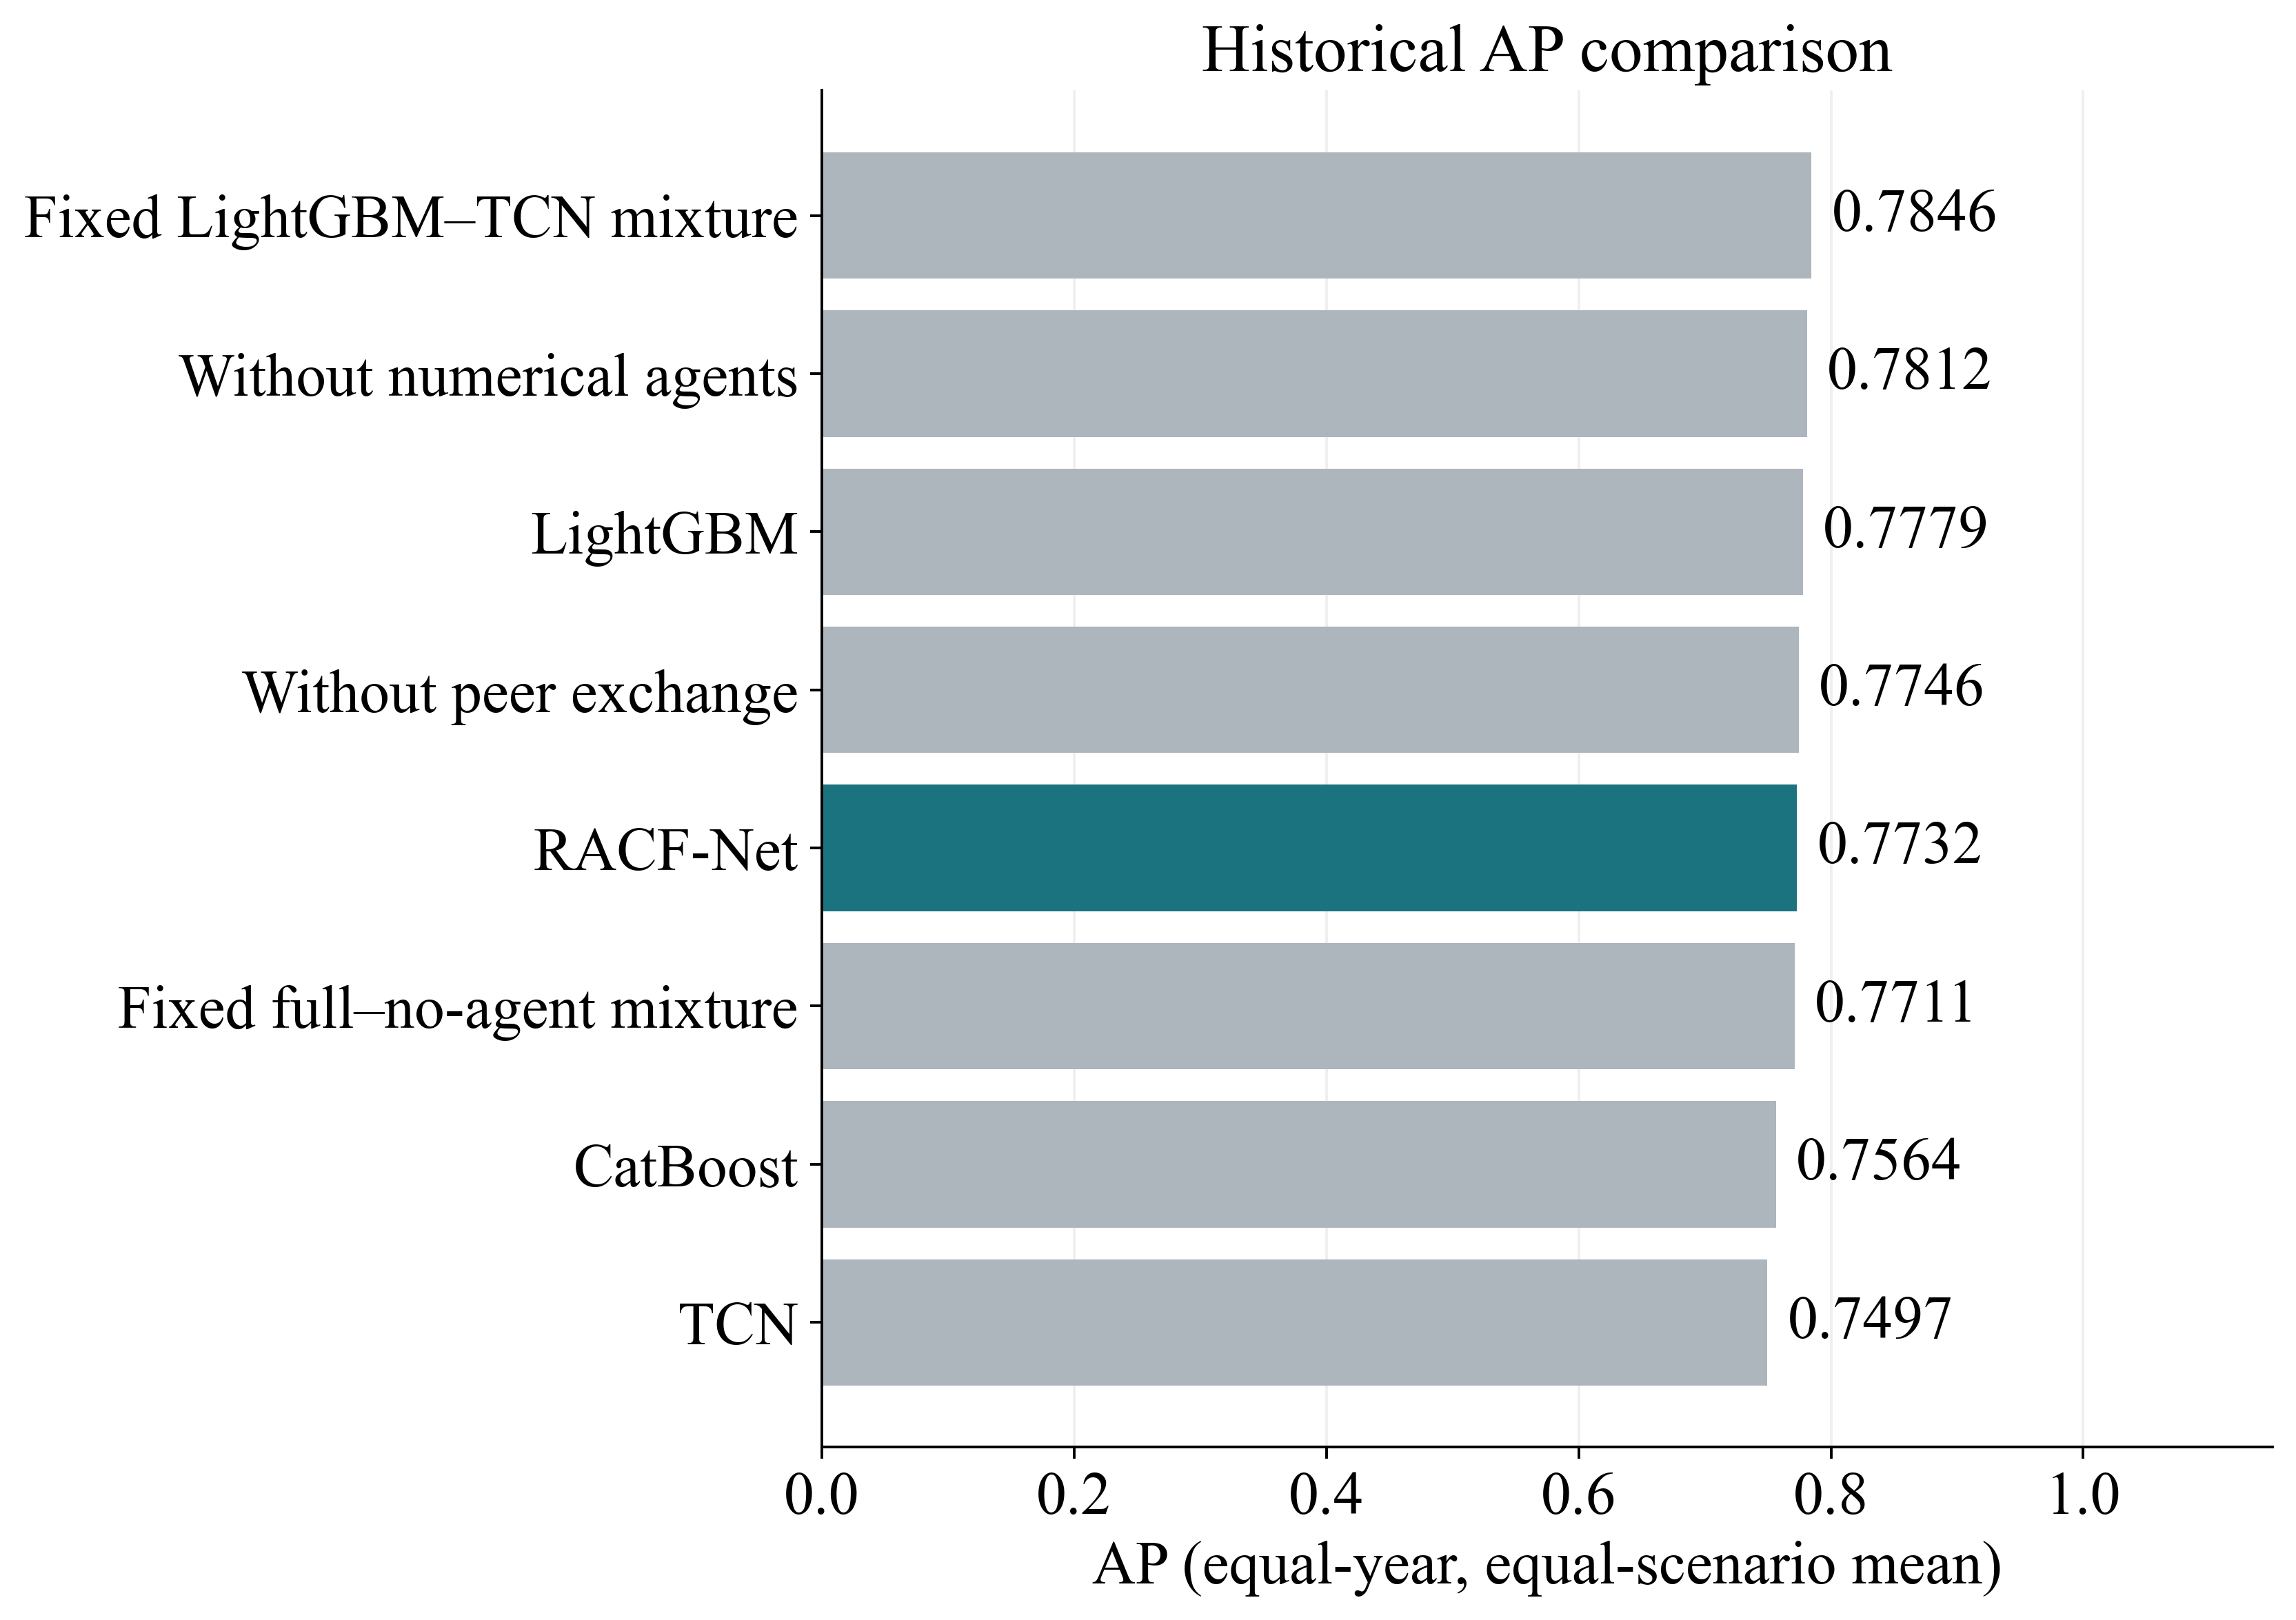

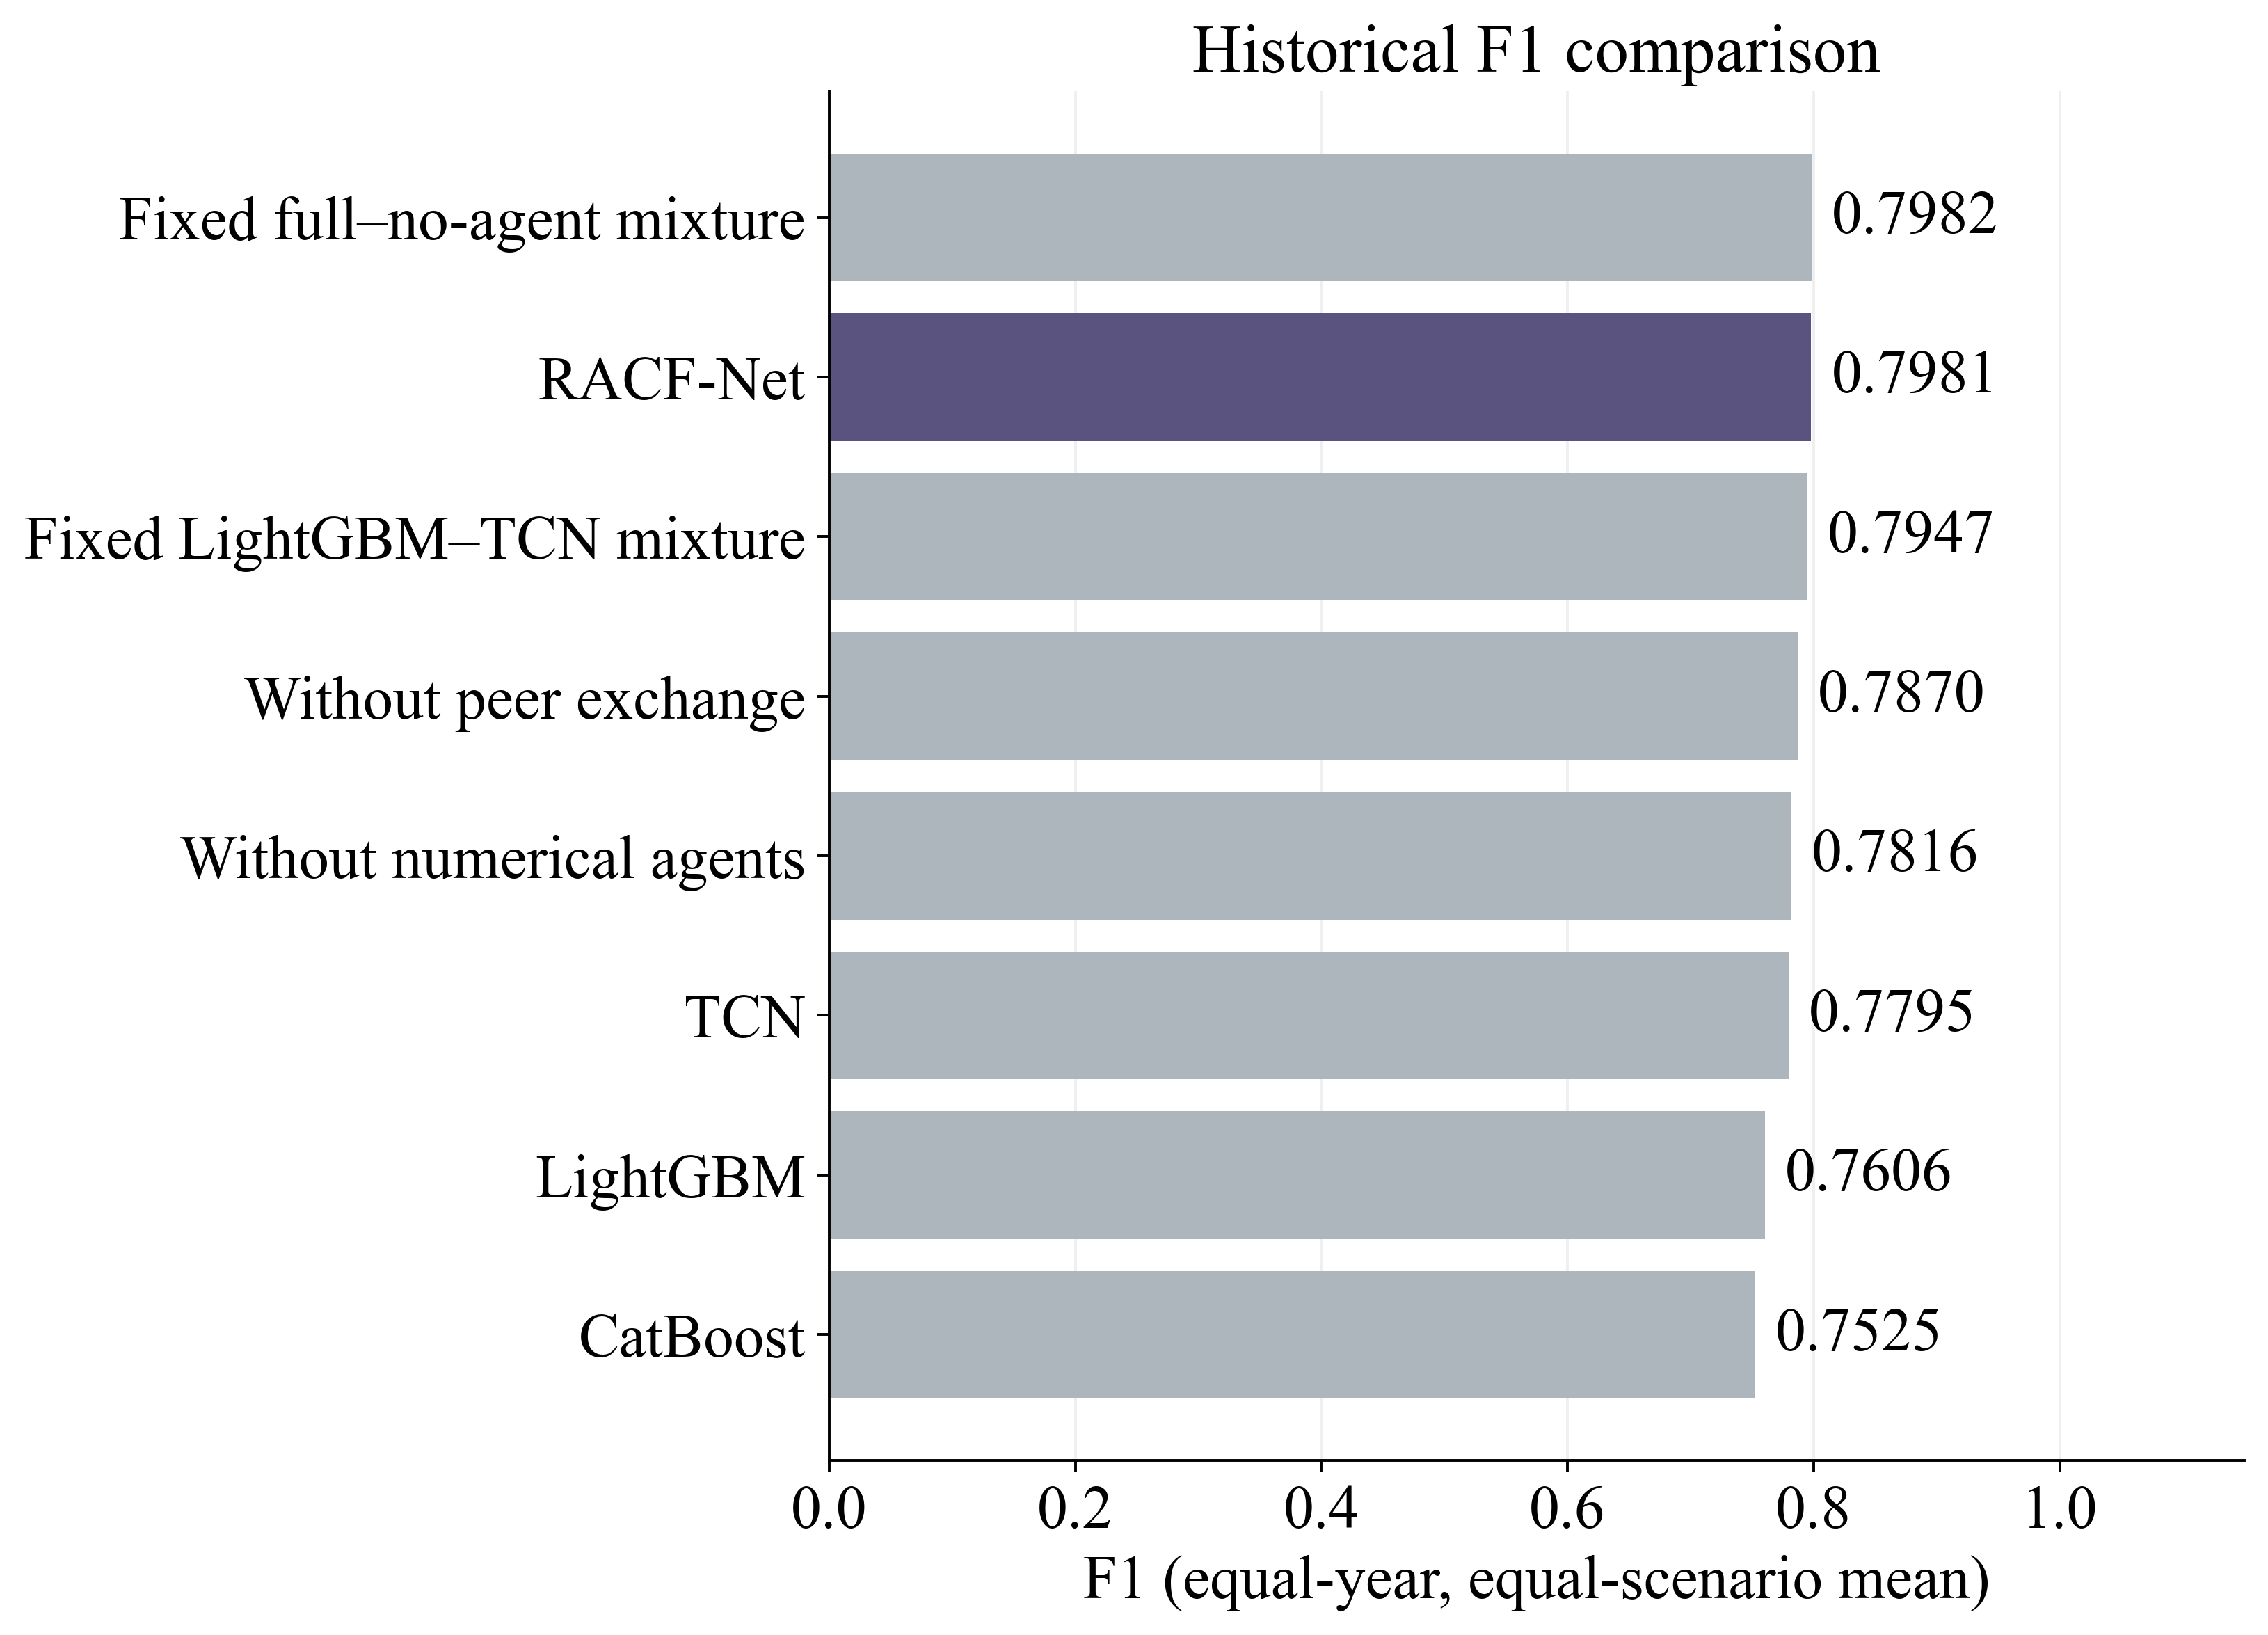

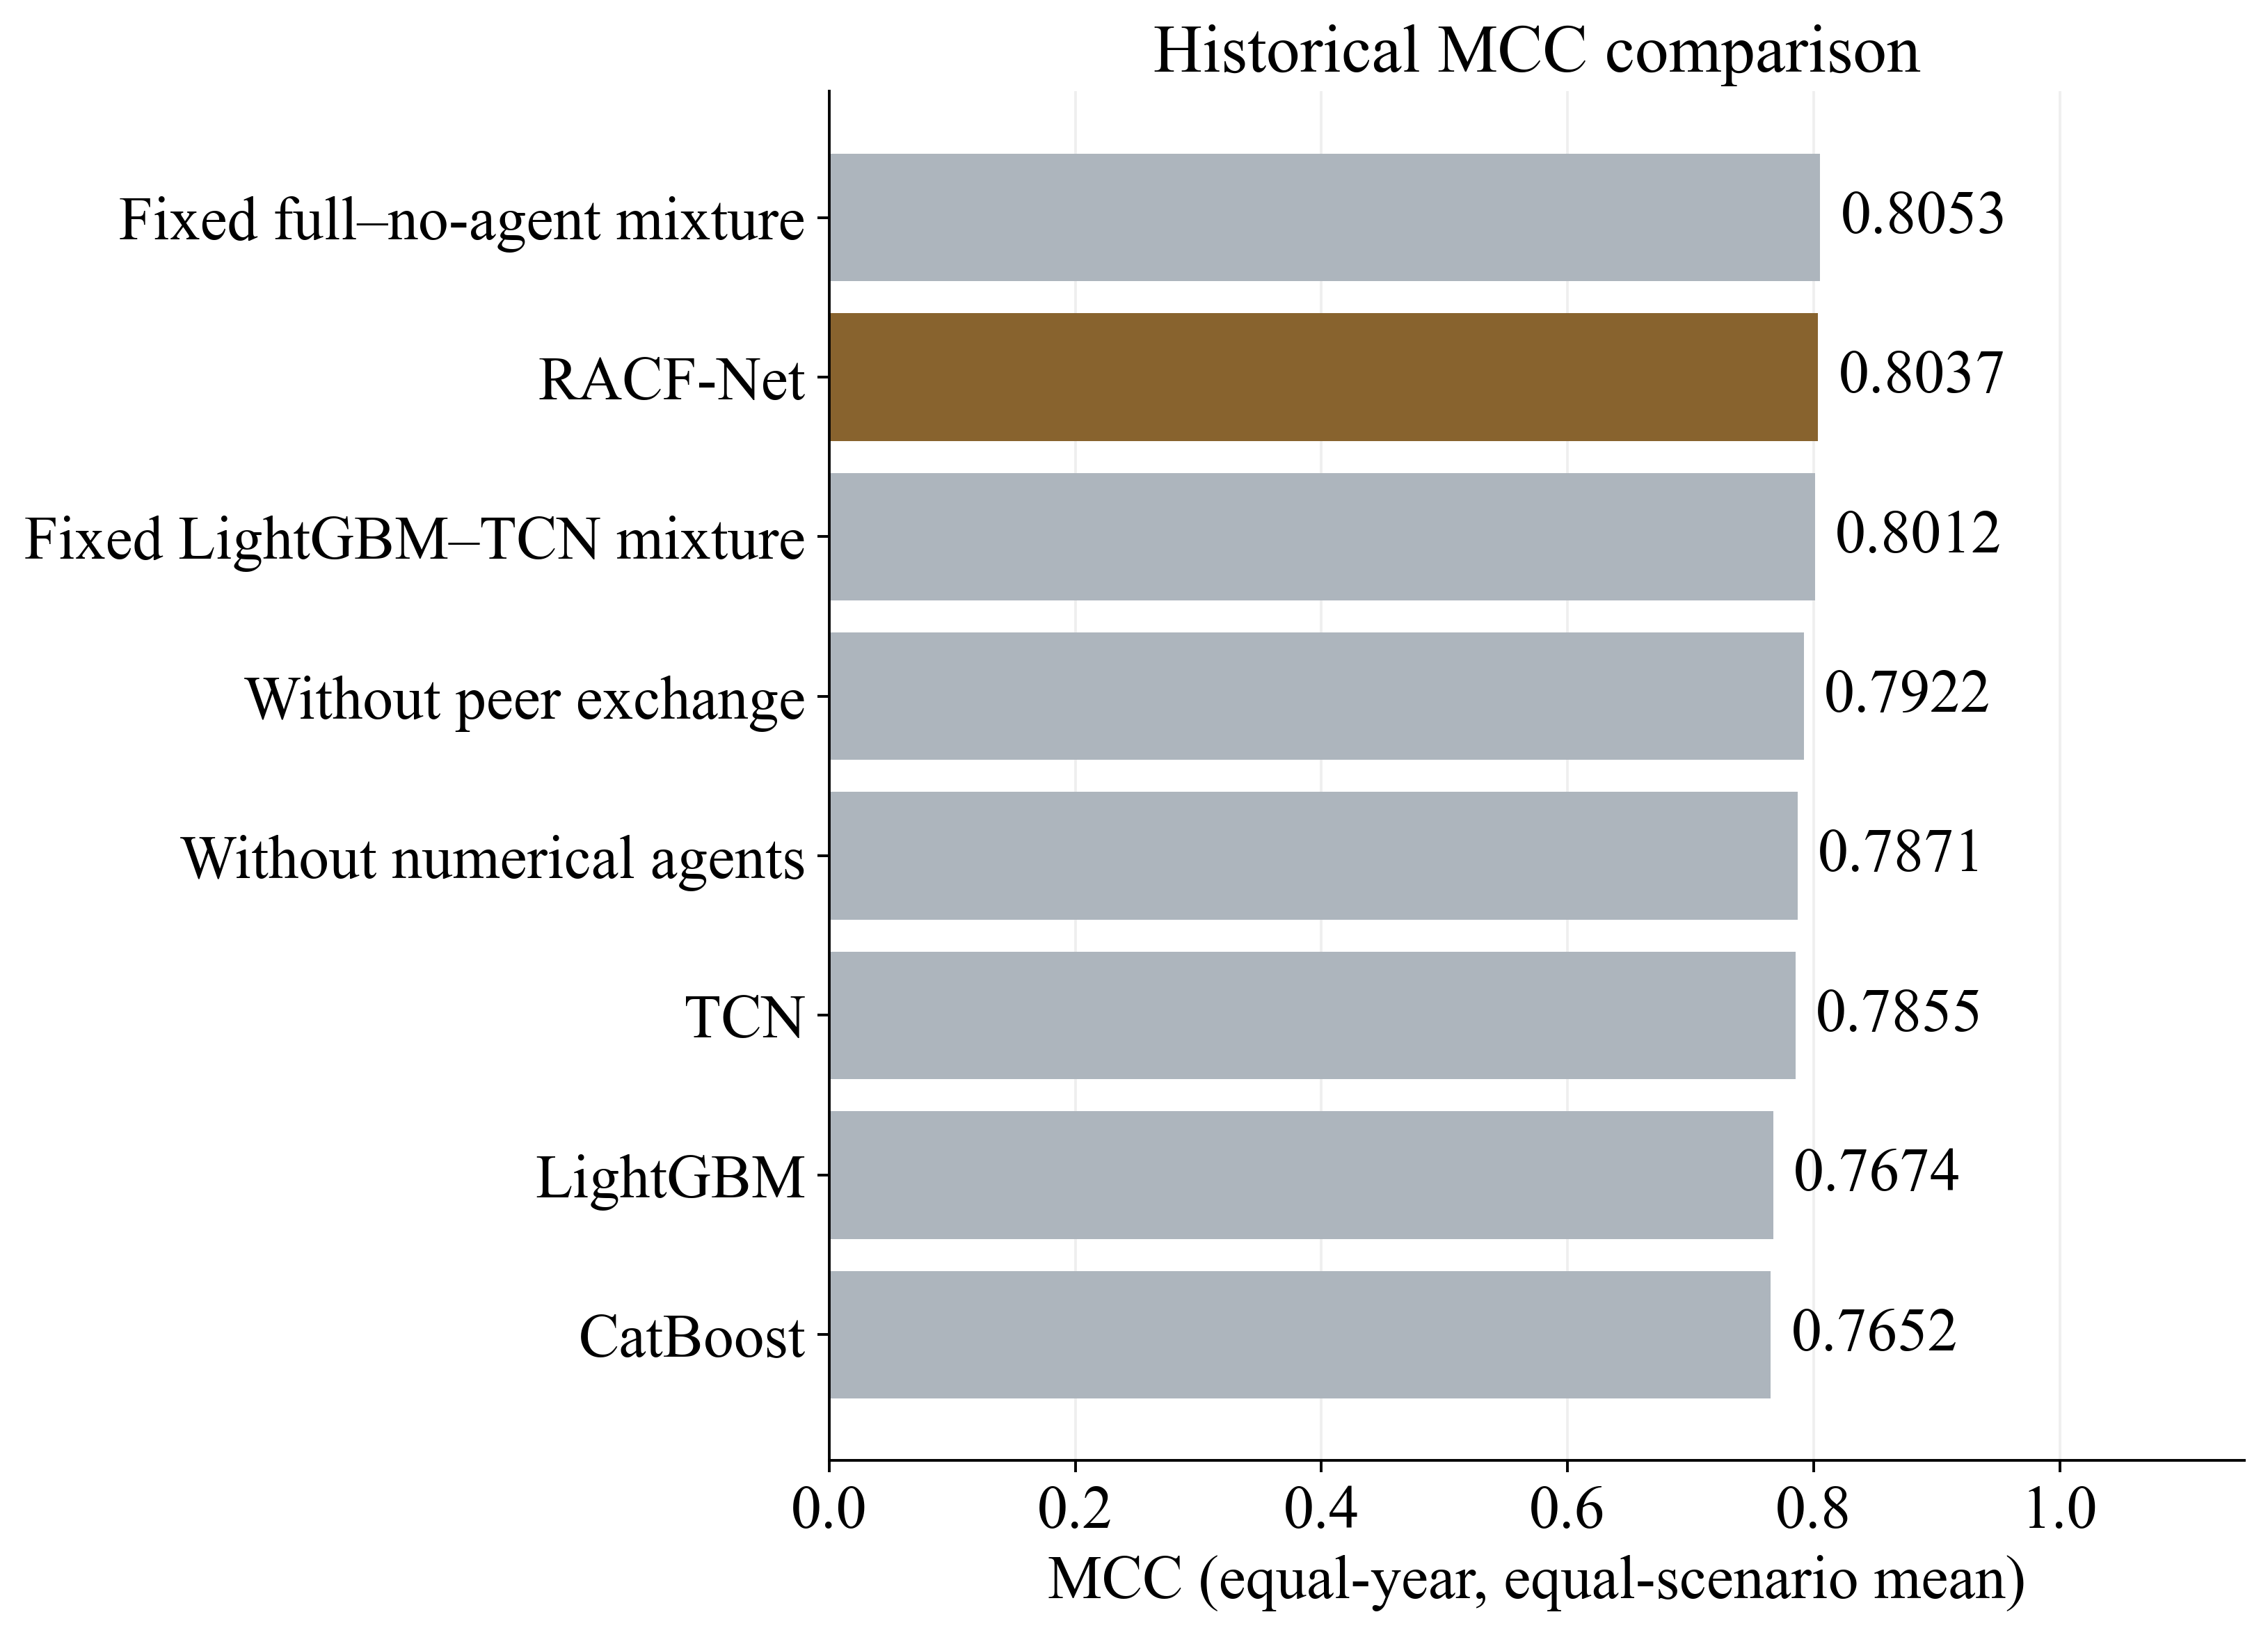

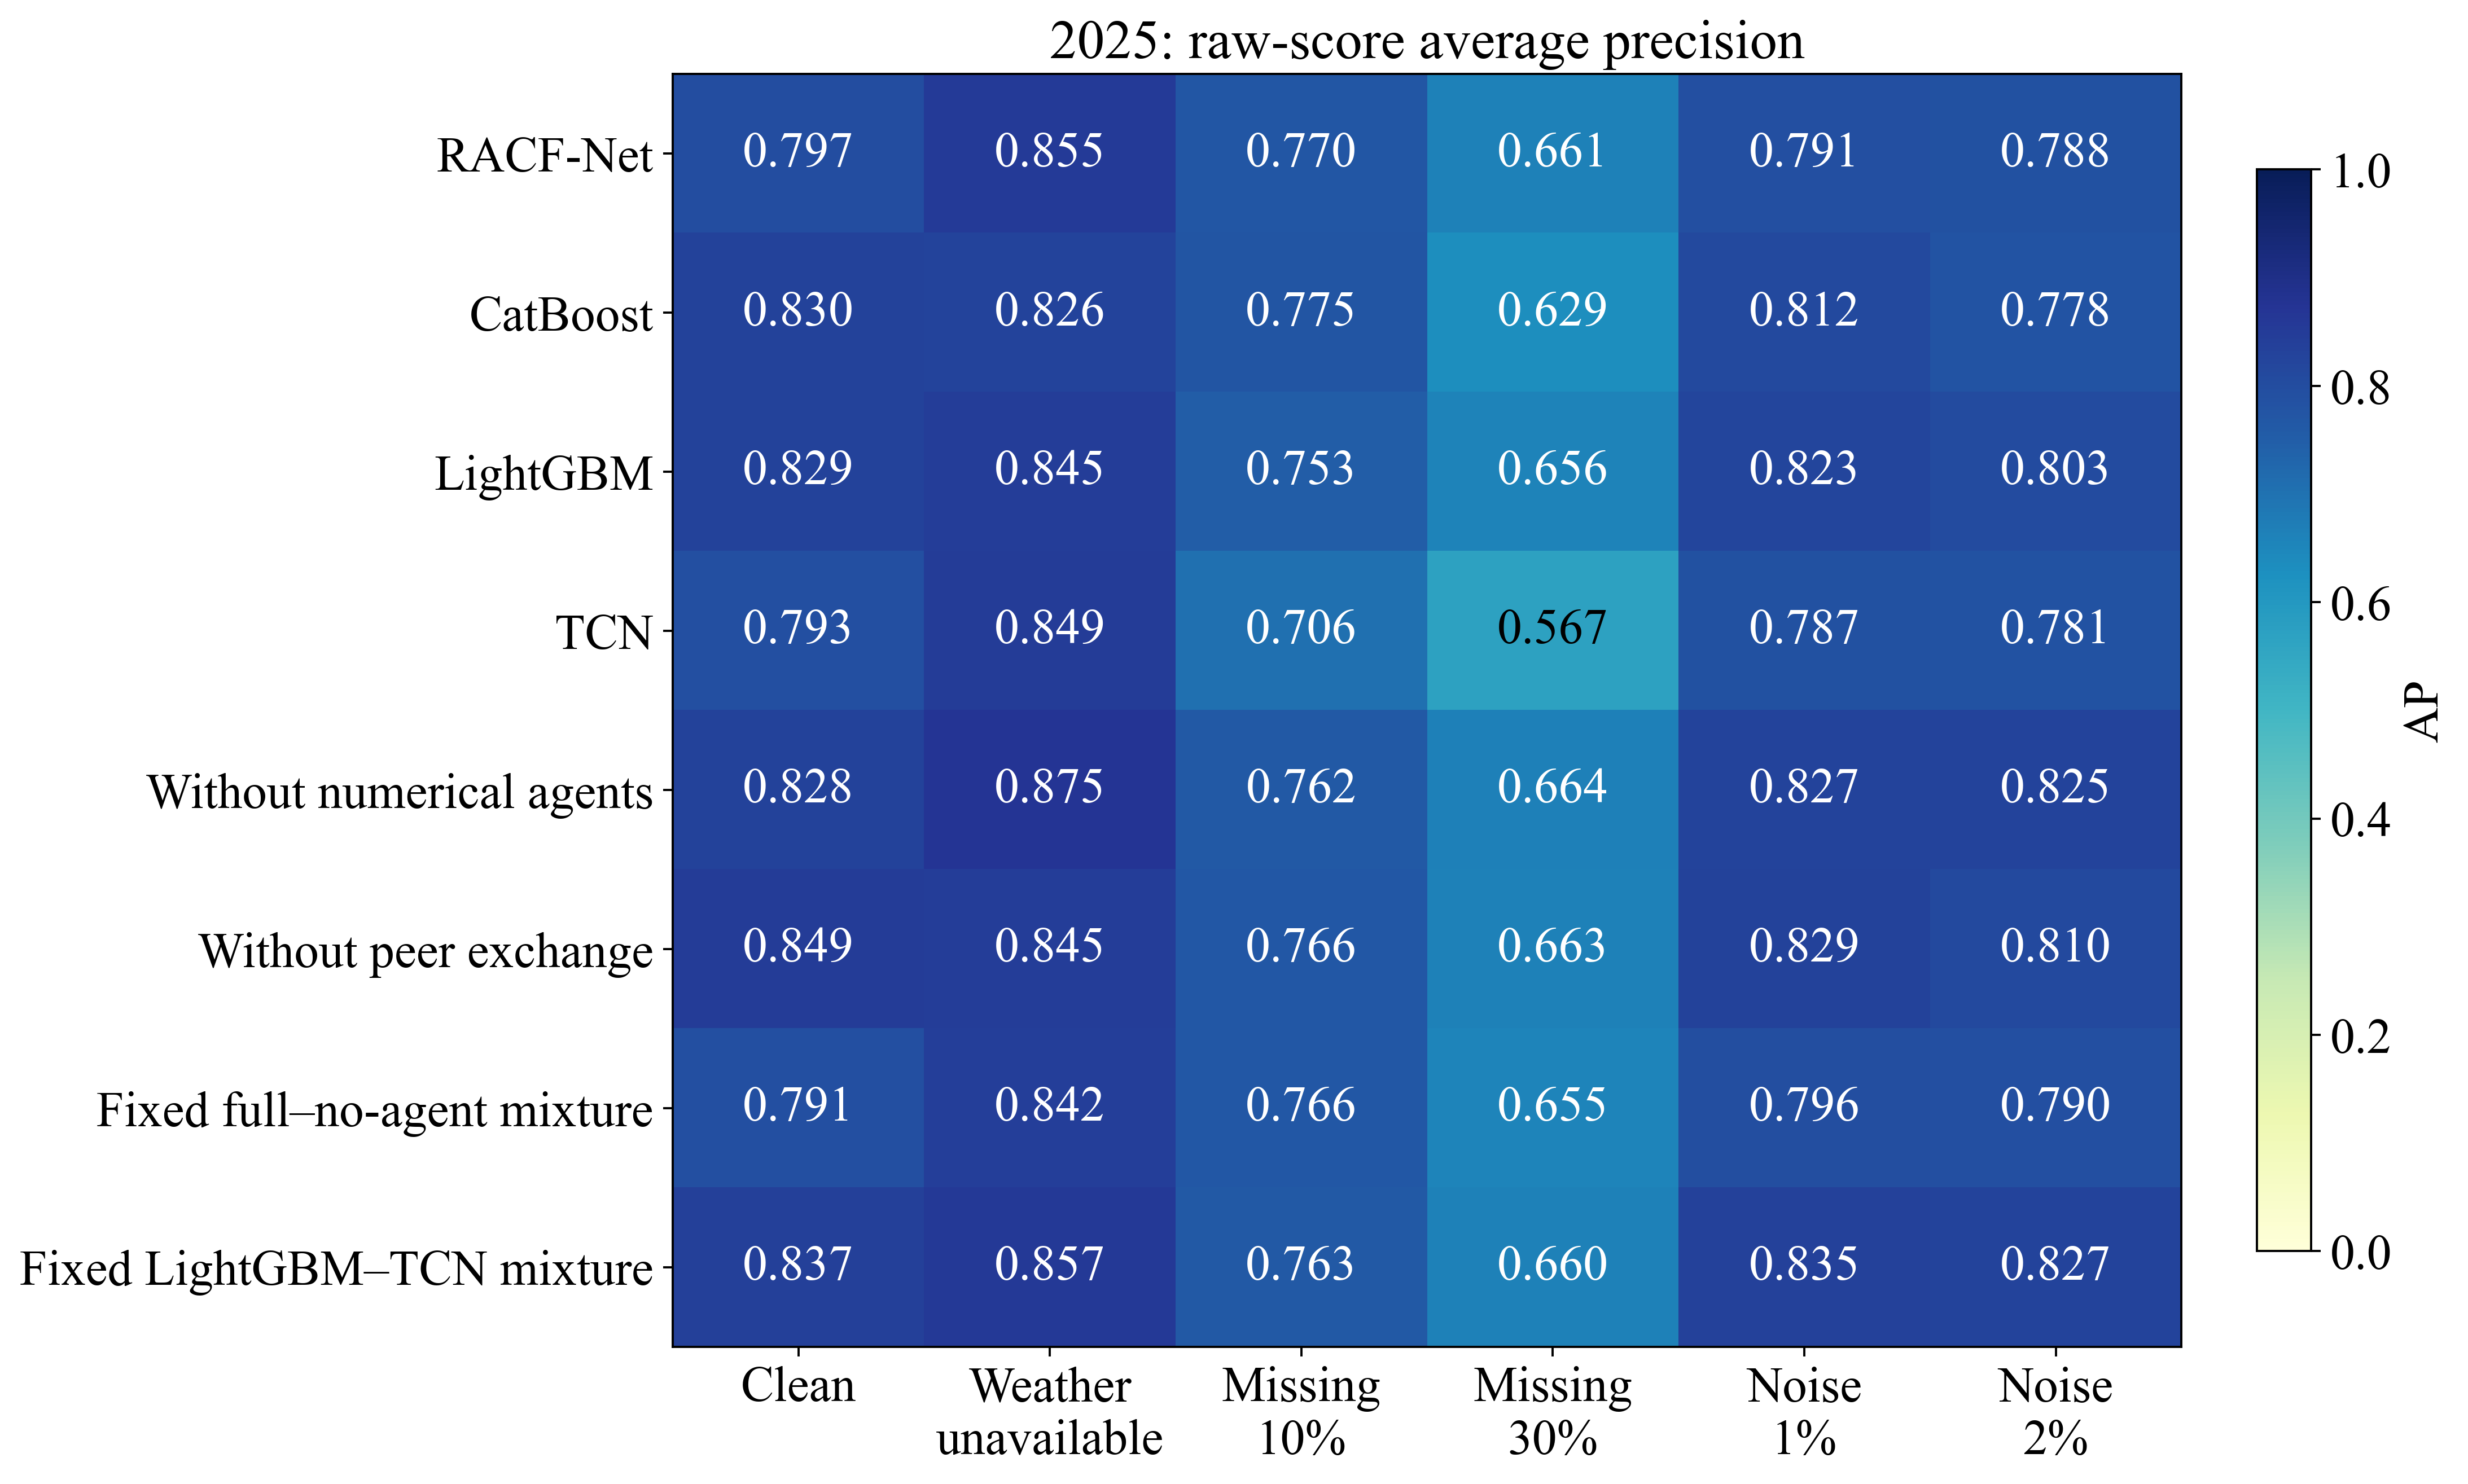

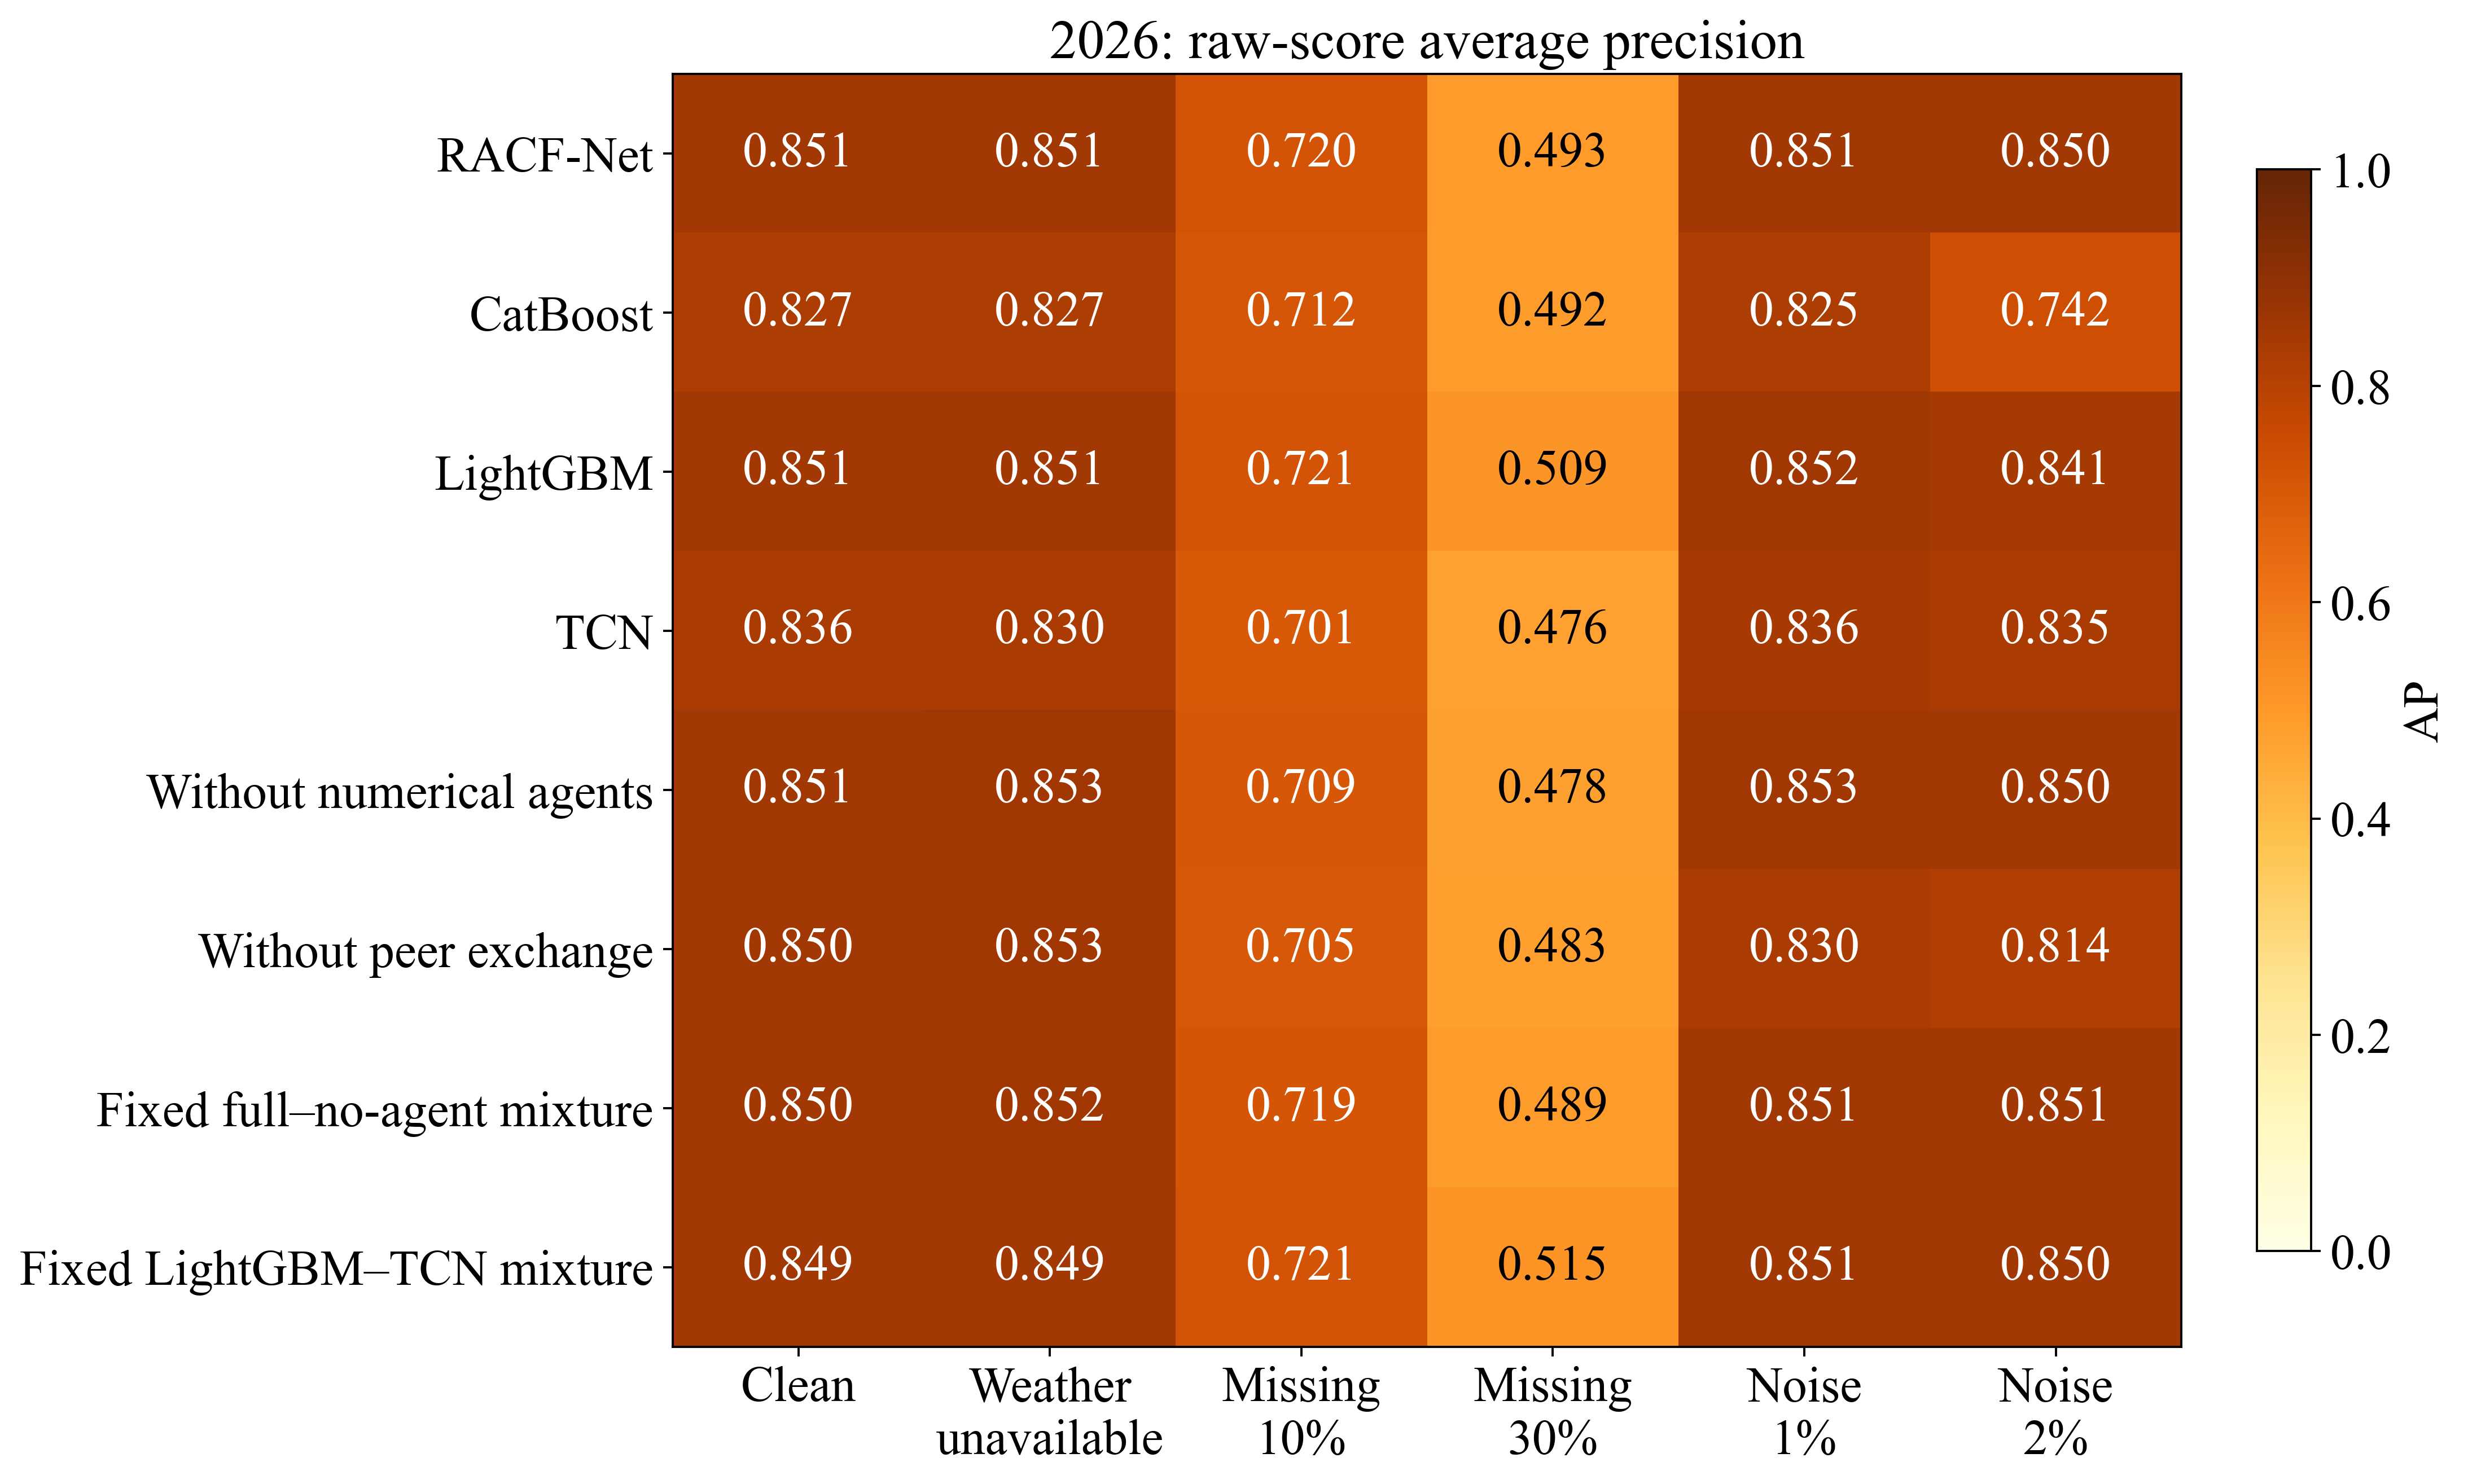

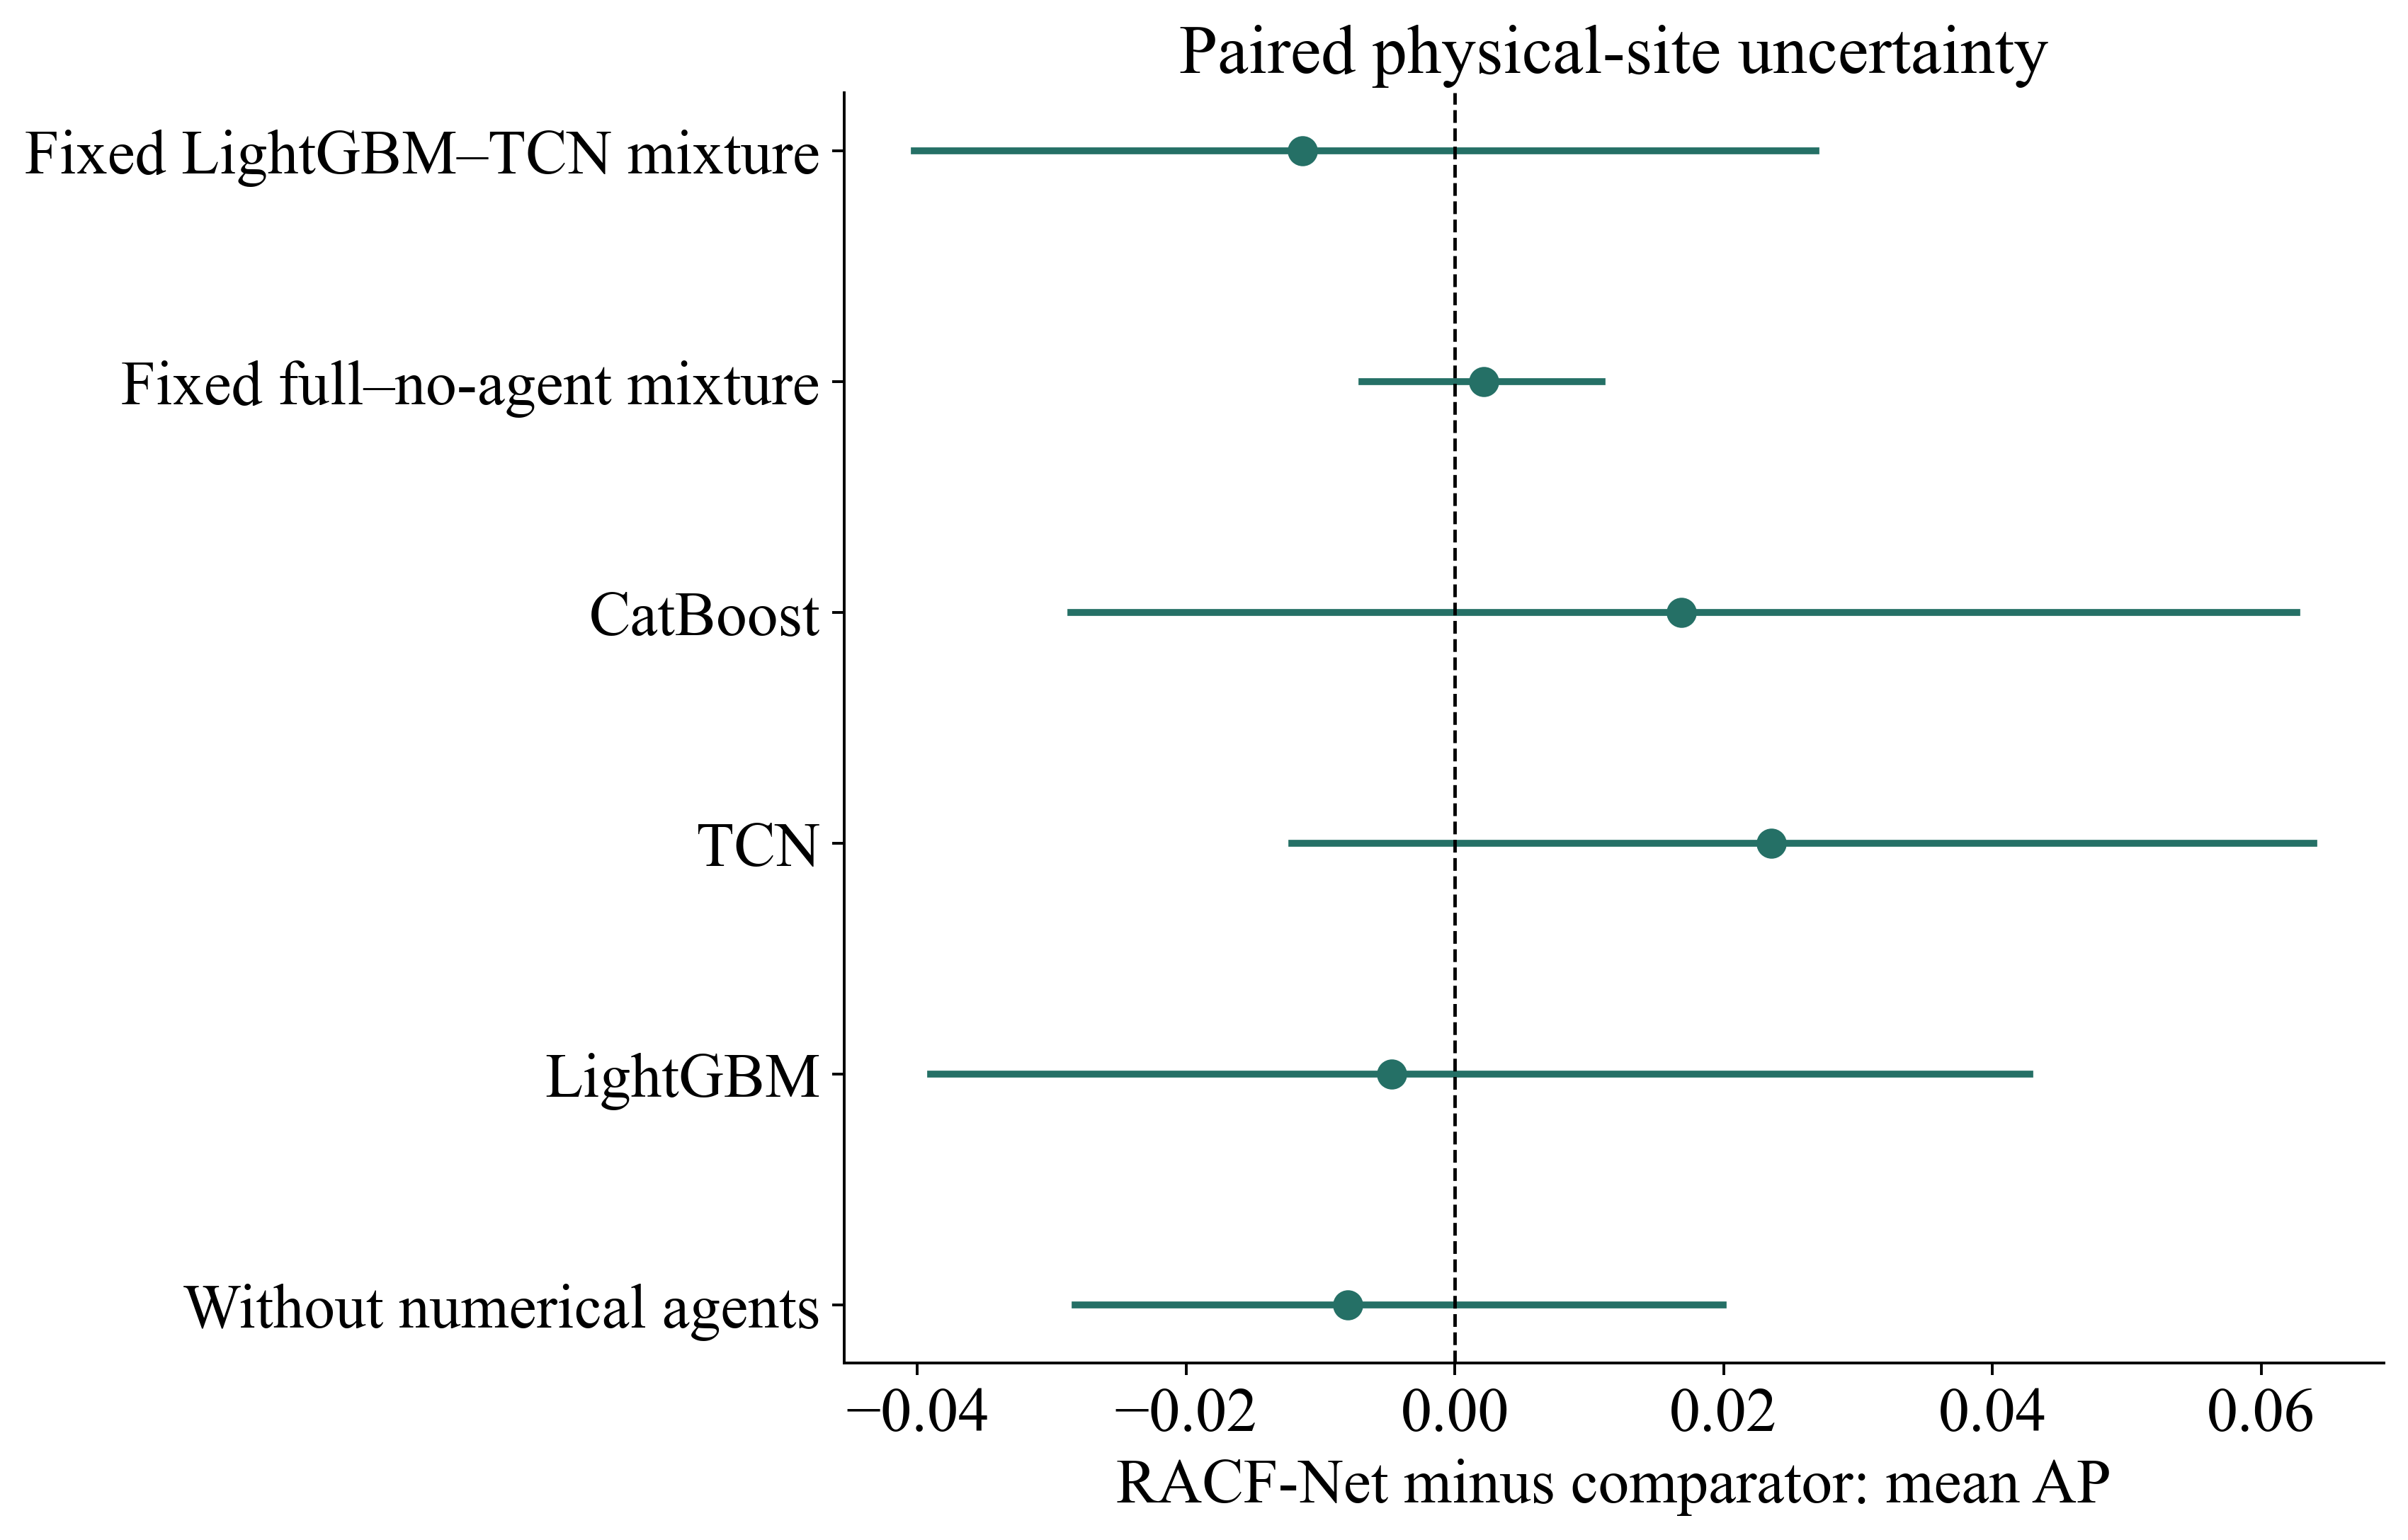

Bars are descriptive means. Heatmaps use distinct palettes and numerical annotations. Intervals are marginal paired-site bootstrap intervals; statistical decisions use the complete Holm-adjusted families in the tables. Previously disclosed outcomes do not provide independent confirmation.

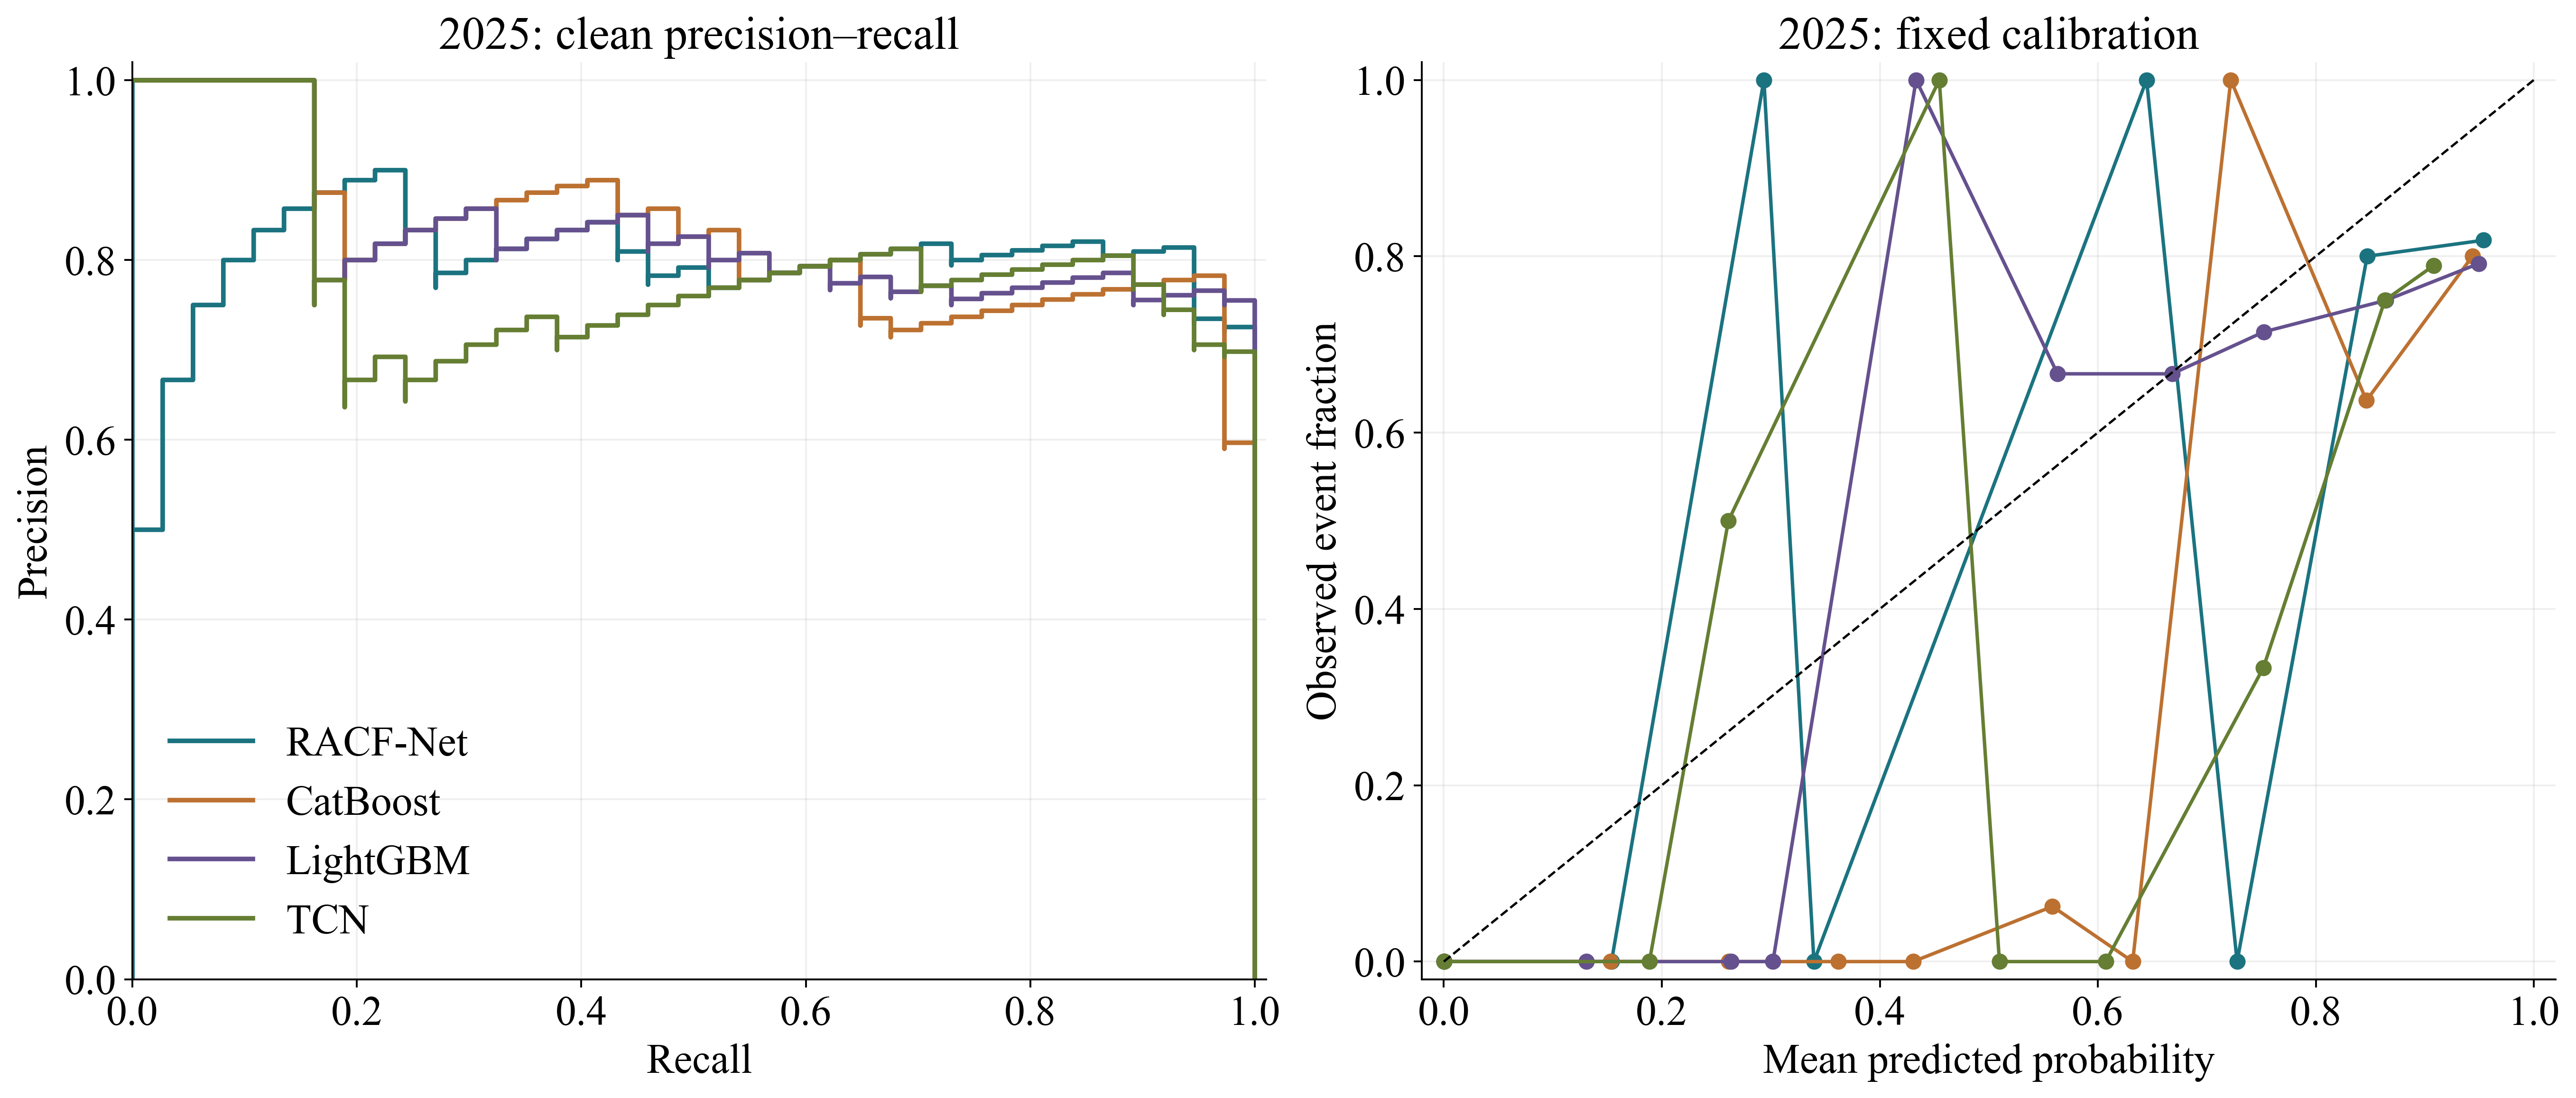

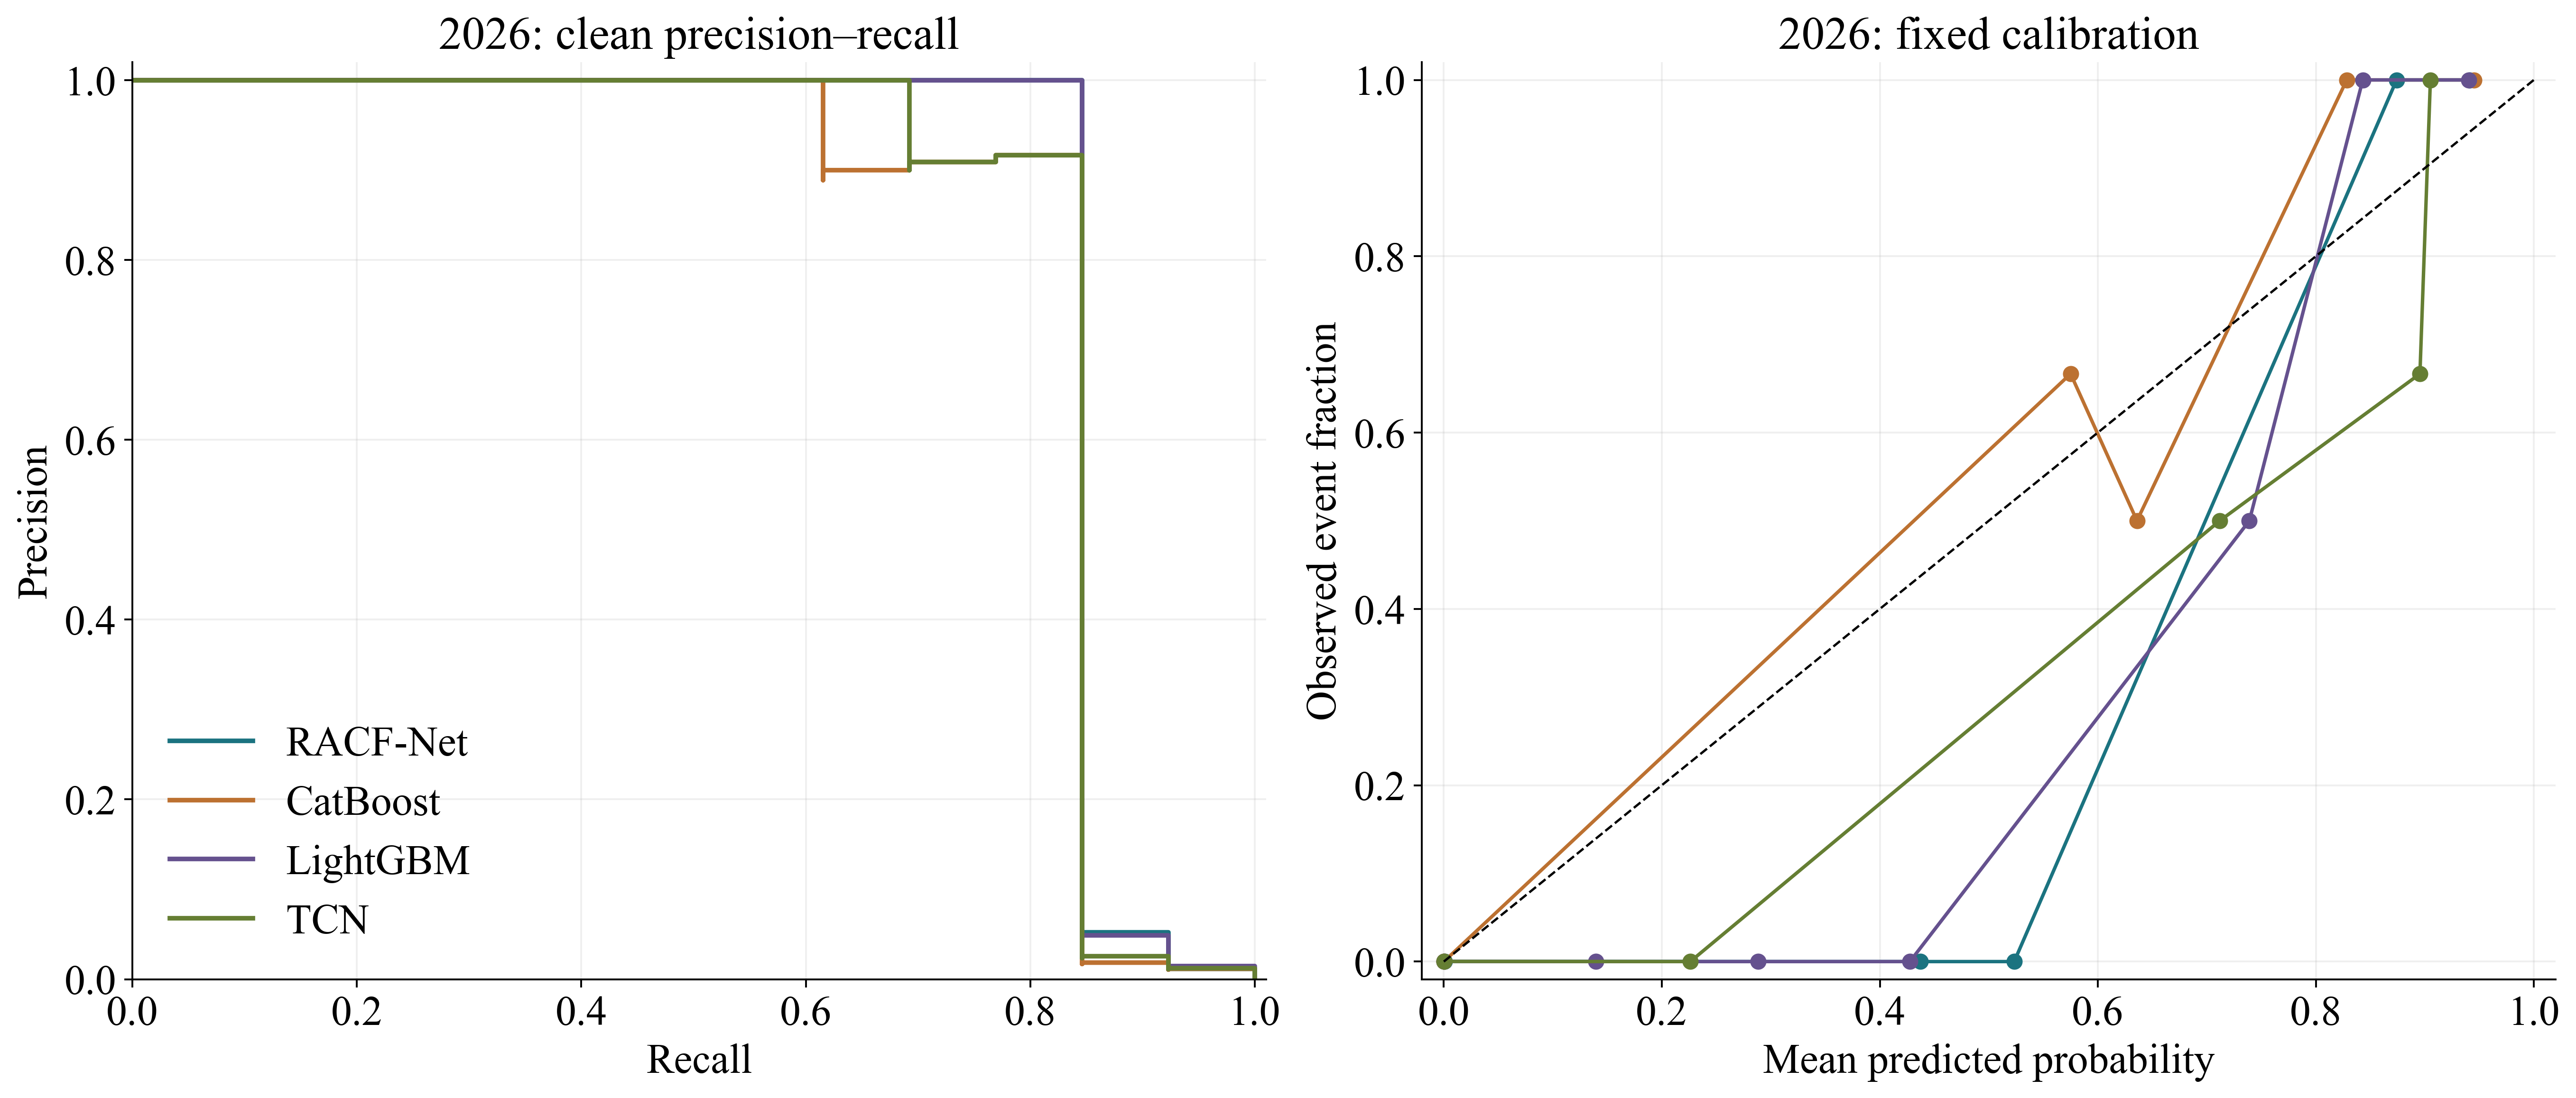

Calibration curves use nonempty fixed-width probability bins; bin counts are saved in calibration_bin_support.csv. Rare positive events make individual bin rates unstable. The plots describe the fixed four-model comparison; full eight-pipeline scores and calibration metrics are retained in the tables.

In [134]:
targeted_evaluation_figures(targeted_joint_metrics,targeted_scenario_metrics,targeted_contrasts)
targeted_clean_probability_figures(TARGETED_CASES)
